In [1]:
import torch

if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

print(device)

cpu


In [2]:

import os
import json
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from shapely import wkt
from tqdm.auto import tqdm

print("Environment ready!")

Environment ready!


In [3]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/T229')

folders = [
    'data',
    'notebooks',
    'outputs',
    'checkpoints',
    'reports'
]

for folder in folders:
  (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print('Project Folders Created!')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project Folders Created!


## Downloading the data


In [ ]:

# import os
# import subprocess

# save_path = "/content/drive/MyDrive/T229/data/train_images_labels_targets.tar.gz"
# os.makedirs(os.path.dirname(save_path), exist_ok=True)

# url = input("Paste the fresh xView2 download URL here: ").strip()

# print("Starting dataset download...")
# result = subprocess.run([
#     "curl", "-L", "--fail",
#     "--retry", "5",
#     "--retry-all-errors",
#     "-C", "-",
#     "-o", save_path,
#     url
# ])

# if result.returncode == 0:
#     size_gb = os.path.getsize(save_path) / (1024**3)
#     print(f"\nDownload completed! File size: {size_gb:.2f} GB")
# else:
#     print("\nDownload did not complete. Check the error above.")

In [ ]:

# import os
# import tarfile

# path = "/content/drive/MyDrive/T229/data/train_images_labels_targets.tar.gz"

# print("File exists:", os.path.exists(path))
# print("File size (GB):", round(os.path.getsize(path) / (1024**3), 2))

# print("\nChecking archive integrity...")
# try:
#     with tarfile.open(path, "r:gz") as archive:
#         print("Archive opened successfully!")
#         print("Number of entries:", len(archive.getmembers()))
#         print("\nFirst 10 entries:")
#         for member in archive.getmembers()[:10]:
#             print(member.name)
# except Exception as e:
#     print("Archive verification failed:", repr(e))

In [ ]:

# import os
# import tarfile

# archive_path = "/content/drive/MyDrive/T229/data/train_images_labels_targets.tar.gz"
# extract_path = "/content/drive/MyDrive/T229/data"

# print("Extracting dataset... Please wait.")

# with tarfile.open(archive_path, "r:gz") as archive:
#     archive.extractall(path=extract_path, filter="data")

# print("\nExtraction completed!")

# train_path = os.path.join(extract_path, "train")
# print("Training folder exists:", os.path.isdir(train_path))
# print("Training subfolders:", os.listdir(train_path))

##

In [ ]:

import os
import json
from collections import Counter

base = "/content/drive/MyDrive/T229/data/train"

for folder in ["images", "labels", "targets"]:
    path = os.path.join(base, folder)
    files = os.listdir(path)
    print(f"{folder}: {len(files)} entries")
    print("  Examples:", files[:5])

print("\n--- Inspecting one JSON annotation ---")

labels_dir = os.path.join(base, "labels")
json_files = [
    f for f in os.listdir(labels_dir)
    if f.endswith(".json")
]

if json_files:
    sample_path = os.path.join(labels_dir, json_files[0])

    with open(sample_path, "r") as f:
        sample = json.load(f)

    print("Sample file:", json_files[0])
    print("Top-level keys:", list(sample.keys()))
    print(json.dumps(sample, indent=2)[:3000])
else:
    print("No JSON annotation files found.")

images: 5598 entries
  Examples: ['socal-fire_00000577_pre_disaster.png', 'socal-fire_00000549_pre_disaster.png', 'socal-fire_00000581_pre_disaster.png', 'socal-fire_00000573_post_disaster.png', 'socal-fire_00000572_post_disaster.png']
labels: 5598 entries
  Examples: ['socal-fire_00000457_pre_disaster.json', 'socal-fire_00000471_pre_disaster.json', 'socal-fire_00000522_post_disaster.json', 'socal-fire_00000497_post_disaster.json', 'socal-fire_00000500_pre_disaster.json']
targets: 5598 entries
  Examples: ['hurricane-harvey_00000400_post_disaster_target.png', 'mexico-earthquake_00000020_pre_disaster_target.png', 'santa-rosa-wildfire_00000155_post_disaster_target.png', 'hurricane-harvey_00000266_post_disaster_target.png', 'socal-fire_00000389_post_disaster_target.png']

--- Inspecting one JSON annotation ---
Sample file: socal-fire_00000457_pre_disaster.json
Top-level keys: ['features', 'metadata']
{
  "features": {
    "lng_lat": [],
    "xy": []
  },
  "metadata": {
    "sensor": "WOR

In [ ]:

import os
import json
from PIL import Image

base = "/content/drive/MyDrive/T229/data/train"

# Inspect one image
image_name = "hurricane-michael_00000239_post_disaster.png"
image_path = os.path.join(base, "images", image_name)

with Image.open(image_path) as img:
    print("Image:", image_name)
    print("Image dimensions:", img.size)
    print("Image mode:", img.mode)

# Inspect matching annotation
label_name = image_name.replace(".png", ".json")
label_path = os.path.join(base, "labels", label_name)

print("\nMatching label exists:", os.path.exists(label_path))

if os.path.exists(label_path):
    with open(label_path, "r") as f:
        annotation = json.load(f)

    print("Metadata:")
    print(json.dumps(annotation.get("metadata", {}), indent=2))

    features = annotation.get("features", {})
    polygons = features.get("lng_lat", [])
    print("\nNumber of building annotations:", len(polygons))

    from collections import Counter
    counts = Counter(
        item.get("properties", {}).get("subtype", "unknown")
        for item in polygons
        if item.get("properties", {}).get("feature_type") == "building"
    )
    print("Damage categories:", dict(counts))

Image: hurricane-michael_00000239_post_disaster.png
Image dimensions: (1024, 1024)
Image mode: RGB

Matching label exists: True
Metadata:
{
  "sensor": "GEOEYE01",
  "provider_asset_type": "GEOEYE01",
  "gsd": 2.0711906,
  "capture_date": "2018-10-13T16:48:15.000Z",
  "off_nadir_angle": 28.86673,
  "pan_resolution": 0.5171161,
  "sun_azimuth": 163.92638,
  "sun_elevation": 50.756794,
  "target_azimuth": 112.555626,
  "disaster": "hurricane-michael",
  "disaster_type": "wind",
  "catalog_id": "105001001292E000",
  "original_width": 1024,
  "original_height": 1024,
  "width": 1024,
  "height": 1024,
  "id": "MjU0NjI4MQ.7blCGLCK-n1pdBcqikQ3-5T2Iqs",
  "img_name": "hurricane-michael_00000239_post_disaster.png"
}

Number of building annotations: 146
Damage categories: {'no-damage': 79, 'minor-damage': 28, 'major-damage': 23, 'destroyed': 15, 'un-classified': 1}


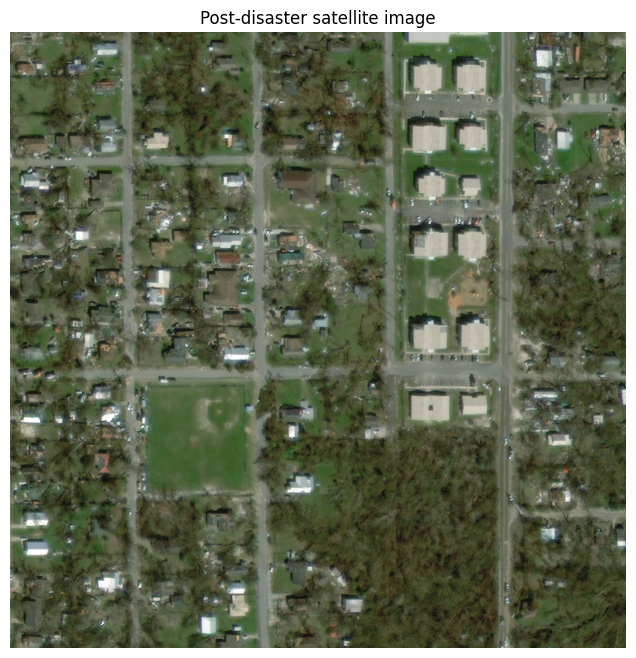

Image loaded successfully.
Image size: (1024, 1024)
Building annotations: 146


In [ ]:

import os
import json
import matplotlib.pyplot as plt
from PIL import Image

base = "/content/drive/MyDrive/T229/data/train"

image_name = "hurricane-michael_00000239_post_disaster.png"
image_path = os.path.join(base, "images", image_name)

with Image.open(image_path) as img:
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.title("Post-disaster satellite image")
    plt.axis("off")
    plt.show()

label_path = os.path.join(
    base, "labels",
    image_name.replace(".png", ".json")
)

with open(label_path, "r") as f:
    annotation = json.load(f)

print("Image loaded successfully.")
print("Image size:", Image.open(image_path).size)
print("Building annotations:", len(annotation["features"]["lng_lat"]))

In [ ]:

import os
import json

base = "/content/drive/MyDrive/T229/data/train"
image_name = "hurricane-michael_00000239_post_disaster.png"
label_path = os.path.join(
    base, "labels", image_name.replace(".png", ".json")
)

with open(label_path, "r") as f:
    annotation = json.load(f)

print("Metadata keys:")
print(list(annotation["metadata"].keys()))

print("\nFeature groups:")
for key, value in annotation["features"].items():
    print(key, ":", len(value) if isinstance(value, list) else type(value).__name__)

print("\nFirst building properties:")
print(json.dumps(
    annotation["features"]["lng_lat"][0]["properties"],
    indent=2
))

Metadata keys:
['sensor', 'provider_asset_type', 'gsd', 'capture_date', 'off_nadir_angle', 'pan_resolution', 'sun_azimuth', 'sun_elevation', 'target_azimuth', 'disaster', 'disaster_type', 'catalog_id', 'original_width', 'original_height', 'width', 'height', 'id', 'img_name']

Feature groups:
lng_lat : 146
xy : 146

First building properties:
{
  "feature_type": "building",
  "subtype": "no-damage",
  "uid": "3166a980-01b9-48f9-b495-671fa153ba67"
}


In [ ]:

# Inspect the first building annotation in pixel coordinates

first_building = annotation["features"]["xy"][0]

print("Building properties:")
print(json.dumps(first_building["properties"], indent=2))

print("\nPolygon coordinates:")
print(first_building["wkt"])

Building properties:
{
  "feature_type": "building",
  "subtype": "no-damage",
  "uid": "3166a980-01b9-48f9-b495-671fa153ba67"
}

Polygon coordinates:
POLYGON ((971.0000001361618 0.00233923960989422, 971.0000001371612 11.00000005043828, 954.0000001358339 11.00000005243724, 954.000000137583 0.002664089717760834, 971.0000001361618 0.00233923960989422))


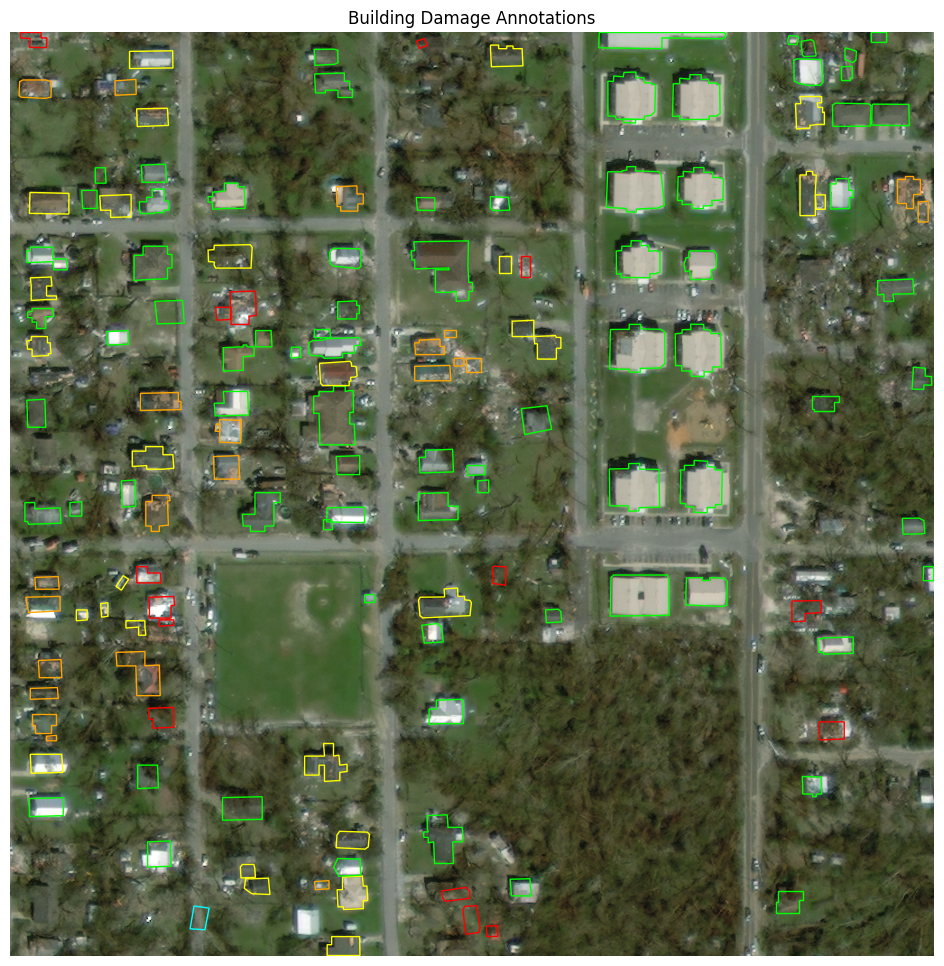

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image
from shapely import wkt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
import os

# Load the image
image_path = os.path.join(
    base, "images", image_name
)
img = Image.open(image_path).convert("RGB")

# Damage category colors
damage_colors = {
    "no-damage": "lime",
    "minor-damage": "yellow",
    "major-damage": "orange",
    "destroyed": "red",
    "un-classified": "cyan"
}

fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(img)

for feature in annotation["features"]["xy"]:
    props = feature["properties"]
    polygon = wkt.loads(feature["wkt"])

    if polygon.geom_type != "Polygon":
        continue

    coords = list(polygon.exterior.coords)
    patch = MplPolygon(
        coords,
        closed=True,
        fill=False,
        edgecolor=damage_colors.get(
            props.get("subtype"), "white"
        ),
        linewidth=1
    )
    ax.add_patch(patch)

ax.set_title("Building Damage Annotations")
ax.axis("off")
plt.show()

In [ ]:

from collections import Counter
import json
import os

labels_dir = os.path.join(base, "labels")

damage_counts = Counter()
total_buildings = 0
files_checked = 0

for filename in os.listdir(labels_dir):
    if not filename.endswith(".json"):
        continue

    path = os.path.join(labels_dir, filename)

    with open(path, "r") as f:
        data = json.load(f)

    buildings = data["features"]["xy"]

    for building in buildings:
        subtype = building["properties"].get(
            "subtype", "un-classified"
        )
        damage_counts[subtype] += 1
        total_buildings += 1

    files_checked += 1

print("Label files checked:", files_checked)
print("Total building annotations:", total_buildings)
print("\nDamage class distribution:")

for label, count in damage_counts.most_common():
    percentage = count / total_buildings * 100
    print(f"{label:15s}: {count:8,d} ({percentage:.2f}%)")

Label files checked: 5598
Total building annotations: 325574

Damage class distribution:
un-classified  :  165,780 (50.92%)
no-damage      :  117,426 (36.07%)
minor-damage   :   14,980 (4.60%)
major-damage   :   14,161 (4.35%)
destroyed      :   13,227 (4.06%)


In [ ]:

import os
from collections import Counter

images_dir = os.path.join(base, "images")
image_files = [
    f for f in os.listdir(images_dir)
    if f.endswith(".png")
]

print("Total images:", len(image_files))

image_types = Counter()
disasters = Counter()

for filename in image_files:
    if "_pre_disaster" in filename:
        image_types["pre-disaster"] += 1
    elif "_post_disaster" in filename:
        image_types["post-disaster"] += 1
    else:
        image_types["other"] += 1

    disaster_name = filename.split("_")[0]
    disasters[disaster_name] += 1

print("\nImage types:")
for name, count in image_types.items():
    print(f"{name}: {count:,}")

print("\nImages per disaster (first 15):")
for name, count in disasters.most_common(15):
    print(f"{name}: {count:,}")

Total images: 5598

Image types:
pre-disaster: 2,799
post-disaster: 2,799

Images per disaster (first 15):
socal-fire: 1,646
hurricane-michael: 686
hurricane-florence: 638
hurricane-harvey: 638
midwest-flooding: 558
hurricane-matthew: 476
santa-rosa-wildfire: 452
mexico-earthquake: 242
palu-tsunami: 226
guatemala-volcano: 36


In [ ]:

import os

images_dir = os.path.join(base, "images")

image_files = {
    f for f in os.listdir(images_dir)
    if f.endswith(".png")
}

pre_images = {
    f for f in image_files
    if "_pre_disaster.png" in f
}

post_images = {
    f for f in image_files
    if "_post_disaster.png" in f
}

# Remove the pre/post suffix to compare scene identifiers
pre_ids = {
    f.replace("_pre_disaster.png", "")
    for f in pre_images
}

post_ids = {
    f.replace("_post_disaster.png", "")
    for f in post_images
}

matched_ids = pre_ids & post_ids

print("Pre-disaster images:", len(pre_images))
print("Post-disaster images:", len(post_images))
print("Matched scene IDs:", len(matched_ids))
print("Pre images without a match:", len(pre_ids - post_ids))
print("Post images without a match:", len(post_ids - pre_ids))

print("\nExample matched IDs:")
for scene_id in sorted(matched_ids)[:5]:
    print(scene_id)

Pre-disaster images: 2799
Post-disaster images: 2799
Matched scene IDs: 2799
Pre images without a match: 0
Post images without a match: 0

Example matched IDs:
guatemala-volcano_00000000
guatemala-volcano_00000001
guatemala-volcano_00000002
guatemala-volcano_00000006
guatemala-volcano_00000007


In [ ]:

import os
import json
import pandas as pd

images_dir = os.path.join(base, "images")
labels_dir = os.path.join(base, "labels")

rows = []
missing_labels = []

for scene_id in sorted(post_ids):
    post_name = scene_id + "_post_disaster.png"
    pre_name = scene_id + "_pre_disaster.png"
    label_name = scene_id + "_post_disaster.json"

    post_path = os.path.join(images_dir, post_name)
    pre_path = os.path.join(images_dir, pre_name)
    label_path = os.path.join(labels_dir, label_name)

    if not os.path.exists(label_path):
        missing_labels.append(label_name)
        continue

    with open(label_path, "r") as f:
        label_data = json.load(f)

    rows.append({
        "scene_id": scene_id,
        "pre_image": pre_path,
        "post_image": post_path,
        "label_json": label_path,
        "building_count": len(label_data["features"]["xy"])
    })

manifest = pd.DataFrame(rows)

manifest_path = os.path.join(
    "/content/drive/MyDrive/T229",
    "reports",
    "training_manifest.csv"
)

manifest.to_csv(manifest_path, index=False)

print("Manifest rows:", len(manifest))
print("Missing label files:", len(missing_labels))
print("Total annotated buildings:", manifest["building_count"].sum())
print("Saved to:", manifest_path)

display(manifest.head())

Manifest rows: 2799
Missing label files: 0
Total annotated buildings: 162787
Saved to: /content/drive/MyDrive/T229/reports/training_manifest.csv


,scene_id,pre_image,post_image,label_json,building_count
0,guatemala-volcano_00000000,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/labels/...,10
1,guatemala-volcano_00000001,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/labels/...,4
2,guatemala-volcano_00000002,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/labels/...,1
3,guatemala-volcano_00000006,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/labels/...,97
4,guatemala-volcano_00000007,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/images/...,/content/drive/MyDrive/T229/data/train/labels/...,9


In [ ]:

import json
from collections import Counter
from shapely import wkt

damage_counts = Counter()
invalid_polygons = 0
total_buildings = 0

for label_path in manifest["label_json"]:
    with open(label_path, "r") as f:
        data = json.load(f)

    for feature in data["features"]["xy"]:
        total_buildings += 1
        subtype = feature["properties"].get(
            "subtype", "un-classified"
        )

        if subtype == "un-classified":
            continue

        try:
            polygon = wkt.loads(feature["wkt"])
            min_x, min_y, max_x, max_y = polygon.bounds

            if (
                polygon.is_empty
                or not polygon.is_valid
                or min_x < 0 or min_y < 0
                or max_x > 1024 or max_y > 1024
            ):
                invalid_polygons += 1
                continue

            damage_counts[subtype] += 1

        except Exception:
            invalid_polygons += 1

print("Total post-disaster annotations:", total_buildings)
print("Valid classified building polygons:")
for label, count in damage_counts.most_common():
    print(f"{label:15s}: {count:,}")

print("Invalid/out-of-bounds classified polygons:", invalid_polygons)
print("Total usable classified buildings:", sum(damage_counts.values()))

Total post-disaster annotations: 162787
Valid classified building polygons:
no-damage      : 115,602
minor-damage   : 14,895
major-damage   : 13,811
destroyed      : 13,057
Invalid/out-of-bounds classified polygons: 2429
Total usable classified buildings: 157365


In [ ]:

import json
import random
import pandas as pd
from shapely import wkt

random.seed(42)

damage_classes = [
    "no-damage",
    "minor-damage",
    "major-damage",
    "destroyed"
]

max_per_class = 3000
samples_by_class = {label: [] for label in damage_classes}

for _, row in manifest.iterrows():
    with open(row["label_json"], "r") as f:
        data = json.load(f)

    for feature in data["features"]["xy"]:
        props = feature["properties"]
        label = props.get("subtype", "un-classified")

        if label not in damage_classes:
            continue

        try:
            polygon = wkt.loads(feature["wkt"])
            min_x, min_y, max_x, max_y = polygon.bounds

            if (
                polygon.is_empty
                or not polygon.is_valid
                or min_x < 0 or min_y < 0
                or max_x > 1024 or max_y > 1024
            ):
                continue

            if len(samples_by_class[label]) < max_per_class:
                samples_by_class[label].append({
                    "scene_id": row["scene_id"],
                    "image_path": row["post_image"],
                    "label": label,
                    "polygon_wkt": feature["wkt"]
                })

        except Exception:
            continue

samples = []
for label in damage_classes:
    samples.extend(samples_by_class[label])

random.shuffle(samples)
sample_df = pd.DataFrame(samples)

sample_path = (
    "/content/drive/MyDrive/T229/reports/"
    "balanced_building_sample.csv"
)
sample_df.to_csv(sample_path, index=False)

print("Sample count:", len(sample_df))
print("\nSamples per class:")
print(sample_df["label"].value_counts())
print("\nSaved to:", sample_path)

Sample count: 12000

Samples per class:
label
minor-damage    3000
major-damage    3000
no-damage       3000
destroyed       3000
Name: count, dtype: int64

Saved to: /content/drive/MyDrive/T229/reports/balanced_building_sample.csv


In [ ]:

import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

sample_path = (
    "/content/drive/MyDrive/T229/reports/"
    "balanced_building_sample.csv"
)

sample_df = pd.read_csv(sample_path)

# Split by scene so buildings from one image
# cannot appear in both sets.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        sample_df,
        groups=sample_df["scene_id"]
    )
)

train_df = sample_df.iloc[train_idx].copy()
val_df = sample_df.iloc[val_idx].copy()

print("Training examples:", len(train_df))
print("Validation examples:", len(val_df))

print(
    "Scenes shared between sets:",
    len(set(train_df["scene_id"]) & set(val_df["scene_id"]))
)

print("\nTraining class distribution:")
print(train_df["label"].value_counts())

print("\nValidation class distribution:")
print(val_df["label"].value_counts())

output_dir = "/content/drive/MyDrive/T229/reports"

train_df.to_csv(
    f"{output_dir}/train_buildings.csv", index=False
)
val_df.to_csv(
    f"{output_dir}/val_buildings.csv", index=False
)

print("\nSplit files saved successfully.")

Training examples: 9114
Validation examples: 2886
Scenes shared between sets: 0

Training class distribution:
label
minor-damage    2360
no-damage       2349
destroyed       2221
major-damage    2184
Name: count, dtype: int64

Validation class distribution:
label
major-damage    816
destroyed       779
no-damage       651
minor-damage    640
Name: count, dtype: int64

Split files saved successfully.


In [ ]:

import os
import pandas as pd
from PIL import Image
from shapely import wkt

train_df = pd.read_csv(
    "/content/drive/MyDrive/T229/reports/train_buildings.csv"
)

# Use a small pilot batch first
pilot_df = train_df.head(20).copy()

crop_root = "/content/drive/MyDrive/T229/data/building_crops_pilot"
os.makedirs(crop_root, exist_ok=True)

for label in [
    "no-damage", "minor-damage",
    "major-damage", "destroyed"
]:
    os.makedirs(os.path.join(crop_root, label), exist_ok=True)

for idx, row in pilot_df.iterrows():
    image = Image.open(row["image_path"]).convert("RGB")
    polygon = wkt.loads(row["polygon_wkt"])
    min_x, min_y, max_x, max_y = polygon.bounds

    # Add context around each building
    pad = 16
    left = max(0, int(min_x) - pad)
    top = max(0, int(min_y) - pad)
    right = min(image.width, int(max_x) + pad + 1)
    bottom = min(image.height, int(max_y) + pad + 1)

    # Skip degenerate crops
    if right <= left or bottom <= top:
        continue

    crop = image.crop((left, top, right, bottom))
    crop = crop.resize((128, 128), Image.Resampling.BILINEAR)

    filename = f"{idx}_{row['scene_id']}.png"
    save_path = os.path.join(
        crop_root, row["label"], filename
    )
    crop.save(save_path)

print("Pilot crops created:", len(pilot_df))
print("Crop directory:", crop_root)

Pilot crops created: 20
Crop directory: /content/drive/MyDrive/T229/data/building_crops_pilot


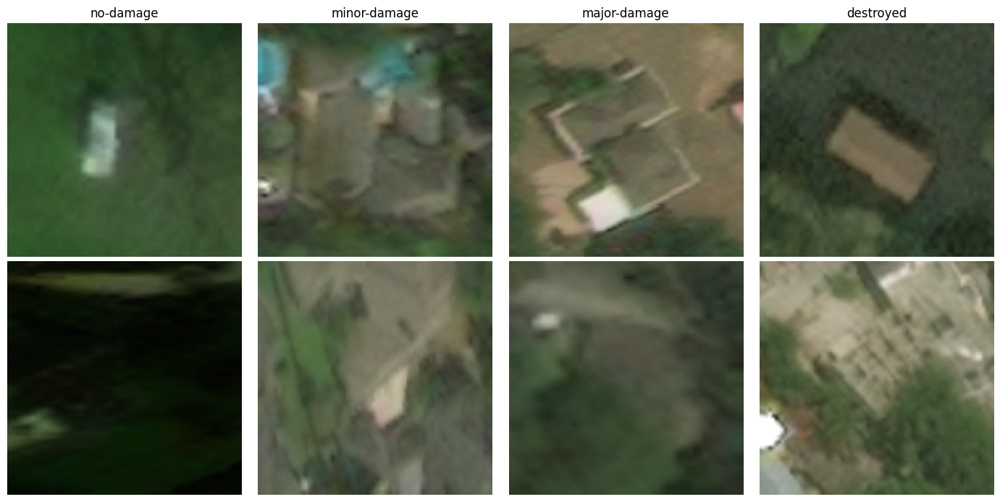

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image
import os

labels = [
    "no-damage",
    "minor-damage",
    "major-damage",
    "destroyed"
]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for col, label in enumerate(labels):
    folder = os.path.join(crop_root, label)
    filenames = sorted(os.listdir(folder))[:2]

    for row_idx in range(2):
        ax = axes[row_idx, col]

        if row_idx < len(filenames):
            img = Image.open(
                os.path.join(folder, filenames[row_idx])
            )
            ax.imshow(img)
            ax.set_title(label if row_idx == 0 else "")
        else:
            ax.set_visible(False)

        ax.axis("off")

plt.tight_layout()
plt.show()

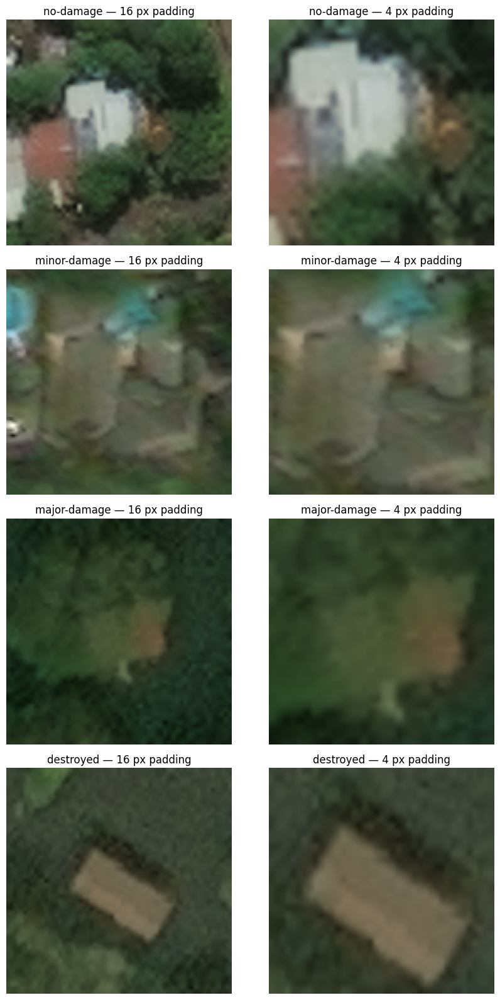

In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from shapely import wkt

train_df = pd.read_csv(
    "/content/drive/MyDrive/T229/reports/train_buildings.csv"
)

# Choose a few examples from different classes
examples = []
for label in [
    "no-damage", "minor-damage",
    "major-damage", "destroyed"
]:
    example = train_df[train_df["label"] == label].iloc[0]
    examples.append(example)

fig, axes = plt.subplots(4, 2, figsize=(9, 16))

for i, row in enumerate(examples):
    image = Image.open(row["image_path"]).convert("RGB")
    polygon = wkt.loads(row["polygon_wkt"])
    min_x, min_y, max_x, max_y = polygon.bounds

    # Current crop: 16-pixel padding
    current_box = (
        max(0, int(min_x) - 16),
        max(0, int(min_y) - 16),
        min(image.width, int(max_x) + 17),
        min(image.height, int(max_y) + 17)
    )

    # Tighter crop: 4-pixel padding
    tight_box = (
        max(0, int(min_x) - 4),
        max(0, int(min_y) - 4),
        min(image.width, int(max_x) + 5),
        min(image.height, int(max_y) + 5)
    )

    current_crop = image.crop(current_box).resize((128, 128))
    tight_crop = image.crop(tight_box).resize((128, 128))

    axes[i, 0].imshow(current_crop)
    axes[i, 0].set_title(f"{row['label']} — 16 px padding")
    axes[i, 1].imshow(tight_crop)
    axes[i, 1].set_title(f"{row['label']} — 4 px padding")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:

import pandas as pd
import numpy as np
from shapely import wkt

sample_df = pd.read_csv(
    "/content/drive/MyDrive/T229/reports/"
    "balanced_building_sample.csv"
)

widths = []
heights = []
areas = []

for polygon_wkt in sample_df["polygon_wkt"]:
    polygon = wkt.loads(polygon_wkt)
    min_x, min_y, max_x, max_y = polygon.bounds

    widths.append(max_x - min_x)
    heights.append(max_y - min_y)
    areas.append(polygon.area)

sizes = pd.DataFrame({
    "width_px": widths,
    "height_px": heights,
    "area_px": areas
})

print("Building bounding-box dimensions:")
print(sizes[["width_px", "height_px"]].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90]
).round(2))

print("\nBuildings smaller than 8 px in either dimension:",
      ((sizes["width_px"] < 8) |
       (sizes["height_px"] < 8)).sum())

print("Buildings at least 16 px in both dimensions:",
      ((sizes["width_px"] >= 16) &
       (sizes["height_px"] >= 16)).sum())

Building bounding-box dimensions:
       width_px  height_px
count  12000.00   12000.00
mean      35.47      34.73
std       26.28      24.04
min        1.49       3.25
25%       18.48      17.80
50%       31.35      31.57
75%       46.24      46.72
90%       58.66      57.98
max      385.99     709.01

Buildings smaller than 8 px in either dimension: 415
Buildings at least 16 px in both dimensions: 9089


In [ ]:

# import pandas as pd
# from PIL import Image
# from shapely import wkt

# sample_df = pd.read_csv(
#     "/content/drive/MyDrive/T229/reports/"
#     "balanced_building_sample.csv"
# )

# crop_widths = []
# crop_heights = []
# large_crop_count = 0
# invalid_count = 0

# for _, row in sample_df.iterrows():
#     polygon = wkt.loads(row["polygon_wkt"])
#     min_x, min_y, max_x, max_y = polygon.bounds

#     with Image.open(row["image_path"]) as image:
#         left = max(0, int(min_x) - 16)
#         top = max(0, int(min_y) - 16)
#         right = min(image.width, int(max_x) + 17)
#         bottom = min(image.height, int(max_y) + 17)

#     width = right - left
#     height = bottom - top

#     if width <= 0 or height <= 0:
#         invalid_count += 1
#         continue

#     crop_widths.append(width)
#     crop_heights.append(height)

#     if width > 256 or height > 256:
#         large_crop_count += 1

# print("Valid crops:", len(crop_widths))
# print("Invalid crops:", invalid_count)
# print("Crops exceeding 256 px in either dimension:", large_crop_count)
# print("Median crop width:", round(float(pd.Series(crop_widths).median()), 2))
# print("Median crop height:", round(float(pd.Series(crop_heights).median()), 2))

In [ ]:

# import os
# import pandas as pd
# from PIL import Image
# from shapely import wkt
# from tqdm.auto import tqdm

# root = "/content/drive/MyDrive/T229"
# output_root = os.path.join(root, "data", "building_crops")

# train_df = pd.read_csv(
#     os.path.join(root, "reports", "train_buildings.csv")
# )
# val_df = pd.read_csv(
#     os.path.join(root, "reports", "val_buildings.csv")
# )

# for split_name, dataframe in [
#     ("train", train_df),
#     ("val", val_df)
# ]:
#     for label in [
#         "no-damage", "minor-damage",
#         "major-damage", "destroyed"
#     ]:
#         os.makedirs(
#             os.path.join(output_root, split_name, label),
#             exist_ok=True
#         )

#     for idx, row in tqdm(
#         dataframe.iterrows(),
#         total=len(dataframe),
#         desc=f"Creating {split_name} crops"
#     ):
#         polygon = wkt.loads(row["polygon_wkt"])
#         min_x, min_y, max_x, max_y = polygon.bounds

#         with Image.open(row["image_path"]) as source:
#             image = source.convert("RGB")

#         left = max(0, int(min_x) - 16)
#         top = max(0, int(min_y) - 16)
#         right = min(image.width, int(max_x) + 17)
#         bottom = min(image.height, int(max_y) + 17)

#         if right <= left or bottom <= top:
#             continue

#         crop = image.crop((left, top, right, bottom))
#         crop = crop.resize(
#             (128, 128),
#             Image.Resampling.BILINEAR
#         )

#         filename = f"{idx}_{row['scene_id']}.jpg"
#         save_path = os.path.join(
#             output_root, split_name, row["label"], filename
#         )
#         crop.save(save_path, quality=95)

# print("\nCrop generation finished.")
# print("Dataset directory:", output_root)

In [ ]:

# import os

# for split_name in ["train", "val"]:
#     print(f"\n{split_name.upper()}")

#     total = 0
#     for label in [
#         "no-damage", "minor-damage",
#         "major-damage", "destroyed"
#     ]:
#         folder = os.path.join(
#             output_root, split_name, label
#         )
#         count = sum(
#             f.lower().endswith(".jpg")
#             for f in os.listdir(folder)
#         )
#         total += count
#         print(f"{label:15s}: {count:,}")

#     print("Total:", total)


In [ ]:

import torch
import torchvision
from PIL import Image

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024**3),
            2
        )
    )

print("Pillow version:", Image.__version__ if hasattr(Image, "__version__") else "Installed")


PyTorch version: 2.11.0+cpu
Torchvision version: 0.26.0+cpu
GPU available: False
Pillow version: 11.3.0


In [ ]:

import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

dataset_root = (
    "/content/drive/MyDrive/T229/data/building_crops"
)

# Standard normalization for ImageNet-pretrained models
image_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    os.path.join(dataset_root, "train"),
    transform=image_transform
)

val_dataset = datasets.ImageFolder(
    os.path.join(dataset_root, "val"),
    transform=image_transform
)

batch_size = 32
num_workers = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True
)

print("Class mapping:", train_dataset.class_to_idx)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)


Class mapping: {'destroyed': 0, 'major-damage': 1, 'minor-damage': 2, 'no-damage': 3}
Training images: 9114
Validation images: 2886
Training batches: 285
Validation batches: 91


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Batch image shape: torch.Size([32, 3, 128, 128])
Batch label shape: torch.Size([32])


In [ ]:

import torch
import torch.nn as nn
from torchvision import models

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load ImageNet-pretrained ResNet-18
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Replace the final layer with four damage classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 4)

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Device:", device)
print("Final classification layer:", model.fc)
print("Number of output classes:", model.fc.out_features)

# Test a batch through the model
images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 112MB/s]


AttributeError: partially initialized module 'torch._dynamo' from '/usr/local/lib/python3.13/dist-packages/torch/_dynamo/__init__.py' has no attribute 'decorators' (most likely due to a circular import)

In [ ]:

# import os
# import copy
# import numpy as np
# import pandas as pd
# import torch
# from sklearn.metrics import accuracy_score, f1_score
# from tqdm.auto import tqdm

# epochs = 3
# best_f1 = -1.0
# history = []

# checkpoint_dir = (
#     "/content/drive/MyDrive/T229/checkpoints"
# )
# os.makedirs(checkpoint_dir, exist_ok=True)

# best_model_path = os.path.join(
#     checkpoint_dir, "resnet18_damage_best.pth"
# )

# for epoch in range(epochs):
#     # Training
#     model.train()
#     running_loss = 0.0

#     progress = tqdm(
#         train_loader,
#         desc=f"Epoch {epoch + 1}/{epochs} - train"
#     )

#     for images, labels in progress:
#         images = images.to(device, non_blocking=True)
#         labels = labels.to(device, non_blocking=True)

#         optimizer.zero_grad(set_to_none=True)

#         outputs = model(images)
#         loss = criterion(outputs, labels)

#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item() * images.size(0)
#         progress.set_postfix(loss=f"{loss.item():.4f}")

#     train_loss = running_loss / len(train_dataset)

#     # Validation
#     model.eval()
#     val_loss_sum = 0.0
#     all_labels = []
#     all_predictions = []

#     with torch.no_grad():
#         for images, labels in tqdm(
#             val_loader,
#             desc=f"Epoch {epoch + 1}/{epochs} - val"
#         ):
#             images = images.to(device, non_blocking=True)
#             labels = labels.to(device, non_blocking=True)

#             outputs = model(images)
#             loss = criterion(outputs, labels)

#             val_loss_sum += loss.item() * images.size(0)

#             predictions = outputs.argmax(dim=1)
#             all_labels.extend(labels.cpu().numpy())
#             all_predictions.extend(predictions.cpu().numpy())

#     val_loss = val_loss_sum / len(val_dataset)
#     val_accuracy = accuracy_score(
#         all_labels, all_predictions
#     )
#     val_macro_f1 = f1_score(
#         all_labels,
#         all_predictions,
#         average="macro",
#         zero_division=0
#     )

#     history.append({
#         "epoch": epoch + 1,
#         "train_loss": train_loss,
#         "val_loss": val_loss,
#         "val_accuracy": val_accuracy,
#         "val_macro_f1": val_macro_f1
#     })

#     print(f"\nEpoch {epoch + 1}/{epochs}")
#     print(f"Train loss:      {train_loss:.4f}")
#     print(f"Validation loss: {val_loss:.4f}")
#     print(f"Validation acc:  {val_accuracy:.4f}")
#     print(f"Validation F1:   {val_macro_f1:.4f}")

#     # Save the best model based on validation macro-F1
#     if val_macro_f1 > best_f1:
#         best_f1 = val_macro_f1
#         torch.save({
#             "epoch": epoch + 1,
#             "model_state_dict": model.state_dict(),
#             "optimizer_state_dict": optimizer.state_dict(),
#             "class_to_idx": train_dataset.class_to_idx,
#             "val_macro_f1": val_macro_f1
#         }, best_model_path)

#         print("Saved new best checkpoint.")

# history_df = pd.DataFrame(history)
# history_path = os.path.join(
#     "/content/drive/MyDrive/T229/reports",
#     "resnet18_training_history.csv"
# )
# history_df.to_csv(history_path, index=False)

# print("\nTraining finished.")
# print("Best validation macro-F1:", round(best_f1, 4))
# print("Best checkpoint:", best_model_path)
# print("Training history:", history_path)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Best checkpoint epoch: 1
Saved validation macro-F1: 0.8197898827208341

Classification report:
              precision    recall  f1-score   support

   destroyed     0.9462    0.8357    0.8875       779
major-damage     0.7766    0.7414    0.7586       816
minor-damage     0.6531    0.7500    0.6982       640
   no-damage     0.9123    0.9585    0.9348       651

    accuracy                         0.8177      2886
   macro avg     0.8220    0.8214    0.8198      2886
weighted avg     0.8256    0.8177    0.8198      2886



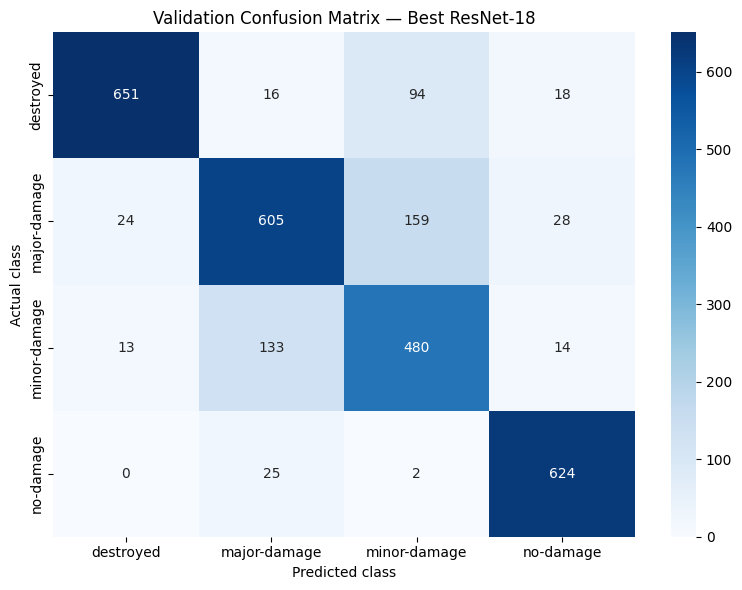

In [ ]:

import os
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import models
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "resnet18_damage_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Restore the best model
best_model = models.resnet18(weights=None)
best_model.fc = torch.nn.Linear(
    best_model.fc.in_features, 4
)
best_model.load_state_dict(checkpoint["model_state_dict"])
best_model = best_model.to(device)
best_model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

class_names = [
    name for name, idx
    in sorted(
        val_dataset.class_to_idx.items(),
        key=lambda item: item[1]
    )
]

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Saved validation macro-F1:", checkpoint["val_macro_f1"])

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Validation Confusion Matrix — Best ResNet-18")
plt.tight_layout()
plt.show()


In [ ]:

# Inspect major-damage buildings predicted as minor-damage

import numpy as np

major_idx = val_dataset.class_to_idx["major-damage"]
minor_idx = val_dataset.class_to_idx["minor-damage"]

wrong_indices = [
    i for i, (actual, predicted) in enumerate(
        zip(all_labels, all_predictions)
    )
    if actual == major_idx and predicted == minor_idx
]

print("Major damage predicted as minor damage:", len(wrong_indices))
print("First 10 validation dataset indices:", wrong_indices[:10])


Major damage predicted as minor damage: 159
First 10 validation dataset indices: [779, 780, 784, 791, 794, 795, 805, 809, 817, 825]


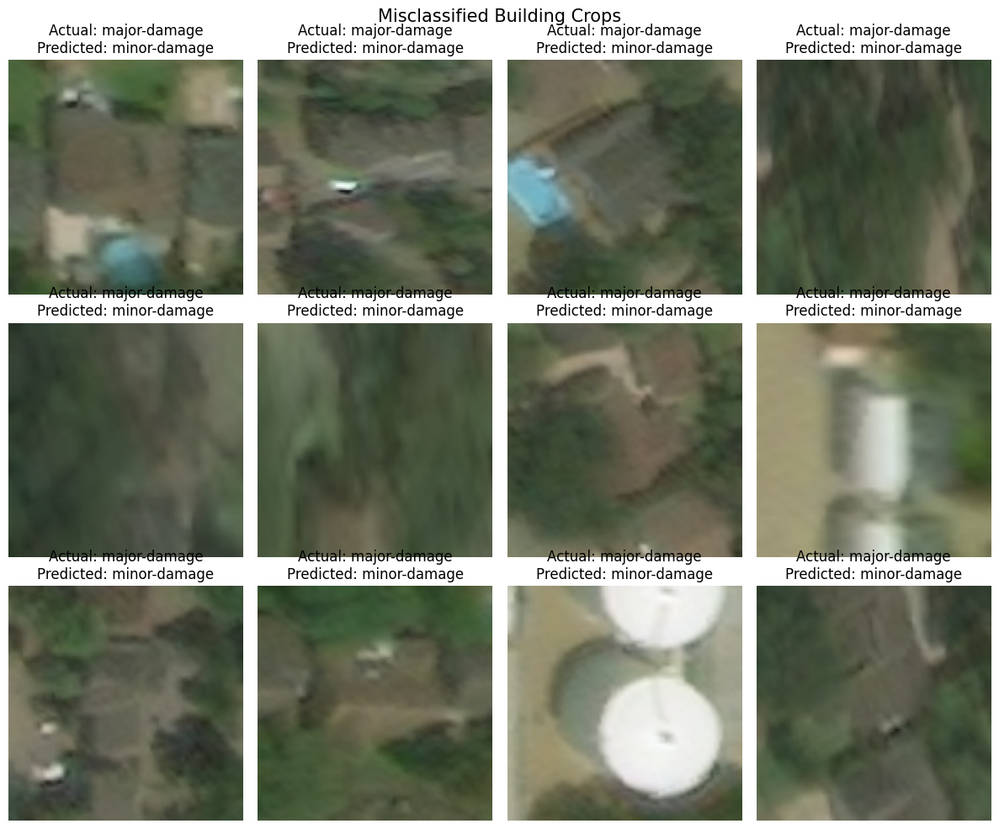

In [ ]:

import matplotlib.pyplot as plt
import random

# Reproducible sample of misclassified examples
random.seed(42)
sample_indices = random.sample(
    wrong_indices, min(12, len(wrong_indices))
)

fig, axes = plt.subplots(3, 4, figsize=(12, 10))
axes = axes.flatten()

for ax, idx in zip(axes, sample_indices):
    image, label = val_dataset[idx]

    # Undo ImageNet normalization for display
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    image = (image * std + mean).clamp(0, 1)

    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title("Actual: major-damage\nPredicted: minor-damage")
    ax.axis("off")

plt.suptitle("Misclassified Building Crops", fontsize=15)
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd

val_df = pd.read_csv(
    "/content/drive/MyDrive/T229/reports/val_buildings.csv"
)

print("Columns:")
print(val_df.columns.tolist())

print("\nFirst 3 validation records:")
display(val_df.head(3))


Columns:
['scene_id', 'image_path', 'label', 'polygon_wkt']

First 3 validation records:


,scene_id,image_path,label,polygon_wkt
0,hurricane-harvey_00000132,/content/drive/MyDrive/T229/data/train/images/...,minor-damage,"POLYGON ((380.7673822794917 1022.988691617148,..."
1,hurricane-florence_00000091,/content/drive/MyDrive/T229/data/train/images/...,no-damage,"POLYGON ((614.9052939733259 151.8742402001954,..."
2,hurricane-michael_00000067,/content/drive/MyDrive/T229/data/train/images/...,destroyed,"POLYGON ((214.5574423012306 168.0310925103237,..."


In [ ]:

import os
import glob

image_dir = "/content/drive/MyDrive/T229/data/train/images"

# Inspect one validation record
row = val_df.iloc[0]
print("Scene ID:", row["scene_id"])
print("Post-disaster image path:", row["image_path"])
print("Post image exists:", os.path.exists(row["image_path"]))

# Search for image files associated with this scene
scene_id = row["scene_id"]
matches = glob.glob(os.path.join(image_dir, f"*{scene_id}*"))

print("\nMatching files:")
for path in matches[:10]:
    print(os.path.basename(path))

print("\nTotal matches:", len(matches))


Scene ID: hurricane-harvey_00000132
Post-disaster image path: /content/drive/MyDrive/T229/data/train/images/hurricane-harvey_00000132_post_disaster.png
Post image exists: True

Matching files:
hurricane-harvey_00000132_post_disaster.png
hurricane-harvey_00000132_pre_disaster.png

Total matches: 2


Pre-disaster dimensions: (1024, 1024)
Post-disaster dimensions: (1024, 1024)
Same dimensions: True


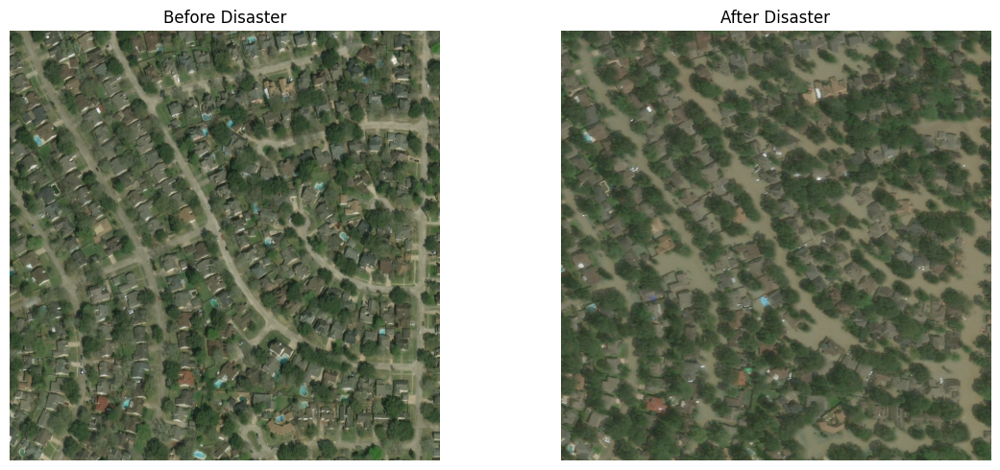

In [ ]:

from PIL import Image
import os

row = val_df.iloc[0]

post_path = row["image_path"]
pre_path = post_path.replace(
    "_post_disaster.png",
    "_pre_disaster.png"
)

pre_image = Image.open(pre_path).convert("RGB")
post_image = Image.open(post_path).convert("RGB")

print("Pre-disaster dimensions:", pre_image.size)
print("Post-disaster dimensions:", post_image.size)
print("Same dimensions:", pre_image.size == post_image.size)

# Display both images side by side
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(pre_image)
axes[0].set_title("Before Disaster")
axes[0].axis("off")

axes[1].imshow(post_image)
axes[1].set_title("After Disaster")
axes[1].axis("off")

plt.tight_layout()
plt.show()


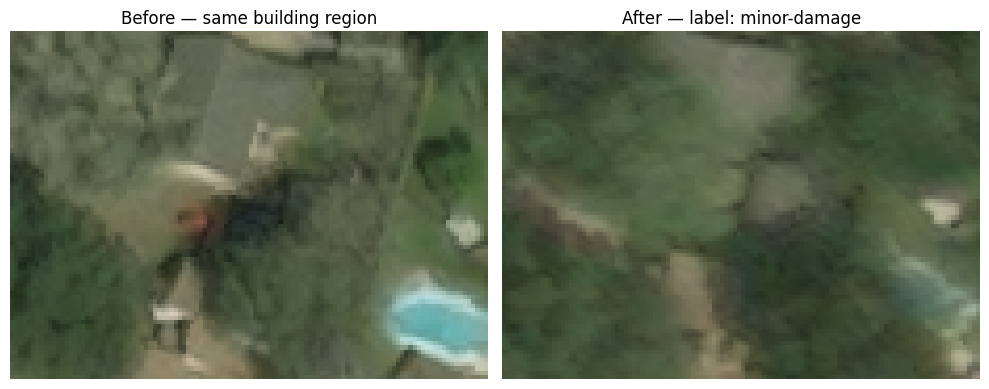

Building label: minor-damage
Crop dimensions: (114, 83)


In [ ]:

from shapely import wkt
from PIL import Image
import matplotlib.pyplot as plt

row = val_df.iloc[0]

post_path = row["image_path"]
pre_path = post_path.replace(
    "_post_disaster.png",
    "_pre_disaster.png"
)

polygon = wkt.loads(row["polygon_wkt"])
minx, miny, maxx, maxy = polygon.bounds

# Add 32 pixels of context around the building
padding = 32
left = max(0, int(minx) - padding)
top = max(0, int(miny) - padding)
right = min(1024, int(maxx) + padding + 1)
bottom = min(1024, int(maxy) + padding + 1)

pre_img = Image.open(pre_path).convert("RGB")
post_img = Image.open(post_path).convert("RGB")

pre_crop = pre_img.crop((left, top, right, bottom))
post_crop = post_img.crop((left, top, right, bottom))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(pre_crop)
axes[0].set_title("Before — same building region")
axes[1].imshow(post_crop)
axes[1].set_title(f"After — label: {row['label']}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Building label:", row["label"])
print("Crop dimensions:", pre_crop.size)


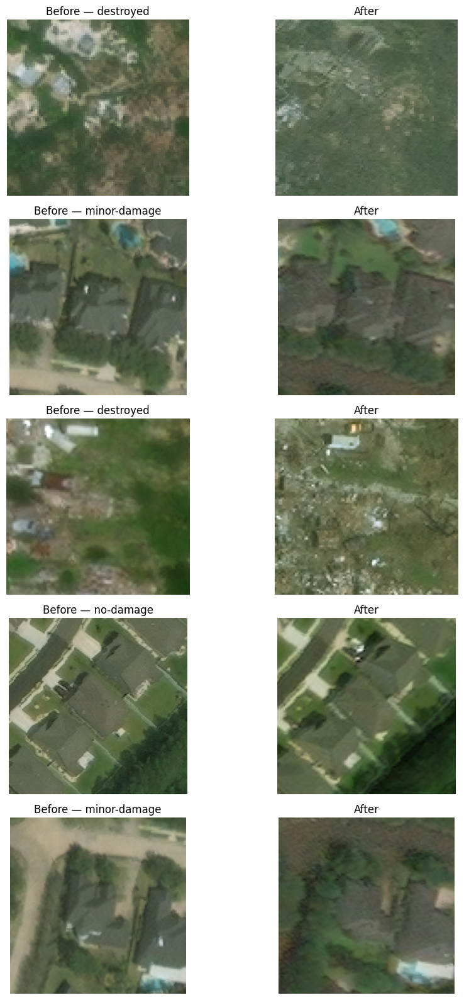

In [ ]:

import random
import matplotlib.pyplot as plt
from PIL import Image
from shapely import wkt

random.seed(42)
sample_rows = val_df.sample(
    n=min(5, len(val_df)), random_state=42
)

fig, axes = plt.subplots(5, 2, figsize=(10, 16))

for i, (_, row) in enumerate(sample_rows.iterrows()):
    post_path = row["image_path"]
    pre_path = post_path.replace(
        "_post_disaster.png", "_pre_disaster.png"
    )

    polygon = wkt.loads(row["polygon_wkt"])
    minx, miny, maxx, maxy = polygon.bounds

    pad = 40
    left = max(0, int(minx) - pad)
    top = max(0, int(miny) - pad)
    right = min(1024, int(maxx) + pad + 1)
    bottom = min(1024, int(maxy) + pad + 1)

    pre = Image.open(pre_path).convert("RGB")
    post = Image.open(post_path).convert("RGB")

    axes[i, 0].imshow(pre.crop((left, top, right, bottom)))
    axes[i, 0].set_title(f"Before — {row['label']}")
    axes[i, 1].imshow(post.crop((left, top, right, bottom)))
    axes[i, 1].set_title("After")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


Pre-image features: 3000
Post-image features: 3000
Good feature matches: 15
RANSAC inliers: 4
Inlier ratio: 0.267


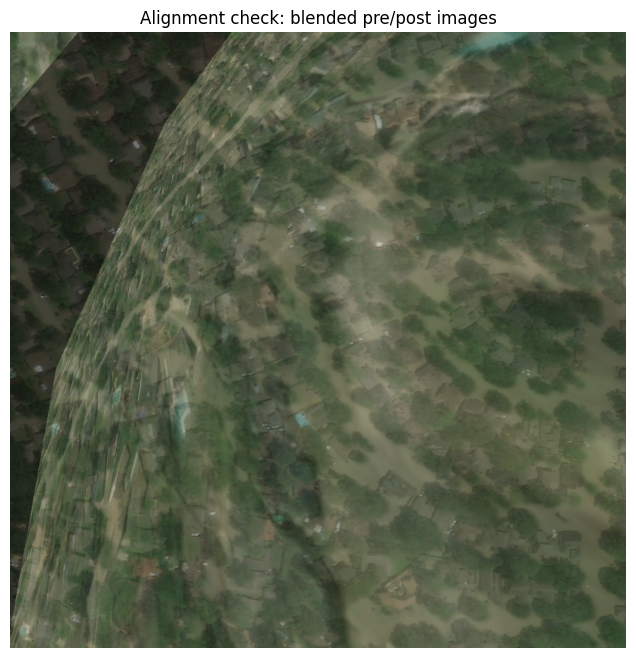

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

row = val_df.iloc[0]

post_path = row["image_path"]
pre_path = post_path.replace(
    "_post_disaster.png",
    "_pre_disaster.png"
)

pre = cv2.imread(pre_path)
post = cv2.imread(post_path)

pre_gray = cv2.cvtColor(pre, cv2.COLOR_BGR2GRAY)
post_gray = cv2.cvtColor(post, cv2.COLOR_BGR2GRAY)

# Detect and match visual features
orb = cv2.ORB_create(nfeatures=3000)

kp_pre, des_pre = orb.detectAndCompute(pre_gray, None)
kp_post, des_post = orb.detectAndCompute(post_gray, None)

print("Pre-image features:", len(kp_pre))
print("Post-image features:", len(kp_post))

if des_pre is not None and des_post is not None:
    matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
    pairs = matcher.knnMatch(des_pre, des_post, k=2)

    good = [
        m for m, n in pairs
        if m.distance < 0.75 * n.distance
    ]

    print("Good feature matches:", len(good))

    if len(good) >= 10:
        pts_pre = np.float32(
            [kp_pre[m.queryIdx].pt for m in good]
        ).reshape(-1, 1, 2)

        pts_post = np.float32(
            [kp_post[m.trainIdx].pt for m in good]
        ).reshape(-1, 1, 2)

        H, inliers = cv2.findHomography(
            pts_pre, pts_post, cv2.RANSAC, 5.0
        )

        if H is not None:
            print("RANSAC inliers:", int(inliers.sum()))
            print("Inlier ratio:", round(float(inliers.mean()), 3))

            aligned_pre = cv2.warpPerspective(
                pre, H, (post.shape[1], post.shape[0])
            )

            comparison = cv2.addWeighted(
                aligned_pre, 0.5, post, 0.5, 0
            )

            plt.figure(figsize=(8, 8))
            plt.imshow(cv2.cvtColor(comparison, cv2.COLOR_BGR2RGB))
            plt.title("Alignment check: blended pre/post images")
            plt.axis("off")
            plt.show()
        else:
            print("Could not estimate a reliable homography.")
    else:
        print("Too few matches to estimate alignment reliably.")
else:
    print("Feature descriptors could not be computed.")


In [ ]:

# Test a second scene without applying any image transformation

row2 = val_df.iloc[10]

post_path2 = row2["image_path"]
pre_path2 = post_path2.replace(
    "_post_disaster.png",
    "_pre_disaster.png"
)

pre2 = cv2.imread(pre_path2)
post2 = cv2.imread(post_path2)

pre_gray2 = cv2.cvtColor(pre2, cv2.COLOR_BGR2GRAY)
post_gray2 = cv2.cvtColor(post2, cv2.COLOR_BGR2GRAY)

kp1, des1 = orb.detectAndCompute(pre_gray2, None)
kp2, des2 = orb.detectAndCompute(post_gray2, None)

print("Scene:", row2["scene_id"])
print("Label:", row2["label"])
print("Pre-image features:", len(kp1))
print("Post-image features:", len(kp2))

if des1 is not None and des2 is not None:
    matches = cv2.BFMatcher(
        cv2.NORM_HAMMING
    ).knnMatch(des1, des2, k=2)

    good2 = [
        m for m, n in matches
        if m.distance < 0.75 * n.distance
    ]

    print("Good feature matches:", len(good2))

    if len(good2) >= 10:
        p1 = np.float32(
            [kp1[m.queryIdx].pt for m in good2]
        ).reshape(-1, 1, 2)
        p2 = np.float32(
            [kp2[m.trainIdx].pt for m in good2]
        ).reshape(-1, 1, 2)

        H2, mask2 = cv2.findHomography(
            p1, p2, cv2.RANSAC, 5.0
        )

        if H2 is not None:
            print("RANSAC inliers:", int(mask2.sum()))
            print("Inlier ratio:", round(float(mask2.mean()), 3))
        else:
            print("Homography estimation failed.")
else:
    print("Feature descriptors unavailable.")


Scene: hurricane-florence_00000404
Label: minor-damage
Pre-image features: 2603
Post-image features: 1922
Good feature matches: 37
RANSAC inliers: 23
Inlier ratio: 0.622


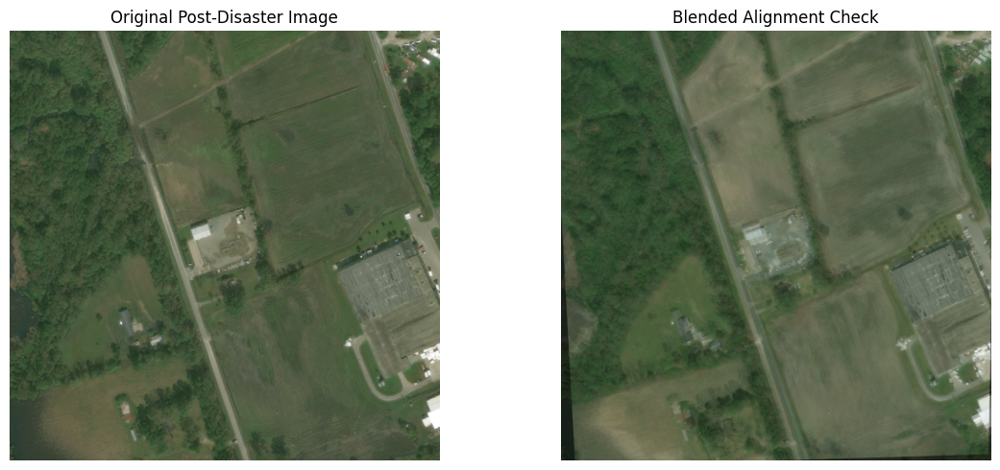

Estimated homography:
[[ 1.06661383e+00  5.93288901e-02 -2.39768155e+01]
 [ 3.81998477e-04  1.10913592e+00 -1.60735704e+01]
 [ 3.03727557e-05  7.68263138e-05  1.00000000e+00]]


In [ ]:

# Visualize the second scene's estimated alignment

aligned_pre2 = cv2.warpPerspective(
    pre2,
    H2,
    (post2.shape[1], post2.shape[0])
)

blended2 = cv2.addWeighted(
    aligned_pre2, 0.5,
    post2, 0.5,
    0
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(
    cv2.cvtColor(post2, cv2.COLOR_BGR2RGB)
)
axes[0].set_title("Original Post-Disaster Image")
axes[0].axis("off")

axes[1].imshow(
    cv2.cvtColor(blended2, cv2.COLOR_BGR2RGB)
)
axes[1].set_title("Blended Alignment Check")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Estimated homography:")
print(H2)


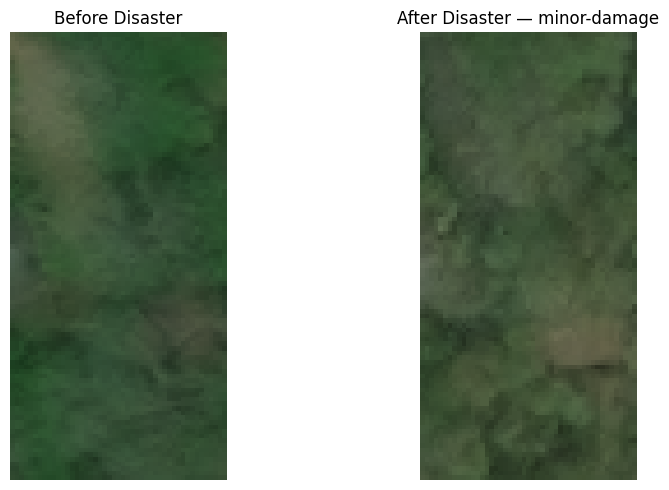

Scene: hurricane-florence_00000404
Label: minor-damage
Crop size: 47 x 97


In [ ]:

# Inspect a building from the Florence scene
row = val_df[
    val_df["scene_id"] == "hurricane-florence_00000404"
].iloc[0]

post_path = row["image_path"]
pre_path = post_path.replace(
    "_post_disaster.png", "_pre_disaster.png"
)

polygon = wkt.loads(row["polygon_wkt"])
minx, miny, maxx, maxy = polygon.bounds

pad = 40
left = max(0, int(minx) - pad)
top = max(0, int(miny) - pad)
right = min(1024, int(maxx) + pad + 1)
bottom = min(1024, int(maxy) + pad + 1)

pre_img = Image.open(pre_path).convert("RGB")
post_img = Image.open(post_path).convert("RGB")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(pre_img.crop((left, top, right, bottom)))
axes[0].set_title("Before Disaster")
axes[1].imshow(post_img.crop((left, top, right, bottom)))
axes[1].set_title(f"After Disaster — {row['label']}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Scene:", row["scene_id"])
print("Label:", row["label"])
print("Crop size:", right - left, "x", bottom - top)


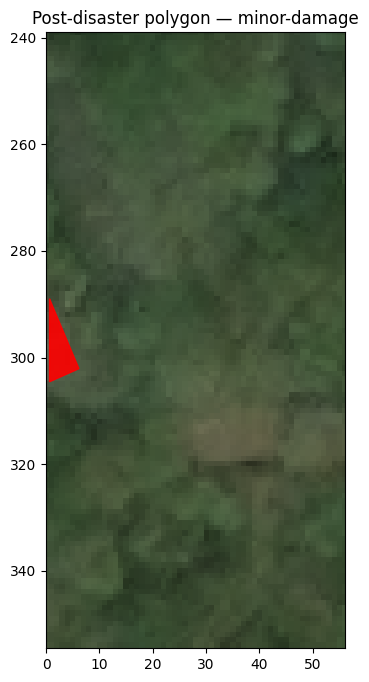

Polygon bounds: (0.6410710506094792, 288.9774358621206, 6.161099466914714, 304.5583293729878)
Polygon area: 43.00334752349167


In [ ]:

import matplotlib.pyplot as plt
from PIL import Image
from shapely import wkt
from shapely.plotting import plot_polygon

row = val_df[
    val_df["scene_id"] == "hurricane-florence_00000404"
].iloc[0]

img = Image.open(row["image_path"]).convert("RGB")
polygon = wkt.loads(row["polygon_wkt"])

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img)
plot_polygon(
    polygon,
    ax=ax,
    add_points=False,
    color="red",
    alpha=0.9
)

ax.set_xlim(
    max(0, polygon.bounds[0] - 50),
    min(img.width, polygon.bounds[2] + 50)
)
ax.set_ylim(
    min(img.height, polygon.bounds[3] + 50),
    max(0, polygon.bounds[1] - 50)
)

ax.set_title(f"Post-disaster polygon — {row['label']}")
plt.show()

print("Polygon bounds:", polygon.bounds)
print("Polygon area:", polygon.area)


In [ ]:

from shapely import wkt

scene_df = val_df[
    val_df["scene_id"] == "hurricane-florence_00000404"
].copy()

def polygon_info(geometry_text):
    poly = wkt.loads(geometry_text)
    minx, miny, maxx, maxy = poly.bounds
    return pd.Series({
        "width": maxx - minx,
        "height": maxy - miny,
        "area": poly.area,
        "minx": minx,
        "miny": miny,
        "maxx": maxx,
        "maxy": maxy
    })

scene_df = pd.concat(
    [scene_df, scene_df["polygon_wkt"].apply(polygon_info)],
    axis=1
)

# Prefer larger polygons with enough space from image edges
candidates = scene_df[
    (scene_df["width"] >= 15) &
    (scene_df["height"] >= 15) &
    (scene_df["minx"] >= 40) &
    (scene_df["miny"] >= 40) &
    (scene_df["maxx"] <= 984) &
    (scene_df["maxy"] <= 984)
].sort_values("area", ascending=False)

print("Candidates found:", len(candidates))
display(
    candidates[
        ["label", "width", "height", "area", "polygon_wkt"]
    ].head(5)
)


Candidates found: 1


,label,width,height,area,polygon_wkt
1074,minor-damage,28.265159,22.980189,382.416037,"POLYGON ((65.65775351738084 228.4328662341168,..."


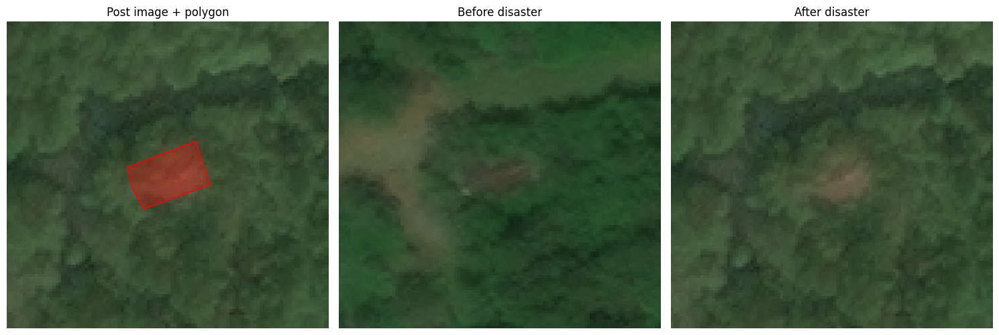

Scene: hurricane-florence_00000404
Label: minor-damage
Crop size: 109 x 104


In [ ]:

from shapely import wkt
from shapely.plotting import plot_polygon
from PIL import Image
import matplotlib.pyplot as plt

row = candidates.iloc[0]

post_path = row["image_path"]
pre_path = post_path.replace(
    "_post_disaster.png", "_pre_disaster.png"
)

polygon = wkt.loads(row["polygon_wkt"])
minx, miny, maxx, maxy = polygon.bounds

pad = 40
left = max(0, int(minx) - pad)
top = max(0, int(miny) - pad)
right = min(1024, int(maxx) + pad + 1)
bottom = min(1024, int(maxy) + pad + 1)

pre_img = Image.open(pre_path).convert("RGB")
post_img = Image.open(post_path).convert("RGB")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(post_img)
plot_polygon(polygon, ax=axes[0], add_points=False, color="red")
axes[0].set_xlim(left, right)
axes[0].set_ylim(bottom, top)
axes[0].set_title("Post image + polygon")

axes[1].imshow(pre_img.crop((left, top, right, bottom)))
axes[1].set_title("Before disaster")

axes[2].imshow(post_img.crop((left, top, right, bottom)))
axes[2].set_title("After disaster")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Scene:", row["scene_id"])
print("Label:", row["label"])
print("Crop size:", right-left, "x", bottom-top)


In [ ]:

from shapely import wkt
import pandas as pd

def inspect_polygon(wkt_text):
    poly = wkt.loads(wkt_text)
    minx, miny, maxx, maxy = poly.bounds
    return pd.Series({
        "width": maxx - minx,
        "height": maxy - miny,
        "area": poly.area,
        "touches_edge": (
            minx < 2 or miny < 2 or
            maxx > 1022 or maxy > 1022
        )
    })

polygon_stats = val_df["polygon_wkt"].apply(inspect_polygon)
val_quality = pd.concat([val_df, polygon_stats], axis=1)

print("Validation buildings:", len(val_quality))
print("Polygons touching image edges:",
      int(val_quality["touches_edge"].sum()))
print("Polygons smaller than 8 px in either dimension:",
      int(((val_quality["width"] < 8) |
           (val_quality["height"] < 8)).sum()))
print("Polygons with area below 100 px²:",
      int((val_quality["area"] < 100).sum()))

print("\nPolygon dimensions:")
display(val_quality[["width", "height", "area"]].describe())


Validation buildings: 2886
Polygons touching image edges: 268
Polygons smaller than 8 px in either dimension: 108
Polygons with area below 100 px²: 246

Polygon dimensions:


,width,height,area
count,2886.000000,2886.000000,2886.000000
mean,35.314581,34.940282,1026.853748
std,24.607161,23.087373,1863.207593
min,3.253985,3.885462,17.322183
25%,19.370610,18.767595,253.379866
50%,33.284498,33.911722,807.491048
75%,44.784223,45.719024,1312.795196
max,335.574141,512.203532,59462.963157


In [ ]:

quality_summary = (
    val_quality.groupby("label")
    .agg(
        buildings=("label", "size"),
        edge_polygons=("touches_edge", "sum"),
        tiny_polygons=(
            "width",
            lambda s: int(
                ((s < 8) |
                 (val_quality.loc[s.index, "height"] < 8)).sum()
            )
        ),
        small_area=("area", lambda s: int((s < 100).sum())),
        median_width=("width", "median"),
        median_height=("height", "median")
    )
)

quality_summary["edge_percent"] = (
    100 * quality_summary["edge_polygons"] /
    quality_summary["buildings"]
).round(1)

quality_summary["tiny_percent"] = (
    100 * quality_summary["tiny_polygons"] /
    quality_summary["buildings"]
).round(1)

quality_summary["small_area_percent"] = (
    100 * quality_summary["small_area"] /
    quality_summary["buildings"]
).round(1)

display(quality_summary.round(2))


,buildings,edge_polygons,tiny_polygons,small_area,median_width,median_height,edge_percent,tiny_percent,small_area_percent
label,,,,,,,,,
destroyed,779,44,71,167,17.59,16.45,5.6,9.1,21.4
major-damage,816,82,13,33,37.16,39.19,10.0,1.6,4.0
minor-damage,640,79,5,7,42.49,45.17,12.3,0.8,1.1
no-damage,651,63,19,39,34.61,32.73,9.7,2.9,6.0


In [ ]:

# Compare polygon quality for correct vs incorrect predictions

val_quality = val_quality.reset_index(drop=True)

val_quality["actual_idx"] = [
    val_dataset.class_to_idx[label]
    for label in val_quality["label"]
]

val_quality["predicted_idx"] = all_predictions

val_quality["prediction_result"] = (
    val_quality["actual_idx"] ==
    val_quality["predicted_idx"]
).map({True: "Correct", False: "Incorrect"})

error_summary = (
    val_quality.groupby("prediction_result")
    .agg(
        buildings=("label", "size"),
        median_width=("width", "median"),
        median_height=("height", "median"),
        median_area=("area", "median"),
        edge_percent=("touches_edge",
                      lambda s: 100 * s.mean()),
        tiny_percent=("width",
                      lambda s: 100 * (
                          (s < 8) |
                          (val_quality.loc[s.index, "height"] < 8)
                      ).mean()),
    )
    .round(2)
)

display(error_summary)


,buildings,median_width,median_height,median_area,edge_percent,tiny_percent
prediction_result,,,,,,
Correct,715,34.42,35.65,890.26,9.37,4.90
Incorrect,2171,33.02,33.19,787.81,9.26,3.36


In [ ]:

import numpy as np

# Recompute predictions directly from the best checkpoint
best_model.eval()
fresh_labels = []
fresh_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = best_model(images)

        fresh_predictions.extend(
            outputs.argmax(dim=1).cpu().numpy()
        )
        fresh_labels.extend(labels.numpy())

fresh_labels = np.array(fresh_labels)
fresh_predictions = np.array(fresh_predictions)

# ImageFolder dataset order should match val_loader order
csv_labels = np.array([
    val_dataset.class_to_idx[label]
    for label in val_df["label"]
])

print("Validation examples:", len(fresh_labels))
print("CSV rows:", len(csv_labels))
print("Loader labels match CSV order:",
      np.array_equal(fresh_labels, csv_labels))

print("Fresh accuracy:",
      round(float(np.mean(fresh_labels == fresh_predictions)), 4))

print("Fresh correct predictions:",
      int(np.sum(fresh_labels == fresh_predictions)))


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Validation examples: 2886
CSV rows: 2886
Loader labels match CSV order: False
Fresh accuracy: 0.8177
Fresh correct predictions: 2360


In [ ]:

import os
import numpy as np
import pandas as pd

# Map each validation image filename to its true label and prediction.
# ImageFolder stores image paths in dataset.samples.
image_paths = [path for path, _ in val_dataset.samples]

pred_df = pd.DataFrame({
    "image_path": image_paths,
    "actual_idx": fresh_labels,
    "predicted_idx": fresh_predictions
})

idx_to_class = {
    idx: name
    for name, idx in val_dataset.class_to_idx.items()
}

pred_df["actual_label"] = pred_df["actual_idx"].map(idx_to_class)
pred_df["predicted_label"] = pred_df["predicted_idx"].map(idx_to_class)

# Join predictions to CSV metadata using the image crop filename.
val_quality["crop_path"] = val_quality["image_path"].apply(
    lambda p: os.path.join(
        "/content/drive/MyDrive/T229/data/building_crops/val",
        val_quality.loc[val_quality["image_path"] == p, "label"].iloc[0],
        os.path.basename(p).replace("_post_disaster.png", ".jpg")
    )
) if False else None

# Use crop filenames to match each prediction to its metadata.
# The crop filenames retain the source image name and polygon identifier.
pred_df["crop_name"] = pred_df["image_path"].apply(os.path.basename)
print("Example crop filenames:")
print(pred_df["crop_name"].head().to_list())

print("\nPrediction counts:")
print("Correct:", int((pred_df["actual_idx"] == pred_df["predicted_idx"]).sum()))
print("Incorrect:", int((pred_df["actual_idx"] != pred_df["predicted_idx"]).sum()))


Example crop filenames:
['1001_hurricane-matthew_00000336.jpg', '1003_hurricane-matthew_00000398.jpg', '1004_hurricane-matthew_00000380.jpg', '1010_hurricane-matthew_00000205.jpg', '1011_hurricane-matthew_00000186.jpg']

Prediction counts:
Correct: 2360
Incorrect: 526


In [ ]:

# # Rebuild the exact crop filename for each validation CSV row
# val_quality = val_quality.reset_index(drop=True)

# val_quality["crop_name"] = [
#     f"{i}_{os.path.basename(path).replace('_post_disaster.png', '')}.jpg"
#     for i, path in enumerate(val_quality["image_path"])
# ]

# # Match metadata to predictions using the exact crop filename
# matched = val_quality.merge(
#     pred_df,
#     on="crop_name",
#     how="inner",
#     suffixes=("_csv", "_pred")
# )

# print("CSV validation rows:", len(val_quality))
# print("Matched prediction rows:", len(matched))

# if len(matched) == len(val_quality):
#     matched["prediction_result"] = np.where(
#         matched["actual_idx"] == matched["predicted_idx"],
#         "Correct",
#         "Incorrect"
#     )

#     display(
#         matched.groupby("prediction_result").agg(
#             buildings=("label", "size"),
#             median_width=("width", "median"),
#             median_height=("height", "median"),
#             median_area=("area", "median"),
#             edge_percent=("touches_edge", lambda s: 100 * s.mean())
#         ).round(2)
#     )
# else:
#     print("Filename conventions differ; inspect these examples:")
#     print("CSV:", val_quality["crop_name"].head().to_list())
#     print("Predictions:", pred_df["crop_name"].head().to_list())


In [ ]:

# Check the column names created by the merge
print(matched.columns.tolist())


NameError: name 'matched' is not defined

In [ ]:

# The CSV label is the ground truth.
# The prediction table contains the model's predicted class.
matched["prediction_result"] = np.where(
    matched["label"] == matched["predicted_label"],
    "Correct",
    "Incorrect"
)

error_summary = (
    matched.groupby("prediction_result")
    .agg(
        buildings=("label", "size"),
        median_width=("width", "median"),
        median_height=("height", "median"),
        median_area=("area", "median"),
        edge_percent=("touches_edge", lambda s: 100 * s.mean()),
        tiny_percent=("width", lambda s: 100 * (
            (s < 8) |
            (matched.loc[s.index, "height"] < 8)
        ).mean())
    )
    .round(2)
)

display(error_summary)


NameError: name 'matched' is not defined

In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_names = [
    "destroyed",
    "major-damage",
    "minor-damage",
    "no-damage"
]

cm = confusion_matrix(
    matched["actual_label"],
    matched["predicted_label"],
    labels=class_names
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=35)
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()


NameError: name 'matched' is not defined

In [ ]:

import os
import matplotlib.pyplot as plt
from PIL import Image

# Find major-damage buildings predicted as minor-damage
errors = matched[
    (matched["actual_label"] == "major-damage") &
    (matched["predicted_label"] == "minor-damage")
].head(12)

print("Major → minor errors displayed:", len(errors))

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for ax, (_, row) in zip(axes, errors.iterrows()):
    img = Image.open(row["image_path_pred"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(
        f"True: major\nPredicted: minor",
        fontsize=9
    )
    ax.axis("off")

for ax in axes[len(errors):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import os
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

# Reuse the same major -> minor errors
errors = matched[
    (matched["actual_label"] == "major-damage") &
    (matched["predicted_label"] == "minor-damage")
].head(6)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.flatten()

for ax, (_, row) in zip(axes, errors.iterrows()):
    image_path = row["image_path_csv"]
    image = Image.open(image_path).convert("RGB")

    # Read the building polygon from the original annotation
    from shapely import wkt
    polygon = wkt.loads(row["polygon_wkt"])
    minx, miny, maxx, maxy = polygon.bounds

    # Expand the crop to provide 3x more context
    cx, cy = (minx + maxx) / 2, (miny + maxy) / 2
    half_w = max((maxx - minx) * 1.5, 48)
    half_h = max((maxy - miny) * 1.5, 48)

    left = max(0, int(cx - half_w))
    top = max(0, int(cy - half_h))
    right = min(image.width, int(cx + half_w))
    bottom = min(image.height, int(cy + half_h))

    crop = image.crop((left, top, right, bottom))
    ax.imshow(crop)
    ax.set_title("True: major | Predicted: minor")
    ax.axis("off")

plt.tight_layout()
plt.show()


NameError: name 'matched' is not defined

In [ ]:
project_root = "/content/drive/MyDrive/T229"

train_csv = f"{project_root}/reports/train_buildings.csv"
val_csv = f"{project_root}/reports/val_buildings.csv"

train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)

print("\nColumns:")
print(train_df.columns.tolist())

print("\nFirst training row:")
display(train_df.head(1))


In [ ]:

# from PIL import Image
# from shapely import wkt

# project_root = "/content/drive/MyDrive/T229"

# output_root = f"{project_root}/data/building_crops_context"
# padding = 48
# output_size = (128, 128)

# splits = {
#     "train": f"{project_root}/reports/train_buildings.csv",
#     "val": f"{project_root}/reports/val_buildings.csv",
# }

# for split, csv_path in splits.items():
#     df = pd.read_csv(csv_path)
#     print(f"\nProcessing {split}: {len(df)} buildings")

#     for _, row in tqdm(df.iterrows(), total=len(df)):
#         image_path = row["image_path"]
#         label = row["label"]

#         # Read the original post-disaster image
#         with Image.open(image_path) as source:
#             image = source.convert("RGB")
#             polygon = wkt.loads(row["polygon_wkt"])
#             minx, miny, maxx, maxy = polygon.bounds

#             # Expand the building bounding box
#             left = max(0, int(minx) - padding)
#             top = max(0, int(miny) - padding)
#             right = min(image.width, int(maxx) + padding)
#             bottom = min(image.height, int(maxy) + padding)

#             if right <= left or bottom <= top:
#                 continue

#             crop = image.crop((left, top, right, bottom))
#             crop = crop.resize(output_size, Image.Resampling.BILINEAR)

#             # Keep filenames consistent with the original dataset
#             filename = f"{row.name}_{row['scene_id']}.jpg"
#             save_dir = os.path.join(output_root, split, label)
#             os.makedirs(save_dir, exist_ok=True)
#             crop.save(os.path.join(save_dir, filename), quality=95)

#     print(f"Finished {split}")

# print("\nLarger-context crop generation complete!")
# print("Output:", output_root)


In [ ]:
context_root = "/content/drive/MyDrive/T229/data/building_crops_context"
classes = [
    "destroyed",
    "major-damage",
    "minor-damage",
    "no-damage"
]

for split in ["train", "val"]:
    print(f"\n{split.upper()}")

    total = 0
    for cls in classes:
        folder = os.path.join(context_root, split, cls)
        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])
        print(f"{cls}: {count}")
        total += count

    print("Total:", total)


In [ ]:

import os
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

context_root = "/content/drive/MyDrive/T229/data/building_crops_context"

image_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

context_train_dataset = datasets.ImageFolder(
    os.path.join(context_root, "train"),
    transform=image_transform
)

context_val_dataset = datasets.ImageFolder(
    os.path.join(context_root, "val"),
    transform=image_transform
)

print("Class mapping:", context_train_dataset.class_to_idx)
print("Train examples:", len(context_train_dataset))
print("Validation examples:", len(context_val_dataset))

batch_size = 32

context_train_loader = DataLoader(
    context_train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

context_val_loader = DataLoader(
    context_val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(context_train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)


In [ ]:

import os
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# Fresh pretrained ResNet-18
weights = models.ResNet18_Weights.DEFAULT
context_model = models.resnet18(weights=weights)

context_model.fc = nn.Linear(
    context_model.fc.in_features, 4
)

context_model = context_model.to(device)

criterion = nn.CrossEntropyLoss()

context_optimizer = torch.optim.AdamW(
    context_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

context_checkpoint_dir = (
    "/content/drive/MyDrive/T229/checkpoints"
)
os.makedirs(context_checkpoint_dir, exist_ok=True)

context_best_path = os.path.join(
    context_checkpoint_dir,
    "resnet18_context_best.pth"
)

print("Model initialized successfully.")
print("Checkpoint:", context_best_path)


In [ ]:
# from sklearn.metrics import accuracy_score, f1_score

# history_context = []
# best_context_f1 = -1.0
# best_context_state = None
# num_epochs = 3

# for epoch in range(num_epochs):
#     # Training
#     context_model.train()
#     train_loss_sum = 0.0
#     train_count = 0

#     for images, labels in tqdm(
#         context_train_loader, desc=f"Epoch {epoch+1} training"
#     ):
#         images = images.to(device)
#         labels = labels.to(device)

#         context_optimizer.zero_grad()
#         outputs = context_model(images)
#         loss = criterion(outputs, labels)
#         loss.backward()
#         context_optimizer.step()

#         train_loss_sum += loss.item() * labels.size(0)
#         train_count += labels.size(0)

#     train_loss = train_loss_sum / train_count

#     # Validation
#     context_model.eval()
#     val_loss_sum = 0.0
#     val_count = 0
#     all_labels = []
#     all_preds = []

#     with torch.no_grad():
#         for images, labels in tqdm(
#             context_val_loader, desc=f"Epoch {epoch+1} validation"
#         ):
#             images = images.to(device)
#             labels = labels.to(device)

#             outputs = context_model(images)
#             loss = criterion(outputs, labels)
#             predictions = outputs.argmax(dim=1)

#             val_loss_sum += loss.item() * labels.size(0)
#             val_count += labels.size(0)

#             all_labels.extend(labels.cpu().tolist())
#             all_preds.extend(predictions.cpu().tolist())

#     val_loss = val_loss_sum / val_count
#     val_accuracy = accuracy_score(all_labels, all_preds)
#     val_f1 = f1_score(
#         all_labels, all_preds, average="macro"
#     )

#     history_context.append({
#         "epoch": epoch + 1,
#         "train_loss": train_loss,
#         "val_loss": val_loss,
#         "val_accuracy": val_accuracy,
#         "val_macro_f1": val_f1
#     })

#     print(
#         f"\nEpoch {epoch+1}/{num_epochs} | "
#         f"Train loss: {train_loss:.4f} | "
#         f"Val loss: {val_loss:.4f} | "
#         f"Val accuracy: {val_accuracy:.4f} | "
#         f"Val macro-F1: {val_f1:.4f}"
#     )

#     if val_f1 > best_context_f1:
#         best_context_f1 = val_f1
#         best_context_state = copy.deepcopy(
#             context_model.state_dict()
#         )

#         torch.save({
#             "epoch": epoch + 1,
#             "model_state_dict": best_context_state,
#             "class_to_idx": context_train_dataset.class_to_idx,
#             "val_macro_f1": best_context_f1
#         }, context_best_path)

#         print("Best context checkpoint saved.")

# # Save training history
# history_path = (
#     "/content/drive/MyDrive/T229/reports/"
#     "resnet18_context_training_history.csv"
# )
# pd.DataFrame(history_context).to_csv(history_path, index=False)

# print("\nTraining complete.")
# print("Best validation macro-F1:", round(best_context_f1, 4))
# print("History saved:", history_path)
# print("Best checkpoint:", context_best_path)


In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

checkpoint = torch.load(
    "/content/drive/MyDrive/T229/checkpoints/resnet18_context_best.pth",
    map_location=device,
    weights_only=False
)

context_model.load_state_dict(checkpoint["model_state_dict"])
context_model.eval()

all_labels = []
all_preds = []

with torch.no_grad():
    for images, labels in context_val_loader:
        images = images.to(device)
        outputs = context_model(images)
        preds = outputs.argmax(dim=1)

        all_labels.extend(labels.tolist())
        all_preds.extend(preds.cpu().tolist())

class_names = [
    name for name, index in sorted(
        context_train_dataset.class_to_idx.items(),
        key=lambda item: item[1]
    )
]

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Validation macro-F1:", checkpoint["val_macro_f1"])
print("\nClassification report:\n")
print(classification_report(
    all_labels, all_preds,
    target_names=class_names,
    digits=4
))

ConfusionMatrixDisplay.from_predictions(
    all_labels,
    all_preds,
    display_labels=class_names,
    cmap="Blues",
    values_format="d",
    xticks_rotation=35
)
plt.title("Larger-Context Model — Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

project_root = "/content/drive/MyDrive/T229"

baseline_root = f"{project_root}/data/building_crops"
context_root = f"{project_root}/data/building_crops_context"

baseline_val = pd.read_csv(
    f"{project_root}/reports/val_buildings.csv"
)

context_val = pd.read_csv(
    f"{project_root}/reports/val_buildings.csv"
)

# ImageFolder sorts files alphabetically within each class.
# Check class-wise filenames and counts in both datasets.
for cls in sorted(os.listdir(f"{baseline_root}/val")):
    old_dir = os.path.join(baseline_root, "val", cls)
    new_dir = os.path.join(context_root, "val", cls)

    old_files = sorted(
        f for f in os.listdir(old_dir)
        if f.lower().endswith(".jpg")
    )
    new_files = sorted(
        f for f in os.listdir(new_dir)
        if f.lower().endswith(".jpg")
    )

    print(f"\n{cls}")
    print("Baseline:", len(old_files))
    print("Context:", len(new_files))
    print("Same filenames:", old_files == new_files)

print("\nValidation CSV rows:", len(baseline_val))
print("Unique validation scenes:", baseline_val["scene_id"].nunique())


In [ ]:

project_root = "/content/drive/MyDrive/T229"
reports_dir = f"{project_root}/reports"
os.makedirs(reports_dir, exist_ok=True)

comparison = pd.DataFrame([
    {
        "experiment": "Baseline (16px padding)",
        "padding_pixels": 16,
        "best_epoch": 1,
        "validation_accuracy": 0.8025,
        "validation_macro_f1": 0.803742
    },
    {
        "experiment": "Larger context (48px padding)",
        "padding_pixels": 48,
        "best_epoch": 1,
        "validation_accuracy": 0.8829,
        "validation_macro_f1": 0.883602
    }
])

comparison["accuracy_percent"] = (
    comparison["validation_accuracy"] * 100
).round(2)

comparison["macro_f1_percent"] = (
    comparison["validation_macro_f1"] * 100
).round(2)

comparison_path = f"{reports_dir}/model_experiment_comparison.csv"
comparison.to_csv(comparison_path, index=False)

display(comparison)
print("\nSaved report:", comparison_path)


In [ ]:

from sklearn.metrics import classification_report
import pandas as pd

class_names = [
    name for name, index in sorted(
        context_train_dataset.class_to_idx.items(),
        key=lambda item: item[1]
    )
]

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_path = (
    "/content/drive/MyDrive/T229/reports/"
    "resnet18_context_classification_report.csv"
)

report_df.to_csv(report_path)

display(report_df.round(4))
print("\nSaved:", report_path)


In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

# Predictions must come from the best context checkpoint
context_model.eval()
context_labels = []
context_preds = []

with torch.no_grad():
    for images, labels in context_val_loader:
        outputs = context_model(images.to(device))
        context_preds.extend(outputs.argmax(1).cpu().tolist())
        context_labels.extend(labels.tolist())

# Match predictions to ImageFolder filenames
context_paths = [
    path for path, _ in context_val_dataset.samples
]

pred_df = pd.DataFrame({
    "crop_name": [
        os.path.basename(path) for path in context_paths
    ],
    "actual_idx": context_labels,
    "predicted_idx": context_preds
})

pred_df["actual_label"] = pred_df["actual_idx"].map(
    {v: k for k, v in context_val_dataset.class_to_idx.items()}
)
pred_df["predicted_label"] = pred_df["predicted_idx"].map(
    {v: k for k, v in context_val_dataset.class_to_idx.items()}
)

errors = pred_df[
    (pred_df["actual_label"] == "major-damage") &
    (pred_df["predicted_label"] == "minor-damage")
]

print("Major → minor errors:", len(errors))

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, row) in zip(axes.flatten(), errors.head(6).iterrows()):
    img_path = os.path.join(
        context_root, "val", "major-damage", row["crop_name"]
    )
    ax.imshow(Image.open(img_path).convert("RGB"))
    ax.set_title("Actual: major | Predicted: minor")
    ax.axis("off")

for ax in axes.flatten()[min(6, len(errors)):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import os

context_root = "/content/drive/MyDrive/T229/data/building_crops_context"

train_transform_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

aug_train_dataset = datasets.ImageFolder(
    os.path.join(context_root, "train"),
    transform=train_transform_aug
)

aug_val_dataset = datasets.ImageFolder(
    os.path.join(context_root, "val"),
    transform=val_transform
)

aug_train_loader = DataLoader(
    aug_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

aug_val_loader = DataLoader(
    aug_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Training examples:", len(aug_train_dataset))
print("Validation examples:", len(aug_val_dataset))
print("Class mapping:", aug_train_dataset.class_to_idx)


In [ ]:

import os
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cpu")

# Start with fresh pretrained weights
aug_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)
aug_model.fc = nn.Linear(aug_model.fc.in_features, 4)
aug_model = aug_model.to(device)

aug_criterion = nn.CrossEntropyLoss()

aug_optimizer = torch.optim.AdamW(
    aug_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

aug_checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "resnet18_augmented_best.pth"
)

os.makedirs(os.path.dirname(aug_checkpoint_path), exist_ok=True)

print("Device:", device)
print("Model initialized.")
print("Checkpoint:", aug_checkpoint_path)


In [ ]:

import os
import pandas as pd
from PIL import Image
from shapely import wkt

project_root = "/content/drive/MyDrive/T229"

csv_path = f"{project_root}/reports/train_buildings.csv"
df = pd.read_csv(csv_path)

# Locate the row corresponding to the empty crop
target_scene = "hurricane-harvey_00000410"
target_index = 80

row = df.loc[
    (df["scene_id"] == target_scene) &
    (df.index == target_index)
]

print("Matching rows:", len(row))

if len(row) != 1:
    print("Could not uniquely identify the source row. Stop here.")
else:
    row = row.iloc[0]
    image = Image.open(row["image_path"]).convert("RGB")
    polygon = wkt.loads(row["polygon_wkt"])
    minx, miny, maxx, maxy = polygon.bounds

    padding = 48
    left = max(0, int(minx) - padding)
    top = max(0, int(miny) - padding)
    right = min(image.width, int(maxx) + padding)
    bottom = min(image.height, int(maxy) + padding)

    crop = image.crop((left, top, right, bottom))
    crop = crop.resize((128, 128), Image.Resampling.BILINEAR)

    output_path = (
        f"{project_root}/data/building_crops_context/train/"
        f"{row['label']}/{target_index}_{target_scene}.jpg"
    )

    crop.save(output_path, format="JPEG", quality=95)

    print("Repaired:", output_path)
    print("File size:", os.path.getsize(output_path), "bytes")


In [ ]:
import os
import torch
import torch.nn as nn
from torch import optim
from torchvision import models

# Use CPU, as in the previous augmentation experiment
device = torch.device("cpu")

# Fresh pretrained ResNet-18
model_aug = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_aug.fc = nn.Linear(model_aug.fc.in_features, 4)
model_aug = model_aug.to(device)

# Optimizer and loss
criterion_aug = nn.CrossEntropyLoss()
optimizer_aug = optim.AdamW(
    model_aug.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Training settings
num_epochs = 3
best_val_f1_aug = 0.0

checkpoint_path_aug = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "resnet18_augmented_best.pth"
)

history_aug = []

print("Fresh augmentation model initialized.")
print("Device:", device)
print("Training samples:", len(aug_train_dataset))
print("Validation samples:", len(aug_val_dataset))
print("Epochs:", num_epochs)

In [ ]:
# import time
# import pandas as pd
# from sklearn.metrics import accuracy_score, f1_score
# from tqdm.auto import tqdm

# for epoch in range(num_epochs):
#     start_time = time.time()

#     # Training
#     model_aug.train()
#     train_loss_sum = 0.0
#     train_samples = 0

#     progress = tqdm(aug_train_loader, desc=f"Epoch {epoch+1}/{num_epochs}")

#     for images, labels in progress:
#         images = images.to(device)
#         labels = labels.to(device)

#         optimizer_aug.zero_grad()
#         outputs = model_aug(images)
#         loss = criterion_aug(outputs, labels)
#         loss.backward()
#         optimizer_aug.step()

#         batch_size = labels.size(0)
#         train_loss_sum += loss.item() * batch_size
#         train_samples += batch_size

#         progress.set_postfix(loss=f"{loss.item():.4f}")

#     train_loss = train_loss_sum / train_samples

#     # Validation (no augmentation)
#     model_aug.eval()
#     val_loss_sum = 0.0
#     val_samples = 0
#     all_labels = []
#     all_preds = []

#     with torch.no_grad():
#         for images, labels in aug_val_loader:
#             images = images.to(device)
#             labels = labels.to(device)

#             outputs = model_aug(images)
#             loss = criterion_aug(outputs, labels)

#             val_loss_sum += loss.item() * labels.size(0)
#             val_samples += labels.size(0)

#             predictions = outputs.argmax(dim=1)
#             all_labels.extend(labels.cpu().tolist())
#             all_preds.extend(predictions.cpu().tolist())

#     val_loss = val_loss_sum / val_samples
#     val_acc = accuracy_score(all_labels, all_preds)
#     val_f1 = f1_score(all_labels, all_preds, average="macro")

#     epoch_time = time.time() - start_time

#     print(f"\nEpoch {epoch+1}/{num_epochs}")
#     print(f"Train Loss: {train_loss:.4f}")
#     print(f"Val Loss:   {val_loss:.4f}")
#     print(f"Val Acc:    {val_acc:.4f}")
#     print(f"Macro-F1:   {val_f1:.4f}")
#     print(f"Time:       {epoch_time/60:.1f} minutes")

#     history_aug.append({
#         "epoch": epoch + 1,
#         "train_loss": train_loss,
#         "val_loss": val_loss,
#         "val_accuracy": val_acc,
#         "val_macro_f1": val_f1
#     })

#     if val_f1 > best_val_f1_aug:
#         best_val_f1_aug = val_f1
#         torch.save(model_aug.state_dict(), checkpoint_path_aug)
#         print("Best checkpoint saved!")

# # Save training history
# history_path_aug = (
#     "/content/drive/MyDrive/T229/reports/"
#     "resnet18_augmented_training_history.csv"
# )
# pd.DataFrame(history_aug).to_csv(history_path_aug, index=False)

# print("\nTraining complete.")
# print(f"Best validation Macro-F1: {best_val_f1_aug:.4f}")
# print("Checkpoint:", checkpoint_path_aug)
# print("History:", history_path_aug)

In [ ]:
import torch
from sklearn.metrics import classification_report, confusion_matrix
from torchvision import models
import torch.nn as nn

# Recreate model architecture
eval_aug_model = models.resnet18(weights=None)
eval_aug_model.fc = nn.Linear(eval_aug_model.fc.in_features, 4)

# Load best augmented checkpoint
checkpoint = torch.load(
    "/content/drive/MyDrive/T229/checkpoints/resnet18_augmented_best.pth",
    map_location=device,
    weights_only=True
)
eval_aug_model.load_state_dict(checkpoint)
eval_aug_model = eval_aug_model.to(device)
eval_aug_model.eval()

# Evaluate on validation set
y_true_aug = []
y_pred_aug = []

with torch.no_grad():
    for images, labels in aug_val_loader:
        images = images.to(device)
        outputs = eval_aug_model(images)
        predictions = outputs.argmax(dim=1)

        y_true_aug.extend(labels.tolist())
        y_pred_aug.extend(predictions.cpu().tolist())

class_names = [
    name for name, idx in sorted(
        aug_val_dataset.class_to_idx.items(),
        key=lambda item: item[1]
    )
]

print(classification_report(
    y_true_aug,
    y_pred_aug,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_true_aug,
    y_pred_aug,
    labels=list(range(len(class_names)))
))

In [ ]:
import pandas as pd
import os

project_root = "/content/drive/MyDrive/T229"
report_path = f"{project_root}/reports/model_experiment_comparison.csv"

comparison = pd.DataFrame([
    {
        "experiment": "Baseline - 16px padding",
        "best_epoch": 1,
        "validation_accuracy": 0.8025,
        "macro_f1": 0.8037
    },
    {
        "experiment": "Larger context - 48px padding",
        "best_epoch": 1,
        "validation_accuracy": 0.8829,
        "macro_f1": 0.8836
    },
    {
        "experiment": "Larger context + augmentation",
        "best_epoch": 3,
        "validation_accuracy": 0.8382,
        "macro_f1": 0.8407
    }
])

comparison.to_csv(report_path, index=False)

print(comparison.to_string(index=False))
print("\nComparison saved to:", report_path)

In [ ]:
import os
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "resnet18_context_best.pth"
)

print("Checkpoint exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    print("Checkpoint size (MB):",
          round(os.path.getsize(checkpoint_path) / (1024**2), 2))

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    print("Checkpoint loaded successfully.")
    print("Checkpoint type:", type(checkpoint).__name__)

In [ ]:
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix

device = torch.device("cpu")

# Recreate the ResNet-18 architecture
best_model = models.resnet18(weights=None)
best_model.fc = nn.Linear(best_model.fc.in_features, 4)

# Load saved context checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "resnet18_context_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Support either a checkpoint dictionary or a raw state_dict
if "model_state_dict" in checkpoint:
    best_model.load_state_dict(checkpoint["model_state_dict"])
else:
    best_model.load_state_dict(checkpoint)

best_model = best_model.to(device)
best_model.eval()

y_true_final = []
y_pred_final = []

with torch.no_grad():
    for images, labels in context_val_loader:
        outputs = best_model(images.to(device))
        predictions = outputs.argmax(dim=1)

        y_true_final.extend(labels.tolist())
        y_pred_final.extend(predictions.cpu().tolist())

class_names = [
    name for name, idx in sorted(
        context_val_dataset.class_to_idx.items(),
        key=lambda item: item[1]
    )
]

print("FINAL CLASSIFICATION REPORT\n")
print(classification_report(
    y_true_final,
    y_pred_final,
    target_names=class_names,
    digits=4
))

print("CONFUSION MATRIX\n")
print(confusion_matrix(
    y_true_final,
    y_pred_final
))

In [ ]:
import os
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

project_root = "/content/drive/MyDrive/T229"
reports_dir = f"{project_root}/reports"
os.makedirs(reports_dir, exist_ok=True)

class_names = [
    name for name, idx in sorted(
        context_val_dataset.class_to_idx.items(),
        key=lambda item: item[1]
    )
]

# Save per-class metrics
report_dict = classification_report(
    y_true_final,
    y_pred_final,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    f"{reports_dir}/final_context_classification_report.csv"
)

# Save confusion matrix
cm = confusion_matrix(
    y_true_final,
    y_pred_final,
    labels=list(range(len(class_names)))
)

pd.DataFrame(
    cm,
    index=[f"Actual_{c}" for c in class_names],
    columns=[f"Predicted_{c}" for c in class_names]
).to_csv(f"{reports_dir}/final_context_confusion_matrix.csv")

print("Final classification report saved.")
print("Final confusion matrix saved.")
print("Reports folder:", reports_dir)

In [ ]:
import os

target_root = "/content/drive/MyDrive/T229/data/train/targets"

print("Target directory exists:", os.path.exists(target_root))

if os.path.exists(target_root):
    files = os.listdir(target_root)
    print("Number of target files:", len(files))
    print("First 10 files:")
    for filename in files[:10]:
        print(filename)

In [ ]:
import os
import numpy as np
from PIL import Image

target_root = "/content/drive/MyDrive/T229/data/train/targets"

filename = "hurricane-harvey_00000400_post_disaster_target.png"
mask_path = os.path.join(target_root, filename)

mask = Image.open(mask_path)

print("Mask mode:", mask.mode)
print("Mask size:", mask.size)

mask_array = np.array(mask)

print("Array shape:", mask_array.shape)
print("Data type:", mask_array.dtype)
print("Unique pixel values:", np.unique(mask_array))

values, counts = np.unique(mask_array, return_counts=True)
print("\nPixel value counts:")
for value, count in zip(values, counts):
    print(f"Value {value}: {count:,} pixels ({count / mask_array.size * 100:.2f}%)")

In [ ]:
import os
import numpy as np
from PIL import Image

target_root = "/content/drive/MyDrive/T229/data/train/targets"

samples = [
    "hurricane-harvey_00000400_post_disaster_target.png",
    "hurricane-harvey_00000400_pre_disaster_target.png",
    "hurricane-harvey_00000266_post_disaster_target.png",
    "socal-fire_00000520_pre_disaster_target.png",
    "socal-fire_00000389_post_disaster_target.png",
]

for filename in samples:
    path = os.path.join(target_root, filename)

    if not os.path.exists(path):
        print(f"\nMissing: {filename}")
        continue

    mask = np.array(Image.open(path))
    values, counts = np.unique(mask, return_counts=True)

    print(f"\n{filename}")
    print("Shape:", mask.shape)
    print("Values and percentages:")

    for value, count in zip(values, counts):
        print(f"  {value}: {count / mask.size * 100:.2f}%")

In [ ]:
import os
import glob
import numpy as np
from PIL import Image
from collections import Counter

target_root = "/content/drive/MyDrive/T229/data/train/targets"

post_masks = glob.glob(
    os.path.join(target_root, "*_post_disaster_target.png")
)

pixel_counts = Counter()
unexpected_values = Counter()

for path in post_masks:
    mask = np.array(Image.open(path))
    values, counts = np.unique(mask, return_counts=True)

    for value, count in zip(values, counts):
        pixel_counts[int(value)] += int(count)

        if value not in [0, 1, 2, 3, 4, 5]:
            unexpected_values[int(value)] += int(count)

print("Post-disaster masks:", len(post_masks))
print("\nPixel counts across all post-disaster masks:")

total_pixels = sum(pixel_counts.values())

for value in sorted(pixel_counts):
    count = pixel_counts[value]
    print(
        f"Value {value}: {count:,} pixels "
        f"({count / total_pixels * 100:.3f}%)"
    )

print("\nUnexpected pixel values:", dict(unexpected_values))

In [ ]:
import os
import glob
import numpy as np
from PIL import Image
from collections import Counter

target_root = "/content/drive/MyDrive/T229/data/train/targets"

pre_masks = glob.glob(
    os.path.join(target_root, "*_pre_disaster_target.png")
)

pixel_counts = Counter()

for path in pre_masks:
    mask = np.array(Image.open(path))
    values, counts = np.unique(mask, return_counts=True)

    for value, count in zip(values, counts):
        pixel_counts[int(value)] += int(count)

print("Pre-disaster masks:", len(pre_masks))
print("Pixel counts:")

total_pixels = sum(pixel_counts.values())

for value in sorted(pixel_counts):
    count = pixel_counts[value]
    print(
        f"Value {value}: {count:,} pixels "
        f"({count / total_pixels * 100:.3f}%)"
    )

In [ ]:
import os
from pathlib import Path

root = Path("/content/drive/MyDrive/T229/data/train")

images_dir = root / "images"
targets_dir = root / "targets"

image_stems = {
    p.name.replace("_pre_disaster.png", "")
    for p in images_dir.glob("*_pre_disaster.png")
}

post_stems = {
    p.name.replace("_post_disaster.png", "")
    for p in images_dir.glob("*_post_disaster.png")
}

pre_mask_stems = {
    p.name.replace("_pre_disaster_target.png", "")
    for p in targets_dir.glob("*_pre_disaster_target.png")
}

post_mask_stems = {
    p.name.replace("_post_disaster_target.png", "")
    for p in targets_dir.glob("*_post_disaster_target.png")
}

print("Pre-images:", len(image_stems))
print("Post-images:", len(post_stems))
print("Pre-masks:", len(pre_mask_stems))
print("Post-masks:", len(post_mask_stems))

valid = image_stems & post_stems & pre_mask_stems & post_mask_stems

print("Complete paired samples:", len(valid))
print("Incomplete samples:", len(image_stems | post_stems | pre_mask_stems | post_mask_stems) - len(valid))

if len(valid) == 2799:
    print("SUCCESS: All image and mask pairs match.")
else:
    print("Check missing pairs before training.")

In [5]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

root = Path("/content/drive/MyDrive/T229/data/train")
reports = Path("/content/drive/MyDrive/T229/reports")
reports.mkdir(parents=True, exist_ok=True)

images_dir = root / "images"
targets_dir = root / "targets"

pre_images = {
    p.name.replace("_pre_disaster.png", ""): p
    for p in images_dir.glob("*_pre_disaster.png")
}
post_images = {
    p.name.replace("_post_disaster.png", ""): p
    for p in images_dir.glob("*_post_disaster.png")
}
pre_masks = {
    p.name.replace("_pre_disaster_target.png", ""): p
    for p in targets_dir.glob("*_pre_disaster_target.png")
}
post_masks = {
    p.name.replace("_post_disaster_target.png", ""): p
    for p in targets_dir.glob("*_post_disaster_target.png")
}

scene_ids = sorted(
    set(pre_images) & set(post_images) &
    set(pre_masks) & set(post_masks)
)

train_ids, remainder = train_test_split(
    scene_ids, test_size=0.30, random_state=42
)
val_ids, test_ids = train_test_split(
    remainder, test_size=0.50, random_state=42
)

rows = []

for split, ids in [
    ("train", train_ids),
    ("val", val_ids),
    ("test", test_ids)
]:
    for scene_id in ids:
        rows.append({
            "scene_id": scene_id,
            "split": split,
            "pre_image": str(pre_images[scene_id]),
            "post_image": str(post_images[scene_id]),
            "pre_mask": str(pre_masks[scene_id]),
            "post_mask": str(post_masks[scene_id])
        })

split_df = pd.DataFrame(rows)
output_path = reports / "siamese_unet_scene_split.csv"
split_df.to_csv(output_path, index=False)

print(split_df["split"].value_counts())
print("Total scenes:", len(split_df))
print("Saved:", output_path)

assert split_df["scene_id"].nunique() == len(split_df)
assert len(split_df) == 2799

split
train    1959
val       420
test      420
Name: count, dtype: int64
Total scenes: 2799
Saved: /content/drive/MyDrive/T229/reports/siamese_unet_scene_split.csv


In [6]:
import pandas as pd
import numpy as np
from PIL import Image

manifest_path = (
    "/content/drive/MyDrive/T229/reports/"
    "siamese_unet_scene_split.csv"
)

df = pd.read_csv(manifest_path)
train_df = df[df["split"] == "train"]

pixel_counts = {}

for path in train_df["post_mask"]:
    mask = np.array(Image.open(path))
    values, counts = np.unique(mask, return_counts=True)

    for value, count in zip(values, counts):
        pixel_counts[int(value)] = (
            pixel_counts.get(int(value), 0) + int(count)
        )

total_pixels = sum(pixel_counts.values())

print("Training scenes:", len(train_df))
print("\nPost-mask pixel distribution:")

for value in sorted(pixel_counts):
    count = pixel_counts[value]
    print(
        f"Label {value}: {count:,} pixels "
        f"({count / total_pixels * 100:.3f}%)"
    )

print("\nUnexpected labels:",
      sorted(set(pixel_counts) - {0, 1, 2, 3, 4, 5}))

Training scenes: 1959

Post-mask pixel distribution:
Label 0: 1,933,794,194 pixels (94.140%)
Label 1: 87,138,176 pixels (4.242%)
Label 2: 11,723,637 pixels (0.571%)
Label 3: 14,111,965 pixels (0.687%)
Label 4: 7,392,412 pixels (0.360%)

Unexpected labels: []


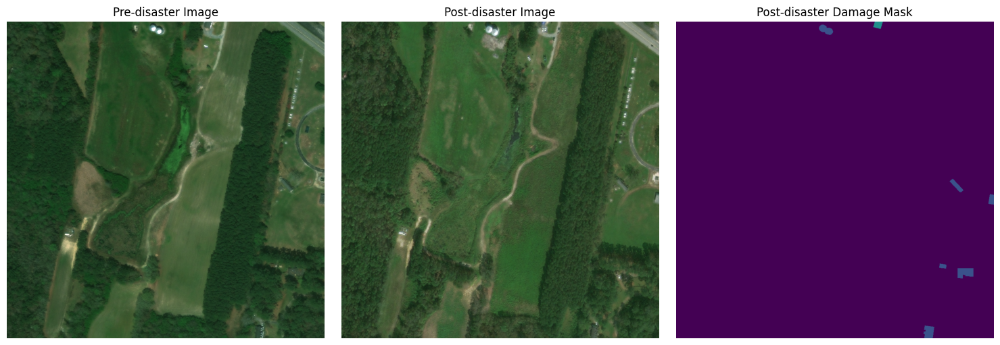

Scene ID: hurricane-florence_00000365
Image shape: (1024, 1024, 3)
Mask shape: (1024, 1024)
Mask labels: [0 1 2]


In [7]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

sample = train_df.iloc[0]

pre = np.array(Image.open(sample["pre_image"]).convert("RGB"))
post = np.array(Image.open(sample["post_image"]).convert("RGB"))
mask = np.array(Image.open(sample["post_mask"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(pre)
axes[0].set_title("Pre-disaster Image")

axes[1].imshow(post)
axes[1].set_title("Post-disaster Image")

axes[2].imshow(mask, cmap="viridis", vmin=0, vmax=4)
axes[2].set_title("Post-disaster Damage Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Scene ID:", sample["scene_id"])
print("Image shape:", post.shape)
print("Mask shape:", mask.shape)
print("Mask labels:", np.unique(mask))

Pre image: (256, 256, 3)
Post image: (256, 256, 3)
Mask: (256, 256)
Mask labels after resizing: [0 1 2]
Mask dtype: uint8


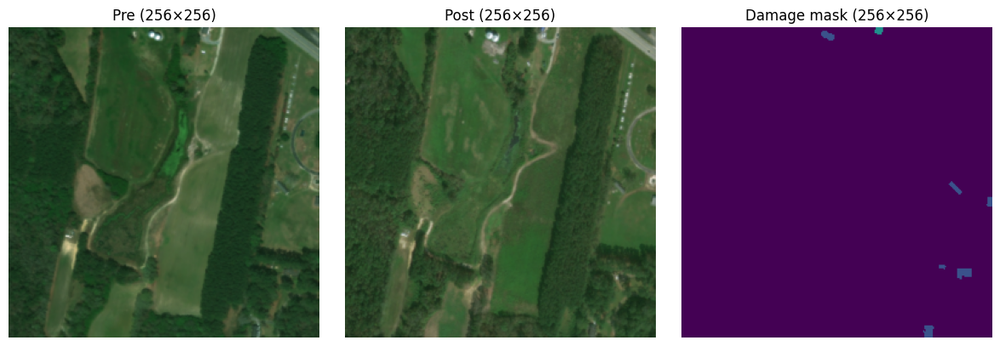

In [8]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

sample = train_df.iloc[0]

pre = Image.open(sample["pre_image"]).convert("RGB")
post = Image.open(sample["post_image"]).convert("RGB")
mask = Image.open(sample["post_mask"])

SIZE = (256, 256)

pre_small = np.array(
    pre.resize(SIZE, Image.Resampling.BILINEAR)
)
post_small = np.array(
    post.resize(SIZE, Image.Resampling.BILINEAR)
)
mask_small = np.array(
    mask.resize(SIZE, Image.Resampling.NEAREST)
)

print("Pre image:", pre_small.shape)
print("Post image:", post_small.shape)
print("Mask:", mask_small.shape)
print("Mask labels after resizing:", np.unique(mask_small))
print("Mask dtype:", mask_small.dtype)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(pre_small)
plt.title("Pre (256×256)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(post_small)
plt.title("Post (256×256)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mask_small, cmap="viridis", vmin=0, vmax=4)
plt.title("Damage mask (256×256)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
import numpy as np

original_mask = np.array(
    Image.open(sample["post_mask"])
)

resized_mask = mask_small

print("Damage pixels before resizing:")
for label in [1, 2, 3, 4]:
    print(f"Class {label}: {np.sum(original_mask == label):,}")

print("\nDamage pixels after resizing:")
for label in [1, 2, 3, 4]:
    print(f"Class {label}: {np.sum(resized_mask == label):,}")

Damage pixels before resizing:
Class 1: 4,968
Class 2: 596
Class 3: 0
Class 4: 0

Damage pixels after resizing:
Class 1: 314
Class 2: 36
Class 3: 0
Class 4: 0


In [10]:
import numpy as np
from PIL import Image

original_mask = np.array(Image.open(sample["post_mask"]))

patch_size = 256

print("Damage classes present in each 256×256 patch:\n")

for row in range(4):
    for col in range(4):
        patch = original_mask[
            row * patch_size:(row + 1) * patch_size,
            col * patch_size:(col + 1) * patch_size
        ]

        classes = np.unique(patch)
        damage_classes = classes[classes > 0]

        print(
            f"Patch ({row}, {col}): "
            f"{damage_classes.tolist()}"
        )

Damage classes present in each 256×256 patch:

Patch (0, 0): []
Patch (0, 1): [1]
Patch (0, 2): [2]
Patch (0, 3): []
Patch (1, 0): []
Patch (1, 1): []
Patch (1, 2): []
Patch (1, 3): [1]
Patch (2, 0): []
Patch (2, 1): []
Patch (2, 2): []
Patch (2, 3): [1]
Patch (3, 0): []
Patch (3, 1): []
Patch (3, 2): []
Patch (3, 3): [1]


In [11]:
from collections import Counter
import numpy as np
from PIL import Image

scene_counts = Counter()
patch_counts = Counter()

PATCH_SIZE = 256

for _, row in train_df.iterrows():
    mask = np.array(Image.open(row["post_mask"]))
    present = set(np.unique(mask).tolist())

    for label in [1, 2, 3, 4]:
        if label in present:
            scene_counts[label] += 1

    for y in range(0, 1024, PATCH_SIZE):
        for x in range(0, 1024, PATCH_SIZE):
            patch = mask[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            labels = set(np.unique(patch).tolist())

            for label in [1, 2, 3, 4]:
                if label in labels:
                    patch_counts[label] += 1

class_names = {
    1: "No damage",
    2: "Minor damage",
    3: "Major damage",
    4: "Destroyed"
}

print("Scenes containing each class:")
for label, name in class_names.items():
    print(f"{name}: {scene_counts[label]:,} scenes")

print("\n256×256 patches containing each class:")
for label, name in class_names.items():
    print(f"{name}: {patch_counts[label]:,} patches")

Scenes containing each class:
No damage: 1,207 scenes
Minor damage: 594 scenes
Major damage: 647 scenes
Destroyed: 631 scenes

256×256 patches containing each class:
No damage: 10,117 patches
Minor damage: 3,242 patches
Major damage: 3,073 patches
Destroyed: 2,772 patches


In [12]:
from PIL import Image
import numpy as np

PATCH_SIZE = 256
sample = train_df.iloc[0]

pre = np.array(Image.open(sample["pre_image"]).convert("RGB"))
post = np.array(Image.open(sample["post_image"]).convert("RGB"))
mask = np.array(Image.open(sample["post_mask"]))

patches = []

for row in range(4):
    for col in range(4):
        y = row * PATCH_SIZE
        x = col * PATCH_SIZE

        pre_patch = pre[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
        post_patch = post[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
        mask_patch = mask[y:y+PATCH_SIZE, x:x+PATCH_SIZE]

        patches.append((pre_patch, post_patch, mask_patch))

print("Scene:", sample["scene_id"])
print("Total paired patches:", len(patches))

for i, (pre_p, post_p, mask_p) in enumerate(patches[:3]):
    print(
        f"Patch {i}: pre={pre_p.shape}, "
        f"post={post_p.shape}, mask={mask_p.shape}, "
        f"labels={np.unique(mask_p).tolist()}"
    )

Scene: hurricane-florence_00000365
Total paired patches: 16
Patch 0: pre=(256, 256, 3), post=(256, 256, 3), mask=(256, 256), labels=[0]
Patch 1: pre=(256, 256, 3), post=(256, 256, 3), mask=(256, 256), labels=[0, 1]
Patch 2: pre=(256, 256, 3), post=(256, 256, 3), mask=(256, 256), labels=[0, 2]


In [13]:
import torch
from torch.utils.data import Dataset
from PIL import Image
import numpy as np

class XBDPatchDataset(Dataset):
    def __init__(self, dataframe, patch_size=256):
        self.df = dataframe.reset_index(drop=True)
        self.patch_size = patch_size
        self.samples = []

        for idx, row in self.df.iterrows():
            mask = np.array(Image.open(row["post_mask"]))

            for y in range(0, 1024, patch_size):
                for x in range(0, 1024, patch_size):
                    patch_mask = mask[
                        y:y+patch_size,
                        x:x+patch_size
                    ]

                    # Keep patches containing at least one
                    # labeled building pixel.
                    if np.any(patch_mask > 0):
                        self.samples.append((idx, y, x))

        print(
            f"Scenes: {len(self.df)}, "
            f"usable patches: {len(self.samples)}"
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        scene_idx, y, x = self.samples[index]
        row = self.df.iloc[scene_idx]

        pre = np.array(
            Image.open(row["pre_image"]).convert("RGB")
        )
        post = np.array(
            Image.open(row["post_image"]).convert("RGB")
        )
        mask = np.array(Image.open(row["post_mask"]))

        size = self.patch_size

        pre = pre[y:y+size, x:x+size]
        post = post[y:y+size, x:x+size]
        mask = mask[y:y+size, x:x+size]

        # Convert images from HWC [0,255] to CHW [0,1].
        pre = torch.from_numpy(pre.copy()).permute(2, 0, 1).float() / 255.0
        post = torch.from_numpy(post.copy()).permute(2, 0, 1).float() / 255.0
        mask = torch.from_numpy(mask.copy()).long()

        return pre, post, mask


train_dataset = XBDPatchDataset(train_df)

Scenes: 1959, usable patches: 13992


In [14]:
from torch.utils.data import DataLoader

BATCH_SIZE = 4  # Conservative starting point

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

pre_batch, post_batch, mask_batch = next(iter(train_loader))

print("Pre batch:", pre_batch.shape)
print("Post batch:", post_batch.shape)
print("Mask batch:", mask_batch.shape)
print("Mask dtype:", mask_batch.dtype)
print("Mask labels in batch:", torch.unique(mask_batch).tolist())

Pre batch: torch.Size([4, 3, 256, 256])
Post batch: torch.Size([4, 3, 256, 256])
Mask batch: torch.Size([4, 256, 256])
Mask dtype: torch.int64
Mask labels in batch: [0, 1, 3, 4]


In [15]:
val_df = df[df["split"] == "val"].reset_index(drop=True)

val_dataset = XBDPatchDataset(val_df)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

pre_val, post_val, mask_val = next(iter(val_loader))

print("Validation scenes:", len(val_df))
print("Validation patches:", len(val_dataset))
print("Pre batch:", pre_val.shape)
print("Post batch:", post_val.shape)
print("Mask batch:", mask_val.shape)
print("Validation labels:", torch.unique(mask_val).tolist())

Scenes: 420, usable patches: 2907
Validation scenes: 420
Validation patches: 2907
Pre batch: torch.Size([4, 3, 256, 256])
Post batch: torch.Size([4, 3, 256, 256])
Mask batch: torch.Size([4, 256, 256])
Validation labels: [0, 1, 2]


In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class SiameseUNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        # Shared encoder for pre- and post-disaster images
        self.enc1 = ConvBlock(3, 16)
        self.enc2 = ConvBlock(16, 32)
        self.enc3 = ConvBlock(32, 64)

        self.pool = nn.MaxPool2d(2)

        # Fuse pre/post features at each scale
        self.fuse1 = ConvBlock(16 * 2, 16)
        self.fuse2 = ConvBlock(32 * 2, 32)
        self.fuse3 = ConvBlock(64 * 2, 64)

        self.bottleneck = ConvBlock(64 * 2, 128)

        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec3 = ConvBlock(64 + 64, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = ConvBlock(32 + 32, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = ConvBlock(16 + 16, 16)

        self.output = nn.Conv2d(16, num_classes, kernel_size=1)

    def forward(self, pre, post):
        # Shared encoder
        pre1 = self.enc1(pre)
        post1 = self.enc1(post)

        pre2 = self.enc2(self.pool(pre1))
        post2 = self.enc2(self.pool(post1))

        pre3 = self.enc3(self.pool(pre2))
        post3 = self.enc3(self.pool(post2))

        # Feature fusion
        f1 = self.fuse1(torch.cat([pre1, post1], dim=1))
        f2 = self.fuse2(torch.cat([pre2, post2], dim=1))
        f3 = self.fuse3(torch.cat([pre3, post3], dim=1))

        # Deep representation
        b = self.bottleneck(
            torch.cat([
                self.pool(pre3),
                self.pool(post3)
            ], dim=1)
        )

        # Decoder with skip connections
        d3 = self.dec3(torch.cat([self.up3(b), f3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), f2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), f1], dim=1))

        return self.output(d1)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SiameseUNet(num_classes=5).to(device)

print("Device:", device)
print("Model parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Device: cpu
Model parameters: 703,061


In [17]:
model.eval()

with torch.no_grad():
    pre_test = pre_batch.to(device)
    post_test = post_batch.to(device)

    predictions = model(pre_test, post_test)

print("Prediction shape:", predictions.shape)
print("Expected shape:   ", (4, 5, 256, 256))
print("Output finite:", torch.isfinite(predictions).all().item())

Prediction shape: torch.Size([4, 5, 256, 256])
Expected shape:    (4, 5, 256, 256)
Output finite: True


In [18]:
import torch
import torch.nn as nn
import torch.optim as optim

# Class order: 0=background, 1=no damage,
#              2=minor, 3=major, 4=destroyed
class_weights = torch.tensor(
    [0.15, 1.0, 3.0, 3.0, 3.0],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Class weights:", class_weights.tolist())

Loss function: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 0.001
Class weights: [0.15000000596046448, 1.0, 3.0, 3.0, 3.0]


In [19]:
model.train()

pre_batch, post_batch, mask_batch = next(iter(train_loader))

pre_batch = pre_batch.to(device)
post_batch = post_batch.to(device)
mask_batch = mask_batch.to(device)

optimizer.zero_grad()

outputs = model(pre_batch, post_batch)
loss = criterion(outputs, mask_batch)

loss.backward()
optimizer.step()

print("Training batch loss:", round(loss.item(), 4))
print("Loss is finite:", torch.isfinite(loss).item())
print("Gradient exists:", model.output.weight.grad is not None)

Training batch loss: 1.8704
Loss is finite: True
Gradient exists: True


In [20]:
# import os
# import torch
# from tqdm.auto import tqdm

# EPOCHS = 1
# best_val_loss = float("inf")

# checkpoint_dir = "/content/drive/MyDrive/T229/checkpoints"
# os.makedirs(checkpoint_dir, exist_ok=True)

# for epoch in range(EPOCHS):
#     model.train()
#     train_loss = 0.0

#     for pre, post, masks in tqdm(train_loader, desc="Training"):
#         pre = pre.to(device)
#         post = post.to(device)
#         masks = masks.to(device)

#         optimizer.zero_grad()
#         outputs = model(pre, post)
#         loss = criterion(outputs, masks)
#         loss.backward()
#         optimizer.step()

#         train_loss += loss.item()

#     train_loss /= len(train_loader)

#     model.eval()
#     val_loss = 0.0

#     with torch.no_grad():
#         for pre, post, masks in tqdm(val_loader, desc="Validation"):
#             pre = pre.to(device)
#             post = post.to(device)
#             masks = masks.to(device)

#             outputs = model(pre, post)
#             loss = criterion(outputs, masks)
#             val_loss += loss.item()

#     val_loss /= len(val_loader)

#     print(f"\nEpoch {epoch + 1}/{EPOCHS}")
#     print(f"Train loss: {train_loss:.4f}")
#     print(f"Validation loss: {val_loss:.4f}")

#     if val_loss < best_val_loss:
#         best_val_loss = val_loss

#         torch.save(
#             {
#                 "epoch": epoch + 1,
#                 "model_state_dict": model.state_dict(),
#                 "optimizer_state_dict": optimizer.state_dict(),
#                 "val_loss": val_loss,
#             },
#             os.path.join(checkpoint_dir, "siamese_unet_best.pth"),
#         )

#         print("Best checkpoint saved.")

In [21]:
from collections import Counter

train_patch_counts = Counter()
for _, y, x in train_dataset.samples:
    row = train_dataset.df.iloc[_]
    mask = np.array(Image.open(row["post_mask"]))
    patch = mask[y:y+256, x:x+256]
    train_patch_counts["background_only" if np.all(patch == 0) else "contains_labels"] += 1

print(train_patch_counts)

Counter({'contains_labels': 13992})


In [22]:
import numpy as np
from PIL import Image
from torch.utils.data import Dataset
import random

class XBDPatchDatasetBalanced(Dataset):
    def __init__(self, dataframe, patch_size=256,
                 background_per_scene=2, seed=42):
        self.df = dataframe.reset_index(drop=True)
        self.patch_size = patch_size
        self.samples = []
        rng = random.Random(seed)

        for scene_idx, row in self.df.iterrows():
            mask = np.array(Image.open(row["post_mask"]))
            labeled_patches = []
            background_patches = []

            for y in range(0, 1024, patch_size):
                for x in range(0, 1024, patch_size):
                    patch = mask[y:y+patch_size, x:x+patch_size]

                    if np.any(patch > 0):
                        labeled_patches.append((scene_idx, y, x))
                    else:
                        background_patches.append((scene_idx, y, x))

            self.samples.extend(labeled_patches)
            chosen_background = rng.sample(
                background_patches,
                min(background_per_scene, len(background_patches))
            )
            self.samples.extend(chosen_background)

        rng.shuffle(self.samples)
        print(f"Scenes: {len(self.df)}")
        print(f"Total patches: {len(self.samples)}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        scene_idx, y, x = self.samples[index]
        row = self.df.iloc[scene_idx]
        size = self.patch_size

        pre = np.array(Image.open(row["pre_image"]).convert("RGB"))
        post = np.array(Image.open(row["post_image"]).convert("RGB"))
        mask = np.array(Image.open(row["post_mask"]))

        pre = torch.from_numpy(
            pre[y:y+size, x:x+size].copy()
        ).permute(2, 0, 1).float() / 255.0

        post = torch.from_numpy(
            post[y:y+size, x:x+size].copy()
        ).permute(2, 0, 1).float() / 255.0

        mask = torch.from_numpy(
            mask[y:y+size, x:x+size].copy()
        ).long()

        return pre, post, mask

print("Balanced dataset class defined successfully.")

Balanced dataset class defined successfully.


In [23]:
train_dataset_balanced = XBDPatchDatasetBalanced(
    train_df,
    background_per_scene=2,
    seed=42
)

val_dataset_balanced = XBDPatchDatasetBalanced(
    val_df,
    background_per_scene=2,
    seed=42
)

Scenes: 1959
Total patches: 17269
Scenes: 420
Total patches: 3613


In [24]:
from torch.utils.data import DataLoader

train_loader_balanced = DataLoader(
    train_dataset_balanced,
    batch_size=4,
    shuffle=True,
    num_workers=0
)

val_loader_balanced = DataLoader(
    val_dataset_balanced,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader_balanced))
print("Validation batches:", len(val_loader_balanced))

Training batches: 4318
Validation batches: 904


In [25]:
pre, post, masks = next(iter(train_loader_balanced))

print("Pre-image shape:", pre.shape)
print("Post-image shape:", post.shape)
print("Mask shape:", masks.shape)
print("Mask labels:", torch.unique(masks).tolist())
print("Background pixels:", (masks == 0).sum().item())
print("Damage/building pixels:", (masks > 0).sum().item())

Pre-image shape: torch.Size([4, 3, 256, 256])
Post-image shape: torch.Size([4, 3, 256, 256])
Mask shape: torch.Size([4, 256, 256])
Mask labels: [0, 1, 2, 4]
Background pixels: 239811
Damage/building pixels: 22333


In [26]:
from collections import Counter
import numpy as np
from PIL import Image

pixel_counts = Counter()

for row in train_df.itertuples(index=False):
    mask = np.array(Image.open(row.post_mask))
    values, counts = np.unique(mask, return_counts=True)
    pixel_counts.update(dict(zip(values.tolist(), counts.tolist())))

print("Training mask pixel counts:")
for label in range(5):
    print(f"Class {label}: {pixel_counts[label]:,} pixels")

Training mask pixel counts:
Class 0: 1,933,794,194 pixels
Class 1: 87,138,176 pixels
Class 2: 11,723,637 pixels
Class 3: 14,111,965 pixels
Class 4: 7,392,412 pixels


In [27]:
print("Current class weights:")
for label, weight in enumerate(class_weights.cpu().tolist()):
    names = ["Background", "No damage", "Minor damage",
             "Major damage", "Destroyed"]
    print(f"{label} - {names[label]}: {weight}")

Current class weights:
0 - Background: 0.15000000596046448
1 - No damage: 1.0
2 - Minor damage: 3.0
3 - Major damage: 3.0
4 - Destroyed: 3.0


In [28]:
class_weights = torch.tensor(
    [0.15, 1.0, 4.0, 4.0, 4.0],
    dtype=torch.float32,
    device=device
)

criterion = torch.nn.CrossEntropyLoss(weight=class_weights)

print("Updated class weights:", class_weights.tolist())
print("Loss function ready.")

Updated class weights: [0.15000000596046448, 1.0, 4.0, 4.0, 4.0]
Loss function ready.


In [29]:
import time
import torch

model.train()
batch_losses = []
start_time = time.time()

for step, (pre, post, masks) in enumerate(train_loader_balanced):
    if step >= 20:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()
    outputs = model(pre, post)
    loss = criterion(outputs, masks)
    loss.backward()
    optimizer.step()

    batch_losses.append(loss.item())

print(f"Batches completed: {len(batch_losses)}")
print(f"Average loss: {sum(batch_losses) / len(batch_losses):.4f}")
print(f"Elapsed time: {(time.time() - start_time) / 60:.2f} minutes")
print(f"Loss finite: {all(torch.isfinite(torch.tensor(batch_losses)))}")

Batches completed: 20
Average loss: 1.6192
Elapsed time: 1.35 minutes
Loss finite: True


In [30]:
import torch

model.eval()
num_classes = 5
confusion = torch.zeros(
    num_classes, num_classes, dtype=torch.int64
)

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_balanced):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        predictions = model(pre, post).argmax(dim=1)

        valid = (masks >= 0) & (masks < num_classes)
        indices = num_classes * masks[valid] + predictions[valid]

        confusion += torch.bincount(
            indices.cpu(),
            minlength=num_classes**2
        ).reshape(num_classes, num_classes)

for c, name in enumerate([
    "Background", "No damage", "Minor damage",
    "Major damage", "Destroyed"
]):
    tp = confusion[c, c].item()
    fp = confusion[:, c].sum().item() - tp
    fn = confusion[c, :].sum().item() - tp

    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0

    print(f"{name}: IoU={iou:.4f}, F1={f1:.4f}")

Background: IoU=0.1297, F1=0.2296
No damage: IoU=0.0431, F1=0.0827
Minor damage: IoU=0.0000, F1=0.0000
Major damage: IoU=0.0100, F1=0.0198
Destroyed: IoU=0.0000, F1=0.0000


In [31]:
model.eval()
prediction_counts = torch.zeros(5, dtype=torch.long)
actual_counts = torch.zeros(5, dtype=torch.long)

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_balanced):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        preds = model(pre, post).argmax(dim=1)

        prediction_counts += torch.bincount(
            preds.cpu().flatten(), minlength=5
        )
        actual_counts += torch.bincount(
            masks.cpu().flatten(), minlength=5
        )

names = ["Background", "No damage", "Minor", "Major", "Destroyed"]

for i, name in enumerate(names):
    print(
        f"{name}: predicted={prediction_counts[i].item():,}, "
        f"actual={actual_counts[i].item():,}"
    )

Background: predicted=318,339, actual=2,390,583
No damage: predicted=176,155, actual=186,195
Minor: predicted=0, actual=17,359
Major: predicted=2,126,946, actual=24,762
Destroyed: predicted=0, actual=2,541


In [32]:
print("Model output classes:", model.output.out_channels)
print("Loss function:", criterion)
print("Class weights:", criterion.weight.detach().cpu().tolist())

pre, post, masks = next(iter(train_loader_balanced))

print("Mask dtype:", masks.dtype)
print("Mask min:", masks.min().item())
print("Mask max:", masks.max().item())
print("Labels in this batch:", torch.unique(masks).tolist())

Model output classes: 5
Loss function: CrossEntropyLoss()
Class weights: [0.15000000596046448, 1.0, 4.0, 4.0, 4.0]
Mask dtype: torch.int64
Mask min: 0
Mask max: 1
Labels in this batch: [0, 1]


In [33]:
from collections import Counter
import numpy as np
from PIL import Image

patch_class_counts = Counter()

for scene_idx, y, x in train_dataset_balanced.samples:
    mask_path = train_dataset_balanced.df.iloc[scene_idx]["post_mask"]
    mask = np.array(Image.open(mask_path))
    patch = mask[y:y+256, x:x+256]

    for label in np.unique(patch):
        patch_class_counts[int(label)] += 1

class_names = [
    "Background", "No damage", "Minor damage",
    "Major damage", "Destroyed"
]

for label, name in enumerate(class_names):
    print(f"{name}: present in {patch_class_counts[label]:,} patches")

Background: present in 17,268 patches
No damage: present in 10,117 patches
Minor damage: present in 3,242 patches
Major damage: present in 3,073 patches
Destroyed: present in 2,772 patches


In [34]:
import torch

model.eval()
probability_sum = torch.zeros(5, dtype=torch.float64)
pixel_count = 0

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_balanced):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)

        probabilities = torch.softmax(model(pre, post), dim=1)
        probability_sum += probabilities.sum(dim=(0, 2, 3)).cpu().double()
        pixel_count += probabilities.shape[0] * probabilities.shape[2] * probabilities.shape[3]

names = ["Background", "No damage", "Minor", "Major", "Destroyed"]

for name, value in zip(names, probability_sum / pixel_count):
    print(f"{name}: mean predicted probability = {value.item():.4f}")

Background: mean predicted probability = 0.1957
No damage: mean predicted probability = 0.1874
Minor: mean predicted probability = 0.1576
Major: mean predicted probability = 0.2618
Destroyed: mean predicted probability = 0.1975


In [35]:
import os
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_balanced_20steps.pth"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "class_weights": class_weights.cpu(),
        "training_updates": 20,
    },
    checkpoint_path,
)

print("Checkpoint saved:", checkpoint_path)

Checkpoint saved: /content/drive/MyDrive/T229/checkpoints/siamese_unet_balanced_20steps.pth


In [36]:
from collections import OrderedDict
from PIL import Image
import numpy as np

class SceneCache:
    def __init__(self, max_scenes=4):
        self.max_scenes = max_scenes
        self.cache = OrderedDict()

    def get(self, row):
        scene_id = row["scene_id"]

        if scene_id in self.cache:
            self.cache.move_to_end(scene_id)
            return self.cache[scene_id]

        data = (
            np.array(Image.open(row["pre_image"]).convert("RGB")),
            np.array(Image.open(row["post_image"]).convert("RGB")),
            np.array(Image.open(row["post_mask"]))
        )

        self.cache[scene_id] = data

        if len(self.cache) > self.max_scenes:
            self.cache.popitem(last=False)

        return data

scene_cache = SceneCache(max_scenes=4)

print("Scene cache initialized.")
print("Maximum cached scenes:", scene_cache.max_scenes)

Scene cache initialized.
Maximum cached scenes: 4


In [37]:
import torch
from torch.utils.data import Dataset, DataLoader

class CachedXBDPatchDataset(Dataset):
    def __init__(self, base_dataset, cache_size=4):
        self.base = base_dataset
        self.cache = SceneCache(max_scenes=cache_size)

    def __len__(self):
        return len(self.base.samples)

    def __getitem__(self, index):
        scene_idx, y, x = self.base.samples[index]
        row = self.base.df.iloc[scene_idx]

        pre_img, post_img, full_mask = self.cache.get(row)
        size = self.base.patch_size

        pre = torch.from_numpy(
            pre_img[y:y+size, x:x+size].copy()
        ).permute(2, 0, 1).float() / 255.0

        post = torch.from_numpy(
            post_img[y:y+size, x:x+size].copy()
        ).permute(2, 0, 1).float() / 255.0

        mask = torch.from_numpy(
            full_mask[y:y+size, x:x+size].copy()
        ).long()

        return pre, post, mask

train_dataset_cached = CachedXBDPatchDataset(train_dataset_balanced)
val_dataset_cached = CachedXBDPatchDataset(val_dataset_balanced)

train_loader_cached = DataLoader(
    train_dataset_cached, batch_size=4, shuffle=True, num_workers=0
)
val_loader_cached = DataLoader(
    val_dataset_cached, batch_size=4, shuffle=False, num_workers=0
)

print("Cached training batches:", len(train_loader_cached))
print("Cached validation batches:", len(val_loader_cached))

Cached training batches: 4318
Cached validation batches: 904


In [38]:
import time

start = time.time()

for step, batch in enumerate(train_loader_cached):
    if step >= 20:
        break

elapsed = time.time() - start

print("Batches tested:", min(20, len(train_loader_cached)))
print(f"Time for 20 batches: {elapsed:.2f} seconds")
print(f"Average seconds per batch: {elapsed / min(20, len(train_loader_cached)):.2f}")

Batches tested: 20
Time for 20 batches: 10.94 seconds
Average seconds per batch: 0.55


In [39]:
import time
import torch

model.train()
losses = []
start = time.time()

for step, (pre, post, masks) in enumerate(train_loader_cached):
    if step >= 20:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()
    outputs = model(pre, post)
    loss = criterion(outputs, masks)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

print("Batches completed:", len(losses))
print(f"Average loss: {sum(losses) / len(losses):.4f}")
print(f"Elapsed time: {(time.time() - start) / 60:.2f} minutes")
print("All losses finite:", all(torch.isfinite(torch.tensor(losses))))

Batches completed: 20
Average loss: 1.4928
Elapsed time: 1.44 minutes
All losses finite: True


In [40]:
import os
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_cached_40steps.pth"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "class_weights": class_weights.cpu(),
        "training_updates": 40,
    },
    checkpoint_path,
)

print("Checkpoint saved:", checkpoint_path)

Checkpoint saved: /content/drive/MyDrive/T229/checkpoints/siamese_unet_cached_40steps.pth


In [41]:
import torch

model.eval()
num_classes = 5
confusion = torch.zeros(num_classes, num_classes, dtype=torch.int64)

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        preds = model(pre, post).argmax(dim=1)
        indices = num_classes * masks.reshape(-1) + preds.reshape(-1)

        confusion += torch.bincount(
            indices.cpu(), minlength=num_classes**2
        ).reshape(num_classes, num_classes)

names = ["Background", "No damage", "Minor", "Major", "Destroyed"]

for c, name in enumerate(names):
    tp = confusion[c, c].item()
    fp = confusion[:, c].sum().item() - tp
    fn = confusion[c, :].sum().item() - tp

    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0

    print(f"{name}: IoU={iou:.4f}, F1={f1:.4f}")

Background: IoU=0.5408, F1=0.7020
No damage: IoU=0.1551, F1=0.2685
Minor: IoU=0.0077, F1=0.0153
Major: IoU=0.0187, F1=0.0368
Destroyed: IoU=0.0000, F1=0.0000


In [42]:
import torch

model.eval()
pred_counts = torch.zeros(5, dtype=torch.long)
actual_counts = torch.zeros(5, dtype=torch.long)

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        preds = model(pre.to(device), post.to(device)).argmax(dim=1)

        pred_counts += torch.bincount(
            preds.cpu().flatten(), minlength=5
        )
        actual_counts += torch.bincount(
            masks.flatten(), minlength=5
        )

names = ["Background", "No damage", "Minor", "Major", "Destroyed"]

for i, name in enumerate(names):
    print(
        f"{name}: predicted={pred_counts[i].item():,}, "
        f"actual={actual_counts[i].item():,}"
    )

Background: predicted=1,353,598, actual=2,390,583
No damage: predicted=633,715, actual=186,195
Minor: predicted=62,257, actual=17,359
Major: predicted=571,674, actual=24,762
Destroyed: predicted=196, actual=2,541


In [43]:
import numpy as np
import pandas as pd

confusion_df = pd.DataFrame(
    confusion.numpy(),
    index=["Actual background", "Actual no damage", "Actual minor",
           "Actual major", "Actual destroyed"],
    columns=["Pred background", "Pred no damage", "Pred minor",
             "Pred major", "Pred destroyed"]
)

display(confusion_df)

,Pred background,Pred no damage,Pred minor,Pred major,Pred destroyed
Actual background,1314228,508983,49884,517365,123
Actual no damage,29995,110083,11239,34805,73
Actual minor,2518,6230,608,8003,0
Actual major,6369,7209,216,10968,0
Actual destroyed,488,1210,310,533,0


In [44]:
import torch

for pre, post, masks in train_loader_cached:
    counts = torch.bincount(masks.flatten(), minlength=5)

    if counts[2].item() > 0:
        print("Found a batch containing Minor damage.")
        print("Pixel counts by class:", counts.tolist())
        break

Found a batch containing Minor damage.
Pixel counts by class: [253976, 7363, 805, 0, 0]


In [45]:
import torch
import torch.nn.functional as F

model.eval()

for pre, post, masks in train_loader_cached:
    if (masks == 2).any():
        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)
        break

with torch.no_grad():
    logits = model(pre, post)
    pixel_losses = F.cross_entropy(logits, masks, reduction="none")

print("Per-class average loss:")
for label, name in enumerate([
    "Background", "No damage", "Minor", "Major", "Destroyed"
]):
    selected = masks == label
    if selected.any():
        print(
            f"{name}: {pixel_losses[selected].mean().item():.4f} "
            f"({selected.sum().item():,} pixels)"
        )
    else:
        print(f"{name}: no pixels in this batch")

Per-class average loss:
Background: 2.2536 (241,449 pixels)
No damage: 1.8962 (4,627 pixels)
Minor: 1.9267 (98 pixels)
Major: 1.6410 (2,646 pixels)
Destroyed: 2.4629 (13,324 pixels)


In [46]:
for i, param_group in enumerate(optimizer.param_groups):
    print(f"Optimizer group {i} learning rate: {param_group['lr']}")

Optimizer group 0 learning rate: 0.001


In [47]:
for param_group in optimizer.param_groups:
    param_group["lr"] = 0.0003

print("Updated learning rate:", optimizer.param_groups[0]["lr"])

Updated learning rate: 0.0003


In [ ]:
import time
import torch

model.train()
running_loss = 0.0
start_time = time.time()

for step, (pre, post, masks) in enumerate(train_loader_cached):
    if step >= 20:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()
    outputs = model(pre, post)
    loss = criterion(outputs, masks)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

print(f"Average loss: {running_loss / 20:.4f}")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")

Average loss: 1.3023
Time taken: 2.40 minutes


In [ ]:
import torch
import numpy as np

model.eval()
num_classes = 5
confusion = torch.zeros(
    num_classes, num_classes, dtype=torch.int64
)

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        preds = model(pre, post).argmax(dim=1)

        for actual, predicted in zip(
            masks.reshape(-1), preds.reshape(-1)
        ):
            confusion[actual.cpu(), predicted.cpu()] += 1

print("Confusion matrix (rows=actual, columns=predicted):")
print(confusion.numpy())

for c in range(num_classes):
    tp = confusion[c, c].item()
    fp = confusion[:, c].sum().item() - tp
    fn = confusion[c, :].sum().item() - tp

    iou = tp / (tp + fp + fn) if tp + fp + fn else 0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0

    print(f"Class {c}: IoU={iou:.4f}, F1={f1:.4f}")

print("\nPredicted pixel counts:", confusion.sum(dim=0).tolist())

Confusion matrix (rows=actual, columns=predicted):
[[1444920  945406     123      69      65]
 [  19154  167012      14       9       6]
 [   1232   16127       0       0       0]
 [   4554   20205       3       0       0]
 [    118    2417       0       4       2]]
Class 0: IoU=0.5982, F1=0.7486
Class 1: IoU=0.1427, F1=0.2498
Class 2: IoU=0.0000, F1=0.0000
Class 3: IoU=0.0000, F1=0.0000
Class 4: IoU=0.0008, F1=0.0015

Predicted pixel counts: [1469978, 1151167, 140, 82, 73]


In [ ]:
class_weights = torch.tensor(
    [0.15, 1.0, 8.0, 4.0, 4.0],
    dtype=torch.float32,
    device=device
)

criterion = torch.nn.CrossEntropyLoss(weight=class_weights)

print("Updated class weights:", class_weights.tolist())

Updated class weights: [0.15000000596046448, 1.0, 8.0, 4.0, 4.0]


In [ ]:
import time
import torch

model.train()
running_loss = 0.0
start_time = time.time()

for step, (pre, post, masks) in enumerate(train_loader_cached):
    if step >= 20:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()
    outputs = model(pre, post)
    loss = criterion(outputs, masks)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

print(f"Average loss: {running_loss / 20:.4f}")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")

Average loss: 1.1771
Time taken: 2.14 minutes


In [ ]:
import torch

model.eval()
num_classes = 5
confusion = torch.zeros(num_classes, num_classes, dtype=torch.int64)

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        preds = model(pre, post).argmax(dim=1)

        for actual, predicted in zip(masks.reshape(-1), preds.reshape(-1)):
            confusion[actual.cpu(), predicted.cpu()] += 1

print("Confusion matrix (rows=actual, columns=predicted):")
print(confusion.numpy())

for c in range(num_classes):
    tp = confusion[c, c].item()
    fp = confusion[:, c].sum().item() - tp
    fn = confusion[c, :].sum().item() - tp

    iou = tp / (tp + fp + fn) if tp + fp + fn else 0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0

    print(f"Class {c}: IoU={iou:.4f}, F1={f1:.4f}")

print("\nPredicted pixel counts:", confusion.sum(dim=0).tolist())

Confusion matrix (rows=actual, columns=predicted):
[[1645134  745407       0      15      27]
 [  29892  156297       0       3       3]
 [   4132   13227       0       0       0]
 [   8967   15795       0       0       0]
 [    229    2310       0       2       0]]
Class 0: IoU=0.6760, F1=0.8066
Class 1: IoU=0.1623, F1=0.2793
Class 2: IoU=0.0000, F1=0.0000
Class 3: IoU=0.0000, F1=0.0000
Class 4: IoU=0.0000, F1=0.0000

Predicted pixel counts: [1688354, 933036, 0, 20, 30]


In [ ]:
class_weights = torch.tensor(
    [0.15, 1.0, 4.0, 4.0, 4.0],
    dtype=torch.float32,
    device=device
)

criterion = torch.nn.CrossEntropyLoss(weight=class_weights)

print("Restored class weights:", class_weights.tolist())
print("Current learning rate:", optimizer.param_groups[0]["lr"])

Restored class weights: [0.15000000596046448, 1.0, 4.0, 4.0, 4.0]
Current learning rate: 0.0003


In [ ]:
from collections import Counter
import numpy as np
from PIL import Image

patch_class_counts = Counter()

for scene_idx, y, x in train_dataset_balanced.samples:
    row = train_dataset_balanced.df.iloc[scene_idx]
    mask = np.array(Image.open(row["post_mask"]).crop(
        (x, y, x + 256, y + 256)
    ))

    for class_id in (1, 2, 3, 4):
        if np.any(mask == class_id):
            patch_class_counts[class_id] += 1

class_names = {
    1: "No damage",
    2: "Minor damage",
    3: "Major damage",
    4: "Destroyed"
}

print("Training patches containing each damage class:")
for class_id, name in class_names.items():
    print(f"{name}: {patch_class_counts[class_id]}")

Training patches containing each damage class:
No damage: 10117
Minor damage: 3242
Major damage: 3073
Destroyed: 2772


In [ ]:
import torch

model.eval()

pre, post, masks = next(iter(train_loader_cached))
pre = pre.to(device)
post = post.to(device)

with torch.no_grad():
    predictions = model(pre, post).argmax(dim=1)

print("Class       | Actual pixels | Predicted pixels")
print("-" * 48)

names = {
    0: "Background",
    1: "No damage",
    2: "Minor damage",
    3: "Major damage",
    4: "Destroyed"
}

for class_id, name in names.items():
    actual_count = (masks == class_id).sum().item()
    predicted_count = (predictions == class_id).sum().item()
    print(f"{name:12} | {actual_count:13,} | {predicted_count:16,}")

Class       | Actual pixels | Predicted pixels
------------------------------------------------
Background   |       260,613 |          255,019
No damage    |             0 |            7,116
Minor damage |             0 |                0
Major damage |             0 |                0
Destroyed    |         1,531 |                9


In [ ]:
import torch

model.eval()
found = False

with torch.no_grad():
    for batch_idx, (pre, post, masks) in enumerate(train_loader_cached):
        if (masks == 2).any():
            pre = pre.to(device)
            post = post.to(device)

            predictions = model(pre, post).argmax(dim=1)

            print("Batch index:", batch_idx)
            print("Actual minor-damage pixels:", (masks == 2).sum().item())
            print("Predicted minor-damage pixels:", (predictions == 2).sum().item())
            print("Actual major-damage pixels:", (masks == 3).sum().item())
            print("Predicted major-damage pixels:", (predictions == 3).sum().item())

            found = True
            break

if not found:
    print("No minor-damage batch found.")

Batch index: 0
Actual minor-damage pixels: 156
Predicted minor-damage pixels: 0
Actual major-damage pixels: 24481
Predicted major-damage pixels: 0


In [ ]:
import torch

model.eval()

with torch.no_grad():
    for batch_idx, (pre, post, masks) in enumerate(train_loader_cached):
        if (masks == 2).any():
            pre = pre.to(device)
            post = post.to(device)
            masks = masks.to(device)

            logits = model(pre, post)
            probs = torch.softmax(logits, dim=1)

            minor_pixels = masks == 2
            mean_probs = probs[:, :, minor_pixels[0]] if False else None

            # Gather probabilities only at actual minor-damage pixels
            pixel_probs = probs.permute(0, 2, 3, 1)[minor_pixels]

            print("Actual minor-damage pixels:", int(minor_pixels.sum()))
            print("Mean probability at those pixels:")
            for c, name in enumerate([
                "Background", "No damage", "Minor damage",
                "Major damage", "Destroyed"
            ]):
                print(f"{name}: {pixel_probs[:, c].mean().item():.4f}")

            print(
                "Minor damage top prediction count:",
                int((logits.argmax(dim=1)[minor_pixels] == 2).sum())
            )
            break

Actual minor-damage pixels: 382
Mean probability at those pixels:
Background: 0.3131
No damage: 0.2685
Minor damage: 0.1758
Major damage: 0.1280
Destroyed: 0.1146
Minor damage top prediction count: 0


In [ ]:
print("Unique mask values in this batch:",
      torch.unique(masks).cpu().tolist())

print("Model output shape:", logits.shape)
print("Class mapping:")
print({
    0: "Background",
    1: "No damage",
    2: "Minor damage",
    3: "Major damage",
    4: "Destroyed"
})

Unique mask values in this batch: [0, 1, 2]
Model output shape: torch.Size([4, 5, 256, 256])
Class mapping:
{0: 'Background', 1: 'No damage', 2: 'Minor damage', 3: 'Major damage', 4: 'Destroyed'}


In [ ]:
import torch

model.train()

# Reuse the batch currently stored in pre, post, and masks
# Reload it on the correct device.
pre_batch, post_batch, mask_batch = pre, post, masks

pre_batch = pre_batch.to(device)
post_batch = post_batch.to(device)
mask_batch = mask_batch.to(device)

print("Starting loss check:")

for step in range(10):
    optimizer.zero_grad()
    outputs = model(pre_batch, post_batch)
    loss = criterion(outputs, mask_batch)
    loss.backward()
    optimizer.step()

    if step in (0, 4, 9):
        print(f"Update {step + 1}: loss = {loss.item():.4f}")

Starting loss check:
Update 1: loss = 1.0097
Update 5: loss = 0.9797
Update 10: loss = 0.9367


In [ ]:
model.eval()

with torch.no_grad():
    outputs = model(pre_batch, post_batch)
    predictions = outputs.argmax(dim=1)

print("Class           | Actual pixels | Predicted pixels")
print("-" * 52)

names = [
    "Background",
    "No damage",
    "Minor damage",
    "Major damage",
    "Destroyed"
]

for class_id, name in enumerate(names):
    actual_count = (mask_batch == class_id).sum().item()
    predicted_count = (predictions == class_id).sum().item()
    print(f"{name:15} | {actual_count:13,} | {predicted_count:16,}")

Class           | Actual pixels | Predicted pixels
----------------------------------------------------
Background      |       259,220 |          215,314
No damage       |         2,542 |           46,830
Minor damage    |           382 |                0
Major damage    |             0 |                0
Destroyed       |             0 |                0


In [ ]:
from collections import Counter
import numpy as np
from PIL import Image

minor_pixel_counts = []

for scene_idx, y, x in train_dataset_balanced.samples:
    row = train_dataset_balanced.df.iloc[scene_idx]

    with Image.open(row["post_mask"]) as img:
        mask = np.array(img.crop((x, y, x + 256, y + 256)))

    count = int(np.count_nonzero(mask == 2))
    if count > 0:
        minor_pixel_counts.append(count)

print("Patches containing minor damage:", len(minor_pixel_counts))
print("Total minor-damage pixels across these patches:",
      sum(minor_pixel_counts))

for threshold in [1, 50, 100, 500, 1000, 5000]:
    count = sum(n >= threshold for n in minor_pixel_counts)
    print(f"Patches with at least {threshold} minor pixels: {count}")

Patches containing minor damage: 3242
Total minor-damage pixels across these patches: 11723637
Patches with at least 1 minor pixels: 3242
Patches with at least 50 minor pixels: 3172
Patches with at least 100 minor pixels: 3104
Patches with at least 500 minor pixels: 2621
Patches with at least 1000 minor pixels: 2166
Patches with at least 5000 minor pixels: 659


In [ ]:
from torch.utils.data import WeightedRandomSampler

print("Training dataset size:", len(train_dataset_cached))
print("Current sampler:", type(train_loader_cached.sampler).__name__)
print("Batch size:", train_loader_cached.batch_size)
print("Shuffle enabled:", train_loader_cached.sampler.__class__.__name__ == "RandomSampler")

Training dataset size: 17269
Current sampler: RandomSampler
Batch size: 4
Shuffle enabled: True


In [ ]:
import numpy as np
import torch
from PIL import Image
from torch.utils.data import WeightedRandomSampler

sample_weights = []

for scene_idx, y, x in train_dataset_balanced.samples:
    row = train_dataset_balanced.df.iloc[scene_idx]

    with Image.open(row["post_mask"]) as img:
        mask = np.array(img.crop((x, y, x + 256, y + 256)))

    minor_pixels = np.count_nonzero(mask == 2)

    # Give minor-damage patches more sampling probability.
    if minor_pixels >= 1000:
        weight = 4.0
    elif minor_pixels > 0:
        weight = 2.0
    else:
        weight = 1.0

    sample_weights.append(weight)

sample_weights = torch.DoubleTensor(sample_weights)

minor_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

print("Total patches:", len(sample_weights))
print("Patches with weight 4:", (sample_weights == 4).sum().item())
print("Patches with weight 2:", (sample_weights == 2).sum().item())
print("Patches with weight 1:", (sample_weights == 1).sum().item())

Total patches: 17269
Patches with weight 4: 2166
Patches with weight 2: 1076
Patches with weight 1: 14027


In [ ]:
from torch.utils.data import DataLoader

train_loader_weighted = DataLoader(
    train_dataset_cached,
    batch_size=4,
    sampler=minor_sampler,
    num_workers=0
)

print("Weighted training batches:", len(train_loader_weighted))
print("Validation batches:", len(val_loader_cached))
print("Training sampler:", type(train_loader_weighted.sampler).__name__)

Weighted training batches: 4318
Validation batches: 904
Training sampler: WeightedRandomSampler


In [ ]:
import time
import torch

model.train()
running_loss = 0.0
start_time = time.time()

for step, (pre, post, masks) in enumerate(train_loader_weighted):
    if step >= 20:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()
    outputs = model(pre, post)
    loss = criterion(outputs, masks)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

print(f"Average loss: {running_loss / 20:.4f}")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")

Average loss: 1.3284
Time taken: 2.15 minutes


In [ ]:
import torch

model.eval()
num_classes = 5
confusion = torch.zeros(num_classes, num_classes, dtype=torch.int64)

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        preds = model(pre, post).argmax(dim=1)

        for actual, predicted in zip(masks.reshape(-1), preds.reshape(-1)):
            confusion[actual.cpu(), predicted.cpu()] += 1

print("Confusion matrix (rows=actual, columns=predicted):")
print(confusion.numpy())

for c in range(num_classes):
    tp = confusion[c, c].item()
    fp = confusion[:, c].sum().item() - tp
    fn = confusion[c, :].sum().item() - tp

    iou = tp / (tp + fp + fn) if tp + fp + fn else 0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0

    print(f"Class {c}: IoU={iou:.4f}, F1={f1:.4f}")

print("Predicted pixel counts:", confusion.sum(dim=0).tolist())

Confusion matrix (rows=actual, columns=predicted):
[[1727324  663249       0       1       9]
 [  35403  150790       0       1       1]
 [   4399   12960       0       0       0]
 [   5766   18995       0       1       0]
 [    502    2039       0       0       0]]
Class 0: IoU=0.7089, F1=0.8297
Class 1: IoU=0.1707, F1=0.2916
Class 2: IoU=0.0000, F1=0.0000
Class 3: IoU=0.0000, F1=0.0001
Class 4: IoU=0.0000, F1=0.0000
Predicted pixel counts: [1773394, 848033, 0, 3, 10]


In [ ]:
import torch

print("Batch | Minor pixels | Major pixels | Destroyed pixels")

for batch_idx, (_, _, masks) in enumerate(train_loader_weighted):
    counts = [
        int((masks == class_id).sum())
        for class_id in (2, 3, 4)
    ]

    print(
        f"{batch_idx:5} | {counts[0]:12,} | "
        f"{counts[1]:12,} | {counts[2]:16,}"
    )

    if batch_idx == 9:
        break

Batch | Minor pixels | Major pixels | Destroyed pixels
    0 |        1,269 |          387 |              390
    1 |            0 |            0 |                0
    2 |          850 |            0 |                0
    3 |        6,288 |            0 |              814
    4 |        8,013 |       16,246 |            2,512
    5 |        5,263 |        2,101 |            7,785
    6 |            0 |            0 |            6,126
    7 |        1,488 |          319 |               71
    8 |       22,969 |            0 |            1,090
    9 |       10,036 |            0 |                0


In [ ]:
import torch

model.eval()
minor_probs = []
major_probs = []
true_minor_pixels = 0

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        probs = torch.softmax(model(pre, post), dim=1)

        for class_id, storage in [(2, minor_probs), (3, major_probs)]:
            pixels = masks == class_id
            if pixels.any():
                storage.extend(
                    probs[:, class_id][pixels].cpu().tolist()
                )

        true_minor_pixels += int((masks == 2).sum())

print("Actual minor-damage pixels:", true_minor_pixels)

for name, values in [
    ("Minor damage", minor_probs),
    ("Major damage", major_probs),
]:
    if values:
        print(
            f"{name} probability on its actual pixels: "
            f"mean={sum(values)/len(values):.4f}, "
            f"max={max(values):.4f}"
        )
    else:
        print(f"No actual {name.lower()} pixels in the inspected batches.")

Actual minor-damage pixels: 17359
Minor damage probability on its actual pixels: mean=0.2204, max=0.3526
Major damage probability on its actual pixels: mean=0.1112, max=0.2207


In [ ]:
import torch

model.eval()
class_names = [
    "Background", "No damage", "Minor damage",
    "Major damage", "Destroyed"
]

probability_sums = torch.zeros(5, dtype=torch.float64)
top1_counts = torch.zeros(5, dtype=torch.int64)
total_minor_pixels = 0

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        probs = torch.softmax(model(pre, post), dim=1)
        pixels = masks == 2

        if pixels.any():
            minor_pixel_probs = probs.permute(0, 2, 3, 1)[pixels]
            probability_sums += minor_pixel_probs.sum(dim=0).cpu().double()
            top1 = minor_pixel_probs.argmax(dim=1)
            top1_counts += torch.bincount(top1.cpu(), minlength=5)
            total_minor_pixels += int(pixels.sum())

print("Actual minor-damage pixels:", total_minor_pixels)
print("\nMean class probabilities on those pixels:")
for i, name in enumerate(class_names):
    print(f"{name}: {probability_sums[i].item() / total_minor_pixels:.4f}")

print("\nMost likely class counts:")
for i, name in enumerate(class_names):
    print(f"{name}: {top1_counts[i].item()}")

Actual minor-damage pixels: 17359

Mean class probabilities on those pixels:
Background: 0.2246
No damage: 0.3288
Minor damage: 0.2204
Major damage: 0.1184
Destroyed: 0.1078

Most likely class counts:
Background: 4399
No damage: 12960
Minor damage: 0
Major damage: 0
Destroyed: 0


In [ ]:
print("Class weights:", criterion.weight.detach().cpu().tolist())
print("Loss function:", criterion)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Model output classes:", model.output.out_channels)

Class weights: [0.15000000596046448, 1.0, 4.0, 4.0, 4.0]
Loss function: CrossEntropyLoss()
Learning rate: 0.0003
Model output classes: 5


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, class_weights, gamma=2.0):
        super().__init__()
        self.register_buffer("class_weights", class_weights.detach().clone())
        self.gamma = gamma

    def forward(self, logits, targets):
        log_probs = F.log_softmax(logits, dim=1)
        log_pt = log_probs.gather(
            1, targets.unsqueeze(1)
        ).squeeze(1)

        pt = log_pt.exp()
        pixel_loss = -(1 - pt).pow(self.gamma) * log_pt

        weights = self.class_weights[targets]
        return (pixel_loss * weights).sum() / weights.sum().clamp_min(1e-8)

criterion_focal = FocalLoss(class_weights, gamma=2.0).to(device)

print("Focal loss ready:", criterion_focal)
print("Gamma:", criterion_focal.gamma)
print("Class weights:", criterion_focal.class_weights.cpu().tolist())

Focal loss ready: FocalLoss()
Gamma: 2.0
Class weights: [0.15000000596046448, 1.0, 4.0, 4.0, 4.0]


In [ ]:
model.eval()

pre, post, masks = next(iter(train_loader_weighted))
pre = pre.to(device)
post = post.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(pre, post)

    ce_loss = criterion(outputs, masks)
    focal_loss = criterion_focal(outputs, masks)

print(f"Cross-entropy loss: {ce_loss.item():.4f}")
print(f"Focal loss:         {focal_loss.item():.4f}")
print("Minor-damage pixels:", int((masks == 2).sum()))
print("Major-damage pixels:", int((masks == 3).sum()))
print("Destroyed pixels:", int((masks == 4).sum()))

Cross-entropy loss: 1.3008
Focal loss:         0.7584
Minor-damage pixels: 8739
Major-damage pixels: 262
Destroyed pixels: 0


In [ ]:
import time
import torch

model.train()
running_loss = 0.0
start_time = time.time()

for step, (pre, post, masks) in enumerate(train_loader_weighted):
    if step >= 20:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()
    outputs = model(pre, post)
    loss = criterion_focal(outputs, masks)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

print(f"Average focal loss: {running_loss / 20:.4f}")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")

Average focal loss: 0.7565
Time taken: 2.34 minutes


In [ ]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix

model.eval()
all_true = []
all_pred = []

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        outputs = model(pre, post)
        predictions = outputs.argmax(dim=1)

        all_true.extend(masks.cpu().numpy().ravel())
        all_pred.extend(predictions.cpu().numpy().ravel())

labels = [0, 1, 2, 3, 4]
class_names = [
    "Background", "No damage", "Minor damage",
    "Major damage", "Destroyed"
]

cm = confusion_matrix(all_true, all_pred, labels=labels)

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)
print("\nPer-class validation metrics:")

for i, name in enumerate(class_names):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

    print(
        f"{name:15s} | "
        f"IoU: {iou:.4f} | "
        f"F1: {f1:.4f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f}"
    )

Confusion matrix (rows = actual, columns = predicted):
[[1697969  680021   12545      43       5]
 [  23722  159707    2764       2       0]
 [   2192   15058     109       0       0]
 [   4826   19765     169       2       0]
 [    276    2264       1       0       0]]

Per-class validation metrics:
Background      | IoU: 0.7012 | F1: 0.8243 | Precision: 0.9821 | Recall: 0.7103
No damage       | IoU: 0.1768 | F1: 0.3005 | Precision: 0.1821 | Recall: 0.8577
Minor damage    | IoU: 0.0033 | F1: 0.0066 | Precision: 0.0070 | Recall: 0.0063
Major damage    | IoU: 0.0001 | F1: 0.0002 | Precision: 0.0426 | Recall: 0.0001
Destroyed       | IoU: 0.0000 | F1: 0.0000 | Precision: 0.0000 | Recall: 0.0000


In [ ]:
import torch
import numpy as np

model.eval()
actual_counts = np.zeros(5, dtype=np.int64)
pred_counts = np.zeros(5, dtype=np.int64)
probability_sums = np.zeros(5, dtype=np.float64)
class_names = [
    "Background", "No damage", "Minor damage",
    "Major damage", "Destroyed"
]

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        probs = torch.softmax(model(pre, post), dim=1)
        preds = probs.argmax(dim=1)

        for c in range(5):
            actual_counts[c] += (masks == c).sum().item()
            pred_counts[c] += (preds == c).sum().item()

            selected = (masks == c)
            if selected.any():
                probability_sums[c] += probs[:, c][selected].sum().item()

print("Class distribution across the 10 validation batches:")
for c, name in enumerate(class_names):
    mean_prob = (
        probability_sums[c] / actual_counts[c]
        if actual_counts[c] else 0.0
    )
    print(
        f"{name:15s} | actual pixels: {actual_counts[c]:,} "
        f"| predicted pixels: {pred_counts[c]:,} "
        f"| mean probability for its own class on actual pixels: {mean_prob:.4f}"
    )

Class distribution across the 10 validation batches:
Background      | actual pixels: 2,390,583 | predicted pixels: 1,728,985 | mean probability for its own class on actual pixels: 0.3945
No damage       | actual pixels: 186,195 | predicted pixels: 876,815 | mean probability for its own class on actual pixels: 0.3592
Minor damage    | actual pixels: 17,359 | predicted pixels: 15,588 | mean probability for its own class on actual pixels: 0.2548
Major damage    | actual pixels: 24,762 | predicted pixels: 47 | mean probability for its own class on actual pixels: 0.1168
Destroyed       | actual pixels: 2,541 | predicted pixels: 5 | mean probability for its own class on actual pixels: 0.1174


In [ ]:
import torch
import torch.nn.functional as F

model.eval()

with torch.no_grad():
    for pre, post, masks in val_loader_cached:
        rare_pixels = ((masks == 2) | (masks == 3)).sum().item()

        if rare_pixels > 0:
            pre = pre.to(device)
            post = post.to(device)
            masks = masks.to(device)

            logits = model(pre, post)
            probs = torch.softmax(logits, dim=1)
            preds = logits.argmax(dim=1)

            for c, name in [(2, "Minor damage"), (3, "Major damage")]:
                selected = masks == c

                if selected.any():
                    class_probs = probs.permute(0, 2, 3, 1)[selected]
                    class_preds = preds[selected]

                    print(f"\n{name}")
                    print("Actual pixels:", selected.sum().item())
                    print("Correctly predicted:", (class_preds == c).sum().item())
                    print("Mean probability for true class:",
                          f"{class_probs[:, c].mean().item():.4f}")
                    print("Mean probability for no damage:",
                          f"{class_probs[:, 1].mean().item():.4f}")
            break


Minor damage
Actual pixels: 9184
Correctly predicted: 5
Mean probability for true class: 0.2415
Mean probability for no damage: 0.3277

Major damage
Actual pixels: 5394
Correctly predicted: 0
Mean probability for true class: 0.1213
Mean probability for no damage: 0.3298


In [ ]:
print("Current criterion:", type(criterion_focal).__name__)
print("Focal gamma:", criterion_focal.gamma)
print("Class weights:", criterion_focal.class_weights.detach().cpu().tolist())
print("Optimizer:", type(optimizer).__name__)

for group in optimizer.param_groups:
    print("Learning rate:", group["lr"])

Current criterion: FocalLoss
Focal gamma: 2.0
Class weights: [0.15000000596046448, 1.0, 4.0, 4.0, 4.0]
Optimizer: AdamW
Learning rate: 0.0003


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class FocalDiceLoss(nn.Module):
    def __init__(self, class_weights, gamma=2.0, dice_weight=0.5):
        super().__init__()
        self.register_buffer(
            "class_weights", class_weights.detach().clone()
        )
        self.gamma = gamma
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        # Focal loss
        log_probs = F.log_softmax(logits, dim=1)
        log_pt = log_probs.gather(
            1, targets.unsqueeze(1)
        ).squeeze(1)
        pt = log_pt.exp()

        pixel_loss = -(1 - pt).pow(self.gamma) * log_pt
        weights = self.class_weights[targets]
        focal_loss = (
            (pixel_loss * weights).sum()
            / weights.sum().clamp_min(1e-8)
        )

        # Multi-class soft Dice loss; ignore background in Dice term
        probs = torch.softmax(logits, dim=1)
        num_classes = logits.shape[1]
        targets_onehot = F.one_hot(
            targets, num_classes=num_classes
        ).permute(0, 3, 1, 2).float()

        probs_fg = probs[:, 1:]
        targets_fg = targets_onehot[:, 1:]

        dims = (0, 2, 3)
        intersection = (probs_fg * targets_fg).sum(dim=dims)
        denominator = probs_fg.sum(dim=dims) + targets_fg.sum(dim=dims)

        dice_per_class = (
            2 * intersection + 1e-6
        ) / (denominator + 1e-6)

        # Average only over damage classes present in the target batch
        present = targets_fg.sum(dim=dims) > 0
        if present.any():
            dice_loss = 1 - dice_per_class[present].mean()
        else:
            dice_loss = logits.new_tensor(0.0)

        return (
            (1 - self.dice_weight) * focal_loss
            + self.dice_weight * dice_loss
        )

criterion_combined = FocalDiceLoss(
    class_weights=class_weights,
    gamma=2.0,
    dice_weight=0.5
).to(device)

print("Combined Focal + Dice loss created.")
print("Dice contribution:", criterion_combined.dice_weight)

Combined Focal + Dice loss created.
Dice contribution: 0.5


In [ ]:
model.eval()

pre, post, masks = next(iter(train_loader_weighted))
pre = pre.to(device)
post = post.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(pre, post)
    test_loss = criterion_combined(outputs, masks)

print("Combined loss:", round(test_loss.item(), 4))
print("Output shape:", tuple(outputs.shape))
print("Target shape:", tuple(masks.shape))
print("Loss is finite:", bool(torch.isfinite(test_loss).item()))

Combined loss: 0.9015
Output shape: (4, 5, 256, 256)
Target shape: (4, 256, 256)
Loss is finite: True


In [ ]:
import time
import torch

model.train()
running_loss = 0.0
steps = 20
start_time = time.time()

for step, (pre, post, masks) in enumerate(train_loader_weighted):
    if step >= steps:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer.zero_grad()
    outputs = model(pre, post)
    loss = criterion_combined(outputs, masks)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

print(f"Average combined loss: {running_loss / steps:.4f}")
print(f"Time taken: {(time.time() - start_time) / 60:.2f} minutes")

Average combined loss: 0.8315
Time taken: 2.11 minutes


In [ ]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix

model.eval()
all_true = []
all_pred = []

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        outputs = model(pre, post)
        preds = outputs.argmax(dim=1)

        all_true.extend(masks.cpu().numpy().ravel())
        all_pred.extend(preds.cpu().numpy().ravel())

cm = confusion_matrix(all_true, all_pred, labels=[0, 1, 2, 3, 4])

names = [
    "Background", "No damage", "Minor damage",
    "Major damage", "Destroyed"
]

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)
print("\nPer-class metrics:")

for i, name in enumerate(names):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp

    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0

    print(f"{name:15s} | IoU: {iou:.4f} | F1: {f1:.4f}")

Confusion matrix (rows = actual, columns = predicted):
[[1990534  381274   18760      11       4]
 [  44030  128911   13253       1       0]
 [   5647   11684      28       0       0]
 [   8995   14774     992       1       0]
 [    770    1758      13       0       0]]

Per-class metrics:
Background      | IoU: 0.8125 | F1: 0.8965
No damage       | IoU: 0.2164 | F1: 0.3558
Minor damage    | IoU: 0.0006 | F1: 0.0011
Major damage    | IoU: 0.0000 | F1: 0.0001
Destroyed       | IoU: 0.0000 | F1: 0.0000


In [ ]:
import torch

model.eval()
actual_major = 0
predicted_major = 0
correct_major = 0
predicted_no_damage_on_major = 0

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        preds = model(pre, post).argmax(dim=1)
        major = masks == 3

        actual_major += major.sum().item()
        predicted_major += (preds == 3).sum().item()
        correct_major += ((preds == 3) & major).sum().item()
        predicted_no_damage_on_major += (
            major & (preds == 1)
        ).sum().item()

print("Actual major-damage pixels:", actual_major)
print("Predicted major-damage pixels:", predicted_major)
print("Correct major-damage pixels:", correct_major)
print(
    "Major pixels predicted as no damage:",
    predicted_no_damage_on_major
)

Actual major-damage pixels: 24762
Predicted major-damage pixels: 13
Correct major-damage pixels: 1
Major pixels predicted as no damage: 14774


In [ ]:
import torch

model.eval()
major_prob_sum = torch.zeros(5, dtype=torch.float64)
major_pixel_count = 0

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        masks = masks.to(device)

        probs = torch.softmax(model(pre, post), dim=1)
        major_pixels = masks == 3

        if major_pixels.any():
            selected_probs = probs.permute(0, 2, 3, 1)[major_pixels]
            major_prob_sum += selected_probs.sum(dim=0).cpu().double()
            major_pixel_count += major_pixels.sum().item()

mean_probs = major_prob_sum / max(major_pixel_count, 1)

print("Mean predicted probabilities on actual major-damage pixels:")
for i, name in enumerate([
    "Background", "No damage", "Minor damage",
    "Major damage", "Destroyed"
]):
    print(f"{name:15s}: {mean_probs[i].item():.4f}")

Mean predicted probabilities on actual major-damage pixels:
Background     : 0.2637
No damage      : 0.2829
Minor damage   : 0.2132
Major damage   : 0.1224
Destroyed      : 0.1179


In [ ]:
import torch
from sklearn.metrics import confusion_matrix

model.eval()
all_true, all_pred = [], []
all_adjusted = []

# Temporary diagnostic only: boost major-damage logits
major_boost = 0.4

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre, post = pre.to(device), post.to(device)
        masks = masks.to(device)

        logits = model(pre, post)
        original = logits.argmax(dim=1)

        adjusted_logits = logits.clone()
        adjusted_logits[:, 3] += major_boost
        adjusted = adjusted_logits.argmax(dim=1)

        all_true.extend(masks.cpu().numpy().ravel())
        all_pred.extend(original.cpu().numpy().ravel())
        all_adjusted.extend(adjusted.cpu().numpy().ravel())

cm_original = confusion_matrix(all_true, all_pred, labels=[0, 1, 2, 3, 4])
cm_adjusted = confusion_matrix(all_true, all_adjusted, labels=[0, 1, 2, 3, 4])

for name, cm in [("Original", cm_original), ("Major logit +0.4", cm_adjusted)]:
    tp = cm[3, 3]
    fp = cm[:, 3].sum() - tp
    fn = cm[3, :].sum() - tp
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0
    print(f"{name}: predicted major={cm[:, 3].sum():,}, "
          f"correct major={tp:,}, major F1={f1:.4f}")

Original: predicted major=13, correct major=1, major F1=0.0001
Major logit +0.4: predicted major=2,874, correct major=206, major F1=0.0149


In [ ]:
import torch
import numpy as np

model.eval()
boost_values = [0.0, 0.1, 0.2, 0.3, 0.4]
results = {b: {"tp": 0, "fp": 0, "fn": 0} for b in boost_values}

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre, post = pre.to(device), post.to(device)
        masks = masks.to(device)
        logits = model(pre, post)

        for boost in boost_values:
            adjusted = logits.clone()
            adjusted[:, 3] += boost
            preds = adjusted.argmax(dim=1)

            actual_major = masks == 3
            predicted_major = preds == 3

            results[boost]["tp"] += (actual_major & predicted_major).sum().item()
            results[boost]["fp"] += (~actual_major & predicted_major).sum().item()
            results[boost]["fn"] += (actual_major & ~predicted_major).sum().item()

print("Major-damage threshold diagnostic")
print("Boost | Precision | Recall | F1 | False-positive pixels")

for boost in boost_values:
    r = results[boost]
    tp, fp, fn = r["tp"], r["fp"], r["fn"]
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0

    print(
        f"{boost:4.1f} | {precision:.4f}    | {recall:.4f} | "
        f"{f1:.4f} | {fp:,}"
    )

Major-damage threshold diagnostic
Boost | Precision | Recall | F1 | False-positive pixels
 0.0 | 0.0769    | 0.0000 | 0.0000 | 12
 0.1 | 0.1404    | 0.0003 | 0.0000 | 49
 0.2 | 0.1176    | 0.0011 | 0.0000 | 210
 0.3 | 0.0947    | 0.0033 | 0.0000 | 774
 0.4 | 0.0717    | 0.0083 | 0.0000 | 2,668


In [ ]:
print("Recomputed major-damage F1:")
for boost in boost_values:
    r = results[boost]
    tp, fp, fn = r["tp"], r["fp"], r["fn"]

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    print(
        f"Boost {boost:.1f}: "
        f"TP={tp:,}, FP={fp:,}, FN={fn:,}, "
        f"Precision={precision:.4f}, Recall={recall:.4f}, F1={f1:.4f}"
    )

Recomputed major-damage F1:
Boost 0.0: TP=1, FP=12, FN=24,761, Precision=0.0769, Recall=0.0000, F1=0.0001
Boost 0.1: TP=8, FP=49, FN=24,754, Precision=0.1404, Recall=0.0003, F1=0.0006
Boost 0.2: TP=28, FP=210, FN=24,734, Precision=0.1176, Recall=0.0011, F1=0.0022
Boost 0.3: TP=81, FP=774, FN=24,681, Precision=0.0947, Recall=0.0033, F1=0.0063
Boost 0.4: TP=206, FP=2,668, FN=24,556, Precision=0.0717, Recall=0.0083, F1=0.0149


In [ ]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix

model.eval()
true_all = []
pred_original_all = []
pred_boosted_all = []

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)
        logits = model(pre, post)

        original = logits.argmax(dim=1)
        adjusted = logits.clone()
        adjusted[:, 3] += 0.4
        boosted = adjusted.argmax(dim=1)

        true_all.extend(masks.numpy().ravel())
        pred_original_all.extend(original.cpu().numpy().ravel())
        pred_boosted_all.extend(boosted.cpu().numpy().ravel())

names = ["Background", "No damage", "Minor", "Major", "Destroyed"]

for label, pred in [
    ("Original", pred_original_all),
    ("Major boost +0.4", pred_boosted_all)
]:
    cm = confusion_matrix(true_all, pred, labels=[0, 1, 2, 3, 4])
    f1s = []

    for c in range(5):
        tp = cm[c, c]
        fp = cm[:, c].sum() - tp
        fn = cm[c, :].sum() - tp
        f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0
        f1s.append(f1)

    print(f"\n{label}")
    for name, f1 in zip(names, f1s):
        print(f"{name:12s} F1: {f1:.4f}")
    print(f"Macro F1: {np.mean(f1s):.4f}")


Original
Background   F1: 0.8965
No damage    F1: 0.3558
Minor        F1: 0.0011
Major        F1: 0.0001
Destroyed    F1: 0.0000
Macro F1: 0.2507

Major boost +0.4
Background   F1: 0.8963
No damage    F1: 0.3560
Minor        F1: 0.0011
Major        F1: 0.0149
Destroyed    F1: 0.0000
Macro F1: 0.2537


In [ ]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix

model.eval()
true_all = []
logits_all = []

with torch.no_grad():
    for step, (pre, post, masks) in enumerate(val_loader_cached):
        if step >= 10:
            break

        pre = pre.to(device)
        post = post.to(device)

        logits_all.append(model(pre, post).cpu())
        true_all.append(masks.cpu())

targets = torch.cat(true_all).numpy().ravel()
logits_all = torch.cat(logits_all, dim=0)

# (minor boost, major boost)
settings = [(0.0, 0.0), (0.2, 0.2), (0.3, 0.3), (0.4, 0.4), (0.2, 0.4)]
names = ["Background", "No damage", "Minor", "Major", "Destroyed"]

print("Minor boost | Major boost | Macro F1 | Minor F1 | Major F1")

for minor_boost, major_boost in settings:
    adjusted = logits_all.clone()
    adjusted[:, 2] += minor_boost
    adjusted[:, 3] += major_boost

    preds = adjusted.argmax(dim=1).numpy().ravel()
    cm = confusion_matrix(targets, preds, labels=[0, 1, 2, 3, 4])

    f1s = []
    for c in range(5):
        tp = cm[c, c]
        fp = cm[:, c].sum() - tp
        fn = cm[c, :].sum() - tp
        f1s.append(2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0)

    print(
        f"{minor_boost:11.1f} | {major_boost:11.1f} | "
        f"{np.mean(f1s):8.4f} | {f1s[2]:8.4f} | {f1s[3]:8.4f}"
    )

Minor boost | Major boost | Macro F1 | Minor F1 | Major F1
        0.0 |         0.0 |   0.2507 |   0.0011 |   0.0001
        0.2 |         0.2 |   0.2340 |   0.0167 |   0.0019
        0.3 |         0.3 |   0.2198 |   0.0309 |   0.0040
        0.4 |         0.4 |   0.1960 |   0.0369 |   0.0062
        0.2 |         0.4 |   0.2365 |   0.0166 |   0.0145


In [ ]:
# import torch
# import numpy as np
# from sklearn.metrics import confusion_matrix
# import time

# model.eval()
# cm = np.zeros((5, 5), dtype=np.int64)
# start_time = time.time()

# with torch.no_grad():
#     for step, (pre, post, masks) in enumerate(val_loader_cached):
#         pre = pre.to(device)
#         post = post.to(device)
#         masks = masks.to(device)

#         logits = model(pre, post)

#         # Exploratory calibration selected from the 10-batch diagnostic
#         logits[:, 2] += 0.2  # minor damage
#         logits[:, 3] += 0.4  # major damage

#         preds = logits.argmax(dim=1)

#         cm += confusion_matrix(
#             masks.cpu().numpy().ravel(),
#             preds.cpu().numpy().ravel(),
#             labels=[0, 1, 2, 3, 4]
#         )

# names = ["Background", "No damage", "Minor", "Major", "Destroyed"]
# f1s = []
# ious = []

# print("Full validation set — calibrated predictions")
# print("\nConfusion matrix (rows = actual, columns = predicted):")
# print(cm)
# print("\nPer-class metrics:")

# for c, name in enumerate(names):
#     tp = cm[c, c]
#     fp = cm[:, c].sum() - tp
#     fn = cm[c, :].sum() - tp

#     f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
#     iou = tp / (tp + fp + fn) if (tp + fp + fn) else 0.0

#     f1s.append(f1)
#     ious.append(iou)
#     print(f"{name:12s} | IoU: {iou:.4f} | F1: {f1:.4f}")

# print(f"\nMacro F1: {np.mean(f1s):.4f}")
# print(f"Macro IoU: {np.mean(ious):.4f}")
# print(f"Elapsed time: {(time.time() - start_time) / 60:.2f} minutes")

In [48]:
import os
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_focal_dice_calibrated.pth"
)

os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

torch.save({
    "model_state_dict": model.state_dict(),
    "model_name": "SiameseUNet",
    "num_classes": 5,
    "class_names": [
        "background",
        "no_damage",
        "minor_damage",
        "major_damage",
        "destroyed"
    ],
    "loss": "FocalDiceLoss",
    "focal_gamma": 2.0,
    "dice_weight": 0.5,
    "class_weights": [0.15, 1.0, 4.0, 4.0, 4.0],
    "calibration_logit_boosts": {
        "minor_damage": 0.2,
        "major_damage": 0.4
    },
    "validation_macro_f1": 0.4324,
    "validation_macro_iou": 0.3317
}, checkpoint_path)

print("Checkpoint saved:", checkpoint_path)
print("File size (MB):", round(os.path.getsize(checkpoint_path) / (1024**2), 2))

Checkpoint saved: /content/drive/MyDrive/T229/checkpoints/siamese_unet_focal_dice_calibrated.pth
File size (MB): 2.74


In [49]:
print("Cached dataset attributes:")
print([a for a in dir(val_dataset_cached) if not a.startswith("_")])

print("\nOriginal validation dataset attributes:")
print([a for a in dir(val_dataset_balanced) if not a.startswith("_")])

Cached dataset attributes:
['base', 'cache']

Original validation dataset attributes:
['df', 'patch_size', 'samples']


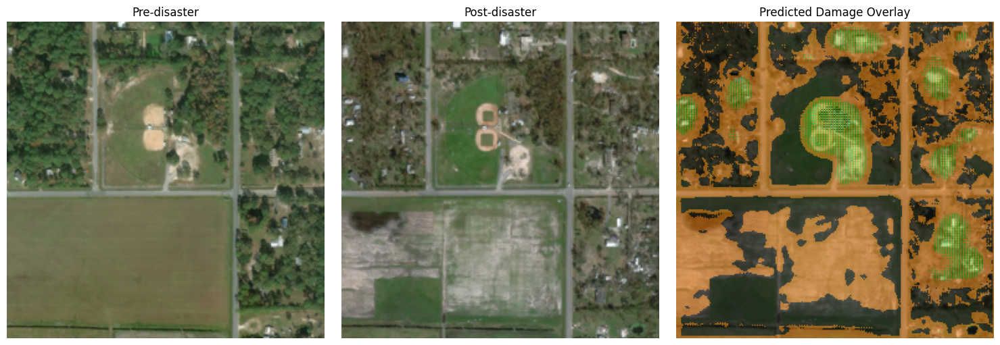

Scene: hurricane-michael_00000362
Predicted pixel counts: {np.int64(0): np.int64(27308), np.int64(1): np.int64(3400), np.int64(2): np.int64(584), np.int64(3): np.int64(34244)}


In [50]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

# Get first validation scene from the original dataset
row = val_dataset_balanced.df.iloc[0]

pre_path = row["pre_image"]
post_path = row["post_image"]

# Resize images to the model's 256x256 input size
pre_img = Image.open(pre_path).convert("RGB").resize((256, 256))
post_img = Image.open(post_path).convert("RGB").resize((256, 256))

pre_tensor = torch.from_numpy(
    np.array(pre_img).astype(np.float32) / 255.0
).permute(2, 0, 1).unsqueeze(0).to(device)

post_tensor = torch.from_numpy(
    np.array(post_img).astype(np.float32) / 255.0
).permute(2, 0, 1).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    logits = model(pre_tensor, post_tensor)
    logits[:, 2] += 0.2
    logits[:, 3] += 0.4
    prediction = logits.argmax(dim=1).squeeze(0).cpu().numpy()

# Colors: background, no damage, minor, major, destroyed
colors = np.array([
    [0, 0, 0],
    [0, 200, 0],
    [255, 220, 0],
    [255, 125, 0],
    [220, 0, 0]
], dtype=np.uint8)

overlay = np.array(post_img).copy()
overlay = (
    0.55 * overlay + 0.45 * colors[prediction]
).clip(0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(pre_img)
axes[0].set_title("Pre-disaster")
axes[1].imshow(post_img)
axes[1].set_title("Post-disaster")
axes[2].imshow(overlay)
axes[2].set_title("Predicted Damage Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Scene:", row["scene_id"])
print(
    "Predicted pixel counts:",
    dict(zip(*np.unique(prediction, return_counts=True)))
)

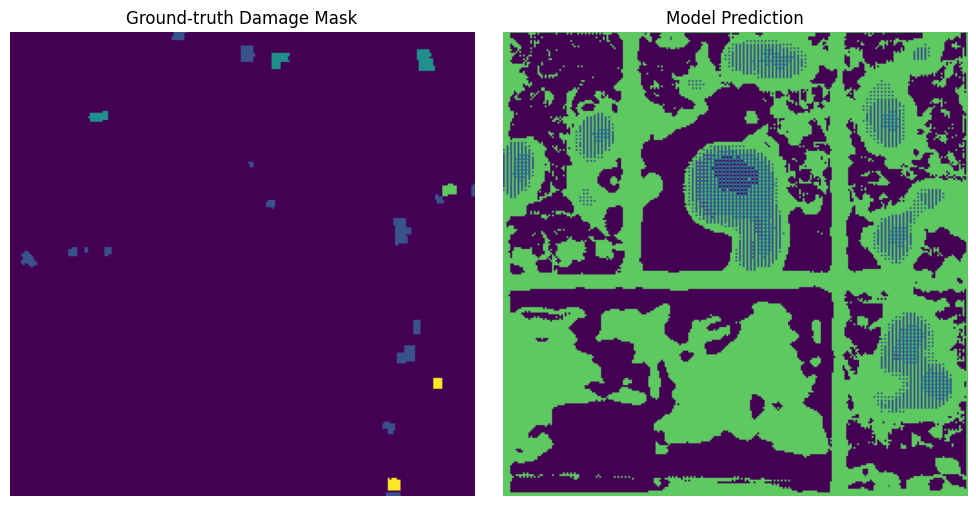

Ground-truth classes: (array([0, 1, 2, 3, 4], dtype=uint8), array([64678,   520,   216,    46,    76]))
Predicted classes: (array([0, 1, 2, 3]), array([27308,  3400,   584, 34244]))


In [51]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Find the ground-truth mask for this validation scene
mask_path = row["post_mask"]
ground_truth = np.array(
    Image.open(mask_path).convert("L").resize((256, 256), resample=Image.Resampling.NEAREST)
)

# Show ground truth beside the prediction
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(ground_truth, cmap="viridis", vmin=0, vmax=4)
axes[0].set_title("Ground-truth Damage Mask")

axes[1].imshow(prediction, cmap="viridis", vmin=0, vmax=4)
axes[1].set_title("Model Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Ground-truth classes:", np.unique(ground_truth, return_counts=True))
print("Predicted classes:", np.unique(prediction, return_counts=True))

In [52]:
# Inspect how validation patches map to their source scenes
print("Patch dataset sample format:")
print("First sample:", val_dataset_balanced.samples[0])

print("\nValidation manifest columns:")
print(val_dataset_balanced.df.columns.tolist())

print("\nFirst validation scene paths:")
print(val_dataset_balanced.df.iloc[0].to_dict())

Patch dataset sample format:
First sample: (365, 256, 0)

Validation manifest columns:
['scene_id', 'split', 'pre_image', 'post_image', 'pre_mask', 'post_mask']

First validation scene paths:
{'scene_id': 'hurricane-michael_00000362', 'split': 'val', 'pre_image': '/content/drive/MyDrive/T229/data/train/images/hurricane-michael_00000362_pre_disaster.png', 'post_image': '/content/drive/MyDrive/T229/data/train/images/hurricane-michael_00000362_post_disaster.png', 'pre_mask': '/content/drive/MyDrive/T229/data/train/targets/hurricane-michael_00000362_pre_disaster_target.png', 'post_mask': '/content/drive/MyDrive/T229/data/train/targets/hurricane-michael_00000362_post_disaster_target.png'}


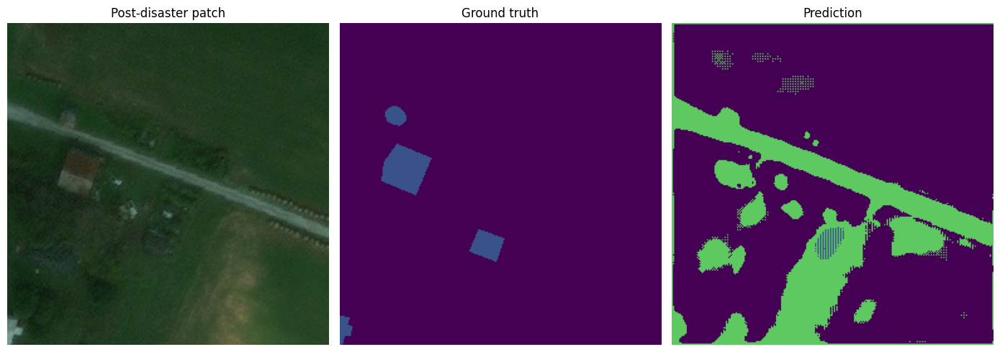

Scene: hurricane-florence_00000537
Patch coordinates: y = 256 , x = 0
Ground truth counts: {np.int64(0): np.int64(63701), np.int64(1): np.int64(1835)}
Prediction counts: {np.int64(0): np.int64(51002), np.int64(1): np.int64(207), np.int64(3): np.int64(14327)}


In [53]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# Get the exact validation patch
scene_idx, y, x = val_dataset_balanced.samples[0]
row = val_dataset_balanced.df.iloc[scene_idx]

# Dataset item: pre-image tensor, post-image tensor, target mask
pre_patch, post_patch, true_mask = val_dataset_balanced[0]

# Predict on that exact patch
model.eval()
with torch.no_grad():
    logits = model(
        pre_patch.unsqueeze(0).to(device),
        post_patch.unsqueeze(0).to(device)
    )
    logits[:, 2] += 0.2
    logits[:, 3] += 0.4
    pred_mask = logits.argmax(dim=1).squeeze(0).cpu().numpy()

true_mask = true_mask.cpu().numpy()

# Visual comparison
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(post_patch.permute(1, 2, 0).cpu().numpy())
axes[0].set_title("Post-disaster patch")
axes[1].imshow(true_mask, cmap="viridis", vmin=0, vmax=4)
axes[1].set_title("Ground truth")
axes[2].imshow(pred_mask, cmap="viridis", vmin=0, vmax=4)
axes[2].set_title("Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Scene:", row["scene_id"])
print("Patch coordinates: y =", y, ", x =", x)
print("Ground truth counts:", dict(zip(*np.unique(true_mask, return_counts=True))))
print("Prediction counts:", dict(zip(*np.unique(pred_mask, return_counts=True))))

In [54]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_true = true_mask.reshape(-1)
y_pred = pred_mask.reshape(-1)

class_names = [
    "background",
    "no_damage",
    "minor_damage",
    "major_damage",
    "destroyed"
]

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4]))

print("\nPer-class report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0,
    digits=4
))

Confusion matrix (rows=true, columns=predicted):
[[50448    81     0 13172     0]
 [  554   126     0  1155     0]
 [    0     0     0     0     0]
 [    0     0     0     0     0]
 [    0     0     0     0     0]]

Per-class report:
              precision    recall  f1-score   support

  background     0.9891    0.7919    0.8796     63701
   no_damage     0.6087    0.0687    0.1234      1835
minor_damage     0.0000    0.0000    0.0000         0
major_damage     0.0000    0.0000    0.0000         0
   destroyed     0.0000    0.0000    0.0000         0

    accuracy                         0.7717     65536
   macro avg     0.3196    0.1721    0.2006     65536
weighted avg     0.9785    0.7717    0.8585     65536



In [55]:
import torch
import os

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_focal_dice_calibrated.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint:", checkpoint_path)
print("Exists:", os.path.exists(checkpoint_path))
print("Saved validation macro-F1:", checkpoint.get("validation_macro_f1"))
print("Saved validation macro-IoU:", checkpoint.get("validation_macro_iou"))
print("Loss:", checkpoint.get("loss"))
print("Class weights:", checkpoint.get("class_weights"))
print("Calibration:", checkpoint.get("calibration_logit_boosts"))
print("Model currently in memory:", type(model).__name__)

Checkpoint: /content/drive/MyDrive/T229/checkpoints/siamese_unet_focal_dice_calibrated.pth
Exists: True
Saved validation macro-F1: 0.4324
Saved validation macro-IoU: 0.3317
Loss: FocalDiceLoss
Class weights: [0.15, 1.0, 4.0, 4.0, 4.0]
Calibration: {'minor_damage': 0.2, 'major_damage': 0.4}
Model currently in memory: SiameseUNet


In [56]:
import numpy as np

# Reuse the full-validation confusion matrix from the earlier evaluation.
# Rows = actual class; columns = predicted class.
cm = np.array([
    [192278189, 14417790, 821696, 3647856, 918976],
    [1665106, 12672588, 2922619, 1638016, 42518],
    [176843, 786554, 503610, 322958, 13307],
    [216529, 1173232, 693298, 699355, 24531],
    [199302, 266185, 118027, 40430, 522053]
], dtype=np.int64)

class_names = [
    "background",
    "no_damage",
    "minor_damage",
    "major_damage",
    "destroyed"
]

print(f"{'Class':<16} {'Precision':>10} {'Recall':>10} {'F1':>10} {'IoU':>10}")

for i, name in enumerate(class_names):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

    print(f"{name:<16} {precision:>10.4f} {recall:>10.4f} {f1:>10.4f} {iou:>10.4f}")

Class             Precision     Recall         F1        IoU
background           0.9884     0.9066     0.9457     0.8971
no_damage            0.4323     0.6691     0.5252     0.3561
minor_damage         0.0995     0.2793     0.1468     0.0792
major_damage         0.1102     0.2492     0.1528     0.0827
destroyed            0.3431     0.4555     0.3914     0.2433


In [57]:
import os
import pandas as pd

report_dir = "/content/drive/MyDrive/T229/reports"
os.makedirs(report_dir, exist_ok=True)

results = [
    ["background", 0.9884, 0.9066, 0.9457, 0.8971],
    ["no_damage", 0.4323, 0.6691, 0.5252, 0.3561],
    ["minor_damage", 0.0995, 0.2793, 0.1468, 0.0792],
    ["major_damage", 0.1102, 0.2492, 0.1528, 0.0827],
    ["destroyed", 0.3431, 0.4555, 0.3914, 0.2433],
]

df = pd.DataFrame(
    results,
    columns=["class", "precision", "recall", "f1", "iou"]
)

csv_path = os.path.join(report_dir, "siamese_unet_validation_metrics.csv")
df.to_csv(csv_path, index=False)

print(df.to_string(index=False))
print("\nSaved:", csv_path)
print("Macro F1:", round(df["f1"].mean(), 4))
print("Macro IoU:", round(df["iou"].mean(), 4))

       class  precision  recall     f1    iou
  background     0.9884  0.9066 0.9457 0.8971
   no_damage     0.4323  0.6691 0.5252 0.3561
minor_damage     0.0995  0.2793 0.1468 0.0792
major_damage     0.1102  0.2492 0.1528 0.0827
   destroyed     0.3431  0.4555 0.3914 0.2433

Saved: /content/drive/MyDrive/T229/reports/siamese_unet_validation_metrics.csv
Macro F1: 0.4324
Macro IoU: 0.3317


In [58]:
import os
import numpy as np
import pandas as pd

report_dir = "/content/drive/MyDrive/T229/reports"

cm = np.array([
    [192278189, 14417790, 821696, 3647856, 918976],
    [1665106, 12672588, 2922619, 1638016, 42518],
    [176843, 786554, 503610, 322958, 13307],
    [216529, 1173232, 693298, 699355, 24531],
    [199302, 266185, 118027, 40430, 522053]
], dtype=np.int64)

classes = [
    "background",
    "no_damage",
    "minor_damage",
    "major_damage",
    "destroyed"
]

cm_df = pd.DataFrame(
    cm,
    index=[f"actual_{c}" for c in classes],
    columns=[f"predicted_{c}" for c in classes]
)

path = os.path.join(report_dir, "siamese_unet_validation_confusion_matrix.csv")
cm_df.to_csv(path)

print("Saved confusion matrix:", path)
print(cm_df)

Saved confusion matrix: /content/drive/MyDrive/T229/reports/siamese_unet_validation_confusion_matrix.csv
                     predicted_background  predicted_no_damage  \
actual_background               192278189             14417790   
actual_no_damage                  1665106             12672588   
actual_minor_damage                176843               786554   
actual_major_damage                216529              1173232   
actual_destroyed                   199302               266185   

                     predicted_minor_damage  predicted_major_damage  \
actual_background                    821696                 3647856   
actual_no_damage                    2922619                 1638016   
actual_minor_damage                  503610                  322958   
actual_major_damage                  693298                  699355   
actual_destroyed                     118027                   40430   

                     predicted_destroyed  
actual_background           

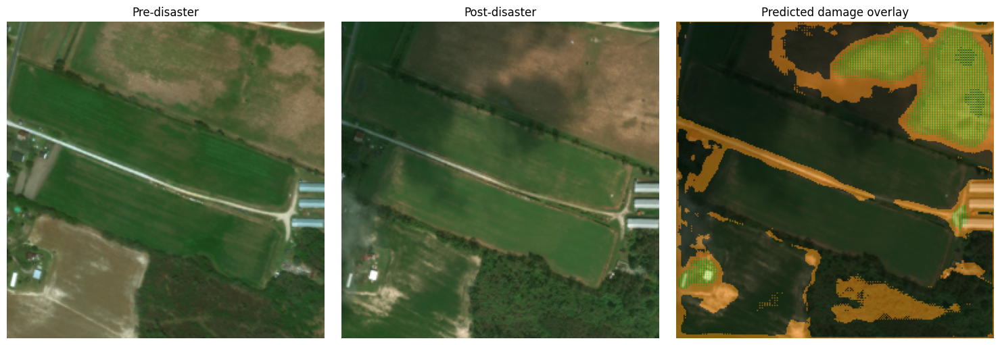

Saved heatmap: /content/drive/MyDrive/T229/reports/hurricane-florence_00000537_damage_heatmap.png
Predicted class pixel counts: {'background': 45529, 'no_damage': 3755, 'minor_damage': 1201, 'major_damage': 15051}


In [59]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

scene_id = "hurricane-florence_00000537"
image_dir = "/content/drive/MyDrive/T229/data/train/images"
report_dir = "/content/drive/MyDrive/T229/reports"
os.makedirs(report_dir, exist_ok=True)

pre_path = os.path.join(image_dir, f"{scene_id}_pre_disaster.png")
post_path = os.path.join(image_dir, f"{scene_id}_post_disaster.png")

# Load paired images at the model input size
pre_img = Image.open(pre_path).convert("RGB").resize((256, 256))
post_img = Image.open(post_path).convert("RGB").resize((256, 256))

pre_tensor = torch.from_numpy(
    np.array(pre_img).astype(np.float32) / 255.0
).permute(2, 0, 1).unsqueeze(0).to(device)

post_tensor = torch.from_numpy(
    np.array(post_img).astype(np.float32) / 255.0
).permute(2, 0, 1).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    logits = model(pre_tensor, post_tensor)
    logits[:, 2] += 0.2
    logits[:, 3] += 0.4
    prediction = logits.argmax(dim=1).squeeze(0).cpu().numpy()

# Colors: background, no damage, minor, major, destroyed
colors = np.array([
    [0, 0, 0],
    [0, 200, 0],
    [255, 220, 0],
    [255, 125, 0],
    [220, 0, 0]
], dtype=np.uint8)

post_array = np.array(post_img)
overlay = (
    0.55 * post_array + 0.45 * colors[prediction]
).clip(0, 255).astype(np.uint8)

output_path = os.path.join(
    report_dir, f"{scene_id}_damage_heatmap.png"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(pre_img)
axes[0].set_title("Pre-disaster")
axes[1].imshow(post_img)
axes[1].set_title("Post-disaster")
axes[2].imshow(overlay)
axes[2].set_title("Predicted damage overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(output_path, dpi=160, bbox_inches="tight")
plt.show()

print("Saved heatmap:", output_path)
print("Predicted class pixel counts:", {
    ["background", "no_damage", "minor_damage", "major_damage", "destroyed"][int(k)]: int(v)
    for k, v in zip(*np.unique(prediction, return_counts=True))
})

In [60]:
import os
import glob
import json

label_dir = "/content/drive/MyDrive/T229/data/train/labels"
scene_id = "hurricane-florence_00000537"

matches = glob.glob(os.path.join(label_dir, f"{scene_id}*"))

print("Matching label files:")
for path in matches:
    print(os.path.basename(path))

for path in matches:
    with open(path, "r") as f:
        data = json.load(f)

    print("\nFile:", os.path.basename(path))
    print("Top-level keys:", list(data.keys()))

    features = data.get("features", {})
    print("Feature groups:", list(features.keys()) if isinstance(features, dict) else type(features))

    if isinstance(features, dict):
        for group_name, group in features.items():
            if isinstance(group, list) and group:
                print(f"\nExample from {group_name}:")
                print(json.dumps(group[0], indent=2)[:2500])
                break

Matching label files:
hurricane-florence_00000537_post_disaster.json
hurricane-florence_00000537_pre_disaster.json

File: hurricane-florence_00000537_post_disaster.json
Top-level keys: ['features', 'metadata']
Feature groups: ['lng_lat', 'xy']

Example from lng_lat:
{
  "properties": {
    "feature_type": "building",
    "subtype": "no-damage",
    "uid": "5f744afe-1117-488b-a147-6b635e577942"
  },
  "wkt": "POLYGON ((-77.94091944447335 34.85669395972975, -77.9404224856921 34.85669523483295, -77.94041139761933 34.85657524081392, -77.94092192078163 34.85657674383522, -77.94093292129149 34.85662813080756, -77.94091944447335 34.85669395972975))"
}

File: hurricane-florence_00000537_pre_disaster.json
Top-level keys: ['features', 'metadata']
Feature groups: ['lng_lat', 'xy']

Example from lng_lat:
{
  "properties": {
    "feature_type": "building",
    "uid": "5f744afe-1117-488b-a147-6b635e577942"
  },
  "wkt": "POLYGON ((-77.94091944442792 34.85669395976106, -77.94093292124604 34.856628130

In [61]:
import os
import json

label_path = (
    "/content/drive/MyDrive/T229/data/train/labels/"
    "hurricane-florence_00000537_post_disaster.json"
)

with open(label_path, "r") as f:
    data = json.load(f)

xy_features = data["features"]["xy"]

print("Number of xy features:", len(xy_features))
print("\nFirst xy feature:")
print(json.dumps(xy_features[0], indent=2)[:3000])

print("\nMetadata:")
print(json.dumps(data["metadata"], indent=2)[:3000])

Number of xy features: 21

First xy feature:
{
  "properties": {
    "feature_type": "building",
    "subtype": "no-damage",
    "uid": "5f744afe-1117-488b-a147-6b635e577942"
  },
  "wkt": "POLYGON ((920.3994436042177 636.1706952651492, 1019.971686982055 638.7838841498184, 1021.336967200629 668.0131793963698, 919.0668460910294 664.6450017635789, 917.2296582887743 652.0908850986031, 920.3994436042177 636.1706952651492))"
}

Metadata:
{
  "sensor": "GEOEYE01",
  "provider_asset_type": "GEOEYE01",
  "gsd": 2.0916247,
  "capture_date": "2018-09-20T16:04:41.000Z",
  "off_nadir_angle": 28.017313,
  "pan_resolution": 0.52282465,
  "sun_azimuth": 153.94543,
  "sun_elevation": 53.722378,
  "target_azimuth": 190.82309,
  "disaster": "hurricane-florence",
  "disaster_type": "flooding",
  "catalog_id": "1050010012411600",
  "original_width": 1024,
  "original_height": 1024,
  "width": 1024,
  "height": 1024,
  "id": "MjU0NzE1NQ.cKhdEK7MfRhc7SEjmoEw9OVpO2o",
  "img_name": "hurricane-florence_000005

In [62]:
try:
    import shapely
    print("Shapely version:", shapely.__version__)
except ImportError:
    print("Shapely is not installed.")

import torch
print("Model device:", next(model.parameters()).device)
print("Model output classes:", model.output.out_channels)

Shapely version: 2.2.0
Model device: cpu
Model output classes: 5


In [63]:
import os
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image
from shapely import wkt
from shapely.geometry import Point

root = "/content/drive/MyDrive/T229"
scene_id = "hurricane-florence_00000537"

image_path = f"{root}/data/train/images/{scene_id}_post_disaster.png"
json_path = f"{root}/data/train/labels/{scene_id}_post_disaster.json"
output_path = f"{root}/reports/{scene_id}_per_building_damage.csv"

# Load original-resolution image and annotations
image = Image.open(image_path).convert("RGB")
with open(json_path, "r") as f:
    annotations = json.load(f)

image_array = np.asarray(image)
height, width = image_array.shape[:2]
prediction = np.zeros((height, width), dtype=np.uint8)

# Predict each non-overlapping 256x256 patch
model.eval()
with torch.no_grad():
    for y in range(0, height, 256):
        for x in range(0, width, 256):
            patch = image.crop((x, y, x + 256, y + 256))
            patch_array = np.asarray(patch).astype(np.float32) / 255.0

            # This scene's pre-image is required for Siamese inference
            pre_path = f"{root}/data/train/images/{scene_id}_pre_disaster.png"
            pre_patch = Image.open(pre_path).convert("RGB").crop(
                (x, y, x + 256, y + 256)
            )
            pre_array = np.asarray(pre_patch).astype(np.float32) / 255.0

            pre_tensor = torch.from_numpy(pre_array).permute(2, 0, 1).unsqueeze(0).to(device)
            post_tensor = torch.from_numpy(patch_array).permute(2, 0, 1).unsqueeze(0).to(device)

            logits = model(pre_tensor, post_tensor)
            logits[:, 2] += 0.2
            logits[:, 3] += 0.4
            patch_prediction = logits.argmax(dim=1).squeeze(0).cpu().numpy()

            prediction[y:y+256, x:x+256] = patch_prediction

# Assign each building the most common predicted class inside its polygon
class_names = {
    0: "background",
    1: "no-damage",
    2: "minor-damage",
    3: "major-damage",
    4: "destroyed"
}

records = []
for feature in annotations["features"]["xy"]:
    props = feature.get("properties", {})
    if props.get("feature_type") != "building":
        continue

    polygon = wkt.loads(feature["wkt"])
    min_x, min_y, max_x, max_y = polygon.bounds

    x0 = max(0, int(np.floor(min_x)))
    y0 = max(0, int(np.floor(min_y)))
    x1 = min(width, int(np.ceil(max_x)))
    y1 = min(height, int(np.ceil(max_y)))

    class_counts = {i: 0 for i in range(5)}
    total_pixels = 0

    # Test pixel centers against the polygon
    for py in range(y0, y1):
        for px in range(x0, x1):
            if polygon.covers(Point(px + 0.5, py + 0.5)):
                cls = int(prediction[py, px])
                class_counts[cls] += 1
                total_pixels += 1

    # Ignore background when selecting a building damage label
    damage_counts = {k: v for k, v in class_counts.items() if k != 0}
    predicted_class = max(damage_counts, key=damage_counts.get) if sum(damage_counts.values()) else 0

    records.append({
        "scene_id": scene_id,
        "building_uid": props.get("uid"),
        "ground_truth_damage": props.get("subtype", "unknown"),
        "predicted_damage": class_names[predicted_class],
        "polygon_pixels": total_pixels,
        "background_fraction": class_counts[0] / total_pixels if total_pixels else np.nan,
        "no_damage_fraction": class_counts[1] / total_pixels if total_pixels else np.nan,
        "minor_damage_fraction": class_counts[2] / total_pixels if total_pixels else np.nan,
        "major_damage_fraction": class_counts[3] / total_pixels if total_pixels else np.nan,
        "destroyed_fraction": class_counts[4] / total_pixels if total_pixels else np.nan
    })

df = pd.DataFrame(records)
df.to_csv(output_path, index=False)

print("Saved per-building CSV:", output_path)
print("Buildings processed:", len(df))
print(df[["building_uid", "ground_truth_damage", "predicted_damage"]].head(10).to_string(index=False))

Saved per-building CSV: /content/drive/MyDrive/T229/reports/hurricane-florence_00000537_per_building_damage.csv
Buildings processed: 21
                        building_uid ground_truth_damage predicted_damage
5f744afe-1117-488b-a147-6b635e577942           no-damage     major-damage
57d65cb7-f582-4481-b477-89ae7a791317           no-damage     major-damage
f1497d97-3521-481e-a43a-e7d4cc9c8dc3           no-damage     major-damage
96a0b3f9-9052-4119-b166-5ef75bcabfc5           no-damage     major-damage
8ddbe9e8-1d04-46f2-826e-62a178dd7081           no-damage     major-damage
4af4601c-7685-4053-ade8-112e9d56c05d           no-damage        no-damage
2b1b1dbd-185c-4ab7-8fca-a5b0fc36cff3           no-damage     major-damage
1635629e-8547-4f8f-ba90-5ea382544397       un-classified     major-damage
a18d26c0-1567-4603-84de-279c4aa1e1b5       un-classified     major-damage
06b9c5de-8ec9-4cd8-addc-0d111675a5cf           no-damage     major-damage


In [64]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

csv_path = (
    "/content/drive/MyDrive/T229/reports/"
    "hurricane-florence_00000537_per_building_damage.csv"
)

df = pd.read_csv(csv_path)

# Exclude un-classified labels from supervised evaluation
known = df[
    df["ground_truth_damage"].isin([
        "no-damage", "minor-damage", "major-damage", "destroyed"
    ])
].copy()

labels = ["no-damage", "minor-damage", "major-damage", "destroyed"]

print("Buildings in CSV:", len(df))
print("Buildings with known ground truth:", len(known))
print("\nConfusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(
    known["ground_truth_damage"],
    known["predicted_damage"],
    labels=labels
))

print("\nClassification report:")
print(classification_report(
    known["ground_truth_damage"],
    known["predicted_damage"],
    labels=labels,
    zero_division=0,
    digits=3
))

print("\nGround truth counts:")
print(known["ground_truth_damage"].value_counts())

print("\nPredicted counts:")
print(known["predicted_damage"].value_counts())

Buildings in CSV: 21
Buildings with known ground truth: 17

Confusion matrix (rows=true, columns=predicted):
[[ 2  0 14  0]
 [ 0  0  0  0]
 [ 0  0  0  0]
 [ 0  0  1  0]]

Classification report:
              precision    recall  f1-score   support

   no-damage      1.000     0.125     0.222        16
minor-damage      0.000     0.000     0.000         0
major-damage      0.000     0.000     0.000         0
   destroyed      0.000     0.000     0.000         1

    accuracy                          0.118        17
   macro avg      0.250     0.031     0.056        17
weighted avg      0.941     0.118     0.209        17


Ground truth counts:
ground_truth_damage
no-damage    16
destroyed     1
Name: count, dtype: int64

Predicted counts:
predicted_damage
major-damage    15
no-damage        2
Name: count, dtype: int64


In [65]:
import pandas as pd

csv_path = (
    "/content/drive/MyDrive/T229/reports/"
    "hurricane-florence_00000537_per_building_damage.csv"
)

df = pd.read_csv(csv_path)

cols = [
    "building_uid",
    "ground_truth_damage",
    "predicted_damage",
    "background_fraction",
    "no_damage_fraction",
    "minor_damage_fraction",
    "major_damage_fraction",
    "destroyed_fraction"
]

print(df[cols].head(12).round(3).to_string(index=False))

                        building_uid ground_truth_damage predicted_damage  background_fraction  no_damage_fraction  minor_damage_fraction  major_damage_fraction  destroyed_fraction
5f744afe-1117-488b-a147-6b635e577942           no-damage     major-damage                0.000               0.239                  0.000                  0.761                 0.0
57d65cb7-f582-4481-b477-89ae7a791317           no-damage     major-damage                0.000               0.425                  0.039                  0.535                 0.0
f1497d97-3521-481e-a43a-e7d4cc9c8dc3           no-damage     major-damage                0.000               0.289                  0.000                  0.711                 0.0
96a0b3f9-9052-4119-b166-5ef75bcabfc5           no-damage     major-damage                0.000               0.264                  0.000                  0.736                 0.0
8ddbe9e8-1d04-46f2-826e-62a178dd7081           no-damage     major-damage                0.000 

In [66]:
import os
import numpy as np
from PIL import Image

root = "/content/drive/MyDrive/T229/data/train"
scene_id = "hurricane-florence_00000537"

files = {
    "pre_image": f"{root}/images/{scene_id}_pre_disaster.png",
    "post_image": f"{root}/images/{scene_id}_post_disaster.png",
    "pre_mask": f"{root}/targets/{scene_id}_pre_disaster_target.png",
    "post_mask": f"{root}/targets/{scene_id}_post_disaster_target.png",
}

for name, path in files.items():
    img = Image.open(path)
    arr = np.array(img)
    print(f"{name}: size={img.size}, mode={img.mode}, shape={arr.shape}, values={np.unique(arr)[:10]}")

# Inspect annotated damage classes for this scene
import json
label_path = f"{root}/labels/{scene_id}_post_disaster.json"

with open(label_path, "r") as f:
    annotations = json.load(f)

from collections import Counter
subtypes = Counter(
    feature.get("properties", {}).get("subtype", "missing")
    for feature in annotations["features"]["xy"]
    if feature.get("properties", {}).get("feature_type") == "building"
)

print("\nJSON building damage labels:", dict(subtypes))

pre_image: size=(1024, 1024), mode=RGB, shape=(1024, 1024, 3), values=[ 1 13 18 19 20 21 22 23 24 25]
post_image: size=(1024, 1024), mode=RGB, shape=(1024, 1024, 3), values=[ 8 10 11 12 13 14 15 16 17 18]
pre_mask: size=(1024, 1024), mode=L, shape=(1024, 1024), values=[0 1]
post_mask: size=(1024, 1024), mode=L, shape=(1024, 1024), values=[0 1 4]

JSON building damage labels: {'no-damage': 16, 'un-classified': 4, 'destroyed': 1}


In [67]:
# Inspect one sample directly from the balanced validation dataset
pre_patch, post_patch, target_patch = val_dataset_balanced[0]

import numpy as np
import torch

print("Target tensor dtype:", target_patch.dtype)
print("Target shape:", tuple(target_patch.shape))
print("Target class counts:", {
    int(k): int(v)
    for k, v in zip(*torch.unique(target_patch.cpu(), return_counts=True))
})

print("\nExpected mapping:")
print({
    0: "background",
    1: "no_damage",
    2: "minor_damage",
    3: "major_damage",
    4: "destroyed"
})

print("\nModel output channels:", model.output.out_channels)
print("Sample input shape:", tuple(pre_patch.shape))

Target tensor dtype: torch.int64
Target shape: (256, 256)
Target class counts: {0: 63701, 1: 1835}

Expected mapping:
{0: 'background', 1: 'no_damage', 2: 'minor_damage', 3: 'major_damage', 4: 'destroyed'}

Model output channels: 5
Sample input shape: (3, 256, 256)


In [68]:
from collections import Counter
import numpy as np
from PIL import Image

patch_class_counts = Counter()

for scene_idx, y, x in train_dataset_balanced.samples:
    row = train_dataset_balanced.df.iloc[scene_idx]

    with Image.open(row["post_mask"]) as img:
        patch = np.array(img.crop((x, y, x + 256, y + 256)))

    present, counts = np.unique(patch, return_counts=True)
    for class_id, count in zip(present, counts):
        patch_class_counts[int(class_id)] += 1

print("Training patches containing each class:")
for class_id, name in {
    0: "background",
    1: "no damage",
    2: "minor damage",
    3: "major damage",
    4: "destroyed"
}.items():
    print(f"{class_id} ({name}): {patch_class_counts[class_id]:,} patches")

Training patches containing each class:
0 (background): 17,268 patches
1 (no damage): 10,117 patches
2 (minor damage): 3,242 patches
3 (major damage): 3,073 patches
4 (destroyed): 2,772 patches


In [69]:
import numpy as np
import torch

# Find a validation patch containing a damage class
selected_idx = None

for i, (_, _, target) in enumerate(val_dataset_balanced):
    if torch.any((target == 2) | (target == 3) | (target == 4)):
        selected_idx = i
        break

if selected_idx is None:
    print("No validation patch with damage classes found.")
else:
    pre, post, target = val_dataset_balanced[selected_idx]

    model.eval()
    with torch.no_grad():
        logits = model(
            pre.unsqueeze(0).to(device),
            post.unsqueeze(0).to(device)
        )

        # Apply the same calibration used for validation
        logits[:, 2] += 0.2  # minor damage
        logits[:, 3] += 0.4  # major damage

        prediction = logits.argmax(dim=1).squeeze(0).cpu()

    names = {
        0: "background",
        1: "no damage",
        2: "minor damage",
        3: "major damage",
        4: "destroyed"
    }

    print("Validation patch index:", selected_idx)

    print("\nGround truth pixel counts:")
    for cls, count in zip(*torch.unique(target, return_counts=True)):
        print(f"{names[int(cls)]}: {int(count):,}")

    print("\nPredicted pixel counts:")
    for cls, count in zip(*torch.unique(prediction, return_counts=True)):
        print(f"{names[int(cls)]}: {int(count):,}")

Validation patch index: 5

Ground truth pixel counts:
background: 50,958
minor damage: 9,184
major damage: 5,394

Predicted pixel counts:
background: 28,594
no damage: 1,904
minor damage: 174
major damage: 34,864


In [70]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_true = target.cpu().numpy().ravel()
y_pred = prediction.cpu().numpy().ravel()

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=[
        "background",
        "no damage",
        "minor damage",
        "major damage",
        "destroyed"
    ],
    zero_division=0,
    digits=4
))

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4]))

              precision    recall  f1-score   support

  background     0.9800    0.5499    0.7045     50958
   no damage     0.0000    0.0000    0.0000         0
minor damage     0.1149    0.0022    0.0043      9184
major damage     0.1467    0.9485    0.2542      5394
   destroyed     0.0000    0.0000    0.0000         0

    accuracy                         0.5060     65536
   macro avg     0.2483    0.3001    0.1926     65536
weighted avg     0.7902    0.5060    0.5693     65536

Confusion matrix (rows=true, columns=predicted):
[[28022  1175   154 21607     0]
 [    0     0     0     0     0]
 [  294   729    20  8141     0]
 [  278     0     0  5116     0]
 [    0     0     0     0     0]]


In [71]:
import os
import torch

checkpoint_dir = "/content/drive/MyDrive/T229/checkpoints"

print("Checkpoint files:")
for filename in sorted(os.listdir(checkpoint_dir)):
    if filename.endswith((".pth", ".pt")):
        path = os.path.join(checkpoint_dir, filename)
        print(f"{filename} — {os.path.getsize(path) / (1024 * 1024):.2f} MB")

print("\nCurrent model device:", next(model.parameters()).device)
print("Current model parameters:", sum(p.numel() for p in model.parameters()))
print("Current loss function:", type(criterion_combined).__name__)
print("Training batches per epoch:", len(train_loader_weighted))

Checkpoint files:
resnet18_augmented_best.pth — 42.72 MB
resnet18_context_best.pth — 42.72 MB
resnet18_damage_best.pth — 128.05 MB
siamese_unet_balanced_20steps.pth — 8.18 MB
siamese_unet_best.pth — 8.17 MB
siamese_unet_cached_40steps.pth — 8.17 MB
siamese_unet_focal_dice_calibrated.pth — 2.74 MB
siamese_unet_ignore_trial_20steps.pth — 2.74 MB
siamese_unet_trial_100steps.pth — 8.17 MB

Current model device: cpu
Current model parameters: 703061


NameError: name 'criterion_combined' is not defined

In [72]:
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/siamese_unet_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if isinstance(value, (int, float, str, bool)):
            print(f"{key}: {value}")
        elif isinstance(value, dict):
            print(f"{key}: dictionary with {len(value)} entries")
        elif isinstance(value, torch.Tensor):
            print(f"{key}: tensor with shape {tuple(value.shape)}")

Checkpoint type: dict
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'val_loss']
epoch: 1
model_state_dict: dictionary with 148 entries
optimizer_state_dict: dictionary with 2 entries
val_loss: 0.7386799712948491


In [73]:
import torch

checkpoint = torch.load(
    "/content/drive/MyDrive/T229/checkpoints/siamese_unet_best.pth",
    map_location="cpu",
    weights_only=False
)

# Create a fresh model and optimizer for the checkpoint
checkpoint_model = SiameseUNet(num_classes=5).to(device)
checkpoint_model.load_state_dict(checkpoint["model_state_dict"])

checkpoint_optimizer = torch.optim.Adam(
    checkpoint_model.parameters(),
    lr=0.001
)
checkpoint_optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

print("Model weights loaded successfully.")
print("Optimizer state loaded successfully.")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint validation loss:", checkpoint["val_loss"])
print("Restored learning rate:",
      checkpoint_optimizer.param_groups[0]["lr"])

Model weights loaded successfully.
Optimizer state loaded successfully.
Checkpoint epoch: 1
Checkpoint validation loss: 0.7386799712948491
Restored learning rate: 0.001


In [74]:
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_focal_dice_calibrated.pth"
)

calibrated_checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint keys:", list(calibrated_checkpoint.keys()))

state = calibrated_checkpoint.get(
    "model_state_dict",
    calibrated_checkpoint.get("state_dict")
)

if state is None:
    print("Model weights key not found; do not load yet.")
else:
    model.load_state_dict(state)
    model.to(device)
    model.eval()

    print("Calibrated model loaded successfully.")
    print("Device:", next(model.parameters()).device)
    print("Saved validation macro-F1:",
          calibrated_checkpoint.get("validation_macro_f1", "Not stored under this key"))
    print("Saved validation macro-IoU:",
          calibrated_checkpoint.get("validation_macro_iou", "Not stored under this key"))

Checkpoint keys: ['model_state_dict', 'model_name', 'num_classes', 'class_names', 'loss', 'focal_gamma', 'dice_weight', 'class_weights', 'calibration_logit_boosts', 'validation_macro_f1', 'validation_macro_iou']
Calibrated model loaded successfully.
Device: cpu
Saved validation macro-F1: 0.4324
Saved validation macro-IoU: 0.3317


In [75]:
print("Model:", calibrated_checkpoint["model_name"])
print("Classes:", calibrated_checkpoint["class_names"])
print("Loss configuration:", calibrated_checkpoint["loss"])
print("Focal gamma:", calibrated_checkpoint["focal_gamma"])
print("Dice weight:", calibrated_checkpoint["dice_weight"])

print("\nSaved class weights:")
print(calibrated_checkpoint["class_weights"])

print("\nCalibration logit boosts:")
print(calibrated_checkpoint["calibration_logit_boosts"])

Model: SiameseUNet
Classes: ['background', 'no_damage', 'minor_damage', 'major_damage', 'destroyed']
Loss configuration: FocalDiceLoss
Focal gamma: 2.0
Dice weight: 0.5

Saved class weights:
[0.15, 1.0, 4.0, 4.0, 4.0]

Calibration logit boosts:
{'minor_damage': 0.2, 'major_damage': 0.4}


In [76]:
import torch

# Use the same validation patch inspected earlier
pre, post, target = val_dataset_balanced[5]

model.eval()
with torch.no_grad():
    logits = model(
        pre.unsqueeze(0).to(device),
        post.unsqueeze(0).to(device)
    )

    logits[:, 2] += 0.2
    logits[:, 3] += 0.4

    prediction = logits.argmax(dim=1).squeeze(0).cpu()

# Pixels belonging to annotated buildings in this patch
building_pixels = target > 0
outside_pixels = ~building_pixels

print("Total pixels:", target.numel())
print("Annotated building pixels:", int(building_pixels.sum()))
print("Background pixels:", int(outside_pixels.sum()))

print(
    "\nPredicted damage outside annotated buildings:",
    int(((prediction >= 2) & outside_pixels).sum())
)

print(
    "Predicted damage inside annotated buildings:",
    int(((prediction >= 2) & building_pixels).sum())
)

Total pixels: 65536
Annotated building pixels: 14578
Background pixels: 50958

Predicted damage outside annotated buildings: 21761
Predicted damage inside annotated buildings: 13277


In [77]:
damage_outside = ((prediction >= 2) & outside_pixels).sum().item()
damage_inside = ((prediction >= 2) & building_pixels).sum().item()

outside_count = outside_pixels.sum().item()
inside_count = building_pixels.sum().item()

print(f"Outside-building damage rate: {damage_outside / outside_count:.2%}")
print(f"Inside-building damage rate:  {damage_inside / inside_count:.2%}")
print(f"Outside predicted-damage pixels: {damage_outside:,}")
print(f"Inside predicted-damage pixels:  {damage_inside:,}")

Outside-building damage rate: 42.70%
Inside-building damage rate:  91.08%
Outside predicted-damage pixels: 21,761
Inside predicted-damage pixels:  13,277


In [78]:
import numpy as np
from PIL import Image

pre, post, target = val_dataset_balanced[5]
scene_idx, y, x = val_dataset_balanced.samples[5]
row = val_dataset_balanced.df.iloc[scene_idx]

with Image.open(row["pre_mask"]) as img:
    pre_mask_patch = np.array(
        img.crop((x, y, x + 256, y + 256))
    )

print("Pre-disaster mask values and pixel counts:")
values, counts = np.unique(pre_mask_patch, return_counts=True)

for value, count in zip(values, counts):
    print(f"Value {value}: {count:,} pixels")

print("\nPost-disaster target values:")
values, counts = torch.unique(target, return_counts=True)

for value, count in zip(values, counts):
    print(f"Value {int(value)}: {int(count):,} pixels")

Pre-disaster mask values and pixel counts:
Value 0: 50,958 pixels
Value 1: 14,578 pixels

Post-disaster target values:
Value 0: 50,958 pixels
Value 2: 9,184 pixels
Value 3: 5,394 pixels


In [79]:
# Use the verified pre-disaster building mask
building_footprint = torch.from_numpy(
    pre_mask_patch == 1
)

predicted_damage = prediction >= 2

outside_footprint = ~building_footprint

outside_damage = (
    predicted_damage & outside_footprint
).sum().item()

inside_damage = (
    predicted_damage & building_footprint
).sum().item()

outside_pixels = outside_footprint.sum().item()
inside_pixels = building_footprint.sum().item()

print(f"Predicted damage outside footprints: {outside_damage:,}")
print(f"Predicted damage inside footprints:  {inside_damage:,}")

print(
    f"Outside-footprint false-positive rate: "
    f"{outside_damage / max(outside_pixels, 1):.2%}"
)

print(
    f"Inside-footprint damage prediction rate: "
    f"{inside_damage / max(inside_pixels, 1):.2%}"
)

Predicted damage outside footprints: 21,761
Predicted damage inside footprints:  13,277
Outside-footprint false-positive rate: 42.70%
Inside-footprint damage prediction rate: 91.08%


In [80]:
# Experimental post-processing: suppress damage outside footprints
masked_prediction = prediction.clone()
masked_prediction[~building_footprint] = 0

print("Original predicted class counts:")
for cls, count in zip(*torch.unique(prediction, return_counts=True)):
    print(f"Class {int(cls)}: {int(count):,}")

print("\nAfter footprint masking:")
for cls, count in zip(*torch.unique(masked_prediction, return_counts=True)):
    print(f"Class {int(cls)}: {int(count):,}")

print(
    "\nDamage pixels suppressed:",
    int((prediction[~building_footprint] >= 2).sum())
)

Original predicted class counts:
Class 0: 28,594
Class 1: 1,904
Class 2: 174
Class 3: 34,864

After footprint masking:
Class 0: 51,530
Class 1: 729
Class 2: 20
Class 3: 13,257

Damage pixels suppressed: 21761


In [81]:
from sklearn.metrics import classification_report
import numpy as np

y_true = target.cpu().numpy().ravel()
y_original = prediction.cpu().numpy().ravel()
y_masked = masked_prediction.cpu().numpy().ravel()

class_names = [
    "background",
    "no damage",
    "minor damage",
    "major damage",
    "destroyed"
]

print("=== Original predictions ===")
print(classification_report(
    y_true,
    y_original,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0,
    digits=4
))

print("\n=== Footprint-masked predictions ===")
print(classification_report(
    y_true,
    y_masked,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0,
    digits=4
))

=== Original predictions ===
              precision    recall  f1-score   support

  background     0.9800    0.5499    0.7045     50958
   no damage     0.0000    0.0000    0.0000         0
minor damage     0.1149    0.0022    0.0043      9184
major damage     0.1467    0.9485    0.2542      5394
   destroyed     0.0000    0.0000    0.0000         0

    accuracy                         0.5060     65536
   macro avg     0.2483    0.3001    0.1926     65536
weighted avg     0.7902    0.5060    0.5693     65536


=== Footprint-masked predictions ===
              precision    recall  f1-score   support

  background     0.9889    1.0000    0.9944     50958
   no damage     0.0000    0.0000    0.0000         0
minor damage     1.0000    0.0022    0.0043      9184
major damage     0.3859    0.9485    0.5486      5394
   destroyed     0.0000    0.0000    0.0000         0

    accuracy                         0.8559     65536
   macro avg     0.4750    0.3901    0.3095     65536
weighted a

In [82]:
import numpy as np
import torch
from sklearn.metrics import f1_score
from PIL import Image

model.eval()

num_patches = min(20, len(val_dataset_balanced))
y_true_all = []
y_pred_all = []
y_masked_all = []

for i in range(num_patches):
    pre, post, target_patch = val_dataset_balanced[i]
    scene_idx, y, x = val_dataset_balanced.samples[i]
    row = val_dataset_balanced.df.iloc[scene_idx]

    with Image.open(row["pre_mask"]) as img:
        footprint = np.array(
            img.crop((x, y, x + 256, y + 256))
        ) == 1

    with torch.no_grad():
        logits = model(
            pre.unsqueeze(0).to(device),
            post.unsqueeze(0).to(device)
        )
        logits[:, 2] += 0.2
        logits[:, 3] += 0.4
        pred = logits.argmax(dim=1).squeeze(0).cpu().numpy()

    masked_pred = pred.copy()
    masked_pred[~footprint] = 0

    y_true_all.extend(target_patch.cpu().numpy().ravel())
    y_pred_all.extend(pred.ravel())
    y_masked_all.extend(masked_pred.ravel())

labels = [1, 2, 3, 4]  # Exclude background from macro-F1

print("Patches evaluated:", num_patches)
print("Original damage-class macro-F1:",
      round(f1_score(y_true_all, y_pred_all,
                     labels=labels, average="macro", zero_division=0), 4))
print("Masked damage-class macro-F1:",
      round(f1_score(y_true_all, y_masked_all,
                     labels=labels, average="macro", zero_division=0), 4))

Patches evaluated: 20
Original damage-class macro-F1: 0.0677
Masked damage-class macro-F1: 0.147


In [83]:
import numpy as np
import torch
from PIL import Image
from sklearn.metrics import f1_score

model.eval()

num_patches = min(100, len(val_dataset_balanced))
y_true_all, y_pred_all, y_masked_all = [], [], []

for i in range(num_patches):
    pre, post, target_patch = val_dataset_balanced[i]
    scene_idx, y, x = val_dataset_balanced.samples[i]
    row = val_dataset_balanced.df.iloc[scene_idx]

    with Image.open(row["pre_mask"]) as img:
        footprint = np.array(
            img.crop((x, y, x + 256, y + 256))
        ) == 1

    with torch.no_grad():
        logits = model(
            pre.unsqueeze(0).to(device),
            post.unsqueeze(0).to(device)
        )
        logits[:, 2] += 0.2
        logits[:, 3] += 0.4
        pred = logits.argmax(dim=1).squeeze(0).cpu().numpy()

    masked_pred = pred.copy()
    masked_pred[~footprint] = 0

    y_true_all.append(target_patch.numpy().ravel())
    y_pred_all.append(pred.ravel())
    y_masked_all.append(masked_pred.ravel())

y_true_all = np.concatenate(y_true_all)
y_pred_all = np.concatenate(y_pred_all)
y_masked_all = np.concatenate(y_masked_all)

# Evaluate damage classes only, excluding background
labels = [1, 2, 3, 4]

print("Validation patches:", num_patches)
print("Original damage-class macro-F1:",
      round(f1_score(y_true_all, y_pred_all, labels=labels,
                     average="macro", zero_division=0), 4))
print("Masked damage-class macro-F1:",
      round(f1_score(y_true_all, y_masked_all, labels=labels,
                     average="macro", zero_division=0), 4))

Validation patches: 100
Original damage-class macro-F1: 0.0762
Masked damage-class macro-F1: 0.1611


In [84]:
import numpy as np
import torch
from PIL import Image
from sklearn.metrics import f1_score

# Select up to 100 patches spread across distinct validation scenes
samples = val_dataset_balanced.samples
scene_to_indices = {}

for i, (scene_idx, y, x) in enumerate(samples):
    scene_to_indices.setdefault(scene_idx, []).append(i)

rng = np.random.default_rng(42)
scene_ids = sorted(scene_to_indices)
chosen_scenes = rng.choice(
    scene_ids,
    size=min(100, len(scene_ids)),
    replace=False
)

chosen_indices = [
    int(rng.choice(scene_to_indices[int(scene_id)]))
    for scene_id in chosen_scenes
]

y_true_all, y_pred_all, y_masked_all = [], [], []
model.eval()

for i in chosen_indices:
    pre, post, target_patch = val_dataset_balanced[i]
    scene_idx, y, x = samples[i]
    row = val_dataset_balanced.df.iloc[scene_idx]

    with Image.open(row["pre_mask"]) as img:
        footprint = np.array(
            img.crop((x, y, x + 256, y + 256))
        ) == 1

    with torch.no_grad():
        logits = model(
            pre.unsqueeze(0).to(device),
            post.unsqueeze(0).to(device)
        )
        logits[:, 2] += 0.2
        logits[:, 3] += 0.4
        pred = logits.argmax(dim=1).squeeze(0).cpu().numpy()

    masked_pred = pred.copy()
    masked_pred[~footprint] = 0

    y_true_all.append(target_patch.numpy().ravel())
    y_pred_all.append(pred.ravel())
    y_masked_all.append(masked_pred.ravel())

y_true_all = np.concatenate(y_true_all)
y_pred_all = np.concatenate(y_pred_all)
y_masked_all = np.concatenate(y_masked_all)

labels = [1, 2, 3, 4]

print("Distinct scenes sampled:", len(chosen_scenes))
print("Original damage-class macro-F1:",
      round(f1_score(y_true_all, y_pred_all, labels=labels,
                     average="macro", zero_division=0), 4))
print("Masked damage-class macro-F1:",
      round(f1_score(y_true_all, y_masked_all, labels=labels,
                     average="macro", zero_division=0), 4))

Distinct scenes sampled: 100
Original damage-class macro-F1: 0.0789
Masked damage-class macro-F1: 0.1764


In [85]:
import os

reports_dir = "/content/drive/MyDrive/T229/reports"

for filename in sorted(os.listdir(reports_dir)):
    if any(term in filename.lower() for term in [
        "prediction", "logit", "validation", "confusion", "metric"
    ]):
        path = os.path.join(reports_dir, filename)
        if os.path.isfile(path):
            print(f"{filename} — {os.path.getsize(path) / (1024 * 1024):.2f} MB")

calibration_confusion_baseline.npy — 0.00 MB
calibration_confusion_destroyed_boost.npy — 0.00 MB
calibration_confusion_destroyed_boost_0.00.npy — 0.00 MB
calibration_confusion_destroyed_boost_0.25.npy — 0.00 MB
calibration_confusion_destroyed_boost_0.50.npy — 0.00 MB
calibration_confusion_destroyed_boost_0.75.npy — 0.00 MB
calibration_confusion_destroyed_boost_1.00.npy — 0.00 MB
final_context_confusion_matrix.csv — 0.00 MB
hurricane-harvey_00000132_validation_building_predictions.csv — 0.05 MB
hurricane-harvey_00000132_validation_damage_overlay.png — 1.44 MB
hurricane-harvey_00000387_resnet18_building_predictions.csv — 0.03 MB
resnet18_context_all_validation_buildings.csv — 1.64 MB
resnet18_context_final_confusion_matrix.csv — 0.00 MB
resnet18_context_final_metrics.csv — 0.00 MB
resnet18_context_validation_predictions.csv — 0.37 MB
siamese_checkpoint_quick_class_metrics.csv — 0.00 MB
siamese_unet_validation_confusion_matrix.csv — 0.00 MB
siamese_unet_validation_metrics.csv — 0.00 MB


In [86]:
import pandas as pd
import os

reports_dir = "/content/drive/MyDrive/T229/reports"

metrics_path = os.path.join(
    reports_dir, "siamese_unet_validation_metrics.csv"
)

metrics_df = pd.read_csv(metrics_path)

print("Validation metrics report:")
print(metrics_df.to_string(index=False))

Validation metrics report:
       class  precision  recall     f1    iou
  background     0.9884  0.9066 0.9457 0.8971
   no_damage     0.4323  0.6691 0.5252 0.3561
minor_damage     0.0995  0.2793 0.1468 0.0792
major_damage     0.1102  0.2492 0.1528 0.0827
   destroyed     0.3431  0.4555 0.3914 0.2433


In [87]:
import numpy as np
from PIL import Image

rng = np.random.default_rng(42)
indices = rng.choice(
    len(val_dataset_balanced),
    size=min(20, len(val_dataset_balanced)),
    replace=False
)

ious = []
containment = []

for i in indices:
    _, _, target_patch = val_dataset_balanced[i]
    scene_idx, y, x = val_dataset_balanced.samples[i]
    row = val_dataset_balanced.df.iloc[scene_idx]

    with Image.open(row["pre_mask"]) as img:
        pre_mask = np.array(
            img.crop((x, y, x + 256, y + 256))
        ) == 1

    # All non-background post-target pixels
    post_buildings = target_patch.numpy() > 0

    intersection = np.logical_and(pre_mask, post_buildings).sum()
    union = np.logical_or(pre_mask, post_buildings).sum()

    ious.append(intersection / union if union else 1.0)
    containment.append(
        intersection / post_buildings.sum()
        if post_buildings.sum() else np.nan
    )

print("Patches checked:", len(indices))
print("Mean pre/post mask IoU:", round(float(np.mean(ious)), 4))
print("Mean post-mask containment in pre-mask:",
      round(float(np.nanmean(containment)), 4))
print("Individual IoUs:", np.round(ious, 3).tolist())

Patches checked: 20
Mean pre/post mask IoU: 0.9384
Mean post-mask containment in pre-mask: 0.993
Individual IoUs: [0.995, 0.787, 0.989, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.977, 1.0, 1.0, 0.023, 0.995]


In [88]:
import numpy as np
from PIL import Image

# Recreate the same reproducible sample
rng = np.random.default_rng(42)
indices = rng.choice(
    len(val_dataset_balanced),
    size=min(20, len(val_dataset_balanced)),
    replace=False
)

for i in indices:
    _, _, target_patch = val_dataset_balanced[i]
    scene_idx, y, x = val_dataset_balanced.samples[i]
    row = val_dataset_balanced.df.iloc[scene_idx]

    with Image.open(row["pre_mask"]) as img:
        pre_mask = np.array(
            img.crop((x, y, x + 256, y + 256))
        ) == 1

    post_mask = target_patch.numpy() > 0
    intersection = np.logical_and(pre_mask, post_mask).sum()
    union = np.logical_or(pre_mask, post_mask).sum()
    iou = intersection / union if union else 1.0

    if iou < 0.1:
        print("Dataset patch index:", int(i))
        print("Scene:", row["scene_id"])
        print("Patch coordinates (y, x):", (int(y), int(x)))
        print("Pre-mask building pixels:", int(pre_mask.sum()))
        print("Post-mask labeled pixels:", int(post_mask.sum()))
        print("Intersection pixels:", int(intersection))
        print("Mask IoU:", round(float(iou), 4))
        break

Dataset patch index: 2511
Scene: socal-fire_00000199
Patch coordinates (y, x): (256, 0)
Pre-mask building pixels: 383
Post-mask labeled pixels: 9
Intersection pixels: 9
Mask IoU: 0.0235


In [89]:
import os
import numpy as np
from PIL import Image

idx = 2511
scene_idx, y, x = val_dataset_balanced.samples[idx]
row = val_dataset_balanced.df.iloc[scene_idx]

print("Scene:", row["scene_id"])
print("Patch coordinates:", (int(y), int(x)))

for key in ["pre_image", "post_image", "pre_mask", "post_mask"]:
    path = row[key]
    print(f"\n{key}: {path}")
    print("File exists:", os.path.exists(path))

with Image.open(row["pre_mask"]) as img:
    pre = np.array(img.crop((x, y, x + 256, y + 256)))

with Image.open(row["post_mask"]) as img:
    post = np.array(img.crop((x, y, x + 256, y + 256)))

print("\nPre-mask values:", {
    int(k): int(v) for k, v in zip(*np.unique(pre, return_counts=True))
})
print("Post-mask values:", {
    int(k): int(v) for k, v in zip(*np.unique(post, return_counts=True))
})

Scene: socal-fire_00000199
Patch coordinates: (256, 0)

pre_image: /content/drive/MyDrive/T229/data/train/images/socal-fire_00000199_pre_disaster.png
File exists: True

post_image: /content/drive/MyDrive/T229/data/train/images/socal-fire_00000199_post_disaster.png
File exists: True

pre_mask: /content/drive/MyDrive/T229/data/train/targets/socal-fire_00000199_pre_disaster_target.png
File exists: True

post_mask: /content/drive/MyDrive/T229/data/train/targets/socal-fire_00000199_post_disaster_target.png
File exists: True

Pre-mask values: {0: 65153, 1: 383}
Post-mask values: {0: 65527, 1: 9}


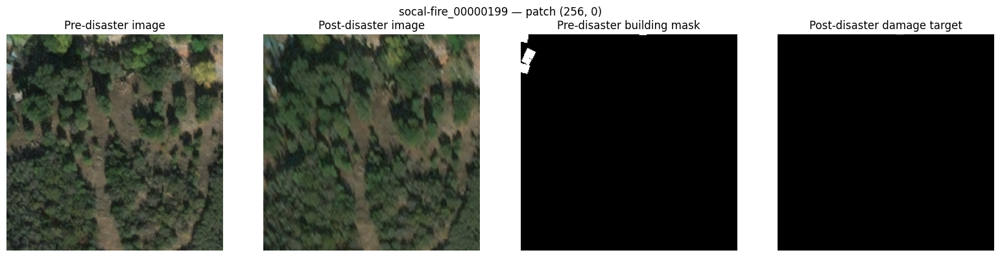

In [90]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

idx = 2511
scene_idx, y, x = val_dataset_balanced.samples[idx]
row = val_dataset_balanced.df.iloc[scene_idx]

def read_patch(path):
    with Image.open(path) as img:
        return np.array(img.crop((x, y, x + 256, y + 256)))

pre_image = read_patch(row["pre_image"])
post_image = read_patch(row["post_image"])
pre_mask = read_patch(row["pre_mask"])
post_mask = read_patch(row["post_mask"])

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(pre_image)
axes[0].set_title("Pre-disaster image")

axes[1].imshow(post_image)
axes[1].set_title("Post-disaster image")

axes[2].imshow(pre_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Pre-disaster building mask")

axes[3].imshow(post_mask, cmap="gray", vmin=0, vmax=4)
axes[3].set_title("Post-disaster damage target")

for ax in axes:
    ax.axis("off")

plt.suptitle("socal-fire_00000199 — patch (256, 0)")
plt.tight_layout()
plt.show()

In [91]:
import json
from shapely.geometry import box, shape
from shapely import wkt

scene_id = "socal-fire_00000199"
json_path = (
    f"/content/drive/MyDrive/T229/data/train/labels/"
    f"{scene_id}_post_disaster.json"
)

with open(json_path, "r") as f:
    data = json.load(f)

# Patch coordinates in the original 1024x1024 image
patch_box = box(0, 256, 256, 512)

features = data["features"]["xy"]
intersecting = []

for feature in features:
    polygon = wkt.loads(feature["wkt"])
    if polygon.intersects(patch_box):
        props = feature.get("properties", {})
        intersecting.append({
            "uid": props.get("uid"),
            "subtype": props.get("subtype"),
            "intersection_area": round(
                polygon.intersection(patch_box).area, 2
            )
        })

print("Post-disaster building annotations intersecting patch:",
      len(intersecting))
for item in intersecting[:20]:
    print(item)

Post-disaster building annotations intersecting patch: 5
{'uid': '91ef41b9-ba5b-4b41-b7f1-68b2504e7dcf', 'subtype': 'un-classified', 'intersection_area': 79.77}
{'uid': '0e2588d0-37f0-470f-9b15-c3cb6229546a', 'subtype': 'no-damage', 'intersection_area': 0.13}
{'uid': '4f2d5b5a-5b59-419f-92af-5a0bf64e0cc1', 'subtype': 'un-classified', 'intersection_area': 90.34}
{'uid': 'c716b1c7-4171-4331-bce2-35690199b68e', 'subtype': 'un-classified', 'intersection_area': 66.48}
{'uid': 'f4ac8d0f-8c73-4623-8fbd-dd49e1b8c09b', 'subtype': 'un-classified', 'intersection_area': 66.92}


In [92]:
import json
import glob
from collections import Counter

label_files = glob.glob(
    "/content/drive/MyDrive/T229/data/train/labels/*_post_disaster.json"
)

subtype_counts = Counter()
total_buildings = 0

for path in label_files:
    with open(path, "r") as f:
        data = json.load(f)

    features = data["features"]["xy"]

    for feature in features:
        subtype = feature.get("properties", {}).get(
            "subtype", "missing"
        )
        subtype_counts[subtype] += 1
        total_buildings += 1

print("Post-disaster label files:", len(label_files))
print("Total building annotations:", f"{total_buildings:,}")

print("\nSubtype distribution:")
for subtype, count in subtype_counts.most_common():
    print(
        f"{subtype}: {count:,} "
        f"({count / total_buildings:.2%})"
    )

Post-disaster label files: 2799
Total building annotations: 162,787

Subtype distribution:
no-damage: 117,426 (72.13%)
minor-damage: 14,980 (9.20%)
major-damage: 14,161 (8.70%)
destroyed: 13,227 (8.13%)
un-classified: 2,993 (1.84%)


In [93]:
import json
import numpy as np
from PIL import Image

scene_id = "socal-fire_00000199"

json_path = (
    f"/content/drive/MyDrive/T229/data/train/labels/"
    f"{scene_id}_post_disaster.json"
)
mask_path = (
    f"/content/drive/MyDrive/T229/data/train/targets/"
    f"{scene_id}_post_disaster_target.png"
)

with open(json_path, "r") as f:
    data = json.load(f)

with Image.open(mask_path) as img:
    mask = np.array(img)

print("Target mask shape:", mask.shape)
print("Target mask values and counts:")

values, counts = np.unique(mask, return_counts=True)
for value, count in zip(values, counts):
    print(f"Value {int(value)}: {int(count):,} pixels")

print("\nUn-classified building annotations:")
for feature in data["features"]["xy"]:
    subtype = feature.get("properties", {}).get("subtype")
    if subtype == "un-classified":
        print("UID:", feature.get("properties", {}).get("uid"))
        print("WKT:", feature.get("wkt"))

Target mask shape: (1024, 1024)
Target mask values and counts:
Value 0: 1,044,791 pixels
Value 1: 3,785 pixels

Un-classified building annotations:
UID: 91ef41b9-ba5b-4b41-b7f1-68b2504e7dcf
WKT: POLYGON ((-8.580359487254639e-07 290.3076954501882, 9.865860437753485 293.4340540120992, 7.325694106263064 301.8361426457728, -8.557471747069312e-07 299.6867711328695, -8.580359487254639e-07 290.3076954501882))
UID: 4f2d5b5a-5b59-419f-92af-5a0bf64e0cc1
WKT: POLYGON ((4.172525157024933 280.0869279947374, 8.324266188862362 272.1167466064377, 17.36614046582869 277.0249483217107, 13.07936892236834 284.7070002232302, 4.172525157024933 280.0869279947374))
UID: b7cc703c-1505-49d3-b832-a6fb3664be62
WKT: POLYGON ((93.92082611257761 121.7134052377399, 108.1356064888544 122.1042000593774, 107.3874601546864 141.4145920800428, 93.42206188962938 140.9158278555689, 93.92082611257761 121.7134052377399))
UID: d359b25a-d362-4c4e-92b6-ade80234ea6e
WKT: POLYGON ((72.86315193102122 151.1319805322586, 108.0260297071

In [94]:
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_focal_dice_calibrated.pth"
)

saved_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Model:", saved_checkpoint["model_name"])
print("Loss:", saved_checkpoint["loss"])
print("Class weights:", saved_checkpoint["class_weights"])
print("Focal gamma:", saved_checkpoint["focal_gamma"])
print("Dice weight:", saved_checkpoint["dice_weight"])
print("Validation macro-F1:", saved_checkpoint["validation_macro_f1"])
print("Validation macro-IoU:", saved_checkpoint["validation_macro_iou"])

Model: SiameseUNet
Loss: FocalDiceLoss
Class weights: [0.15, 1.0, 4.0, 4.0, 4.0]
Focal gamma: 2.0
Dice weight: 0.5
Validation macro-F1: 0.4324
Validation macro-IoU: 0.3317


In [95]:
import json
import numpy as np
from PIL import Image
from shapely import wkt
from shapely.geometry import box
from shapely.prepared import prep

scene_id = "socal-fire_00000199"

json_path = (
    f"/content/drive/MyDrive/T229/data/train/labels/"
    f"{scene_id}_post_disaster.json"
)
mask_path = (
    f"/content/drive/MyDrive/T229/data/train/targets/"
    f"{scene_id}_post_disaster_target.png"
)

with open(json_path, "r") as f:
    data = json.load(f)

with Image.open(mask_path) as img:
    mask = np.array(img)

height, width = mask.shape
unclassified_polygons = []

for feature in data["features"]["xy"]:
    props = feature.get("properties", {})
    if props.get("subtype") == "un-classified":
        unclassified_polygons.append(wkt.loads(feature["wkt"]))

# Count pixel centers inside un-classified polygons
yy, xx = np.mgrid[0:height, 0:width]
centers = np.column_stack((xx.ravel() + 0.5, yy.ravel() + 0.5))

unclassified_pixels = np.zeros((height, width), dtype=bool)

for polygon in unclassified_polygons:
    clipped = polygon.intersection(box(0, 0, width, height))
    if clipped.is_empty:
        continue
    prepared = prep(clipped)
    inside = np.fromiter(
        (prepared.contains(__import__("shapely").geometry.Point(x, y))
         for x, y in centers),
        dtype=bool,
        count=len(centers)
    ).reshape(height, width)
    unclassified_pixels |= inside

print("Un-classified polygon pixel centers:", int(unclassified_pixels.sum()))
print("Those pixels labeled background (0):",
      int(((mask == 0) & unclassified_pixels).sum()))
print("Those pixels labeled as damage (1-4):",
      int(((mask > 0) & unclassified_pixels).sum()))

Un-classified polygon pixel centers: 1922
Those pixels labeled background (0): 1922
Those pixels labeled as damage (1-4): 0


In [96]:
import json
import random
import numpy as np
from pathlib import Path
from PIL import Image
from shapely import wkt
from shapely.geometry import box, Point
from shapely.prepared import prep

labels_dir = Path("/content/drive/MyDrive/T229/data/train/labels")
targets_dir = Path("/content/drive/MyDrive/T229/data/train/targets")

json_files = sorted(labels_dir.glob("*_post_disaster.json"))
random.seed(42)
sample_files = random.sample(json_files, min(20, len(json_files)))

total_unclassified = 0
total_background = 0
total_damage = 0
scenes_checked = 0

for json_path in sample_files:
    scene_id = json_path.name.replace("_post_disaster.json", "")
    mask_path = targets_dir / f"{scene_id}_post_disaster_target.png"

    if not mask_path.exists():
        continue

    with open(json_path, "r") as f:
        data = json.load(f)

    with Image.open(mask_path) as img:
        mask = np.array(img)

    h, w = mask.shape
    scene_unclassified = np.zeros((h, w), dtype=bool)

    for feature in data["features"]["xy"]:
        if feature.get("properties", {}).get("subtype") != "un-classified":
            continue

        polygon = wkt.loads(feature["wkt"]).intersection(box(0, 0, w, h))
        if polygon.is_empty:
            continue

        minx, miny, maxx, maxy = polygon.bounds
        x0, x1 = max(0, int(minx)), min(w, int(np.ceil(maxx)))
        y0, y1 = max(0, int(miny)), min(h, int(np.ceil(maxy)))

        prepared = prep(polygon)

        for y in range(y0, y1):
            for x in range(x0, x1):
                if prepared.contains(Point(x + 0.5, y + 0.5)):
                    scene_unclassified[y, x] = True

    count = int(scene_unclassified.sum())
    if count == 0:
        continue

    background = int(((mask == 0) & scene_unclassified).sum())
    damage = int(((mask > 0) & scene_unclassified).sum())

    total_unclassified += count
    total_background += background
    total_damage += damage
    scenes_checked += 1

print("Scenes checked:", scenes_checked)
print("Un-classified polygon pixels:", total_unclassified)
print("Labeled background (0):", total_background)
print("Labeled damage (1-4):", total_damage)

if total_unclassified:
    print(
        "Percentage labeled background:",
        round(100 * total_background / total_unclassified, 2), "%"
    )

Scenes checked: 6
Un-classified polygon pixels: 6242
Labeled background (0): 6242
Labeled damage (1-4): 0
Percentage labeled background: 100.0 %


In [97]:
import inspect

print(inspect.getsource(XBDPatchDatasetBalanced.__getitem__))

    def __getitem__(self, index):
        scene_idx, y, x = self.samples[index]
        row = self.df.iloc[scene_idx]
        size = self.patch_size

        pre = np.array(Image.open(row["pre_image"]).convert("RGB"))
        post = np.array(Image.open(row["post_image"]).convert("RGB"))
        mask = np.array(Image.open(row["post_mask"]))

        pre = torch.from_numpy(
            pre[y:y+size, x:x+size].copy()
        ).permute(2, 0, 1).float() / 255.0

        post = torch.from_numpy(
            post[y:y+size, x:x+size].copy()
        ).permute(2, 0, 1).float() / 255.0

        mask = torch.from_numpy(
            mask[y:y+size, x:x+size].copy()
        ).long()

        return pre, post, mask



In [98]:
import inspect

print("Current criterion type:", type(criterion).__name__)
print("Current criterion details:", criterion)

if isinstance(criterion, torch.nn.Module):
    print("\nLoss configuration:")
    print("ignore_index:", getattr(criterion, "ignore_index", "Not configured"))
    print("weight:", getattr(criterion, "weight", None))

Current criterion type: CrossEntropyLoss
Current criterion details: CrossEntropyLoss()

Loss configuration:
ignore_index: -100
weight: tensor([0.1500, 1.0000, 4.0000, 4.0000, 4.0000])


In [99]:
print("Dataset class:", type(train_dataset_cached.base).__name__)
print("Dataset has scene dataframe:", hasattr(train_dataset_cached.base, "df"))
print("Dataset has samples:", hasattr(train_dataset_cached.base, "samples"))

if hasattr(train_dataset_cached.base, "df"):
    print("\nDataset columns:")
    print(train_dataset_cached.base.df.columns.tolist())

    print("\nFirst scene paths:")
    print(train_dataset_cached.base.df.iloc[0].to_dict())

Dataset class: XBDPatchDatasetBalanced
Dataset has scene dataframe: True
Dataset has samples: True

Dataset columns:
['scene_id', 'split', 'pre_image', 'post_image', 'pre_mask', 'post_mask']

First scene paths:
{'scene_id': 'hurricane-florence_00000365', 'split': 'train', 'pre_image': '/content/drive/MyDrive/T229/data/train/images/hurricane-florence_00000365_pre_disaster.png', 'post_image': '/content/drive/MyDrive/T229/data/train/images/hurricane-florence_00000365_post_disaster.png', 'pre_mask': '/content/drive/MyDrive/T229/data/train/targets/hurricane-florence_00000365_pre_disaster_target.png', 'post_mask': '/content/drive/MyDrive/T229/data/train/targets/hurricane-florence_00000365_post_disaster_target.png'}


In [100]:
import json
from pathlib import Path

dataset = train_dataset_cached.base
labels_dir = Path("/content/drive/MyDrive/T229/data/train/labels")

sample_scenes = dataset.df[
    dataset.df["split"] == "train"
].head(10)

for _, row in sample_scenes.iterrows():
    scene_id = row["scene_id"]
    json_path = labels_dir / f"{scene_id}_post_disaster.json"

    if not json_path.exists():
        print(f"{scene_id}: JSON MISSING")
        continue

    with open(json_path, "r") as f:
        data = json.load(f)

    features = data["features"]["xy"]
    unclassified = sum(
        feature.get("properties", {}).get("subtype") == "un-classified"
        for feature in features
    )

    print(
        f"{scene_id}: "
        f"{len(features)} total polygons, "
        f"{unclassified} un-classified"
    )

hurricane-florence_00000365: 8 total polygons, 0 un-classified
hurricane-harvey_00000437: 212 total polygons, 0 un-classified
santa-rosa-wildfire_00000114: 31 total polygons, 1 un-classified
midwest-flooding_00000205: 24 total polygons, 0 un-classified
hurricane-florence_00000486: 1 total polygons, 0 un-classified
hurricane-florence_00000060: 14 total polygons, 1 un-classified
socal-fire_00001063: 3 total polygons, 0 un-classified
socal-fire_00000528: 0 total polygons, 0 un-classified
socal-fire_00000059: 2 total polygons, 0 un-classified
socal-fire_00000239: 107 total polygons, 0 un-classified


In [101]:
for package in ["rasterio", "shapely", "cv2"]:
    try:
        module = __import__(package)
        print(f"{package}: available", getattr(module, "__version__", ""))
    except ImportError:
        print(f"{package}: not installed")

rasterio: available 1.5.2
shapely: available 2.2.0
cv2: available 4.14.0


In [102]:
import json
import numpy as np
import rasterio.features
from pathlib import Path
from PIL import Image
from shapely import wkt
from rasterio.transform import Affine

scene_id = "socal-fire_00000199"
root = Path("/content/drive/MyDrive/T229/data/train")

json_path = root / "labels" / f"{scene_id}_post_disaster.json"
mask_path = root / "targets" / f"{scene_id}_post_disaster_target.png"

with open(json_path, "r") as f:
    data = json.load(f)

with Image.open(mask_path) as img:
    target = np.array(img)

shapes = [
    (wkt.loads(feature["wkt"]), 1)
    for feature in data["features"]["xy"]
    if feature.get("properties", {}).get("subtype") == "un-classified"
]

ignore_mask = rasterio.features.rasterize(
    shapes,
    out_shape=target.shape,
    transform=Affine.identity(),
    fill=0,
    dtype="uint8",
    all_touched=False
).astype(bool)

print("Ignore-mask pixels:", int(ignore_mask.sum()))
print("Ignore pixels with target 0:", int(((target == 0) & ignore_mask).sum()))
print("Ignore pixels with target 1-4:", int(((target > 0) & ignore_mask).sum()))
print("Original target values:", np.unique(target).tolist())

Ignore-mask pixels: 1922
Ignore pixels with target 0: 1922
Ignore pixels with target 1-4: 0
Original target values: [0, 1]


In [103]:
scene_id = "socal-fire_00000199"

for name, loader in [
    ("train", train_loader_cached),
    ("validation", val_loader_cached),
]:
    df = loader.dataset.base.df
    matches = df[df["scene_id"] == scene_id]

    if len(matches):
        print(f"{scene_id} found in {name} split")
    else:
        print(f"{scene_id} not found in {name} split")

socal-fire_00000199 not found in train split
socal-fire_00000199 found in validation split


In [104]:
dataset = train_loader_cached.dataset.base

row = dataset.df.iloc[0]
_, _, cached_mask = train_loader_cached.dataset.cache.get(row)

import numpy as np

print("Training scene:", row["scene_id"])
print("Mask shape:", cached_mask.shape)
print("Mask values and counts:", np.unique(cached_mask, return_counts=True))

Training scene: hurricane-florence_00000365
Mask shape: (1024, 1024)
Mask values and counts: (array([0, 1, 2], dtype=uint8), array([1043012,    4968,     596]))


In [105]:
import json
from pathlib import Path

scene_id = "hurricane-florence_00000365"
json_path = Path(
    f"/content/drive/MyDrive/T229/data/train/labels/"
    f"{scene_id}_post_disaster.json"
)

with open(json_path, "r") as f:
    data = json.load(f)

features = data["features"]["xy"]
unclassified = [
    feature for feature in features
    if feature.get("properties", {}).get("subtype") == "un-classified"
]

print("Scene:", scene_id)
print("Total polygons:", len(features))
print("Un-classified polygons:", len(unclassified))

Scene: hurricane-florence_00000365
Total polygons: 8
Un-classified polygons: 0


In [106]:
import json
from pathlib import Path

labels_dir = Path("/content/drive/MyDrive/T229/data/train/labels")
train_df = train_loader_cached.dataset.base.df

for scene_id in train_df["scene_id"]:
    json_path = labels_dir / f"{scene_id}_post_disaster.json"

    if not json_path.exists():
        continue

    with open(json_path, "r") as f:
        data = json.load(f)

    count = sum(
        feature.get("properties", {}).get("subtype") == "un-classified"
        for feature in data["features"]["xy"]
    )

    if count:
        print("Training scene:", scene_id)
        print("Un-classified polygons:", count)
        break
else:
    print("No training scenes with un-classified polygons found.")

Training scene: santa-rosa-wildfire_00000114
Un-classified polygons: 1


In [107]:
import json
import numpy as np
import rasterio.features
from pathlib import Path
from PIL import Image
from shapely import wkt
from rasterio.transform import Affine

scene_id = "santa-rosa-wildfire_00000114"
root = Path("/content/drive/MyDrive/T229/data/train")

json_path = root / "labels" / f"{scene_id}_post_disaster.json"
mask_path = root / "targets" / f"{scene_id}_post_disaster_target.png"

with open(json_path, "r") as f:
    data = json.load(f)

with Image.open(mask_path) as img:
    target = np.array(img)

shapes = [
    (wkt.loads(feature["wkt"]), 1)
    for feature in data["features"]["xy"]
    if feature.get("properties", {}).get("subtype") == "un-classified"
]

ignore_mask = rasterio.features.rasterize(
    shapes,
    out_shape=target.shape,
    transform=Affine.identity(),
    fill=0,
    dtype="uint8",
    all_touched=False
).astype(bool)

print("Scene:", scene_id)
print("Un-classified polygons:", len(shapes))
print("Pixels marked for ignoring:", int(ignore_mask.sum()))
print("Those pixels labeled background (0):",
      int(((target == 0) & ignore_mask).sum()))
print("Those pixels labeled damage (1-4):",
      int(((target > 0) & ignore_mask).sum()))

Scene: santa-rosa-wildfire_00000114
Un-classified polygons: 1
Pixels marked for ignoring: 185
Those pixels labeled background (0): 185
Those pixels labeled damage (1-4): 0


In [108]:
import numpy as np
import torch

target_with_ignore = torch.from_numpy(target.copy()).long()
target_with_ignore[ignore_mask] = -100

print("Original mask unchanged:", np.array_equal(target, np.array(Image.open(mask_path))))
print("Ignore labels added:", int((target_with_ignore == -100).sum()))
print("Valid target labels:", torch.unique(target_with_ignore[target_with_ignore != -100]).tolist())

Original mask unchanged: True
Ignore labels added: 185
Valid target labels: [0, 1, 2, 3, 4]


In [109]:
print("Batch size:", train_loader_cached.batch_size)
print("Workers:", train_loader_cached.num_workers)
print("Sampler:", type(train_loader_cached.sampler).__name__)
print("Dataset patches:", len(train_loader_cached.dataset))
print("Validation loader unchanged:", len(val_loader_cached.dataset))

Batch size: 4
Workers: 0
Sampler: RandomSampler
Dataset patches: 17269
Validation loader unchanged: 3613


In [110]:
import json
import numpy as np
import rasterio.features
import torch

from pathlib import Path
from PIL import Image
from shapely import wkt
from rasterio.transform import Affine
from torch.utils.data import Dataset, DataLoader


class IgnoreUnclassifiedDataset(Dataset):
    def __init__(self, base_dataset):
        self.base = base_dataset
        self.patch_size = base_dataset.patch_size
        self.df = base_dataset.df
        self.samples = base_dataset.samples
        self.cache = {}

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        scene_idx, y, x = self.samples[index]
        row = self.df.iloc[scene_idx]
        scene_id = row["scene_id"]

        if scene_id not in self.cache:
            pre = np.array(Image.open(row["pre_image"]).convert("RGB"))
            post = np.array(Image.open(row["post_image"]).convert("RGB"))
            mask = np.array(Image.open(row["post_mask"]))

            json_path = (
                Path("/content/drive/MyDrive/T229/data/train/labels")
                / f"{scene_id}_post_disaster.json"
            )

            with open(json_path, "r") as f:
                annotation = json.load(f)

            shapes = [
                (wkt.loads(feature["wkt"]), 1)
                for feature in annotation["features"]["xy"]
                if feature.get("properties", {}).get("subtype")
                == "un-classified"
            ]

            if shapes:
                ignore_mask = rasterio.features.rasterize(
                    shapes,
                    out_shape=mask.shape,
                    transform=Affine.identity(),
                    fill=0,
                    dtype="uint8",
                    all_touched=False,
                ).astype(bool)

                mask = mask.astype(np.int64)
                mask[ignore_mask] = -100

            self.cache[scene_id] = (pre, post, mask)

            if len(self.cache) > 4:
                self.cache.pop(next(iter(self.cache)))

        pre_img, post_img, full_mask = self.cache[scene_id]
        size = self.patch_size

        pre_patch = torch.from_numpy(
            pre_img[y:y+size, x:x+size].copy()
        ).permute(2, 0, 1).float() / 255.0

        post_patch = torch.from_numpy(
            post_img[y:y+size, x:x+size].copy()
        ).permute(2, 0, 1).float() / 255.0

        target_patch = torch.from_numpy(
            full_mask[y:y+size, x:x+size].copy()
        ).long()

        return pre_patch, post_patch, target_patch


train_dataset_ignore = IgnoreUnclassifiedDataset(
    train_loader_cached.dataset.base
)

train_loader_ignore = DataLoader(
    train_dataset_ignore,
    batch_size=train_loader_cached.batch_size,
    shuffle=True,
    num_workers=0
)

print("New training patches:", len(train_dataset_ignore))
print("New training batches:", len(train_loader_ignore))
print("Original training loader preserved:", len(train_loader_cached.dataset))
print("Validation loader preserved:", len(val_loader_cached.dataset))

New training patches: 17269
New training batches: 4318
Original training loader preserved: 17269
Validation loader preserved: 3613


In [111]:
pre, post, masks = next(iter(train_loader_ignore))

print("Pre-image shape:", pre.shape)
print("Post-image shape:", post.shape)
print("Target shape:", masks.shape)
print("Target values:", torch.unique(masks).tolist())
print("Ignored pixels in batch:", int((masks == -100).sum()))
print("Valid target values:",
      torch.unique(masks[masks != -100]).tolist())

Pre-image shape: torch.Size([4, 3, 256, 256])
Post-image shape: torch.Size([4, 3, 256, 256])
Target shape: torch.Size([4, 256, 256])
Target values: [0, 1, 3]
Ignored pixels in batch: 0
Valid target values: [0, 1, 3]


In [112]:
scene_id = "santa-rosa-wildfire_00000114"

scene_idx = train_dataset_ignore.df.index[
    train_dataset_ignore.df["scene_id"] == scene_id
].tolist()[0]

matching_patches = [
    (i, sample)
    for i, sample in enumerate(train_dataset_ignore.samples)
    if sample[0] == scene_idx
]

print("Scene index:", scene_idx)
print("Patches available:", len(matching_patches))

for i, sample in matching_patches:
    _, y, x = sample
    if y == 0 and x == 0:
        _, _, target_patch = train_dataset_ignore[i]
        print("Patch coordinates:", (y, x))
        print("Ignored pixels:", int((target_patch == -100).sum()))
        print("Target values:", torch.unique(target_patch).tolist())
        break
else:
    print("The (0, 0) patch is not in the dataset sample list.")

Scene index: 2
Patches available: 15
Patch coordinates: (0, 0)
Ignored pixels: 0
Target values: [0, 1, 4]


In [113]:
scene_id = "santa-rosa-wildfire_00000114"

scene_idx = train_dataset_ignore.df.index[
    train_dataset_ignore.df["scene_id"] == scene_id
].tolist()[0]

total_ignored = 0
patches_with_ignored = []

for i, (sample_scene_idx, y, x) in enumerate(train_dataset_ignore.samples):
    if sample_scene_idx != scene_idx:
        continue

    _, _, target_patch = train_dataset_ignore[i]
    ignored = int((target_patch == -100).sum())
    total_ignored += ignored

    if ignored > 0:
        patches_with_ignored.append({
            "dataset_index": i,
            "coordinates": (y, x),
            "ignored_pixels": ignored
        })

print("Total ignored pixels across sampled patches:", total_ignored)
print("Patches containing ignored pixels:", patches_with_ignored)

Total ignored pixels across sampled patches: 185
Patches containing ignored pixels: [{'dataset_index': 13359, 'coordinates': (0, 512), 'ignored_pixels': 185}]


In [114]:
import torch
import torch.nn as nn

test_logits = torch.randn(1, 5, 4, 4)
test_targets = torch.zeros((1, 4, 4), dtype=torch.long)
test_targets[0, 0, 0] = -100

test_criterion = nn.CrossEntropyLoss(ignore_index=-100)
test_loss = test_criterion(test_logits, test_targets)

print("Loss:", test_loss.item())
print("Loss is finite:", torch.isfinite(test_loss).item())
print("Ignore index:", test_criterion.ignore_index)

Loss: 2.2569520473480225
Loss is finite: True
Ignore index: -100


In [115]:
print("Model:", type(model).__name__)
print("Device:", next(model.parameters()).device)
print("Optimizer:", type(optimizer).__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Loss function:", type(criterion).__name__)
print("Ignore index:", getattr(criterion, "ignore_index", "Not configured"))

Model: SiameseUNet
Device: cpu
Optimizer: AdamW
Learning rate: 0.0003
Loss function: CrossEntropyLoss
Ignore index: -100


In [116]:
for i, group in enumerate(optimizer.param_groups):
    print(f"Parameter group {i}:")
    print("  Learning rate:", group["lr"])
    print("  Weight decay:", group.get("weight_decay", 0))
    print("  Parameters:", sum(p.numel() for p in group["params"]))

Parameter group 0:
  Learning rate: 0.0003
  Weight decay: 0.0001
  Parameters: 703061


In [117]:
from torch.optim import AdamW
import torch.nn as nn

# Use a conservative learning rate for fine-tuning
optimizer_ignore = AdamW(
    model.parameters(),
    lr=0.0003,
    weight_decay=0.0001
)

# Ignore un-classified pixels marked -100
criterion_ignore = nn.CrossEntropyLoss(
    weight=torch.tensor(
        [0.15, 1.0, 4.0, 4.0, 4.0],
        dtype=torch.float32,
        device=device
    ),
    ignore_index=-100
)

print("Learning rate:", optimizer_ignore.param_groups[0]["lr"])
print("Weight decay:", optimizer_ignore.param_groups[0]["weight_decay"])
print("Loss function:", type(criterion_ignore).__name__)
print("Ignore index:", criterion_ignore.ignore_index)
print("Model parameters:", sum(p.numel() for p in model.parameters()))

Learning rate: 0.0003
Weight decay: 0.0001
Loss function: CrossEntropyLoss
Ignore index: -100
Model parameters: 703061


In [118]:
model.train()
optimizer_ignore.zero_grad(set_to_none=True)

pre, post, targets = next(iter(train_loader_ignore))

pre = pre.to(device)
post = post.to(device)
targets = targets.to(device)

logits = model(pre, post)
loss = criterion_ignore(logits, targets)

print("Logits shape:", tuple(logits.shape))
print("Target shape:", tuple(targets.shape))
print("Loss:", loss.item())
print("Loss finite:", torch.isfinite(loss).item())

if torch.isfinite(loss):
    loss.backward()

    grad_norm = torch.nn.utils.clip_grad_norm_(
        model.parameters(), max_norm=1.0
    )

    print("Gradient norm:", grad_norm.item())
    print("Gradient norm finite:", torch.isfinite(grad_norm).item())
else:
    print("Backward pass skipped because loss is not finite.")

optimizer_ignore.zero_grad(set_to_none=True)

Logits shape: (4, 5, 256, 256)
Target shape: (4, 256, 256)
Loss: 1.5504355430603027
Loss finite: True
Gradient norm: 2.132249355316162
Gradient norm finite: True


In [119]:
import time
import torch

model.train()
losses = []
start_time = time.time()

for batch_idx, (pre, post, targets) in enumerate(train_loader_ignore):
    if batch_idx >= 20:
        break

    pre = pre.to(device)
    post = post.to(device)
    targets = targets.to(device)

    optimizer_ignore.zero_grad(set_to_none=True)

    logits = model(pre, post)
    loss = criterion_ignore(logits, targets)

    if not torch.isfinite(loss):
        print(f"Stopped: non-finite loss at batch {batch_idx + 1}")
        break

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer_ignore.step()

    losses.append(loss.item())

    if (batch_idx + 1) % 5 == 0:
        print(
            f"Batch {batch_idx + 1}/20 | "
            f"Loss: {loss.item():.4f} | "
            f"Average loss: {sum(losses)/len(losses):.4f}"
        )

print(f"\nBatches completed: {len(losses)}")
if losses:
    print(f"Average training loss: {sum(losses)/len(losses):.4f}")
print(f"Elapsed minutes: {(time.time()-start_time)/60:.2f}")

Batch 5/20 | Loss: 1.3328 | Average loss: 1.4057
Batch 10/20 | Loss: 1.4386 | Average loss: 1.4023
Batch 15/20 | Loss: 1.5690 | Average loss: 1.4055
Batch 20/20 | Loss: 1.5382 | Average loss: 1.4125

Batches completed: 20
Average training loss: 1.4125
Elapsed minutes: 1.55


In [120]:
import torch
import numpy as np
from sklearn.metrics import f1_score

model.eval()

all_true = []
all_pred = []
val_losses = []

with torch.no_grad():
    for batch_idx, (pre, post, targets) in enumerate(val_loader_cached):
        if batch_idx >= 20:
            break

        pre = pre.to(device)
        post = post.to(device)
        targets = targets.to(device)

        logits = model(pre, post)
        loss = criterion(logits, targets)
        predictions = logits.argmax(dim=1)

        valid = targets != -100
        all_true.extend(targets[valid].cpu().numpy())
        all_pred.extend(predictions[valid].cpu().numpy())
        val_losses.append(loss.item())

y_true = np.asarray(all_true)
y_pred = np.asarray(all_pred)

print("Validation batches:", len(val_losses))
print("Average validation loss:", round(float(np.mean(val_losses)), 4))
print("Pixel accuracy:", round(float((y_true == y_pred).mean()), 4))
print("Macro F1 (classes 1–4):",
      round(f1_score(y_true, y_pred, labels=[1, 2, 3, 4],
                     average="macro", zero_division=0), 4))
print("F1 by class (1–4):",
      np.round(f1_score(y_true, y_pred, labels=[1, 2, 3, 4],
                        average=None, zero_division=0), 4).tolist())

Validation batches: 20
Average validation loss: 1.3435
Pixel accuracy: 0.6859
Macro F1 (classes 1–4): 0.1081
F1 by class (1–4): [0.4049, 0.0, 0.0276, 0.0]


In [121]:
import numpy as np

print("Actual pixel distribution:")
actual_ids, actual_counts = np.unique(y_true, return_counts=True)
for class_id, count in zip(actual_ids, actual_counts):
    print(f"  Class {class_id}: {count:,} ({count / len(y_true):.2%})")

print("\nPredicted pixel distribution:")
pred_ids, pred_counts = np.unique(y_pred, return_counts=True)
for class_id, count in zip(pred_ids, pred_counts):
    print(f"  Class {class_id}: {count:,} ({count / len(y_pred):.2%})")

Actual pixel distribution:
  Class 0: 4,732,056 (90.26%)
  Class 1: 393,532 (7.51%)
  Class 2: 42,436 (0.81%)
  Class 3: 56,757 (1.08%)
  Class 4: 18,099 (0.35%)

Predicted pixel distribution:
  Class 0: 3,336,378 (63.64%)
  Class 1: 1,174,328 (22.40%)
  Class 3: 731,242 (13.95%)
  Class 4: 932 (0.02%)


In [122]:
from sklearn.metrics import confusion_matrix
import pandas as pd

class_names = [
    "Background",
    "No damage",
    "Minor damage",
    "Major damage",
    "Destroyed"
]

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4])

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual: {name}" for name in class_names],
    columns=[f"Pred: {name}" for name in class_names]
)

display(cm_df)

,Pred: Background,Pred: No damage,Pred: Minor damage,Pred: Major damage,Pred: Destroyed
Actual: Background,3267665,785930,0,677678,783
Actual: No damage,45529,317445,0,30426,132
Actual: Minor damage,9777,22055,0,10604,0
Actual: Major damage,12484,33381,0,10875,17
Actual: Destroyed,923,15517,0,1659,0


In [123]:
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_focal_dice_calibrated.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Restored checkpoint:", checkpoint["model_name"])
print("Saved validation macro-F1:", checkpoint["validation_macro_f1"])
print("Saved validation macro-IoU:", checkpoint["validation_macro_iou"])
print("Calibration boosts:", checkpoint["calibration_logit_boosts"])
print("Model restored successfully:", True)

Restored checkpoint: SiameseUNet
Saved validation macro-F1: 0.4324
Saved validation macro-IoU: 0.3317
Calibration boosts: {'minor_damage': 0.2, 'major_damage': 0.4}
Model restored successfully: True


In [124]:
import torch
import numpy as np
from sklearn.metrics import f1_score

model.eval()

pre, post, targets = next(iter(val_loader_cached))
pre = pre.to(device)
post = post.to(device)
targets = targets.to(device)

with torch.no_grad():
    logits = model(pre, post)
    logits[:, 2] += 0.2  # Minor damage
    logits[:, 3] += 0.4  # Major damage
    predictions = logits.argmax(dim=1)

valid = targets != -100
y_true_batch = targets[valid].cpu().numpy()
y_pred_batch = predictions[valid].cpu().numpy()

print("Validation batch pixel accuracy:",
      round(float((y_true_batch == y_pred_batch).mean()), 4))
print("F1 by class [background, no damage, minor, major, destroyed]:",
      np.round(
          f1_score(
              y_true_batch,
              y_pred_batch,
              labels=[0, 1, 2, 3, 4],
              average=None,
              zero_division=0
          ),
          4
      ).tolist())

Validation batch pixel accuracy: 0.3
F1 by class [background, no damage, minor, major, destroyed]: [0.4557, 0.145, 0.0, 0.0, 0.0]


In [125]:
import numpy as np

print("Actual class pixel counts:")
for c in range(5):
    print(f"Class {c}: {int((y_true_batch == c).sum()):,}")

print("\nPredicted class pixel counts:")
for c in range(5):
    print(f"Class {c}: {int((y_pred_batch == c).sum()):,}")

Actual class pixel counts:
Class 0: 249,856
Class 1: 12,288
Class 2: 0
Class 3: 0
Class 4: 0

Predicted class pixel counts:
Class 0: 76,275
Class 1: 47,210
Class 2: 12,455
Class 3: 126,204
Class 4: 0


In [126]:
import torch
import numpy as np

model.eval()
found = False

with torch.no_grad():
    for batch_idx, (pre, post, targets) in enumerate(val_loader_cached):
        targets = targets.to(device)

        if (targets == 2).any() or (targets == 3).any() or (targets == 4).any():
            pre = pre.to(device)
            post = post.to(device)

            logits = model(pre, post)
            logits[:, 2] += 0.2
            logits[:, 3] += 0.4
            predictions = logits.argmax(dim=1)

            print("Validation batch index:", batch_idx)
            print("Actual counts:",
                  torch.bincount(targets.flatten(), minlength=5).cpu().tolist())
            print("Predicted counts:",
                  torch.bincount(predictions.flatten(), minlength=5).cpu().tolist())

            found = True
            break

if not found:
    print("No batch with damage classes found.")

Validation batch index: 1
Actual counts: [244789, 2777, 9184, 5394, 0]
Predicted counts: [53988, 30013, 10029, 168099, 15]


In [127]:
model.eval()

with torch.no_grad():
    logits = model(pre, post)

    predictions_raw = logits.argmax(dim=1)

    logits_calibrated = logits.clone()
    logits_calibrated[:, 2] += 0.2
    logits_calibrated[:, 3] += 0.4
    predictions_calibrated = logits_calibrated.argmax(dim=1)

print("Actual counts:",
      torch.bincount(targets.flatten(), minlength=5).cpu().tolist())

print("Without calibration:",
      torch.bincount(predictions_raw.flatten(), minlength=5).cpu().tolist())

print("With calibration:",
      torch.bincount(predictions_calibrated.flatten(), minlength=5).cpu().tolist())

Actual counts: [244789, 2777, 9184, 5394, 0]
Without calibration: [84138, 70517, 10393, 97053, 43]
With calibration: [53988, 30013, 10029, 168099, 15]


In [128]:
from sklearn.metrics import f1_score
import numpy as np

y_actual = targets.flatten().cpu().numpy()
y_raw = predictions_raw.flatten().cpu().numpy()
y_cal = predictions_calibrated.flatten().cpu().numpy()

labels = [0, 1, 2, 3, 4]
names = ["Background", "No damage", "Minor", "Major", "Destroyed"]

f1_raw = f1_score(y_actual, y_raw, labels=labels,
                  average=None, zero_division=0)
f1_cal = f1_score(y_actual, y_cal, labels=labels,
                  average=None, zero_division=0)

print("Class              Raw F1    Calibrated F1")
for name, raw, cal in zip(names, f1_raw, f1_cal):
    print(f"{name:18s} {raw:.4f}    {cal:.4f}")

print("\nRaw macro-F1 (damage classes):",
      round(float(np.mean(f1_raw[1:])), 4))
print("Calibrated macro-F1 (damage classes):",
      round(float(np.mean(f1_cal[1:])), 4))

Class              Raw F1    Calibrated F1
Background         0.4986    0.3556
No damage          0.0421    0.0813
Minor              0.0019    0.0021
Major              0.0635    0.0590
Destroyed          0.0000    0.0000

Raw macro-F1 (damage classes): 0.0269
Calibrated macro-F1 (damage classes): 0.0356


In [129]:
import torch
import numpy as np
from sklearn.metrics import f1_score

model.eval()

all_true = []
all_raw = []
all_cal = []

with torch.no_grad():
    for batch_idx, (pre, post, targets) in enumerate(val_loader_cached):
        if batch_idx >= 20:
            break

        pre = pre.to(device)
        post = post.to(device)
        targets = targets.to(device)

        logits = model(pre, post)

        raw_pred = logits.argmax(dim=1)

        calibrated_logits = logits.clone()
        calibrated_logits[:, 2] += 0.2
        calibrated_logits[:, 3] += 0.4
        cal_pred = calibrated_logits.argmax(dim=1)

        valid = targets != -100
        all_true.extend(targets[valid].cpu().numpy())
        all_raw.extend(raw_pred[valid].cpu().numpy())
        all_cal.extend(cal_pred[valid].cpu().numpy())

y = np.asarray(all_true)
raw = np.asarray(all_raw)
cal = np.asarray(all_cal)

labels = [1, 2, 3, 4]

print("20-batch raw damage macro-F1:",
      round(f1_score(y, raw, labels=labels,
                     average="macro", zero_division=0), 4))

print("20-batch calibrated damage macro-F1:",
      round(f1_score(y, cal, labels=labels,
                     average="macro", zero_division=0), 4))

print("Raw class F1:",
      np.round(f1_score(y, raw, labels=labels,
                        average=None, zero_division=0), 4).tolist())

print("Calibrated class F1:",
      np.round(f1_score(y, cal, labels=labels,
                        average=None, zero_division=0), 4).tolist())

20-batch raw damage macro-F1: 0.0807
20-batch calibrated damage macro-F1: 0.0816
Raw class F1: [0.2817, 0.0097, 0.0277, 0.0037]
Calibrated class F1: [0.2866, 0.0096, 0.0298, 0.0005]


Scene: hurricane-harvey_00000505
Patch coordinates (y, x): (512, 512)
Pre-footprint values/counts: {np.uint8(0): np.int64(50958), np.uint8(1): np.int64(14578)}
Post-target values/counts: {np.int64(0): np.int64(50958), np.int64(2): np.int64(9184), np.int64(3): np.int64(5394)}
Pre-footprint building pixels: 14578
Post-target labeled pixels: 14578


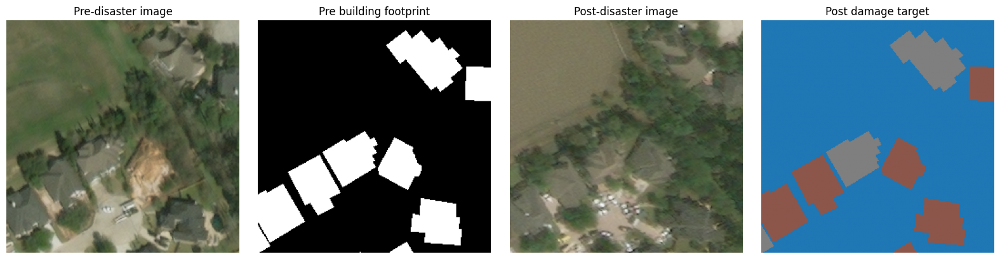

In [130]:
import numpy as np
import matplotlib.pyplot as plt

# Use the same validation patch we inspected earlier
pre, post, target = val_dataset_cached[5]

pre_np = (pre.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
post_np = (post.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
target_np = target.cpu().numpy()

# Recover the matching pre-disaster footprint mask
scene_idx, y, x = val_dataset_cached.base.samples[5]
row = val_dataset_cached.base.df.iloc[scene_idx]

from PIL import Image

with Image.open(row["pre_mask"]) as img:
    footprint_np = np.array(img.crop((x, y, x + 256, y + 256)))

print("Scene:", row["scene_id"])
print("Patch coordinates (y, x):", (y, x))
print("Pre-footprint values/counts:",
      dict(zip(*np.unique(footprint_np, return_counts=True))))
print("Post-target values/counts:",
      dict(zip(*np.unique(target_np, return_counts=True))))
print("Pre-footprint building pixels:", int((footprint_np > 0).sum()))
print("Post-target labeled pixels:", int((target_np > 0).sum()))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(pre_np)
axes[0].set_title("Pre-disaster image")
axes[1].imshow(footprint_np, cmap="gray")
axes[1].set_title("Pre building footprint")
axes[2].imshow(post_np)
axes[2].set_title("Post-disaster image")
axes[3].imshow(target_np, cmap="tab10", vmin=0, vmax=4)
axes[3].set_title("Post damage target")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [131]:
import numpy as np

footprint = footprint_np > 0
damage_labeled = target_np > 0

outside = damage_labeled & ~footprint
inside = damage_labeled & footprint

print("Damage-labeled pixels:", int(damage_labeled.sum()))
print("Damage pixels inside footprint:", int(inside.sum()))
print("Damage pixels outside footprint:", int(outside.sum()))
print("Percentage inside footprint:",
      round(100 * inside.sum() / max(damage_labeled.sum(), 1), 2), "%")

Damage-labeled pixels: 14578
Damage pixels inside footprint: 14578
Damage pixels outside footprint: 0
Percentage inside footprint: 100.0 %


In [132]:
import torch
import numpy as np
from sklearn.metrics import f1_score

model.eval()

pre_t = pre.unsqueeze(0).to(device)
post_t = post.unsqueeze(0).to(device)
target_t = target.unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(pre_t, post_t)
    logits[:, 2] += 0.2
    logits[:, 3] += 0.4

    pred_unmasked = logits.argmax(dim=1)[0].cpu().numpy()

footprint = footprint_np > 0
pred_masked = pred_unmasked.copy()
pred_masked[~footprint] = 0

y_true_patch = target_np.ravel()
y_unmasked = pred_unmasked.ravel()
y_masked = pred_masked.ravel()

print("Damage-class macro-F1 without footprint mask:",
      round(f1_score(
          y_true_patch, y_unmasked, labels=[1, 2, 3, 4],
          average="macro", zero_division=0
      ), 4))

print("Damage-class macro-F1 with footprint mask:",
      round(f1_score(
          y_true_patch, y_masked, labels=[1, 2, 3, 4],
          average="macro", zero_division=0
      ), 4))

print("Predicted class counts without mask:",
      np.bincount(y_unmasked, minlength=5).tolist())

print("Predicted class counts with mask:",
      np.bincount(y_masked, minlength=5).tolist())

Damage-class macro-F1 without footprint mask: 0.0646
Damage-class macro-F1 with footprint mask: 0.1382
Predicted class counts without mask: [28594, 1904, 174, 34864, 0]
Predicted class counts with mask: [51530, 729, 20, 13257, 0]


In [133]:
import torch
import numpy as np
from sklearn.metrics import f1_score

model.eval()

all_true = []
all_raw = []
all_masked = []

with torch.no_grad():
    for batch_idx, (pre_batch, post_batch, targets_batch) in enumerate(val_loader_cached):
        if batch_idx >= 20:
            break

        pre_batch = pre_batch.to(device)
        post_batch = post_batch.to(device)
        targets_batch = targets_batch.to(device)

        logits = model(pre_batch, post_batch)
        logits[:, 2] += 0.2
        logits[:, 3] += 0.4

        pred_raw = logits.argmax(dim=1)

        # Recover matching pre-disaster footprint masks
        footprint_batch = []
        for j in range(len(targets_batch)):
            dataset_index = batch_idx * val_loader_cached.batch_size + j
            scene_idx, y, x = val_dataset_cached.base.samples[dataset_index]
            row = val_dataset_cached.base.df.iloc[scene_idx]

            with Image.open(row["pre_mask"]) as img:
                fp = np.array(img.crop((x, y, x + 256, y + 256)))

            footprint_batch.append(fp > 0)

        footprint_tensor = torch.from_numpy(
            np.stack(footprint_batch)
        ).to(device)

        pred_masked = pred_raw.clone()
        pred_masked[~footprint_tensor] = 0

        valid = targets_batch != -100
        all_true.extend(targets_batch[valid].cpu().numpy())
        all_raw.extend(pred_raw[valid].cpu().numpy())
        all_masked.extend(pred_masked[valid].cpu().numpy())

y = np.asarray(all_true)
raw = np.asarray(all_raw)
masked = np.asarray(all_masked)

print("20-batch raw damage macro-F1:",
      round(f1_score(y, raw, labels=[1, 2, 3, 4],
                     average="macro", zero_division=0), 4))

print("20-batch footprint-masked damage macro-F1:",
      round(f1_score(y, masked, labels=[1, 2, 3, 4],
                     average="macro", zero_division=0), 4))

20-batch raw damage macro-F1: 0.0816
20-batch footprint-masked damage macro-F1: 0.1805


In [134]:
# import torch
# import numpy as np
# from PIL import Image
# from sklearn.metrics import f1_score, jaccard_score
# from tqdm.auto import tqdm

# model.eval()

# all_true_full = []
# all_raw_full = []
# all_masked_full = []

# with torch.no_grad():
#     for batch_idx, (pre_batch, post_batch, targets_batch) in enumerate(
#         tqdm(val_loader_cached, desc="Full validation")
#     ):
#         pre_batch = pre_batch.to(device)
#         post_batch = post_batch.to(device)
#         targets_batch = targets_batch.to(device)

#         logits = model(pre_batch, post_batch)
#         logits[:, 2] += 0.2
#         logits[:, 3] += 0.4

#         pred_raw = logits.argmax(dim=1)
#         pred_masked = pred_raw.clone()

#         # Build the matching footprint mask for every patch.
#         footprint_batch = []

#         start_idx = batch_idx * val_loader_cached.batch_size

#         for j in range(len(targets_batch)):
#             dataset_index = start_idx + j
#             scene_idx, y0, x0 = val_dataset_cached.base.samples[dataset_index]
#             row = val_dataset_cached.base.df.iloc[scene_idx]

#             with Image.open(row["pre_mask"]) as img:
#                 fp = np.array(
#                     img.crop((x0, y0, x0 + 256, y0 + 256))
#                 )

#             footprint_batch.append(fp > 0)

#         footprint_tensor = torch.from_numpy(
#             np.stack(footprint_batch)
#         ).to(device)

#         pred_masked[~footprint_tensor] = 0

#         valid = targets_batch != -100
#         all_true_full.append(targets_batch[valid].cpu().numpy())
#         all_raw_full.append(pred_raw[valid].cpu().numpy())
#         all_masked_full.append(pred_masked[valid].cpu().numpy())

# y_full = np.concatenate(all_true_full)
# raw_full = np.concatenate(all_raw_full)
# masked_full = np.concatenate(all_masked_full)

# for name, predictions in [
#     ("Raw", raw_full),
#     ("Footprint-masked", masked_full),
# ]:
#     macro_f1 = f1_score(
#         y_full, predictions, labels=[1, 2, 3, 4],
#         average="macro", zero_division=0
#     )
#     macro_iou = jaccard_score(
#         y_full, predictions, labels=[1, 2, 3, 4],
#         average="macro", zero_division=0
#     )

#     print(f"\n{name} predictions")
#     print("Damage-class macro-F1:", round(macro_f1, 4))
#     print("Damage-class macro-IoU:", round(macro_iou, 4))
#     print("Class F1 [no damage, minor, major, destroyed]:",
#           np.round(f1_score(
#               y_full, predictions, labels=[1, 2, 3, 4],
#               average=None, zero_division=0
#           ), 4).tolist())

In [135]:
from pathlib import Path
import pandas as pd

reports_dir = Path("/content/drive/MyDrive/T229/reports")

for filename in [
    "siamese_unet_validation_metrics.csv",
    "siamese_unet_validation_confusion_matrix.csv",
]:
    path = reports_dir / filename
    print(f"\n{filename}: {'FOUND' if path.exists() else 'NOT FOUND'}")

    if path.exists():
        display(pd.read_csv(path).head(10))


siamese_unet_validation_metrics.csv: FOUND


,class,precision,recall,f1,iou
0,background,0.9884,0.9066,0.9457,0.8971
1,no_damage,0.4323,0.6691,0.5252,0.3561
2,minor_damage,0.0995,0.2793,0.1468,0.0792
3,major_damage,0.1102,0.2492,0.1528,0.0827
4,destroyed,0.3431,0.4555,0.3914,0.2433



siamese_unet_validation_confusion_matrix.csv: FOUND


,Unnamed: 0,predicted_background,predicted_no_damage,predicted_minor_damage,predicted_major_damage,predicted_destroyed
0,actual_background,192278189,14417790,821696,3647856,918976
1,actual_no_damage,1665106,12672588,2922619,1638016,42518
2,actual_minor_damage,176843,786554,503610,322958,13307
3,actual_major_damage,216529,1173232,693298,699355,24531
4,actual_destroyed,199302,266185,118027,40430,522053


In [136]:
from pathlib import Path

root = Path("/content/drive/MyDrive/T229")

paths = [
    root / "checkpoints/siamese_unet_focal_dice_calibrated.pth",
    root / "reports/hurricane-florence_00000537_damage_heatmap.png",
    root / "reports/siamese_unet_validation_metrics.csv",
    root / "reports/siamese_unet_validation_confusion_matrix.csv",
]

for path in paths:
    print(("FOUND  " if path.exists() else "MISSING"), path.name)
    if path.exists():
        print(f"        Size: {path.stat().st_size / 1024:.1f} KB")

FOUND   siamese_unet_focal_dice_calibrated.pth
        Size: 2804.2 KB
FOUND   hurricane-florence_00000537_damage_heatmap.png
        Size: 1545.2 KB
FOUND   siamese_unet_validation_metrics.csv
        Size: 0.2 KB
FOUND   siamese_unet_validation_confusion_matrix.csv
        Size: 0.4 KB


In [137]:

from pathlib import Path
from torch.utils.data import SequentialSampler

required = ["model", "device", "val_loader_cached", "val_dataset_cached"]
missing = [name for name in required if name not in globals()]

if missing:
    print("Missing variables:", missing)
    print("Rerun the relevant setup cells before continuing.")
else:
    print("Model:", type(model).__name__)
    print("Device:", device)
    print("Validation batches:", len(val_loader_cached))
    print("Validation samples:", len(val_loader_cached.dataset))
    print("Sequential sampler:", isinstance(
        val_loader_cached.sampler, SequentialSampler
    ))
    print("Checkpoint exists:", Path(
        "/content/drive/MyDrive/T229/checkpoints/"
        "siamese_unet_focal_dice_calibrated.pth"
    ).exists())


Model: SiameseUNet
Device: cpu
Validation batches: 904
Validation samples: 3613
Sequential sampler: True
Checkpoint exists: True


In [138]:

# import os, json, time
# import numpy as np
# import pandas as pd
# import torch
# from PIL import Image
# from tqdm.auto import tqdm
# from sklearn.metrics import f1_score, jaccard_score

# root = "/content/drive/MyDrive/T229"
# progress_dir = f"{root}/reports/footprint_eval_progress"
# os.makedirs(progress_dir, exist_ok=True)

# progress_file = f"{progress_dir}/progress.json"
# num_batches = len(val_loader_cached)
# batch_size = val_loader_cached.batch_size

# # Verify calibration and load the saved model weights
# checkpoint_path = f"{root}/checkpoints/siamese_unet_focal_dice_calibrated.pth"
# checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
# model.load_state_dict(checkpoint["model_state_dict"])
# model.eval()

# # Load saved batches for resume
# true_parts, raw_parts, masked_parts = [], [], []
# start_batch = 0

# if os.path.exists(progress_file):
#     with open(progress_file, "r") as f:
#         meta = json.load(f)
#     for i in range(meta["next_batch"]):
#         fp = f"{progress_dir}/batch_{i:04d}.npz"
#         if not os.path.exists(fp):
#             break
#         saved = np.load(fp)
#         true_parts.append(saved["y"])
#         raw_parts.append(saved["raw"])
#         masked_parts.append(saved["masked"])
#         start_batch = i + 1

# print(f"Resuming from batch {start_batch}/{num_batches}")

# # Use a fresh sequential iterator and skip batches already saved
# iterator = iter(val_loader_cached)
# for _ in range(start_batch):
#     next(iterator)

# t0 = time.time()
# for batch_idx in tqdm(range(start_batch, num_batches), desc="Full validation"):
#     pre_batch, post_batch, targets_batch = next(iterator)
#     pre_batch = pre_batch.to(device)
#     post_batch = post_batch.to(device)
#     targets_batch = targets_batch.to(device)

#     with torch.no_grad():
#         logits = model(pre_batch, post_batch)
#         logits[:, 2] += 0.2
#         logits[:, 3] += 0.4
#         pred_raw = logits.argmax(dim=1)
#         pred_masked = pred_raw.clone()

#     footprint_batch = []
#     first_idx = batch_idx * batch_size

#     for j in range(len(targets_batch)):
#         dataset_index = first_idx + j
#         scene_idx, y0, x0 = val_dataset_cached.base.samples[dataset_index]
#         row = val_dataset_cached.base.df.iloc[scene_idx]

#         with Image.open(row["pre_mask"]) as img:
#             footprint = np.array(
#                 img.crop((x0, y0, x0 + 256, y0 + 256))
#             )
#         footprint_batch.append(footprint > 0)

#     footprint_tensor = torch.from_numpy(
#         np.stack(footprint_batch)
#     ).to(device)
#     pred_masked[~footprint_tensor] = 0

#     valid = targets_batch != -100
#     y = targets_batch[valid].cpu().numpy()
#     raw = pred_raw[valid].cpu().numpy()
#     masked = pred_masked[valid].cpu().numpy()

#     batch_file = f"{progress_dir}/batch_{batch_idx:04d}.npz"
#     np.savez_compressed(batch_file, y=y, raw=raw, masked=masked)

#     true_parts.append(y)
#     raw_parts.append(raw)
#     masked_parts.append(masked)

#     if (batch_idx + 1) % 25 == 0 or batch_idx == num_batches - 1:
#         with open(progress_file, "w") as f:
#             json.dump({"next_batch": batch_idx + 1}, f)
#         print(
#             f"Saved progress: {batch_idx + 1}/{num_batches} batches "
#             f"({(time.time() - t0) / 60:.1f} min this session)"
#         )

# # Calculate final metrics
# y_full = np.concatenate(true_parts)
# raw_full = np.concatenate(raw_parts)
# masked_full = np.concatenate(masked_parts)

# class_ids = [1, 2, 3, 4]
# class_names = ["no_damage", "minor_damage", "major_damage", "destroyed"]
# rows = []

# for label, name in zip(class_ids, class_names):
#     for method, pred in [
#         ("raw", raw_full),
#         ("footprint_masked", masked_full)
#     ]:
#         rows.append({
#             "method": method,
#             "class": name,
#             "precision": (
#                 ((pred == label) & (y_full == label)).sum()
#                 / max((pred == label).sum(), 1)
#             ),
#             "recall": (
#                 ((pred == label) & (y_full == label)).sum()
#                 / max((y_full == label).sum(), 1)
#             ),
#             "f1": f1_score(
#                 y_full, pred, labels=[label],
#                 average="macro", zero_division=0
#             ),
#             "iou": jaccard_score(
#                 y_full, pred, labels=[label],
#                 average="macro", zero_division=0
#             )
#         })

# metrics_df = pd.DataFrame(rows)
# metrics_path = f"{root}/reports/footprint_mask_comparison.csv"
# metrics_df.to_csv(metrics_path, index=False)

# print("\nPer-class comparison:")
# print(metrics_df.round(4).to_string(index=False))
# print("\nDamage-class macro-F1:")
# print(metrics_df.groupby("method")["f1"].mean().round(4))
# print("\nSaved:", metrics_path)


In [139]:

import os, json

progress_dir = "/content/drive/MyDrive/T229/reports/footprint_eval_progress"
progress_file = os.path.join(progress_dir, "progress.json")

print("Progress directory exists:", os.path.isdir(progress_dir))
print("Progress file exists:", os.path.exists(progress_file))

if os.path.exists(progress_file):
    with open(progress_file, "r") as f:
        meta = json.load(f)
    print("Recorded next batch:", meta.get("next_batch"))

files = [
    f for f in os.listdir(progress_dir)
    if f.startswith("batch_") and f.endswith(".npz")
] if os.path.isdir(progress_dir) else []

print("Saved batch files:", len(files))
print("First files:", sorted(files)[:3])
print("Last files:", sorted(files)[-3:])


Progress directory exists: True
Progress file exists: True
Recorded next batch: 904
Saved batch files: 904
First files: ['batch_0000.npz', 'batch_0001.npz', 'batch_0002.npz']
Last files: ['batch_0901.npz', 'batch_0902.npz', 'batch_0903.npz']


In [140]:

import os
import numpy as np
import pandas as pd
import json

progress_dir = "/content/drive/MyDrive/T229/reports/footprint_eval_progress"
output_path = "/content/drive/MyDrive/T229/reports/footprint_mask_comparison.csv"

with open(os.path.join(progress_dir, "progress.json")) as f:
    progress = json.load(f)

assert progress["next_batch"] == 904, progress

classes = [1, 2, 3, 4]
names = {
    1: "no_damage",
    2: "minor_damage",
    3: "major_damage",
    4: "destroyed"
}
methods = ["raw", "footprint_masked"]

# Store only counts, not all pixel predictions
counts = {
    method: {
        c: {"tp": 0, "fp": 0, "fn": 0}
        for c in classes
    }
    for method in methods
}

total_pixels = 0

for i in range(904):
    file_path = os.path.join(progress_dir, f"batch_{i:04d}.npz")

    with np.load(file_path) as data:
        y = data["y"]
        predictions = {
            "raw": data["raw"],
            "footprint_masked": data["masked"]
        }

        total_pixels += len(y)

        for method, pred in predictions.items():
            for c in classes:
                tp = int(np.sum((y == c) & (pred == c)))
                fp = int(np.sum((y != c) & (pred == c)))
                fn = int(np.sum((y == c) & (pred != c)))

                counts[method][c]["tp"] += tp
                counts[method][c]["fp"] += fp
                counts[method][c]["fn"] += fn

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/904 saved batches")

rows = []
for method in methods:
    for c in classes:
        tp = counts[method][c]["tp"]
        fp = counts[method][c]["fp"]
        fn = counts[method][c]["fn"]

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0
        f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0
        iou = tp / (tp + fp + fn) if tp + fp + fn else 0

        rows.append({
            "method": method,
            "class": names[c],
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "iou": iou
        })

metrics = pd.DataFrame(rows)
metrics.to_csv(output_path, index=False)

print("\nValid pixels processed:", total_pixels)
print("\nPer-class results:")
print(metrics.round(4).to_string(index=False))
print("\nDamage-class macro-F1:")
print(metrics.groupby("method")["f1"].mean().round(4))
print("\nDamage-class macro-IoU:")
print(metrics.groupby("method")["iou"].mean().round(4))
print("\nSaved:", output_path)


Processed 100/904 saved batches
Processed 200/904 saved batches
Processed 300/904 saved batches
Processed 400/904 saved batches
Processed 500/904 saved batches
Processed 600/904 saved batches
Processed 700/904 saved batches
Processed 800/904 saved batches
Processed 900/904 saved batches

Valid pixels processed: 236781568

Per-class results:
          method        class  precision  recall     f1    iou
             raw    no_damage     0.6233  0.1769 0.2755 0.1598
             raw minor_damage     0.0215  0.0000 0.0000 0.0000
             raw major_damage     0.0316  0.6055 0.0600 0.0310
             raw    destroyed     0.0000  0.0000 0.0000 0.0000
footprint_masked    no_damage     0.8767  0.1769 0.2943 0.1726
footprint_masked minor_damage     0.0253  0.0000 0.0000 0.0000
footprint_masked major_damage     0.1050  0.6054 0.1790 0.0983
footprint_masked    destroyed     0.0000  0.0000 0.0000 0.0000

Damage-class macro-F1:
method
footprint_masked    0.1183
raw                 0.0839
Name:

In [141]:

import os
import pandas as pd

root = "/content/drive/MyDrive/T229/reports"

metrics_path = os.path.join(root, "footprint_mask_comparison.csv")
assert os.path.exists(metrics_path), "Comparison CSV is missing."

df = pd.read_csv(metrics_path)

summary = (
    df.groupby("method")[["f1", "iou"]]
      .mean()
      .rename(columns={"f1": "damage_macro_f1", "iou": "damage_macro_iou"})
      .reset_index()
)

summary_path = os.path.join(root, "footprint_mask_summary.csv")
summary.to_csv(summary_path, index=False)

print(summary.round(4).to_string(index=False))
print("\nPer-class metrics saved:", metrics_path)
print("Summary saved:", summary_path)
print("Summary file size:", os.path.getsize(summary_path), "bytes")


          method  damage_macro_f1  damage_macro_iou
footprint_masked           0.1183            0.0677
             raw           0.0839            0.0477

Per-class metrics saved: /content/drive/MyDrive/T229/reports/footprint_mask_comparison.csv
Summary saved: /content/drive/MyDrive/T229/reports/footprint_mask_summary.csv
Summary file size: 141 bytes


In [142]:

import os
import numpy as np
import pandas as pd

progress_dir = "/content/drive/MyDrive/T229/reports/footprint_eval_progress"

true_counts = np.zeros(5, dtype=np.int64)
raw_counts = np.zeros(5, dtype=np.int64)
masked_counts = np.zeros(5, dtype=np.int64)

for i in range(904):
    path = os.path.join(progress_dir, f"batch_{i:04d}.npz")
    with np.load(path) as data:
        y = data["y"]
        raw = data["raw"]
        masked = data["masked"]

        true_counts += np.bincount(y, minlength=5)[:5]
        raw_counts += np.bincount(raw, minlength=5)[:5]
        masked_counts += np.bincount(masked, minlength=5)[:5]

names = ["background", "no_damage", "minor_damage", "major_damage", "destroyed"]

distribution = pd.DataFrame({
    "class": names,
    "actual_pixels": true_counts,
    "raw_predicted_pixels": raw_counts,
    "masked_predicted_pixels": masked_counts
})

print(distribution.to_string(index=False))


       class  actual_pixels  raw_predicted_pixels  masked_predicted_pixels
  background      212084507             177606212                216775072
   no_damage       18940847               5374571                  3820928
minor_damage        1803272                  1255                     1069
major_damage        2806945              53799530                 16184499
   destroyed        1145997                     0                        0


In [143]:

import torch

path = "/content/drive/MyDrive/T229/checkpoints/siamese_unet_focal_dice_calibrated.pth"
checkpoint = torch.load(path, map_location="cpu", weights_only=False)

print("Model:", checkpoint.get("model_name"))
print("Number of classes:", checkpoint.get("num_classes"))
print("Class names:", checkpoint.get("class_names"))
print("Saved validation macro-F1:", checkpoint.get("validation_macro_f1"))
print("Saved validation macro-IoU:", checkpoint.get("validation_macro_iou"))
print("Loss:", checkpoint.get("loss"))
print("Focal gamma:", checkpoint.get("focal_gamma"))
print("Dice weight:", checkpoint.get("dice_weight"))
print("Class weights:", checkpoint.get("class_weights"))
print("Calibration boosts:", checkpoint.get("calibration_logit_boosts"))


Model: SiameseUNet
Number of classes: 5
Class names: ['background', 'no_damage', 'minor_damage', 'major_damage', 'destroyed']
Saved validation macro-F1: 0.4324
Saved validation macro-IoU: 0.3317
Loss: FocalDiceLoss
Focal gamma: 2.0
Dice weight: 0.5
Class weights: [0.15, 1.0, 4.0, 4.0, 4.0]
Calibration boosts: {'minor_damage': 0.2, 'major_damage': 0.4}


In [144]:

import pandas as pd

path = "/content/drive/MyDrive/T229/reports/siamese_unet_validation_metrics.csv"
df = pd.read_csv(path)

print("Columns:", df.columns.tolist())
print("\nSaved validation metrics:")
print(df.to_string(index=False))


Columns: ['class', 'precision', 'recall', 'f1', 'iou']

Saved validation metrics:
       class  precision  recall     f1    iou
  background     0.9884  0.9066 0.9457 0.8971
   no_damage     0.4323  0.6691 0.5252 0.3561
minor_damage     0.0995  0.2793 0.1468 0.0792
major_damage     0.1102  0.2492 0.1528 0.0827
   destroyed     0.3431  0.4555 0.3914 0.2433


In [145]:

import os
import numpy as np

folder = "/content/drive/MyDrive/T229/reports/footprint_eval_progress"

for i in [0, 1, 2, 100, 500, 903]:
    path = os.path.join(folder, f"batch_{i:04d}.npz")
    with np.load(path) as d:
        y, raw, masked = d["y"], d["raw"], d["masked"]

        print(f"\nBatch {i}: valid pixels={len(y)}")
        print("Actual: ", np.bincount(y, minlength=5)[:5].tolist())
        print("Raw:    ", np.bincount(raw, minlength=5)[:5].tolist())
        print("Masked: ", np.bincount(masked, minlength=5)[:5].tolist())



Batch 0: valid pixels=262144
Actual:  [249856, 12288, 0, 0, 0]
Raw:     [182524, 7436, 3, 72181, 0]
Masked:  [250938, 5318, 3, 5885, 0]

Batch 1: valid pixels=262144
Actual:  [244789, 2777, 9184, 5394, 0]
Raw:     [162489, 3197, 0, 96458, 0]
Masked:  [251014, 1013, 0, 10117, 0]

Batch 2: valid pixels=262144
Actual:  [238424, 21964, 896, 0, 860]
Raw:     [237957, 1560, 4, 22623, 0]
Masked:  [254836, 201, 4, 7103, 0]

Batch 100: valid pixels=262144
Actual:  [217894, 44250, 0, 0, 0]
Raw:     [177466, 24446, 0, 60232, 0]
Masked:  [218156, 23245, 0, 20743, 0]

Batch 500: valid pixels=262144
Actual:  [256919, 1801, 0, 0, 3424]
Raw:     [247131, 1528, 0, 13485, 0]
Masked:  [257809, 586, 0, 3749, 0]

Batch 903: valid pixels=65536
Actual:  [65536, 0, 0, 0, 0]
Raw:     [61742, 0, 0, 3794, 0]
Masked:  [65536, 0, 0, 0, 0]


In [146]:

import pandas as pd

path = "/content/drive/MyDrive/T229/reports/siamese_unet_validation_confusion_matrix.csv"
df = pd.read_csv(path)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.to_string(index=False))


Shape: (5, 6)
Columns: ['Unnamed: 0', 'predicted_background', 'predicted_no_damage', 'predicted_minor_damage', 'predicted_major_damage', 'predicted_destroyed']
         Unnamed: 0  predicted_background  predicted_no_damage  predicted_minor_damage  predicted_major_damage  predicted_destroyed
  actual_background             192278189             14417790                  821696                 3647856               918976
   actual_no_damage               1665106             12672588                 2922619                 1638016                42518
actual_minor_damage                176843               786554                  503610                  322958                13307
actual_major_damage                216529              1173232                  693298                  699355                24531
   actual_destroyed                199302               266185                  118027                   40430               522053


In [147]:

import pandas as pd
import numpy as np

root = "/content/drive/MyDrive/T229/reports"

cm_df = pd.read_csv(f"{root}/siamese_unet_validation_confusion_matrix.csv")
metrics_df = pd.read_csv(f"{root}/siamese_unet_validation_metrics.csv")

cm = cm_df.iloc[:, 1:].to_numpy(dtype=np.int64)
class_names = [
    "background", "no_damage", "minor_damage",
    "major_damage", "destroyed"
]

print("Confusion matrix row totals:")
print(dict(zip(class_names, cm.sum(axis=1).tolist())))

print("\nF1 calculated directly from confusion matrix:")
for i, name in enumerate(class_names):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0
    saved = metrics_df.loc[metrics_df["class"] == name, "f1"].iloc[0]
    print(f"{name:16s} calculated={f1:.4f} saved={saved:.4f}")


Confusion matrix row totals:
{'background': 212084507, 'no_damage': 18940847, 'minor_damage': 1803272, 'major_damage': 2806945, 'destroyed': 1145997}

F1 calculated directly from confusion matrix:
background       calculated=0.9457 saved=0.9457
no_damage        calculated=0.5252 saved=0.5252
minor_damage     calculated=0.1468 saved=0.1468
major_damage     calculated=0.1528 saved=0.1528
destroyed        calculated=0.3914 saved=0.3914


In [148]:

import torch
import pandas as pd

root = "/content/drive/MyDrive/T229"

checkpoint = torch.load(
    f"{root}/checkpoints/siamese_unet_focal_dice_calibrated.pth",
    map_location="cpu",
    weights_only=False
)
metrics = pd.read_csv(f"{root}/reports/siamese_unet_validation_metrics.csv")

damage = metrics[metrics["class"] != "background"]

print("Checkpoint macro-F1:", checkpoint.get("validation_macro_f1"))
print("Checkpoint macro-IoU:", checkpoint.get("validation_macro_iou"))
print("CSV all-class macro-F1:", round(metrics["f1"].mean(), 4))
print("CSV damage-only macro-F1:", round(damage["f1"].mean(), 4))
print("CSV damage-only macro-IoU:", round(damage["iou"].mean(), 4))
print("Calibration boosts:", checkpoint.get("calibration_logit_boosts"))


Checkpoint macro-F1: 0.4324
Checkpoint macro-IoU: 0.3317
CSV all-class macro-F1: 0.4324
CSV damage-only macro-F1: 0.304
CSV damage-only macro-IoU: 0.1903
Calibration boosts: {'minor_damage': 0.2, 'major_damage': 0.4}


In [149]:

import json
import os
import pandas as pd

root = "/content/drive/MyDrive/T229"
progress_dir = f"{root}/reports/footprint_eval_progress"

with open(f"{progress_dir}/progress.json") as f:
    progress = json.load(f)

split_path = f"{root}/reports/siamese_unet_scene_split.csv"
split_df = pd.read_csv(split_path)

print("Saved batches recorded:", progress.get("next_batch"))
print("Validation split rows:", len(split_df))
print("Split columns:", split_df.columns.tolist())
print("\nSplit counts:")
print(split_df.to_string(index=False)[:2000])

print("\nSaved prediction batch sizes:")
for i in [0, 1, 2, 903]:
    with open(os.path.join(progress_dir, f"batch_{i:04d}.npz"), "rb") as f:
        import numpy as np
        with np.load(f) as data:
            print(i, "pixels:", len(data["y"]))


Saved batches recorded: 904
Validation split rows: 2799
Split columns: ['scene_id', 'split', 'pre_image', 'post_image', 'pre_mask', 'post_mask']

Split counts:
                    scene_id split                                                                                   pre_image                                                                                   post_image                                                                                            pre_mask                                                                                            post_mask
 hurricane-florence_00000365 train  /content/drive/MyDrive/T229/data/train/images/hurricane-florence_00000365_pre_disaster.png  /content/drive/MyDrive/T229/data/train/images/hurricane-florence_00000365_post_disaster.png  /content/drive/MyDrive/T229/data/train/targets/hurricane-florence_00000365_pre_disaster_target.png  /content/drive/MyDrive/T229/data/train/targets/hurricane-florence_00000365_post_disaster_target.pn

In [150]:

import pandas as pd

root = "/content/drive/MyDrive/T229"
split_path = f"{root}/reports/siamese_unet_scene_split.csv"

split_df = pd.read_csv(split_path)

print("Scene counts by split:")
print(split_df["split"].value_counts().to_string())

print("\nUnique scenes by split:")
print(split_df.groupby("split")["scene_id"].nunique().to_string())

print("\nExpected validation scenes:", 420)
print("Expected validation patches:", 3613)
print("Saved evaluation batches:", 904)


Scene counts by split:
split
train    1959
val       420
test      420

Unique scenes by split:
split
test      420
train    1959
val       420

Expected validation scenes: 420
Expected validation patches: 3613
Saved evaluation batches: 904


In [151]:

print("Validation dataset type:", type(val_dataset_cached).__name__)
print("Underlying dataset type:", type(val_dataset_cached.base).__name__)
print("Validation samples:", len(val_dataset_cached.base.samples))

print("\nFirst 5 validation samples (scene index, y, x):")
for i in range(5):
    print(i, val_dataset_cached.base.samples[i])

print("\nLast 5 validation samples (scene index, y, x):")
for i in range(len(val_dataset_cached.base.samples) - 5,
               len(val_dataset_cached.base.samples)):
    print(i, val_dataset_cached.base.samples[i])


Validation dataset type: CachedXBDPatchDataset
Underlying dataset type: XBDPatchDatasetBalanced
Validation samples: 3613

First 5 validation samples (scene index, y, x):
0 (365, 256, 0)
1 (6, 512, 256)
2 (413, 0, 0)
3 (401, 256, 768)
4 (201, 512, 768)

Last 5 validation samples (scene index, y, x):
3608 (304, 256, 256)
3609 (400, 768, 768)
3610 (337, 0, 768)
3611 (285, 768, 0)
3612 (38, 0, 512)


In [152]:

import pandas as pd

split_path = "/content/drive/MyDrive/T229/reports/siamese_unet_scene_split.csv"
split_df = pd.read_csv(split_path)

base = val_dataset_cached.base

print("Validation scenes in split:",
      (split_df["split"] == "val").sum())

print("\nFirst 10 validation patch mappings:")
for i in range(10):
    scene_idx, y, x = base.samples[i]
    scene_id = base.df.iloc[scene_idx]["scene_id"]
    split_match = split_df.loc[
        split_df["scene_id"] == scene_id, "split"
    ]

    print(
        f"Patch {i}: scene_idx={scene_idx}, scene_id={scene_id}, "
        f"y={y}, x={x}, split="
        f"{split_match.iloc[0] if len(split_match) else 'NOT FOUND'}"
    )


Validation scenes in split: 420

First 10 validation patch mappings:
Patch 0: scene_idx=365, scene_id=hurricane-florence_00000537, y=256, x=0, split=val
Patch 1: scene_idx=6, scene_id=hurricane-florence_00000285, y=512, x=256, split=val
Patch 2: scene_idx=413, scene_id=santa-rosa-wildfire_00000006, y=0, x=0, split=val
Patch 3: scene_idx=401, scene_id=socal-fire_00001341, y=256, x=768, split=val
Patch 4: scene_idx=201, scene_id=socal-fire_00000301, y=512, x=768, split=val
Patch 5: scene_idx=125, scene_id=hurricane-harvey_00000505, y=512, x=512, split=val
Patch 6: scene_idx=71, scene_id=socal-fire_00000785, y=512, x=768, split=val
Patch 7: scene_idx=126, scene_id=mexico-earthquake_00000015, y=512, x=512, split=val
Patch 8: scene_idx=400, scene_id=hurricane-michael_00000009, y=512, x=768, split=val
Patch 9: scene_idx=215, scene_id=hurricane-florence_00000000, y=0, x=0, split=val


In [153]:
import torch
from collections import Counter

checkpoint_path = "/content/drive/MyDrive/T229/checkpoints/siamese_unet_focal_dice_calibrated.pth"
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)

print("Checkpoint model:", checkpoint.get("model_name"))
print("Checkpoint class names:", checkpoint.get("class_names"))
print("Saved validation macro-F1:", checkpoint.get("validation_macro_f1"))
print("Saved validation macro-IoU:", checkpoint.get("validation_macro_iou"))
print("Calibration boosts:", checkpoint.get("calibration_logit_boosts"))

# Restore the saved model weights
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Inspect one batch from the sequential validation loader
pre_images, post_images, targets = next(iter(val_loader_cached))

with torch.no_grad():
    logits = model(pre_images, post_images)

print("\nLogits shape:", tuple(logits.shape))
print("Target shape:", tuple(targets.shape))

raw_preds = logits.argmax(dim=1)

calibrated_logits = logits.clone()
calibrated_logits[:, 2] += 0.2
calibrated_logits[:, 3] += 0.4
calibrated_preds = calibrated_logits.argmax(dim=1)

def class_counts(tensor):
    counts = Counter(tensor.reshape(-1).tolist())
    return {i: counts.get(i, 0) for i in range(5)}

print("\nTarget class counts:", class_counts(targets))
print("Raw prediction counts:", class_counts(raw_preds))
print("Calibrated prediction counts:", class_counts(calibrated_preds))
print("\nExpected class IDs: 0=background, 1=no damage, 2=minor, 3=major, 4=destroyed")

Checkpoint model: SiameseUNet
Checkpoint class names: ['background', 'no_damage', 'minor_damage', 'major_damage', 'destroyed']
Saved validation macro-F1: 0.4324
Saved validation macro-IoU: 0.3317
Calibration boosts: {'minor_damage': 0.2, 'major_damage': 0.4}

Logits shape: (4, 5, 256, 256)
Target shape: (4, 256, 256)

Target class counts: {0: 249856, 1: 12288, 2: 0, 3: 0, 4: 0}
Raw prediction counts: {0: 95933, 1: 96542, 2: 14835, 3: 54791, 4: 43}
Calibrated prediction counts: {0: 76275, 1: 47210, 2: 12455, 3: 126204, 4: 0}

Expected class IDs: 0=background, 1=no damage, 2=minor, 3=major, 4=destroyed


In [154]:
import numpy as np
import os

saved_batch_path = (
    "/content/drive/MyDrive/T229/reports/"
    "footprint_eval_progress/batch_0000.npz"
)

print("Saved batch exists:", os.path.exists(saved_batch_path))

with np.load(saved_batch_path) as data:
    print("Saved array keys:", data.files)

    for key in data.files:
        arr = data[key]
        print(f"\n{key}: shape={arr.shape}, dtype={arr.dtype}")

        if arr.size > 0 and arr.ndim >= 2:
            values, counts = np.unique(arr, return_counts=True)
            if len(values) <= 10:
                print("Unique values/counts:", dict(zip(values.tolist(), counts.tolist())))
            else:
                print("Min:", arr.min(), "| Max:", arr.max())

print("\nCurrent first batch class counts:")
print("Targets:", class_counts(targets))
print("Raw predictions:", class_counts(raw_preds))
print("Calibrated predictions:", class_counts(calibrated_preds))

Saved batch exists: True
Saved array keys: ['y', 'raw', 'masked']

y: shape=(262144,), dtype=int64

raw: shape=(262144,), dtype=int64

masked: shape=(262144,), dtype=int64

Current first batch class counts:
Targets: {0: 249856, 1: 12288, 2: 0, 3: 0, 4: 0}
Raw predictions: {0: 95933, 1: 96542, 2: 14835, 3: 54791, 4: 43}
Calibrated predictions: {0: 76275, 1: 47210, 2: 12455, 3: 126204, 4: 0}


In [155]:
import numpy as np

saved_batch_path = (
    "/content/drive/MyDrive/T229/reports/"
    "footprint_eval_progress/batch_0000.npz"
)

with np.load(saved_batch_path) as data:
    saved_y = data["y"]
    saved_raw = data["raw"]
    saved_masked = data["masked"]

current_y = targets.detach().cpu().numpy().reshape(-1)
current_raw = raw_preds.detach().cpu().numpy().reshape(-1)
current_calibrated = calibrated_preds.detach().cpu().numpy().reshape(-1)

def compare_arrays(name, saved, current):
    print(f"\n{name}")
    print("Same shape:", saved.shape == current.shape)
    if saved.shape == current.shape:
        print("Exact match:", np.array_equal(saved, current))
        print("Matching pixels:", int((saved == current).sum()), "/", saved.size)
        print("Saved counts:", class_counts(torch.as_tensor(saved)))
        print("Current counts:", class_counts(torch.as_tensor(current)))

compare_arrays("Ground-truth labels", saved_y, current_y)
compare_arrays("Raw predictions", saved_raw, current_raw)
compare_arrays("Masked vs current calibrated predictions",
               saved_masked, current_calibrated)


Ground-truth labels
Same shape: True
Exact match: True
Matching pixels: 262144 / 262144
Saved counts: {0: 249856, 1: 12288, 2: 0, 3: 0, 4: 0}
Current counts: {0: 249856, 1: 12288, 2: 0, 3: 0, 4: 0}

Raw predictions
Same shape: True
Exact match: False
Matching pixels: 109098 / 262144
Saved counts: {0: 182524, 1: 7436, 2: 3, 3: 72181, 4: 0}
Current counts: {0: 95933, 1: 96542, 2: 14835, 3: 54791, 4: 43}

Masked vs current calibrated predictions
Same shape: True
Exact match: False
Matching pixels: 80809 / 262144
Saved counts: {0: 250938, 1: 5318, 2: 3, 3: 5885, 4: 0}
Current counts: {0: 76275, 1: 47210, 2: 12455, 3: 126204, 4: 0}


In [156]:
import torch

base = val_dataset_cached.base
scene_idx, y0, x0 = base.samples[0]
row = base.df.iloc[scene_idx]

print("Scene:", row["scene_id"])
print("Patch coordinates:", (y0, x0))

sample = val_dataset_cached[0]

print("\nDataset item type:", type(sample))
if isinstance(sample, (tuple, list)):
    print("Number of returned items:", len(sample))
    for i, item in enumerate(sample):
        if torch.is_tensor(item):
            print(
                f"Item {i}: shape={tuple(item.shape)}, "
                f"dtype={item.dtype}, "
                f"min={item.min().item():.4f}, "
                f"max={item.max().item():.4f}, "
                f"mean={item.float().mean().item():.4f}"
            )
        else:
            print(f"Item {i}: type={type(item)}")
else:
    print(sample)

Scene: hurricane-florence_00000537
Patch coordinates: (256, 0)

Dataset item type: <class 'tuple'>
Number of returned items: 3
Item 0: shape=(3, 256, 256), dtype=torch.float32, min=0.0039, max=1.0000, mean=0.2898
Item 1: shape=(3, 256, 256), dtype=torch.float32, min=0.0392, max=0.6235, mean=0.1762
Item 2: shape=(256, 256), dtype=torch.int64, min=0.0000, max=1.0000, mean=0.0280


In [157]:
import torch

checkpoint_path = "/content/drive/MyDrive/T229/checkpoints/siamese_unet_focal_dice_calibrated.pth"
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
saved_state = checkpoint["model_state_dict"]
current_state = model.state_dict()

same_keys = saved_state.keys() == current_state.keys()
different_tensors = []
max_weight_difference = 0.0

if same_keys:
    for key in saved_state:
        saved_tensor = saved_state[key].cpu()
        current_tensor = current_state[key].cpu()

        if not torch.equal(saved_tensor, current_tensor):
            different_tensors.append(key)
            diff = (saved_tensor.float() - current_tensor.float()).abs().max().item()
            max_weight_difference = max(max_weight_difference, diff)

print("Same state-dict keys:", same_keys)
print("Number of different weight tensors:", len(different_tensors))
print("Maximum weight difference:", max_weight_difference)
print("First different keys:", different_tensors[:10])

# Check whether inference is repeatable on the same batch
model.eval()
with torch.no_grad():
    logits_a = model(pre_images, post_images)
    logits_b = model(pre_images, post_images)

print("\nRepeated inference gives identical logits:",
      torch.equal(logits_a, logits_b))
print("Maximum logit difference:",
      (logits_a - logits_b).abs().max().item())
print("Raw prediction counts:", class_counts(logits_a.argmax(dim=1)))

Same state-dict keys: True
Number of different weight tensors: 0
Maximum weight difference: 0.0
First different keys: []

Repeated inference gives identical logits: True
Maximum logit difference: 0.0
Raw prediction counts: {0: 95933, 1: 96542, 2: 14835, 3: 54791, 4: 43}


In [158]:
import numpy as np
import torch

saved_path = (
    "/content/drive/MyDrive/T229/reports/"
    "footprint_eval_progress/batch_0000.npz"
)

with np.load(saved_path) as data:
    saved_raw = data["raw"]

model.eval()
with torch.no_grad():
    # Normal image order
    logits_normal = model(pre_images, post_images)

    # Reversed image order
    logits_swapped = model(post_images, pre_images)

def report_match(name, logits, saved):
    preds = logits.argmax(dim=1).cpu().numpy().reshape(-1)
    matches = int((preds == saved).sum())
    counts = class_counts(logits.argmax(dim=1))
    print(f"\n{name}")
    print("Prediction counts:", counts)
    print(f"Matches with saved raw predictions: {matches}/{len(saved)} "
          f"({100 * matches / len(saved):.2f}%)")

report_match("Normal input order", logits_normal, saved_raw)
report_match("Swapped input order", logits_swapped, saved_raw)

# Also test the normal order with the saved calibration boosts
calibrated = logits_normal.clone()
calibrated[:, 2] += 0.2
calibrated[:, 3] += 0.4
report_match("Normal order + calibration", calibrated, saved_raw)


Normal input order
Prediction counts: {0: 95933, 1: 96542, 2: 14835, 3: 54791, 4: 43}
Matches with saved raw predictions: 109098/262144 (41.62%)

Swapped input order
Prediction counts: {0: 109936, 1: 83381, 2: 8056, 3: 60714, 4: 57}
Matches with saved raw predictions: 118978/262144 (45.39%)

Normal order + calibration
Prediction counts: {0: 76275, 1: 47210, 2: 12455, 3: 126204, 4: 0}
Matches with saved raw predictions: 126309/262144 (48.18%)


In [159]:
import os
import json

folder = "/content/drive/MyDrive/T229/reports/footprint_eval_progress"

print("Folder exists:", os.path.isdir(folder))
print("\nFolder contents:")

for name in sorted(os.listdir(folder))[:15]:
    path = os.path.join(folder, name)
    if os.path.isfile(path):
        print(f"FILE  {name}  ({os.path.getsize(path):,} bytes)")
    else:
        print(f"DIR   {name}/")

progress_path = os.path.join(folder, "progress.json")

if os.path.isfile(progress_path):
    print("\nProgress metadata:")
    with open(progress_path, "r") as f:
        print(json.dumps(json.load(f), indent=2))

Folder exists: True

Folder contents:
FILE  batch_0000.npz  (18,922 bytes)
FILE  batch_0001.npz  (25,540 bytes)
FILE  batch_0002.npz  (19,220 bytes)
FILE  batch_0003.npz  (38,388 bytes)
FILE  batch_0004.npz  (19,589 bytes)
FILE  batch_0005.npz  (18,992 bytes)
FILE  batch_0006.npz  (24,888 bytes)
FILE  batch_0007.npz  (22,661 bytes)
FILE  batch_0008.npz  (25,421 bytes)
FILE  batch_0009.npz  (23,688 bytes)
FILE  batch_0010.npz  (34,300 bytes)
FILE  batch_0011.npz  (20,011 bytes)
FILE  batch_0012.npz  (27,148 bytes)
FILE  batch_0013.npz  (22,062 bytes)
FILE  batch_0014.npz  (19,574 bytes)

Progress metadata:
{
  "next_batch": 904
}


In [160]:
import os

print("Current working directory:", os.getcwd())
print("Notebook-related environment variables:")

for key, value in os.environ.items():
    if "COLAB" in key.upper() or "NOTEBOOK" in key.upper():
        print(f"{key} = {value}")

Current working directory: /content
Notebook-related environment variables:
COLAB_JUPYTER_TRANSPORT = ipc
COLAB_JUPYTER_IP = 172.28.0.12
COLAB_JUPYTER_TOKEN = 
COLAB_KERNEL_MANAGER_PROXY_HOST = 172.28.0.12
COLAB_WARMUP_DEFAULTS = 1
COLAB_ENABLE_SSH = 1
COLAB_RELEASE_TAG = release-colab-external-images_20261020-060116_RC00
COLAB_KERNEL_MANAGER_PROXY_PORT = 6000
COLAB_LANGUAGE_SERVER_PROXY = /usr/colab/bin/language_service
COLAB_GPU = 
COLAB_FILE_HANDLER_ADDR = localhost:3453
COLAB_IMAGE_TYPE = cpu
COLAB_BACKEND_VERSION = next
COLAB_NOTEBOOK_ID = 1x1ZTTQ0t_afqhW-KsLIMQZuGZDvuNFyR


In [161]:
import numpy as np
import torch

progress_dir = (
    "/content/drive/MyDrive/T229/reports/"
    "footprint_eval_progress"
)

model.eval()

for batch_idx in [0, 1, 100]:
    saved_path = f"{progress_dir}/batch_{batch_idx:04d}.npz"

    with np.load(saved_path) as saved:
        saved_y = saved["y"]
        saved_raw = saved["raw"]

    start = batch_idx * val_loader_cached.batch_size
    end = min(start + val_loader_cached.batch_size, len(val_dataset_cached))

    images = [val_dataset_cached[i] for i in range(start, end)]
    pre_batch = torch.stack([item[0] for item in images])
    post_batch = torch.stack([item[1] for item in images])
    target_batch = torch.stack([item[2] for item in images])

    with torch.no_grad():
        current_raw = model(pre_batch, post_batch).argmax(dim=1)

    current_y = target_batch.numpy().reshape(-1)
    current_preds = current_raw.numpy().reshape(-1)

    print(f"\nBatch {batch_idx}")
    print("Saved labels match current labels:",
          np.array_equal(saved_y, current_y))
    print("Saved raw predictions match current:",
          np.array_equal(saved_raw, current_preds))
    print("Saved prediction counts:",
          dict(zip(*np.unique(saved_raw, return_counts=True))))
    print("Current prediction counts:",
          dict(zip(*np.unique(current_preds, return_counts=True))))


Batch 0
Saved labels match current labels: True
Saved raw predictions match current: False
Saved prediction counts: {np.int64(0): np.int64(182524), np.int64(1): np.int64(7436), np.int64(2): np.int64(3), np.int64(3): np.int64(72181)}
Current prediction counts: {np.int64(0): np.int64(95933), np.int64(1): np.int64(96542), np.int64(2): np.int64(14835), np.int64(3): np.int64(54791), np.int64(4): np.int64(43)}

Batch 1
Saved labels match current labels: True
Saved raw predictions match current: False
Saved prediction counts: {np.int64(0): np.int64(162489), np.int64(1): np.int64(3197), np.int64(3): np.int64(96458)}
Current prediction counts: {np.int64(0): np.int64(84138), np.int64(1): np.int64(70517), np.int64(2): np.int64(10393), np.int64(3): np.int64(97053), np.int64(4): np.int64(43)}

Batch 100
Saved labels match current labels: True
Saved raw predictions match current: False
Saved prediction counts: {np.int64(0): np.int64(177466), np.int64(1): np.int64(24446), np.int64(3): np.int64(60232

In [162]:
import inspect

print("Model class:", type(model))
print("\nForward method source:\n")
print(inspect.getsource(type(model).forward))

print("\nModel configuration:")
print("Training mode:", model.training)
print("Number of classes:", getattr(model, "num_classes", "not exposed"))
print("Calibration boosts:", checkpoint.get("calibration_logit_boosts"))

Model class: <class '__main__.SiameseUNet'>

Forward method source:

    def forward(self, pre, post):
        # Shared encoder
        pre1 = self.enc1(pre)
        post1 = self.enc1(post)

        pre2 = self.enc2(self.pool(pre1))
        post2 = self.enc2(self.pool(post1))

        pre3 = self.enc3(self.pool(pre2))
        post3 = self.enc3(self.pool(post2))

        # Feature fusion
        f1 = self.fuse1(torch.cat([pre1, post1], dim=1))
        f2 = self.fuse2(torch.cat([pre2, post2], dim=1))
        f3 = self.fuse3(torch.cat([pre3, post3], dim=1))

        # Deep representation
        b = self.bottleneck(
            torch.cat([
                self.pool(pre3),
                self.pool(post3)
            ], dim=1)
        )

        # Decoder with skip connections
        d3 = self.dec3(torch.cat([self.up3(b), f3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), f2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), f1], dim=1))

        return self.output(d1)




In [163]:
ip = get_ipython()

print("Searching current notebook execution history...\n")

history = ip.history_manager.input_hist_raw
keywords = [
    "footprint_eval_progress",
    "batch_0000.npz",
    "calibration_logit_boosts",
    "masked",
]

found = 0

for cell_number, source in enumerate(history):
    if not source:
        continue

    matches = [word for word in keywords if word in source]
    if matches:
        found += 1
        print(f"\n--- Executed cell {cell_number} ---")
        print("Matching terms:", ", ".join(matches))
        print(source[:5000])

print(f"\nTotal matching cells: {found}")

Searching current notebook execution history...


--- Executed cell 48 ---
Matching terms: calibration_logit_boosts
import os
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_focal_dice_calibrated.pth"
)

os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

torch.save({
    "model_state_dict": model.state_dict(),
    "model_name": "SiameseUNet",
    "num_classes": 5,
    "class_names": [
        "background",
        "no_damage",
        "minor_damage",
        "major_damage",
        "destroyed"
    ],
    "loss": "FocalDiceLoss",
    "focal_gamma": 2.0,
    "dice_weight": 0.5,
    "class_weights": [0.15, 1.0, 4.0, 4.0, 4.0],
    "calibration_logit_boosts": {
        "minor_damage": 0.2,
        "major_damage": 0.4
    },
    "validation_macro_f1": 0.4324,
    "validation_macro_iou": 0.3317
}, checkpoint_path)

print("Checkpoint saved:", checkpoint_path)
print("File size (MB):", round(os.path.getsize(checkpoint_path) / (1024**

In [164]:
import torch

base = val_dataset_cached.base

# Get the same sample through the cached dataset and its base dataset
cached_sample = val_dataset_cached[0]
base_sample = base[0]

print("Cached vs base dataset comparison:\n")

for i, name in enumerate(["pre image", "post image", "target mask"]):
    cached_tensor = cached_sample[i]
    base_tensor = base_sample[i]

    print(f"{name}:")
    print("  Same shape:", cached_tensor.shape == base_tensor.shape)
    print("  Exact match:", torch.equal(cached_tensor, base_tensor))
    print(
        "  Max absolute difference:",
        (cached_tensor.float() - base_tensor.float()).abs().max().item()
    )

Cached vs base dataset comparison:

pre image:
  Same shape: True
  Exact match: True
  Max absolute difference: 0.0
post image:
  Same shape: True
  Exact match: True
  Max absolute difference: 0.0
target mask:
  Same shape: True
  Exact match: True
  Max absolute difference: 0.0


In [165]:
import os
import numpy as np
import torch
from collections import Counter

root = "/content/drive/MyDrive/T229"
saved_file = f"{root}/reports/footprint_eval_progress/batch_0000.npz"
checkpoint_path = f"{root}/checkpoints/siamese_unet_focal_dice_calibrated.pth"

# Load the exact saved checkpoint
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Get the same first validation batch
pre, post, targets = next(iter(val_loader_cached))
pre, post = pre.to(device), post.to(device)

with torch.no_grad():
    logits = model(pre, post)

    # Predictions without calibration
    pred_uncalibrated = logits.argmax(dim=1)

    # Predictions with the checkpoint's calibration boosts
    calibrated_logits = logits.clone()
    calibrated_logits[:, 2] += 0.2
    calibrated_logits[:, 3] += 0.4
    pred_calibrated = calibrated_logits.argmax(dim=1)

# Load saved predictions from the original evaluation
saved = np.load(saved_file)
saved_raw = saved["raw"].reshape(-1)
saved_masked = saved["masked"].reshape(-1)

uncal = pred_uncalibrated.cpu().numpy().reshape(-1)
cal = pred_calibrated.cpu().numpy().reshape(-1)

print("=== Prediction counts ===")
print("Saved raw:", dict(Counter(saved_raw.tolist())))
print("Current uncalibrated:", dict(Counter(uncal.tolist())))
print("Current calibrated:", dict(Counter(cal.tolist())))
print("Saved masked:", dict(Counter(saved_masked.tolist())))

print("\n=== Agreement with saved predictions ===")
print(f"Saved vs current uncalibrated: {(saved_raw == uncal).mean():.2%}")
print(f"Saved vs current calibrated:   {(saved_raw == cal).mean():.2%}")

print("\n=== File timestamps ===")
for path in [checkpoint_path, saved_file, f"{root}/reports/footprint_eval_progress/progress.json"]:
    if os.path.exists(path):
        print(os.path.basename(path), "modified:",
              __import__("datetime").datetime.fromtimestamp(os.path.getmtime(path)))

=== Prediction counts ===
Saved raw: {0: 182524, 3: 72181, 1: 7436, 2: 3}
Current uncalibrated: {3: 54791, 0: 95933, 1: 96542, 2: 14835, 4: 43}
Current calibrated: {3: 126204, 0: 76275, 1: 47210, 2: 12455}
Saved masked: {0: 250938, 3: 5885, 1: 5318, 2: 3}

=== Agreement with saved predictions ===
Saved vs current uncalibrated: 41.62%
Saved vs current calibrated:   48.18%

=== File timestamps ===
siamese_unet_focal_dice_calibrated.pth modified: 2026-10-22 14:26:04
batch_0000.npz modified: 2026-10-20 14:59:08
progress.json modified: 2026-10-20 15:25:50


In [166]:
import os
import numpy as np
import torch
from PIL import Image
from collections import Counter

root = "/content/drive/MyDrive/T229"
fresh_dir = f"{root}/reports/footprint_eval_fresh_20261021"
os.makedirs(fresh_dir, exist_ok=True)

checkpoint_path = f"{root}/checkpoints/siamese_unet_focal_dice_calibrated.pth"
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

batch_size = val_loader_cached.batch_size
saved_count = 0
all_true, all_raw, all_masked = [], [], []

for batch_idx, (pre, post, targets) in enumerate(val_loader_cached):
    if batch_idx >= 5:
        break

    pre, post = pre.to(device), post.to(device)
    targets = targets.to(device)

    with torch.no_grad():
        logits = model(pre, post)
        logits[:, 2] += 0.2
        logits[:, 3] += 0.4
        pred_raw = logits.argmax(dim=1)
        pred_masked = pred_raw.clone()

    footprint_batch = []
    first_idx = batch_idx * batch_size

    for j in range(len(targets)):
        dataset_index = first_idx + j
        scene_idx, y0, x0 = val_dataset_cached.base.samples[dataset_index]
        row = val_dataset_cached.base.df.iloc[scene_idx]

        with Image.open(row["pre_mask"]) as img:
            footprint = np.array(
                img.crop((x0, y0, x0 + 256, y0 + 256))
            )
        footprint_batch.append(footprint > 0)

    footprint_tensor = torch.from_numpy(
        np.stack(footprint_batch)
    ).to(device)

    pred_masked[~footprint_tensor] = 0

    valid = targets != -100
    y = targets[valid].cpu().numpy()
    raw = pred_raw[valid].cpu().numpy()
    masked = pred_masked[valid].cpu().numpy()

    np.savez_compressed(
        f"{fresh_dir}/batch_{batch_idx:04d}.npz",
        y=y, raw=raw, masked=masked
    )

    all_true.extend(y.tolist())
    all_raw.extend(raw.tolist())
    all_masked.extend(masked.tolist())
    saved_count += 1

print("Fresh batches evaluated:", saved_count)
print("Fresh output folder:", fresh_dir)
print("Fresh raw prediction counts:", dict(Counter(all_raw)))
print("Fresh footprint-masked counts:", dict(Counter(all_masked)))
print("Valid pixels evaluated:", len(all_true))

Fresh batches evaluated: 5
Fresh output folder: /content/drive/MyDrive/T229/reports/footprint_eval_fresh_20261021
Fresh raw prediction counts: {3: 658174, 0: 487288, 1: 133064, 2: 32179, 4: 15}
Fresh footprint-masked counts: {0: 1195140, 3: 80239, 1: 30629, 2: 4712}
Valid pixels evaluated: 1310720


In [167]:
import numpy as np
from sklearn.metrics import f1_score, jaccard_score

fresh_dir = "/content/drive/MyDrive/T229/reports/footprint_eval_fresh_20261021"

ys, raws, maskeds = [], [], []

for i in range(5):
    data = np.load(f"{fresh_dir}/batch_{i:04d}.npz")
    ys.append(data["y"])
    raws.append(data["raw"])
    maskeds.append(data["masked"])

y = np.concatenate(ys)
raw = np.concatenate(raws)
masked = np.concatenate(maskeds)

# Damage classes only: minor, major, destroyed
damage_classes = [2, 3, 4]

for name, pred in [
    ("Raw predictions", raw),
    ("Footprint-masked predictions", masked)
]:
    f1 = f1_score(
        y, pred, labels=damage_classes,
        average="macro", zero_division=0
    )
    iou = jaccard_score(
        y, pred, labels=damage_classes,
        average="macro", zero_division=0
    )

    print(f"\n{name}")
    print(f"Damage-only macro F1:  {f1:.4f}")
    print(f"Damage-only macro IoU: {iou:.4f}")

    for cls in damage_classes:
        print(
            f"Class {cls}: "
            f"F1={f1_score(y, pred, labels=[cls], average='macro', zero_division=0):.4f}, "
            f"IoU={jaccard_score(y, pred, labels=[cls], average='macro', zero_division=0):.4f}"
        )


Raw predictions
Damage-only macro F1:  0.0140
Damage-only macro IoU: 0.0071
Class 2: F1=0.0265, IoU=0.0134
Class 3: F1=0.0154, IoU=0.0078
Class 4: F1=0.0000, IoU=0.0000

Footprint-masked predictions
Damage-only macro F1:  0.0626
Damage-only macro IoU: 0.0329
Class 2: F1=0.0682, IoU=0.0353
Class 3: F1=0.1195, IoU=0.0635
Class 4: F1=0.0000, IoU=0.0000


In [168]:
# import os
# import time
# import numpy as np
# import pandas as pd
# import torch
# from PIL import Image
# from sklearn.metrics import f1_score, jaccard_score

# root = "/content/drive/MyDrive/T229"
# out_dir = f"{root}/reports/footprint_eval_fresh_20261021"
# os.makedirs(out_dir, exist_ok=True)

# checkpoint_path = f"{root}/checkpoints/siamese_unet_focal_dice_calibrated.pth"
# checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
# model.load_state_dict(checkpoint["model_state_dict"])
# model.eval()

# num_batches = len(val_loader_cached)
# batch_size = val_loader_cached.batch_size

# # Find consecutive completed batches so interrupted runs can resume safely.
# start_batch = 0
# while start_batch < num_batches:
#     fp = f"{out_dir}/batch_{start_batch:04d}.npz"
#     if not os.path.exists(fp):
#         break
#     start_batch += 1

# print(f"Resuming at batch {start_batch}/{num_batches}")
# print("Device:", device)

# # Skip already-completed batches in the deterministic validation loader.
# iterator = iter(val_loader_cached)
# for _ in range(start_batch):
#     next(iterator)

# start_time = time.time()

# for batch_idx in range(start_batch, num_batches):
#     pre, post, targets = next(iterator)
#     pre, post = pre.to(device), post.to(device)
#     targets = targets.to(device)

#     with torch.no_grad():
#         logits = model(pre, post)
#         logits[:, 2] += 0.2
#         logits[:, 3] += 0.4
#         pred_raw = logits.argmax(dim=1)
#         pred_masked = pred_raw.clone()

#     footprint_batch = []
#     first_idx = batch_idx * batch_size

#     for j in range(len(targets)):
#         dataset_index = first_idx + j
#         scene_idx, y0, x0 = val_dataset_cached.base.samples[dataset_index]
#         row = val_dataset_cached.base.df.iloc[scene_idx]

#         with Image.open(row["pre_mask"]) as img:
#             footprint = np.array(
#                 img.crop((x0, y0, x0 + 256, y0 + 256))
#             )
#         footprint_batch.append(footprint > 0)

#     footprint_tensor = torch.from_numpy(
#         np.stack(footprint_batch)
#     ).to(device)
#     pred_masked[~footprint_tensor] = 0

#     valid = targets != -100
#     y = targets[valid].cpu().numpy()
#     raw = pred_raw[valid].cpu().numpy()
#     masked = pred_masked[valid].cpu().numpy()

#     np.savez_compressed(
#         f"{out_dir}/batch_{batch_idx:04d}.npz",
#         y=y, raw=raw, masked=masked
#     )

#     if (batch_idx + 1) % 25 == 0 or batch_idx == num_batches - 1:
#         elapsed = (time.time() - start_time) / 60
#         print(
#             f"Completed {batch_idx + 1}/{num_batches} batches "
#             f"| elapsed this run: {elapsed:.1f} min"
#         )

# # Aggregate confusion matrices from all saved batches without concatenating pixels.
# num_classes = 5
# cm_raw = np.zeros((num_classes, num_classes), dtype=np.int64)
# cm_masked = np.zeros((num_classes, num_classes), dtype=np.int64)
# valid_pixels = 0

# for i in range(num_batches):
#     data = np.load(f"{out_dir}/batch_{i:04d}.npz")
#     y = data["y"].astype(np.int64)
#     raw = data["raw"].astype(np.int64)
#     masked = data["masked"].astype(np.int64)

#     valid_pixels += len(y)
#     cm_raw += np.bincount(
#         y * num_classes + raw, minlength=num_classes**2
#     ).reshape(num_classes, num_classes)
#     cm_masked += np.bincount(
#         y * num_classes + masked, minlength=num_classes**2
#     ).reshape(num_classes, num_classes)

# class_names = [
#     "background", "no_damage", "minor_damage",
#     "major_damage", "destroyed"
# ]

# def metrics_from_cm(cm, mode):
#     rows = []
#     for cls, name in enumerate(class_names):
#         tp = cm[cls, cls]
#         fp = cm[:, cls].sum() - tp
#         fn = cm[cls, :].sum() - tp
#         precision = tp / (tp + fp) if tp + fp else 0.0
#         recall = tp / (tp + fn) if tp + fn else 0.0
#         f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
#         iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
#         rows.append({
#             "mode": mode,
#             "class": name,
#             "precision": precision,
#             "recall": recall,
#             "f1": f1,
#             "iou": iou
#         })
#     return rows

# metric_rows = (
#     metrics_from_cm(cm_raw, "raw")
#     + metrics_from_cm(cm_masked, "footprint_masked")
# )
# metrics_df = pd.DataFrame(metric_rows)

# for mode in ["raw", "footprint_masked"]:
#     subset = metrics_df[metrics_df["mode"] == mode]
#     damage = subset[subset["class"].isin(
#         ["minor_damage", "major_damage", "destroyed"]
#     )]
#     print(f"\n{mode.upper()}")
#     print("Damage-only macro F1:", round(damage["f1"].mean(), 4))
#     print("Damage-only macro IoU:", round(damage["iou"].mean(), 4))
#     print(subset[["class", "precision", "recall", "f1", "iou"]].to_string(
#         index=False, float_format=lambda x: f"{x:.4f}"
#     ))

# metrics_df.to_csv(f"{out_dir}/metrics.csv", index=False)
# pd.DataFrame(
#     cm_raw, index=class_names, columns=class_names
# ).to_csv(f"{out_dir}/confusion_matrix_raw.csv")
# pd.DataFrame(
#     cm_masked, index=class_names, columns=class_names
# ).to_csv(f"{out_dir}/confusion_matrix_masked.csv")

# print("\nValid pixels evaluated:", valid_pixels)
# print("Saved metrics and confusion matrices to:", out_dir)

In [169]:
import numpy as np
import pandas as pd
from collections import Counter

folder = "/content/drive/MyDrive/T229/reports/footprint_eval_fresh_20261021"
class_names = [
    "background", "no_damage", "minor_damage",
    "major_damage", "destroyed"
]

true_counts = Counter()
raw_counts = Counter()
masked_counts = Counter()

for i in range(len(val_loader_cached)):
    data = np.load(f"{folder}/batch_{i:04d}.npz")
    true_counts.update(data["y"].tolist())
    raw_counts.update(data["raw"].tolist())
    masked_counts.update(data["masked"].tolist())

rows = []
for cls, name in enumerate(class_names):
    rows.append({
        "class": name,
        "ground_truth_pixels": true_counts[cls],
        "raw_prediction_pixels": raw_counts[cls],
        "masked_prediction_pixels": masked_counts[cls]
    })

distribution_df = pd.DataFrame(rows)
print(distribution_df.to_string(index=False))

       class  ground_truth_pixels  raw_prediction_pixels  masked_prediction_pixels
  background            212084507              148418196                 213684169
   no_damage             18940847               30288029                  14127634
minor_damage              1803272               36362595                   7535617
major_damage              2806945               21712707                   1434138
   destroyed              1145997                     41                        10


In [170]:
import numpy as np
from collections import Counter
from PIL import Image

base = val_dataset_cached.base

print("Checking target-mask values from 5 validation patches...\n")

for idx in [0, 1, 2, 3, 4]:
    scene_idx, y0, x0 = base.samples[idx]
    row = base.df.iloc[scene_idx]

    with Image.open(row["post_mask"]) as img:
        mask = np.array(
            img.crop((x0, y0, x0 + 256, y0 + 256))
        )

    print(f"Patch {idx}")
    print("Scene:", row["scene_id"])
    print("Mask dtype:", mask.dtype)
    print("Unique values and pixel counts:", dict(Counter(mask.ravel().tolist())))
    print()

Checking target-mask values from 5 validation patches...

Patch 0
Scene: hurricane-florence_00000537
Mask dtype: uint8
Unique values and pixel counts: {0: 63701, 1: 1835}

Patch 1
Scene: hurricane-florence_00000285
Mask dtype: uint8
Unique values and pixel counts: {0: 65536}

Patch 2
Scene: santa-rosa-wildfire_00000006
Mask dtype: uint8
Unique values and pixel counts: {0: 61122, 1: 4414}

Patch 3
Scene: socal-fire_00001341
Mask dtype: uint8
Unique values and pixel counts: {0: 59497, 1: 6039}

Patch 4
Scene: socal-fire_00000301
Mask dtype: uint8
Unique values and pixel counts: {0: 65536}



In [171]:
import os
import numpy as np
from PIL import Image
from collections import Counter

base = val_dataset_cached.base

idx = 0
scene_idx, y0, x0 = base.samples[idx]
row = base.df.iloc[scene_idx]

print("=== Dataset columns ===")
print(base.df.columns.tolist())

print("\n=== File paths for this scene ===")
for col in base.df.columns:
    value = row[col]
    if isinstance(value, str) and (
        col.endswith("mask") or "target" in col.lower()
        or "label" in col.lower()
    ):
        print(f"{col}: {value}")
        if os.path.isfile(value):
            with Image.open(value) as img:
                arr = np.array(
                    img.crop((x0, y0, x0 + 256, y0 + 256))
                )
            print("  Unique values:", dict(Counter(arr.ravel().tolist())))

print("\n=== Target actually returned by the dataset ===")
sample = val_dataset_cached[idx]
target = sample[2].cpu().numpy() if hasattr(sample[2], "cpu") else np.asarray(sample[2])
print("Shape:", target.shape)
print("Dtype:", target.dtype)
print("Unique values and counts:", dict(Counter(target.ravel().tolist())))

=== Dataset columns ===
['scene_id', 'split', 'pre_image', 'post_image', 'pre_mask', 'post_mask']

=== File paths for this scene ===
pre_mask: /content/drive/MyDrive/T229/data/train/targets/hurricane-florence_00000537_pre_disaster_target.png
  Unique values: {0: 62551, 1: 2985}
post_mask: /content/drive/MyDrive/T229/data/train/targets/hurricane-florence_00000537_post_disaster_target.png
  Unique values: {0: 63701, 1: 1835}

=== Target actually returned by the dataset ===
Shape: (256, 256)
Dtype: int64
Unique values and counts: {0: 63701, 1: 1835}


In [172]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from collections import Counter

base = val_dataset_cached.base
df = base.df

print("Checking post-disaster target masks across validation scenes...\n")

class_scene_counts = Counter()
checked = 0
examples = {}

for _, row in df[df["split"] == "val"].iterrows():
    path = row["post_mask"]

    if not os.path.isfile(path):
        continue

    with Image.open(path) as img:
        values, counts = np.unique(np.asarray(img), return_counts=True)

    checked += 1
    for value, count in zip(values, counts):
        if value > 0:
            class_scene_counts[int(value)] += 1
            examples.setdefault(int(value), (row["scene_id"], int(count)))

print("Validation masks checked:", checked)
print("Number of scenes containing each nonzero class:", dict(sorted(class_scene_counts.items())))

print("\nExample scene for each class found:")
for cls in sorted(examples):
    print(f"Class {cls}: scene={examples[cls][0]}, pixel_count={examples[cls][1]}")

print("\nExpected mapping: 0=background/unlabeled, 1=no damage, "
      "2=minor, 3=major, 4=destroyed")

Checking post-disaster target masks across validation scenes...

Validation masks checked: 420
Number of scenes containing each nonzero class: {1: 259, 2: 121, 3: 128, 4: 134}

Example scene for each class found:
Class 1: scene=hurricane-michael_00000362, pixel_count=8144
Class 2: scene=hurricane-michael_00000362, pixel_count=3292
Class 3: scene=hurricane-michael_00000362, pixel_count=691
Class 4: scene=hurricane-michael_00000362, pixel_count=1236

Expected mapping: 0=background/unlabeled, 1=no damage, 2=minor, 3=major, 4=destroyed


In [173]:
import numpy as np
import torch
from collections import Counter
from PIL import Image

base = val_dataset_cached.base
target_scene = "hurricane-michael_00000362"

# Find this scene in the validation dataframe
matches = base.df.index[
    (base.df["scene_id"] == target_scene) &
    (base.df["split"] == "val")
].tolist()

if not matches:
    print("Target scene not found in the validation split.")
else:
    scene_idx = matches[0]

    # Find the patch with the most damage classes, prioritizing destroyed pixels
    candidates = []
    for dataset_idx, (s_idx, y0, x0) in enumerate(base.samples):
        if s_idx != scene_idx:
            continue

        sample = val_dataset_cached[dataset_idx]
        target = sample[2].cpu().numpy()
        counts = Counter(target.ravel().tolist())
        damage_classes_present = sum(counts.get(c, 0) > 0 for c in [1, 2, 3, 4])
        candidates.append((
            counts.get(4, 0),
            damage_classes_present,
            dataset_idx,
            y0,
            x0,
            sample,
            counts
        ))

    if not candidates:
        print("No validation patches found for this scene.")
    else:
        candidates.sort(key=lambda item: (item[0], item[1]), reverse=True)
        _, _, dataset_idx, y0, x0, sample, gt_counts = candidates[0]

        pre, post, target = sample
        model.eval()

        with torch.no_grad():
            logits = model(pre.unsqueeze(0).to(device), post.unsqueeze(0).to(device))
            logits[:, 2] += 0.2
            logits[:, 3] += 0.4
            raw_pred = logits.argmax(dim=1)[0].cpu().numpy()

        # Apply the same pre-disaster footprint mask used in validation evaluation
        row = base.df.iloc[scene_idx]
        with Image.open(row["pre_mask"]) as img:
            footprint = np.asarray(
                img.crop((x0, y0, x0 + 256, y0 + 256))
            ) > 0

        masked_pred = raw_pred.copy()
        masked_pred[~footprint] = 0

        print("Scene:", target_scene)
        print("Patch index:", dataset_idx, "| y:", y0, "| x:", x0)
        print("Ground truth:", dict(sorted(gt_counts.items())))
        print("Raw predictions:", dict(sorted(Counter(raw_pred.ravel().tolist()).items())))
        print("Footprint-masked predictions:",
              dict(sorted(Counter(masked_pred.ravel().tolist()).items())))

Scene: hurricane-michael_00000362
Patch index: 1051 | y: 768 | x: 768
Ground truth: {0: 63654, 1: 736, 4: 1146}
Raw predictions: {0: 42084, 1: 1527, 2: 217, 3: 21708}
Footprint-masked predictions: {0: 63865, 1: 591, 2: 160, 3: 920}


In [174]:
import torch
import numpy as np

# Reuse the pre, post, target, and device variables from the previous cell.
model.eval()

with torch.no_grad():
    logits = model(
        pre.unsqueeze(0).to(device),
        post.unsqueeze(0).to(device)
    )

    # Match the calibration used in validation
    logits[:, 2] += 0.2
    logits[:, 3] += 0.4

    probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

target_np = target.cpu().numpy() if hasattr(target, "cpu") else np.asarray(target)

# Focus on ground-truth destroyed pixels
destroyed_pixels = target_np == 4

print("Destroyed ground-truth pixels:", int(destroyed_pixels.sum()))

if destroyed_pixels.any():
    mean_probs = probabilities[:, destroyed_pixels].mean(axis=1)
    print("\nMean predicted probability on actual destroyed pixels:")
    for cls, name in enumerate([
        "background", "no_damage", "minor_damage",
        "major_damage", "destroyed"
    ]):
        print(f"{name}: {mean_probs[cls]:.4f}")

    predicted_classes = probabilities.argmax(axis=0)
    print("\nPredicted class counts on actual destroyed pixels:")
    print({
        cls: int(((predicted_classes == cls) & destroyed_pixels).sum())
        for cls in range(5)
    })
else:
    print("No destroyed pixels in this patch.")

Destroyed ground-truth pixels: 1146

Mean predicted probability on actual destroyed pixels:
background: 0.1121
no_damage: 0.4394
minor_damage: 0.1772
major_damage: 0.1885
destroyed: 0.0828

Predicted class counts on actual destroyed pixels:
{0: 94, 1: 549, 2: 160, 3: 343, 4: 0}


In [175]:
# import numpy as np
# import torch
# import gc

# from sklearn.metrics import f1_score, jaccard_score

# # Reload the saved checkpoint safely
# checkpoint_path = (
#     "/content/drive/MyDrive/T229/checkpoints/"
#     "siamese_unet_focal_dice_calibrated.pth"
# )

# checkpoint = torch.load(
#     checkpoint_path, map_location=device, weights_only=False
# )
# model.load_state_dict(checkpoint["model_state_dict"])
# model.eval()

# num_classes = 5
# cm_baseline = np.zeros((num_classes, num_classes), dtype=np.int64)
# cm_boosted = np.zeros((num_classes, num_classes), dtype=np.int64)

# print("Starting RAM-safe destroyed-class calibration test...")
# print("Validation batches:", len(val_loader_cached))

# for batch_idx, (pre, post, targets) in enumerate(val_loader_cached):
#     pre = pre.to(device)
#     post = post.to(device)
#     targets = targets.to(device)

#     with torch.no_grad():
#         logits = model(pre, post)

#         # Existing calibration
#         logits[:, 2] += 0.2
#         logits[:, 3] += 0.4

#         baseline = logits.argmax(dim=1)

#         # Test additional destroyed-class boost
#         test_logits = logits.clone()
#         test_logits[:, 4] += 1.0
#         boosted = test_logits.argmax(dim=1)

#     valid = targets != -100
#     y = targets[valid].cpu().numpy()
#     p1 = baseline[valid].cpu().numpy()
#     p2 = boosted[valid].cpu().numpy()

#     cm_baseline += np.bincount(
#         y * num_classes + p1, minlength=num_classes**2
#     ).reshape(num_classes, num_classes)

#     cm_boosted += np.bincount(
#         y * num_classes + p2, minlength=num_classes**2
#     ).reshape(num_classes, num_classes)

#     del pre, post, targets, logits, test_logits
#     del baseline, boosted, valid, y, p1, p2

#     if (batch_idx + 1) % 100 == 0:
#         print(f"Completed {batch_idx + 1}/{len(val_loader_cached)} batches")
#         gc.collect()

# def report_metrics(cm, title):
#     # Derive class metrics directly from the confusion matrix
#     f1_values = []
#     iou_values = []

#     print(f"\n{title}")
#     for cls, name in [
#         (2, "Minor damage"),
#         (3, "Major damage"),
#         (4, "Destroyed")
#     ]:
#         tp = cm[cls, cls]
#         fp = cm[:, cls].sum() - tp
#         fn = cm[cls, :].sum() - tp

#         precision = tp / (tp + fp) if tp + fp else 0.0
#         recall = tp / (tp + fn) if tp + fn else 0.0
#         f1 = (
#             2 * precision * recall / (precision + recall)
#             if precision + recall else 0.0
#         )
#         iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

#         f1_values.append(f1)
#         iou_values.append(iou)

#         print(
#             f"{name}: Precision={precision:.4f}, "
#             f"Recall={recall:.4f}, F1={f1:.4f}, IoU={iou:.4f}"
#         )

#     print("Damage macro F1:", round(float(np.mean(f1_values)), 4))
#     print("Damage macro IoU:", round(float(np.mean(iou_values)), 4))

# report_metrics(cm_baseline, "EXISTING CALIBRATION")
# report_metrics(cm_boosted, "DESTROYED BOOST +1.0")

# # Save small matrices for later comparison
# out_dir = "/content/drive/MyDrive/T229/reports"
# np.save(f"{out_dir}/calibration_confusion_baseline.npy", cm_baseline)
# np.save(f"{out_dir}/calibration_confusion_destroyed_boost.npy", cm_boosted)

# print("\nTest completed. Confusion matrices saved to Drive.")

Starting RAM-safe destroyed-class calibration test...
Validation batches: 904
Completed 100/904 batches
Completed 200/904 batches


KeyboardInterrupt: 

In [176]:
import numpy as np

root = "/content/drive/MyDrive/T229/reports"

cm_base = np.load(
    f"{root}/calibration_confusion_baseline.npy"
)
cm_boost = np.load(
    f"{root}/calibration_confusion_destroyed_boost.npy"
)

def class_metrics(cm, cls):
    tp = cm[cls, cls]
    fp = cm[:, cls].sum() - tp
    fn = cm[cls, :].sum() - tp

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
    return precision, recall, f1, iou

def macro_damage_metrics(cm):
    values = [class_metrics(cm, c) for c in [2, 3, 4]]
    return np.mean([v[2] for v in values]), np.mean([v[3] for v in values])

print("Existing calibration:")
print("Destroyed P/R/F1/IoU:", class_metrics(cm_base, 4))
print("Damage macro F1/IoU:", macro_damage_metrics(cm_base))

print("\nDestroyed boost +1.0:")
print("Destroyed P/R/F1/IoU:", class_metrics(cm_boost, 4))
print("Damage macro F1/IoU:", macro_damage_metrics(cm_boost))

print("\nSaved confusion matrix shapes:", cm_base.shape, cm_boost.shape)
print("Ground-truth class counts match:",
      np.array_equal(cm_base.sum(axis=1), cm_boost.sum(axis=1)))

Existing calibration:
Destroyed P/R/F1/IoU: (np.float64(0.040727321524422974), np.float64(0.0005296697984375177), np.float64(0.0010457394730472276), np.float64(0.0005231432723085701))
Damage macro F1/IoU: (np.float64(0.02107357176055391), np.float64(0.010702001796290286))

Destroyed boost +1.0:
Destroyed P/R/F1/IoU: (np.float64(0.006319145944229616), np.float64(0.527721276757269), np.float64(0.012488746633954056), np.float64(0.006283610526885388))
Damage macro F1/IoU: (np.float64(0.03118718628540364), np.float64(0.015948557134767918))

Saved confusion matrix shapes: (5, 5) (5, 5)
Ground-truth class counts match: True


In [178]:
# import numpy as np
# import torch
# import gc
# import os

# root = "/content/drive/MyDrive/T229/reports"
# os.makedirs(root, exist_ok=True)

# checkpoint_path = (
#     "/content/drive/MyDrive/T229/checkpoints/"
#     "siamese_unet_focal_dice_calibrated.pth"
# )

# checkpoint = torch.load(
#     checkpoint_path, map_location=device, weights_only=False
# )
# model.load_state_dict(checkpoint["model_state_dict"])
# model.eval()

# num_classes = 5
# boosts = [0.0, 0.25, 0.50, 0.75, 1.0]
# confusions = {
#     boost: np.zeros((num_classes, num_classes), dtype=np.int64)
#     for boost in boosts
# }

# print("Testing destroyed-class boosts:", boosts)

# for batch_idx, (pre, post, targets) in enumerate(val_loader_cached):
#     pre = pre.to(device)
#     post = post.to(device)
#     targets = targets.to(device)

#     with torch.no_grad():
#         logits = model(pre, post)
#         logits[:, 2] += 0.2
#         logits[:, 3] += 0.4

#         # Compute each boost separately without retaining predictions
#         for boost in boosts:
#             test_logits = logits.clone()
#             test_logits[:, 4] += boost
#             pred = test_logits.argmax(dim=1)

#             valid = targets != -100
#             y = targets[valid].cpu().numpy()
#             p = pred[valid].cpu().numpy()

#             confusions[boost] += np.bincount(
#                 y * num_classes + p,
#                 minlength=num_classes**2
#             ).reshape(num_classes, num_classes)

#             del test_logits, pred, y, p

#     del pre, post, targets, logits
#     if (batch_idx + 1) % 100 == 0:
#         print(f"Completed {batch_idx + 1}/{len(val_loader_cached)} batches")
#         gc.collect()

# def metrics(cm, cls):
#     tp = cm[cls, cls]
#     fp = cm[:, cls].sum() - tp
#     fn = cm[cls, :].sum() - tp
#     precision = tp / (tp + fp) if tp + fp else 0.0
#     recall = tp / (tp + fn) if tp + fn else 0.0
#     f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
#     iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
#     return precision, recall, f1, iou

# print("\n=== Calibration comparison ===")
# for boost in boosts:
#     cm = confusions[boost]
#     damage = [metrics(cm, c) for c in [2, 3, 4]]
#     macro_f1 = np.mean([x[2] for x in damage])
#     macro_iou = np.mean([x[3] for x in damage])
#     dp, dr, df1, diou = metrics(cm, 4)

#     print(
#         f"Boost={boost:.2f} | "
#         f"Destroyed P={dp:.4f}, R={dr:.4f}, F1={df1:.4f}, IoU={diou:.4f} | "
#         f"Damage macro F1={macro_f1:.4f}, IoU={macro_iou:.4f}"
#     )

#     np.save(
#         f"{root}/calibration_confusion_destroyed_boost_{boost:.2f}.npy",
#         cm
#     )

# print("\nSaved all confusion matrices to Drive.")

In [179]:
import numpy as np
import os

root = "/content/drive/MyDrive/T229/reports"

def class_metrics(cm, cls):
    tp = cm[cls, cls]
    fp = cm[:, cls].sum() - tp
    fn = cm[cls, :].sum() - tp

    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

    return p, r, f1, iou

class_names = {
    2: "Minor damage",
    3: "Major damage",
    4: "Destroyed"
}

for boost in [0.25, 1.0]:
    path = f"{root}/calibration_confusion_destroyed_boost_{boost:.2f}.npy"
    cm = np.load(path)

    print(f"\nDestroyed boost = +{boost:.2f}")
    for cls, name in class_names.items():
        p, r, f1, iou = class_metrics(cm, cls)
        print(
            f"{name}: Precision={p:.4f}, Recall={r:.4f}, "
            f"F1={f1:.4f}, IoU={iou:.4f}"
        )


Destroyed boost = +0.25
Minor damage: Precision=0.0186, Recall=0.8159, F1=0.0364, IoU=0.0185
Major damage: Precision=0.0257, Recall=0.0311, F1=0.0282, IoU=0.0143
Destroyed: Precision=0.0135, Recall=0.0924, F1=0.0235, IoU=0.0119

Destroyed boost = +1.00
Minor damage: Precision=0.0311, Recall=0.6552, F1=0.0593, IoU=0.0306
Major damage: Precision=0.0319, Recall=0.0165, F1=0.0218, IoU=0.0110
Destroyed: Precision=0.0063, Recall=0.5277, F1=0.0125, IoU=0.0063


In [180]:
import torch
import os

path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_focal_dice_calibrated.pth"
)

checkpoint = torch.load(path, map_location="cpu", weights_only=False)

print("Checkpoint keys:", list(checkpoint.keys()))

for key, value in checkpoint.items():
    if key == "model_state_dict":
        print("Model state tensors:", len(value))
    elif isinstance(value, (str, int, float, bool, list, tuple, dict)):
        print(f"{key}: {value}")

Checkpoint keys: ['model_state_dict', 'model_name', 'num_classes', 'class_names', 'loss', 'focal_gamma', 'dice_weight', 'class_weights', 'calibration_logit_boosts', 'validation_macro_f1', 'validation_macro_iou']
Model state tensors: 148
model_name: SiameseUNet
num_classes: 5
class_names: ['background', 'no_damage', 'minor_damage', 'major_damage', 'destroyed']
loss: FocalDiceLoss
focal_gamma: 2.0
dice_weight: 0.5
class_weights: [0.15, 1.0, 4.0, 4.0, 4.0]
calibration_logit_boosts: {'minor_damage': 0.2, 'major_damage': 0.4}
validation_macro_f1: 0.4324
validation_macro_iou: 0.3317


In [181]:
import os

folders = [
    "/content/drive/MyDrive/T229/checkpoints",
    "/content/drive/MyDrive/T229/reports",
]

for folder in folders:
    print(f"\n--- {folder} ---")

    if not os.path.isdir(folder):
        print("Folder not found")
        continue

    for name in sorted(os.listdir(folder)):
        path = os.path.join(folder, name)

        if os.path.isfile(path):
            size_mb = os.path.getsize(path) / (1024 * 1024)
            print(f"{name}  ({size_mb:.2f} MB)")
        elif os.path.isdir(path):
            print(f"{name}/")


--- /content/drive/MyDrive/T229/checkpoints ---
resnet18_augmented_best.pth  (42.72 MB)
resnet18_context_best.pth  (42.72 MB)
resnet18_damage_best.pth  (128.05 MB)
siamese_unet_balanced_20steps.pth  (8.18 MB)
siamese_unet_best.pth  (8.17 MB)
siamese_unet_cached_40steps.pth  (8.17 MB)
siamese_unet_focal_dice_calibrated.pth  (2.74 MB)
siamese_unet_ignore_trial_20steps.pth  (2.74 MB)
siamese_unet_trial_100steps.pth  (8.17 MB)

--- /content/drive/MyDrive/T229/reports ---
balanced_building_sample.csv  (5.50 MB)
calibration_confusion_baseline.npy  (0.00 MB)
calibration_confusion_destroyed_boost.npy  (0.00 MB)
calibration_confusion_destroyed_boost_0.00.npy  (0.00 MB)
calibration_confusion_destroyed_boost_0.25.npy  (0.00 MB)
calibration_confusion_destroyed_boost_0.50.npy  (0.00 MB)
calibration_confusion_destroyed_boost_0.75.npy  (0.00 MB)
calibration_confusion_destroyed_boost_1.00.npy  (0.00 MB)
final_context_classification_report.csv  (0.00 MB)
final_context_confusion_matrix.csv  (0.00 MB)
f

In [182]:
import pandas as pd
import os

root = "/content/drive/MyDrive/T229/reports"

files = [
    "model_experiment_comparison.csv",
    "siamese_unet_validation_metrics.csv",
]

for filename in files:
    path = os.path.join(root, filename)
    print(f"\n{'=' * 20} {filename} {'=' * 20}")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print(df.to_string(index=False))
    else:
        print("File not found.")


==================== model_experiment_comparison.csv ====================
Shape: (3, 4)
                   experiment  best_epoch  validation_accuracy  macro_f1
      Baseline - 16px padding           1               0.8025    0.8037
Larger context - 48px padding           1               0.8829    0.8836
Larger context + augmentation           3               0.8382    0.8407

==================== siamese_unet_validation_metrics.csv ====================
Shape: (5, 5)
       class  precision  recall     f1    iou
  background     0.9884  0.9066 0.9457 0.8971
   no_damage     0.4323  0.6691 0.5252 0.3561
minor_damage     0.0995  0.2793 0.1468 0.0792
major_damage     0.1102  0.2492 0.1528 0.0827
   destroyed     0.3431  0.4555 0.3914 0.2433


In [183]:
import pandas as pd
import os

root = "/content/drive/MyDrive/T229/reports"

for filename in [
    "resnet18_context_classification_report.csv",
    "resnet18_context_training_history.csv",
]:
    path = os.path.join(root, filename)
    print(f"\n--- {filename} ---")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print(df.to_string(index=False))
    else:
        print("File not found.")


--- resnet18_context_classification_report.csv ---
Shape: (7, 5)
  Unnamed: 0  precision   recall  f1-score     support
   destroyed   0.963265 0.908858  0.935271  779.000000
major-damage   0.866925 0.822304  0.844025  816.000000
minor-damage   0.756643 0.845313  0.798524  640.000000
   no-damage   0.948640 0.964670  0.956588  651.000000
    accuracy   0.882883 0.882883  0.882883    0.882883
   macro avg   0.883869 0.885286  0.883602 2886.000000
weighted avg   0.886906 0.882883  0.883955 2886.000000

--- resnet18_context_training_history.csv ---
Shape: (3, 5)
 epoch  train_loss  val_loss  val_accuracy  val_macro_f1
     1    0.484900  0.345917      0.882883      0.883602
     2    0.139276  0.562924      0.835412      0.824543
     3    0.049161  0.585521      0.829868      0.830873


In [184]:
import pandas as pd
import os

root = "/content/drive/MyDrive/T229/reports"

for filename in [
    "resnet18_context_classification_report.csv",
    "resnet18_context_training_history.csv",
]:
    path = os.path.join(root, filename)
    print(f"\n--- {filename} ---")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print(df.to_string(index=False))
    else:
        print("File not found.")


--- resnet18_context_classification_report.csv ---
Shape: (7, 5)
  Unnamed: 0  precision   recall  f1-score     support
   destroyed   0.963265 0.908858  0.935271  779.000000
major-damage   0.866925 0.822304  0.844025  816.000000
minor-damage   0.756643 0.845313  0.798524  640.000000
   no-damage   0.948640 0.964670  0.956588  651.000000
    accuracy   0.882883 0.882883  0.882883    0.882883
   macro avg   0.883869 0.885286  0.883602 2886.000000
weighted avg   0.886906 0.882883  0.883955 2886.000000

--- resnet18_context_training_history.csv ---
Shape: (3, 5)
 epoch  train_loss  val_loss  val_accuracy  val_macro_f1
     1    0.484900  0.345917      0.882883      0.883602
     2    0.139276  0.562924      0.835412      0.824543
     3    0.049161  0.585521      0.829868      0.830873


In [185]:
import torch
import os

path = "/content/drive/MyDrive/T229/checkpoints/resnet18_context_best.pth"

checkpoint = torch.load(
    path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint file exists:", os.path.exists(path))
print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if key != "model_state_dict":
            if isinstance(value, (str, int, float, bool, list, tuple, dict)):
                print(f"{key}: {value}")

    if "model_state_dict" in checkpoint:
        print(
            "Number of model tensors:",
            len(checkpoint["model_state_dict"])
        )

Checkpoint file exists: True
Checkpoint type: dict
Checkpoint keys: ['epoch', 'model_state_dict', 'class_to_idx', 'val_macro_f1']
epoch: 1
class_to_idx: {'destroyed': 0, 'major-damage': 1, 'minor-damage': 2, 'no-damage': 3}
val_macro_f1: 0.8836019786934827
Number of model tensors: 122


In [186]:
import os
import pandas as pd

root = "/content/drive/MyDrive/T229/reports"

for filename in [
    "train_buildings.csv",
    "val_buildings.csv",
    "balanced_building_sample.csv",
    "training_manifest.csv",
]:
    path = os.path.join(root, filename)

    print(f"\n--- {filename} ---")

    if os.path.exists(path):
        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))
    else:
        print("File not found.")


--- train_buildings.csv ---
Shape: (9114, 4)
Columns: ['scene_id', 'image_path', 'label', 'polygon_wkt']
                   scene_id                                                                                  image_path        label                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

In [187]:
import pandas as pd
import os

root = "/content/drive/MyDrive/T229/reports"

train = pd.read_csv(os.path.join(root, "train_buildings.csv"))
val = pd.read_csv(os.path.join(root, "val_buildings.csv"))

train_scenes = set(train["scene_id"].unique())
val_scenes = set(val["scene_id"].unique())
shared_scenes = train_scenes & val_scenes

print("TRAINING")
print("Buildings:", len(train))
print("Unique scenes:", len(train_scenes))
print("\nClass distribution:")
print(train["label"].value_counts().to_string())

print("\nVALIDATION")
print("Buildings:", len(val))
print("Unique scenes:", len(val_scenes))
print("\nClass distribution:")
print(val["label"].value_counts().to_string())

print("\nSCENE LEAKAGE CHECK")
print("Shared scenes:", len(shared_scenes))

if shared_scenes:
    print("WARNING: Some scenes occur in both sets.")
    print("Examples:", sorted(shared_scenes)[:10])
else:
    print("No shared scenes found. This check supports scene-level separation.")

TRAINING
Buildings: 9114
Unique scenes: 560

Class distribution:
label
minor-damage    2360
no-damage       2349
destroyed       2221
major-damage    2184

VALIDATION
Buildings: 2886
Unique scenes: 140

Class distribution:
label
major-damage    816
destroyed       779
no-damage       651
minor-damage    640

SCENE LEAKAGE CHECK
Shared scenes: 0
No shared scenes found. This check supports scene-level separation.


In [188]:
print("ResNet-related variables:")
for name, obj in list(globals().items()):
    if "resnet" in name.lower() or "context" in name.lower():
        if not name.startswith("_"):
            print(name, "->", type(obj).__name__)

ResNet-related variables:


In [189]:
import os

root = "/content/drive/MyDrive/T229"

print("Checkpoint files:")
for f in sorted(os.listdir(os.path.join(root, "checkpoints"))):
    if "resnet" in f.lower():
        path = os.path.join(root, "checkpoints", f)
        print(f"{f}  |  {os.path.getsize(path) / (1024**2):.2f} MB")

print("\nReport files:")
reports = os.path.join(root, "reports")
for f in sorted(os.listdir(reports)):
    if "resnet" in f.lower() or "context" in f.lower():
        print(f)

Checkpoint files:
resnet18_augmented_best.pth  |  42.72 MB
resnet18_context_best.pth  |  42.72 MB
resnet18_damage_best.pth  |  128.05 MB

Report files:
final_context_classification_report.csv
final_context_confusion_matrix.csv
hurricane-harvey_00000387_resnet18_building_predictions.csv
hurricane-harvey_00000387_resnet18_damage_overlay.png
resnet18_augmented_training_history.csv
resnet18_context_all_validation_buildings.csv
resnet18_context_classification_report.csv
resnet18_context_final_classification_report.csv
resnet18_context_final_confusion_matrix.csv
resnet18_context_final_metrics.csv
resnet18_context_final_summary.json
resnet18_context_misclassified_buildings.csv
resnet18_context_training_history.csv
resnet18_context_validation_overlays
resnet18_context_validation_predictions.csv
resnet18_training_history.csv


In [190]:
import torch
import os

root = "/content/drive/MyDrive/T229/checkpoints"

for filename in [
    "resnet18_context_best.pth",
    "resnet18_augmented_best.pth",
    "resnet18_damage_best.pth",
]:
    path = os.path.join(root, filename)
    print(f"\n--- {filename} ---")

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print("Keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if key != "model_state_dict":
            if isinstance(value, (str, int, float, bool, list, tuple, dict)):
                print(f"{key}: {value}")

    state = checkpoint.get("model_state_dict", {})
    print("Model tensors:", len(state))
    print("First 12 tensor names:", list(state.keys())[:12])

    del checkpoint

Streaming output truncated to the last 5000 lines.

         [[1.7451e-06, 2.5186e-06, 2.0954e-06],
          [2.0022e-06, 1.7223e-06, 1.9379e-06],
          [1.8309e-06, 8.4537e-07, 1.3520e-06]],

         ...,

         [[2.1611e-06, 2.7122e-06, 2.1295e-06],
          [2.3869e-06, 1.8768e-06, 2.0665e-06],
          [2.0912e-06, 1.7997e-06, 1.5262e-06]],

         [[3.4919e-06, 3.8094e-06, 3.3429e-06],
          [3.0084e-06, 4.1310e-06, 3.3064e-06],
          [2.3268e-06, 2.2331e-06, 2.3234e-06]],

         [[3.6111e-06, 3.8857e-06, 2.6013e-06],
          [3.5184e-06, 5.0403e-06, 3.4179e-06],
          [2.3014e-06, 4.1452e-06, 2.7343e-06]]],


        [[[1.6073e-06, 1.8021e-06, 1.6333e-06],
          [2.2065e-06, 2.4996e-06, 2.2323e-06],
          [1.8496e-06, 2.2053e-06, 2.3785e-06]],

         [[1.3671e-06, 2.0154e-06, 1.4962e-06],
          [1.0327e-06, 1.6266e-06, 1.5695e-06],
          [7.7099e-07, 8.4212e-07, 9.1223e-07]],

         [[8.7725e-07, 1.2637e-06, 1.0413e-06],
       

In [191]:
import torch
import os

root = "/content/drive/MyDrive/T229/checkpoints"

for filename in [
    "resnet18_context_best.pth",
    "resnet18_augmented_best.pth",
    "resnet18_damage_best.pth",
]:
    path = os.path.join(root, filename)
    print(f"\n--- {filename} ---")

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print("Checkpoint keys:", list(checkpoint.keys()))

    for key in ["epoch", "val_macro_f1", "class_to_idx"]:
        if key in checkpoint:
            print(f"{key}: {checkpoint[key]}")

    state = checkpoint.get("model_state_dict", {})
    print("Number of model tensors:", len(state))
    print("First 8 model tensor names:", list(state.keys())[:8])

    del checkpoint


--- resnet18_context_best.pth ---
Checkpoint keys: ['epoch', 'model_state_dict', 'class_to_idx', 'val_macro_f1']
epoch: 1
val_macro_f1: 0.8836019786934827
class_to_idx: {'destroyed': 0, 'major-damage': 1, 'minor-damage': 2, 'no-damage': 3}
Number of model tensors: 122
First 8 model tensor names: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight']

--- resnet18_augmented_best.pth ---
Checkpoint keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean', 'layer1.0.bn1.running_var', 'layer1.0.bn1.num_batches_tracked', 'layer1.0.conv2.weight', 'layer1.0.bn2.weight', 'layer1.0.bn2.bias', 'layer1.0.bn2.running_mean', 'layer1.0.bn2.running_var', 'layer1.0.bn2.num_batches_tracked', 'layer1.1.conv1.weight', 'layer1.1.bn1.weight', 'layer1.1.

In [192]:
import torch
import os

root = "/content/drive/MyDrive/T229/checkpoints"

files = [
    "resnet18_context_best.pth",
    "resnet18_augmented_best.pth",
    "resnet18_damage_best.pth",
]

for filename in files:
    path = os.path.join(root, filename)
    print(f"\n--- {filename} ---")

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    # Support both checkpoint formats
    if "model_state_dict" in checkpoint:
        state = checkpoint["model_state_dict"]
    else:
        state = checkpoint

    for key in ["conv1.weight", "fc.weight", "fc.bias"]:
        if key in state:
            print(f"{key}: shape = {tuple(state[key].shape)}")
        else:
            print(f"{key}: NOT FOUND")

    del checkpoint, state


--- resnet18_context_best.pth ---
conv1.weight: shape = (64, 3, 7, 7)
fc.weight: shape = (4, 512)
fc.bias: shape = (4,)

--- resnet18_augmented_best.pth ---
conv1.weight: shape = (64, 3, 7, 7)
fc.weight: shape = (4, 512)
fc.bias: shape = (4,)

--- resnet18_damage_best.pth ---
conv1.weight: shape = (64, 3, 7, 7)
fc.weight: shape = (4, 512)
fc.bias: shape = (4,)


In [194]:
import pandas as pd
import os

root = "/content/drive/MyDrive/T229/reports"

for filename in [
    "training_manifest.csv",
    "train_buildings.csv",
    "val_buildings.csv",
]:
    path = os.path.join(root, filename)
    print(f"\n--- {filename} ---")

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))

    if "damage" in df.columns:
        print("\nDamage counts:")
        print(df["damage"].value_counts().to_string())
    elif "damage_label" in df.columns:
        print("\nDamage counts:")
        print(df["damage_label"].value_counts().to_string())


--- training_manifest.csv ---
Shape: (2799, 5)
Columns: ['scene_id', 'pre_image', 'post_image', 'label_json', 'building_count']

First 3 rows:
                  scene_id                                                                                 pre_image                                                                                 post_image                                                                                  label_json  building_count
guatemala-volcano_00000000 /content/drive/MyDrive/T229/data/train/images/guatemala-volcano_00000000_pre_disaster.png /content/drive/MyDrive/T229/data/train/images/guatemala-volcano_00000000_post_disaster.png /content/drive/MyDrive/T229/data/train/labels/guatemala-volcano_00000000_post_disaster.json              10
guatemala-volcano_00000001 /content/drive/MyDrive/T229/data/train/images/guatemala-volcano_00000001_pre_disaster.png /content/drive/MyDrive/T229/data/train/images/guatemala-volcano_00000001_post_disaster.png /content/drive/M

In [195]:
import pandas as pd
import os

root = "/content/drive/MyDrive/T229/reports"

for filename in [
    "resnet18_context_classification_report.csv",
    "final_context_classification_report.csv",
    "model_experiment_comparison.csv",
]:
    path = os.path.join(root, filename)

    print(f"\n{'=' * 20} {filename} {'=' * 20}")

    df = pd.read_csv(path)
    print(df.to_string(index=False))


==================== resnet18_context_classification_report.csv ====================
  Unnamed: 0  precision   recall  f1-score     support
   destroyed   0.963265 0.908858  0.935271  779.000000
major-damage   0.866925 0.822304  0.844025  816.000000
minor-damage   0.756643 0.845313  0.798524  640.000000
   no-damage   0.948640 0.964670  0.956588  651.000000
    accuracy   0.882883 0.882883  0.882883    0.882883
   macro avg   0.883869 0.885286  0.883602 2886.000000
weighted avg   0.886906 0.882883  0.883955 2886.000000

==================== final_context_classification_report.csv ====================
  Unnamed: 0  precision   recall  f1-score     support
   destroyed   0.963265 0.908858  0.935271  779.000000
major-damage   0.866925 0.822304  0.844025  816.000000
minor-damage   0.756643 0.845313  0.798524  640.000000
   no-damage   0.948640 0.964670  0.956588  651.000000
    accuracy   0.882883 0.882883  0.882883    0.882883
   macro avg   0.883869 0.885286  0.883602 2886.000000
weight

In [200]:

import os
import pandas as pd

root = "/content/drive/MyDrive/T229/reports"

for filename in [
    "training_manifest.csv",
    "train_buildings.csv",
    "val_buildings.csv",
    "resnet18_context_training_history.csv",
    "final_context_classification_report.csv",
]:
    path = os.path.join(root, filename)

    print(f"\n{'=' * 65}")
    print(filename)

    if not os.path.exists(path):
        print("File not found")
        continue

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(2).to_string(index=False))

    if "image_path" in df.columns:
        print("\nExample image paths:")
        print(df["image_path"].head(5).to_list())



training_manifest.csv
Shape: (2799, 5)
Columns: ['scene_id', 'pre_image', 'post_image', 'label_json', 'building_count']
                  scene_id                                                                                 pre_image                                                                                 post_image                                                                                  label_json  building_count
guatemala-volcano_00000000 /content/drive/MyDrive/T229/data/train/images/guatemala-volcano_00000000_pre_disaster.png /content/drive/MyDrive/T229/data/train/images/guatemala-volcano_00000000_post_disaster.png /content/drive/MyDrive/T229/data/train/labels/guatemala-volcano_00000000_post_disaster.json              10
guatemala-volcano_00000001 /content/drive/MyDrive/T229/data/train/images/guatemala-volcano_00000001_pre_disaster.png /content/drive/MyDrive/T229/data/train/images/guatemala-volcano_00000001_post_disaster.png /content/drive/MyDrive/T229/data/train/

In [201]:

import os

root = "/content/drive/MyDrive"

print("Searching Google Drive for Jupyter notebooks...\n")

found = 0

for folder, dirs, files in os.walk(root):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__"]
    ]

    for filename in files:
        if filename.endswith(".ipynb"):
            print(os.path.join(folder, filename))
            found += 1

print(f"\nTotal notebooks found: {found}")


Searching Google Drive for Jupyter notebooks...

/content/drive/MyDrive/Colab Notebooks/T229.ipynb

Total notebooks found: 1


In [203]:

import os
import torch
from torchvision import datasets

project_root = "/content/drive/MyDrive/T229"

context_root = f"{project_root}/data/building_crops_context"
checkpoint_path = (
    f"{project_root}/checkpoints/resnet18_context_best.pth"
)

print("=== Context dataset folders ===")
for split in ["train", "val"]:
    split_path = os.path.join(context_root, split)
    print(f"\n{split}: exists =", os.path.isdir(split_path))

    if os.path.isdir(split_path):
        dataset = datasets.ImageFolder(split_path)
        print("Class mapping:", dataset.class_to_idx)
        print("Number of images:", len(dataset))
        print("First image:", dataset.samples[0][0]
              if dataset.samples else "No images found")

print("\n=== Checkpoint ===")
print("Exists:", os.path.isfile(checkpoint_path))

if os.path.isfile(checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )
    print("Saved epoch:", checkpoint.get("epoch"))
    print("Saved validation macro-F1:",
          checkpoint.get("val_macro_f1"))
    print("Saved class mapping:", checkpoint.get("class_to_idx"))


=== Context dataset folders ===

train: exists = True
Class mapping: {'destroyed': 0, 'major-damage': 1, 'minor-damage': 2, 'no-damage': 3}
Number of images: 9114
First image: /content/drive/MyDrive/T229/data/building_crops_context/train/destroyed/1003_hurricane-matthew_00000399.jpg

val: exists = True
Class mapping: {'destroyed': 0, 'major-damage': 1, 'minor-damage': 2, 'no-damage': 3}
Number of images: 2886
First image: /content/drive/MyDrive/T229/data/building_crops_context/val/destroyed/1001_hurricane-matthew_00000336.jpg

=== Checkpoint ===
Exists: True
Saved epoch: 1
Saved validation macro-F1: 0.8836019786934827
Saved class mapping: {'destroyed': 0, 'major-damage': 1, 'minor-damage': 2, 'no-damage': 3}


In [205]:

# import os
# import torch
# import torch.nn as nn
# import pandas as pd
# from torchvision import models, datasets, transforms
# from torch.utils.data import DataLoader
# from sklearn.metrics import (
#     accuracy_score,
#     f1_score,
#     classification_report,
#     confusion_matrix
# )

# project_root = "/content/drive/MyDrive/T229"
# context_root = f"{project_root}/data/building_crops_context"
# checkpoint_path = (
#     f"{project_root}/checkpoints/resnet18_context_best.pth"
# )

# device = torch.device("cpu")

# # Reproduce the exact validation preprocessing
# val_transform = transforms.Compose([
#     transforms.Resize((128, 128)),
#     transforms.ToTensor(),
#     transforms.Normalize(
#         mean=[0.485, 0.456, 0.406],
#         std=[0.229, 0.224, 0.225]
#     )
# ])

# val_dataset = datasets.ImageFolder(
#     os.path.join(context_root, "val"),
#     transform=val_transform
# )

# val_loader = DataLoader(
#     val_dataset,
#     batch_size=32,
#     shuffle=False,
#     num_workers=0
# )

# checkpoint = torch.load(
#     checkpoint_path,
#     map_location=device,
#     weights_only=False
# )

# model = models.resnet18(weights=None)
# model.fc = nn.Linear(model.fc.in_features, 4)
# model.load_state_dict(checkpoint["model_state_dict"])
# model.to(device)
# model.eval()

# y_true, y_pred = [], []

# with torch.no_grad():
#     for images, labels in val_loader:
#         outputs = model(images.to(device))
#         predictions = outputs.argmax(dim=1)

#         y_true.extend(labels.tolist())
#         y_pred.extend(predictions.cpu().tolist())

# class_names = [
#     name for name, idx in sorted(
#         val_dataset.class_to_idx.items(),
#         key=lambda item: item[1]
#     )
# ]

# print("Validation samples:", len(y_true))
# print("Checkpoint epoch:", checkpoint.get("epoch"))
# print("Recorded macro-F1:", checkpoint.get("val_macro_f1"))
# print("Fresh accuracy:", round(accuracy_score(y_true, y_pred), 4))
# print("Fresh macro-F1:", round(
#     f1_score(y_true, y_pred, average="macro"), 4
# ))
# print("\nClassification report:")
# print(classification_report(
#     y_true, y_pred,
#     labels=list(range(len(class_names))),
#     target_names=class_names,
#     digits=4,
#     zero_division=0
# ))
# print("Confusion matrix:")
# print(confusion_matrix(
#     y_true, y_pred,
#     labels=list(range(len(class_names)))
# ))


In [206]:

import os
import torch
import pandas as pd
from PIL import Image

PROJECT_ROOT = "/content/drive/MyDrive/T229"

CHECKPOINT_PATH = os.path.join(
    PROJECT_ROOT, "checkpoints", "resnet18_context_best.pth"
)

REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")
DATA_ROOT = os.path.join(PROJECT_ROOT, "data")

# Check the saved model
print("=== MODEL CHECKPOINT ===")
print("Exists:", os.path.isfile(CHECKPOINT_PATH))

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("Epoch:", checkpoint.get("epoch"))
print("Validation macro-F1:", checkpoint.get("val_macro_f1"))
print("Class mapping:", checkpoint.get("class_to_idx"))

# Check the building metadata and context crops
print("\n=== BUILDING METADATA ===")

for filename in ["train_buildings.csv", "val_buildings.csv"]:
    path = os.path.join(REPORTS_DIR, filename)
    print(f"\n{filename}: exists =", os.path.isfile(path))

    if os.path.isfile(path):
        df = pd.read_csv(path)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print("Unique scenes:", df["scene_id"].nunique())

# Check the image directories
print("\n=== IMAGE DIRECTORIES ===")

for path in [
    os.path.join(DATA_ROOT, "train", "images"),
    os.path.join(DATA_ROOT, "train", "labels"),
    os.path.join(DATA_ROOT, "building_crops_context", "val")
]:
    print(path, "->", os.path.isdir(path))

# Inspect one saved context crop
crop_root = os.path.join(
    DATA_ROOT, "building_crops_context", "val"
)

if os.path.isdir(crop_root):
    for cls in sorted(os.listdir(crop_root)):
        folder = os.path.join(crop_root, cls)

        if os.path.isdir(folder):
            files = [
                f for f in os.listdir(folder)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ]

            if files:
                sample_path = os.path.join(folder, files[0])

                with Image.open(sample_path) as im:
                    print(
                        "\nSample crop:",
                        sample_path,
                        "| size:", im.size,
                        "| mode:", im.mode
                    )
                break

=== MODEL CHECKPOINT ===
Exists: True
Epoch: 1
Validation macro-F1: 0.8836019786934827
Class mapping: {'destroyed': 0, 'major-damage': 1, 'minor-damage': 2, 'no-damage': 3}

=== BUILDING METADATA ===

train_buildings.csv: exists = True
Rows: 9114
Columns: ['scene_id', 'image_path', 'label', 'polygon_wkt']
Unique scenes: 560

val_buildings.csv: exists = True
Rows: 2886
Columns: ['scene_id', 'image_path', 'label', 'polygon_wkt']
Unique scenes: 140

=== IMAGE DIRECTORIES ===
/content/drive/MyDrive/T229/data/train/images -> True
/content/drive/MyDrive/T229/data/train/labels -> True
/content/drive/MyDrive/T229/data/building_crops_context/val -> True

Sample crop: /content/drive/MyDrive/T229/data/building_crops_context/val/destroyed/2_hurricane-michael_00000067.jpg | size: (128, 128) | mode: RGB


In [207]:

import os
import json
import torch
import torch.nn as nn
import pandas as pd
from PIL import Image
from torchvision import models, transforms

PROJECT_ROOT = "/content/drive/MyDrive/T229"
DATA_ROOT = os.path.join(PROJECT_ROOT, "data")
REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")
CHECKPOINT_PATH = os.path.join(
    PROJECT_ROOT, "checkpoints", "resnet18_context_best.pth"
)

# Load the verified ResNet18 checkpoint
device = torch.device("cpu")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

class_to_idx = checkpoint["class_to_idx"]
idx_to_class = {v: k for k, v in class_to_idx.items()}

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(class_to_idx))
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

# Exact validation preprocessing
inference_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Model loaded successfully.")
print("Classes:", idx_to_class)

# Inspect the training manifest to find available scene files
manifest_path = os.path.join(REPORTS_DIR, "train_buildings.csv")
buildings = pd.read_csv(manifest_path)

sample = buildings.iloc[0]
scene_id = sample["scene_id"]

print("\nSample scene:", scene_id)
print("Source image:", sample["image_path"])
print("Ground-truth class in metadata:", sample["label"])

# Find paired images and JSON labels for this scene
image_dir = os.path.join(DATA_ROOT, "train", "images")
label_dir = os.path.join(DATA_ROOT, "train", "labels")

for suffix in ["pre_disaster", "post_disaster"]:
    image_path = os.path.join(
        image_dir, f"{scene_id}_{suffix}.png"
    )
    print(f"{suffix} image exists:", os.path.isfile(image_path))

for suffix in ["pre_disaster", "post_disaster"]:
    json_path = os.path.join(
        label_dir, f"{scene_id}_{suffix}.json"
    )
    print(f"{suffix} JSON exists:", os.path.isfile(json_path))

# Inspect the post-disaster JSON structure without changing anything
post_json_path = os.path.join(
    label_dir, f"{scene_id}_post_disaster.json"
)

if os.path.isfile(post_json_path):
    with open(post_json_path, "r", encoding="utf-8") as f:
        scene_json = json.load(f)

    features = scene_json.get("features", {}).get("xy", [])
    print("\nNumber of post-disaster building features:", len(features))

    if features:
        print("First feature property keys:",
              list(features[0].get("properties", {}).keys()))
        print("First feature geometry type:",
              features[0].get("wkt", "No WKT field")[:100])


Model loaded successfully.
Classes: {0: 'destroyed', 1: 'major-damage', 2: 'minor-damage', 3: 'no-damage'}

Sample scene: hurricane-harvey_00000387
Source image: /content/drive/MyDrive/T229/data/train/images/hurricane-harvey_00000387_post_disaster.png
Ground-truth class in metadata: minor-damage
pre_disaster image exists: True
post_disaster image exists: True
pre_disaster JSON exists: True
post_disaster JSON exists: True

Number of post-disaster building features: 141
First feature property keys: ['feature_type', 'subtype', 'uid']
First feature geometry type: POLYGON ((903.4256071681989 1022.985748184412, 901.8126107280723 1000.942973348431, 906.64073172238 


=== INFERENCE RESULTS ===
Scene: hurricane-harvey_00000387
Image size: (1024, 1024)
JSON features: 141
Buildings predicted: 141
Features skipped: 0

Predicted class counts:
predicted_damage
minor-damage    103
major-damage     33
destroyed         5

Mean confidence: 0.7784

CSV saved: /content/drive/MyDrive/T229/reports/hurricane-harvey_00000387_resnet18_building_predictions.csv
Overlay saved: /content/drive/MyDrive/T229/reports/hurricane-harvey_00000387_resnet18_damage_overlay.png


,scene_id,building_uid,predicted_damage,confidence,ground_truth_subtype,minx,miny,maxx,maxy,crop_left,crop_top,crop_right,crop_bottom
0,hurricane-harvey_00000387,98d47203-b613-4304-af85-2fbf91b26fbf,major-damage,0.638653,major-damage,901.812611,983.561738,1006.582836,1022.985748,853,935,1024,1024
1,hurricane-harvey_00000387,ab18ec1a-5e34-46fc-9412-67d8b202cceb,major-damage,0.529945,major-damage,-0.000004,751.437569,47.583753,815.071568,0,703,95,863
2,hurricane-harvey_00000387,2141a554-d34b-4e70-9be5-cefdad6757d7,minor-damage,0.530159,major-damage,52.205948,735.154508,96.466569,797.005890,4,687,144,845
3,hurricane-harvey_00000387,fca31aef-6485-4fdc-a9ea-e1b3824fdb53,minor-damage,0.705475,major-damage,103.522888,722.149394,150.809877,770.003827,55,674,198,818
4,hurricane-harvey_00000387,584c8d55-8399-4065-b7df-2c0ced178272,minor-damage,0.977003,major-damage,150.053286,704.558634,200.744938,771.138715,102,656,248,819
5,hurricane-harvey_00000387,94ec29d4-fc7e-4bc5-a45f-aabd4dc78290,minor-damage,0.859023,major-damage,201.780640,690.794854,248.878481,752.835384,153,642,296,800
6,hurricane-harvey_00000387,f8fcaec0-6396-4382-b61a-0ce62dd70d72,minor-damage,0.807190,major-damage,244.528078,676.608757,280.844486,716.140680,196,628,328,764
7,hurricane-harvey_00000387,967ae64b-b614-49b2-b202-aac8afc0dea4,destroyed,0.664774,major-damage,295.603851,652.304227,356.131197,716.992828,247,604,404,764
8,hurricane-harvey_00000387,cd1d5681-0a91-4011-add7-99f48f8c0fb5,destroyed,0.495102,destroyed,328.514038,597.363295,388.664425,656.352478,280,549,436,704
9,hurricane-harvey_00000387,17ff7ba0-30e9-450c-a55f-2ee93eb0f3ff,major-damage,0.500933,major-damage,329.803633,543.281657,380.083782,594.258529,281,495,428,642


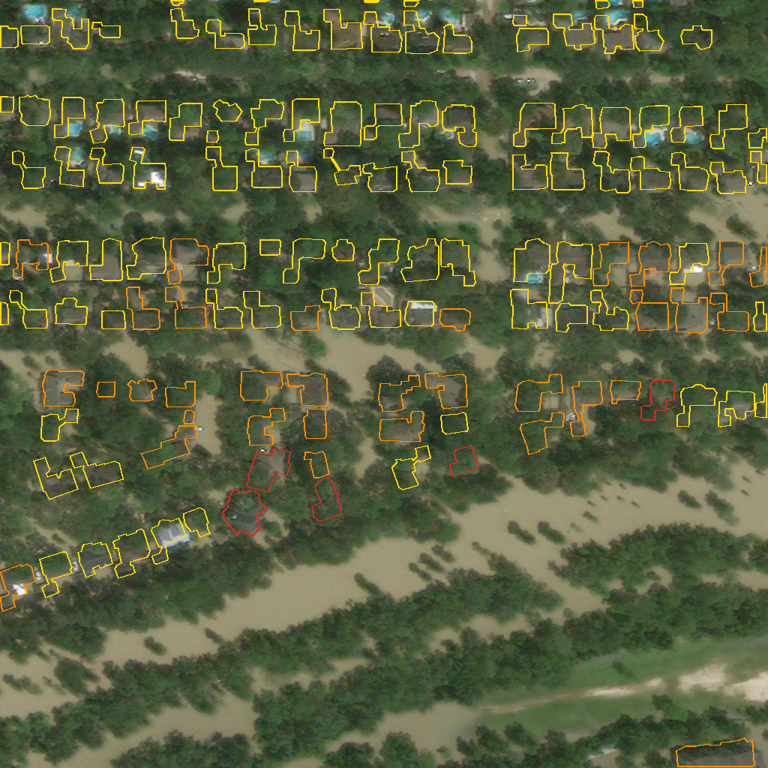

In [208]:

import os
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageDraw
from shapely import wkt
from torchvision import transforms

PROJECT_ROOT = "/content/drive/MyDrive/T229"
DATA_ROOT = os.path.join(PROJECT_ROOT, "data")
REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")
LABEL_DIR = os.path.join(DATA_ROOT, "train", "labels")
IMAGE_DIR = os.path.join(DATA_ROOT, "train", "images")

# Use the model and inference_transform loaded in Step 2.
# Select one scene for this first end-to-end test.
SCENE_ID = "hurricane-harvey_00000387"
PADDING = 48
OUTPUT_SIZE = (128, 128)

post_image_path = os.path.join(
    IMAGE_DIR, f"{SCENE_ID}_post_disaster.png"
)
post_json_path = os.path.join(
    LABEL_DIR, f"{SCENE_ID}_post_disaster.json"
)

assert os.path.isfile(post_image_path), post_image_path
assert os.path.isfile(post_json_path), post_json_path

with open(post_json_path, "r", encoding="utf-8") as f:
    scene_json = json.load(f)

features = scene_json.get("features", {}).get("xy", [])

post_image = Image.open(post_image_path).convert("RGB")
overlay = post_image.copy()
draw = ImageDraw.Draw(overlay)

# Colors for the visualization
class_colors = {
    "destroyed": (220, 40, 40),
    "major-damage": (255, 140, 0),
    "minor-damage": (255, 220, 0),
    "no-damage": (40, 190, 80),
}

records = []
skipped = 0

model.eval()

with torch.no_grad():
    for feature in features:
        properties = feature.get("properties", {})
        polygon_text = feature.get("wkt")

        if not polygon_text:
            skipped += 1
            continue

        try:
            polygon = wkt.loads(polygon_text)
        except Exception:
            skipped += 1
            continue

        if polygon.is_empty or polygon.geom_type not in (
            "Polygon", "MultiPolygon"
        ):
            skipped += 1
            continue

        minx, miny, maxx, maxy = polygon.bounds

        # Clip the context crop to image boundaries.
        left = max(0, int(minx) - PADDING)
        top = max(0, int(miny) - PADDING)
        right = min(post_image.width, int(maxx) + PADDING)
        bottom = min(post_image.height, int(maxy) + PADDING)

        if right <= left or bottom <= top:
            skipped += 1
            continue

        crop = post_image.crop((left, top, right, bottom))
        crop = crop.resize(
            OUTPUT_SIZE, Image.Resampling.BILINEAR
        )

        image_tensor = inference_transform(crop).unsqueeze(0)
        logits = model(image_tensor.to(device))
        probabilities = torch.softmax(logits, dim=1)[0]

        predicted_idx = int(probabilities.argmax().item())
        predicted_class = idx_to_class[predicted_idx]
        confidence = float(probabilities[predicted_idx].item())

        # Retain the source label for later evaluation only.
        true_subtype = properties.get("subtype", "unknown")
        uid = properties.get("uid", None)

        records.append({
            "scene_id": SCENE_ID,
            "building_uid": uid,
            "predicted_damage": predicted_class,
            "confidence": confidence,
            "ground_truth_subtype": true_subtype,
            "minx": minx,
            "miny": miny,
            "maxx": maxx,
            "maxy": maxy,
            "crop_left": left,
            "crop_top": top,
            "crop_right": right,
            "crop_bottom": bottom,
        })

        # Draw each polygon boundary using its predicted class.
        color = class_colors[predicted_class]

        geometries = (
            list(polygon.geoms)
            if polygon.geom_type == "MultiPolygon"
            else [polygon]
        )

        for geom in geometries:
            points = [
                (int(x), int(y))
                for x, y in geom.exterior.coords
            ]
            if len(points) >= 3:
                draw.polygon(points, outline=color, width=2)

os.makedirs(REPORTS_DIR, exist_ok=True)

csv_path = os.path.join(
    REPORTS_DIR, f"{SCENE_ID}_resnet18_building_predictions.csv"
)
overlay_path = os.path.join(
    REPORTS_DIR, f"{SCENE_ID}_resnet18_damage_overlay.png"
)

results = pd.DataFrame(records)
results.to_csv(csv_path, index=False)
overlay.save(overlay_path)

print("=== INFERENCE RESULTS ===")
print("Scene:", SCENE_ID)
print("Image size:", post_image.size)
print("JSON features:", len(features))
print("Buildings predicted:", len(results))
print("Features skipped:", skipped)
print("\nPredicted class counts:")
print(results["predicted_damage"].value_counts().to_string())
print("\nMean confidence:", round(
    float(results["confidence"].mean()), 4
) if len(results) else "No predictions")
print("\nCSV saved:", csv_path)
print("Overlay saved:", overlay_path)

display(results.head(10))
display(overlay.resize((768, 768)))


Validation scene: hurricane-harvey_00000132
JSON features: 263
Buildings predicted: 263
Features skipped: 0
Buildings with recognized ground truth: 263

Prediction counts:
predicted_damage
major-damage    223
minor-damage     40

Per-scene classification report:
              precision    recall  f1-score   support

   destroyed     0.0000    0.0000    0.0000         0
major-damage     0.9193    0.8913    0.9051       230
minor-damage     0.3750    0.4545    0.4110        33
   no-damage     0.0000    0.0000    0.0000         0

    accuracy                         0.8365       263
   macro avg     0.3236    0.3365    0.3290       263
weighted avg     0.8510    0.8365    0.8431       263

Confusion matrix (rows=actual, columns=predicted):
              destroyed  major-damage  minor-damage  no-damage
destroyed             0             0             0          0
major-damage          0           205            25          0
minor-damage          0            18            15          0

,scene_id,building_uid,predicted_damage,confidence,ground_truth_subtype,minx,miny,maxx,maxy
0,hurricane-harvey_00000132,faa5c294-4235-4c03-9207-0fab7fcbd0fe,minor-damage,0.889462,minor-damage,-0.000005,945.537910,22.040746,991.225724
1,hurricane-harvey_00000132,ad1692a9-de94-40b4-a714-8c07503b8c8f,minor-damage,0.870875,minor-damage,26.917015,973.774896,83.406031,1022.984978
2,hurricane-harvey_00000132,4bc18b57-6b9e-424c-bbd5-25a9e9e56c74,minor-damage,0.687886,minor-damage,58.782613,948.427261,104.891169,993.811599
3,hurricane-harvey_00000132,6573d401-b23a-4332-8b37-e3c232d5e077,major-damage,0.732142,minor-damage,64.093547,904.249954,106.581011,949.875698
4,hurricane-harvey_00000132,c5184ffa-de66-4437-ac2e-3bfa1c2bb0f5,major-damage,0.932061,minor-damage,85.337279,864.659362,132.652865,911.492136
5,hurricane-harvey_00000132,eed85d67-97e5-408c-9ffa-f1a7e0a8243b,major-damage,0.807106,minor-damage,94.752115,825.551582,138.205204,866.107798
6,hurricane-harvey_00000132,d63590bb-0455-481d-8b1c-754a8198ee3c,minor-damage,0.743188,minor-damage,108.995072,780.650057,142.550513,819.999243
7,hurricane-harvey_00000132,35135e04-6d21-4764-b19c-bfc6d80bbdf2,minor-damage,0.717260,minor-damage,97.407581,692.054036,137.239580,732.851659
8,hurricane-harvey_00000132,2eebcaa2-766f-407c-a30b-56406c6a9da9,major-damage,0.826218,minor-damage,76.880546,643.396704,127.213348,696.088857
9,hurricane-harvey_00000132,993a235e-004f-4450-ab5c-11a9dca00f11,minor-damage,0.794827,minor-damage,11.199684,669.276115,65.441753,718.627505


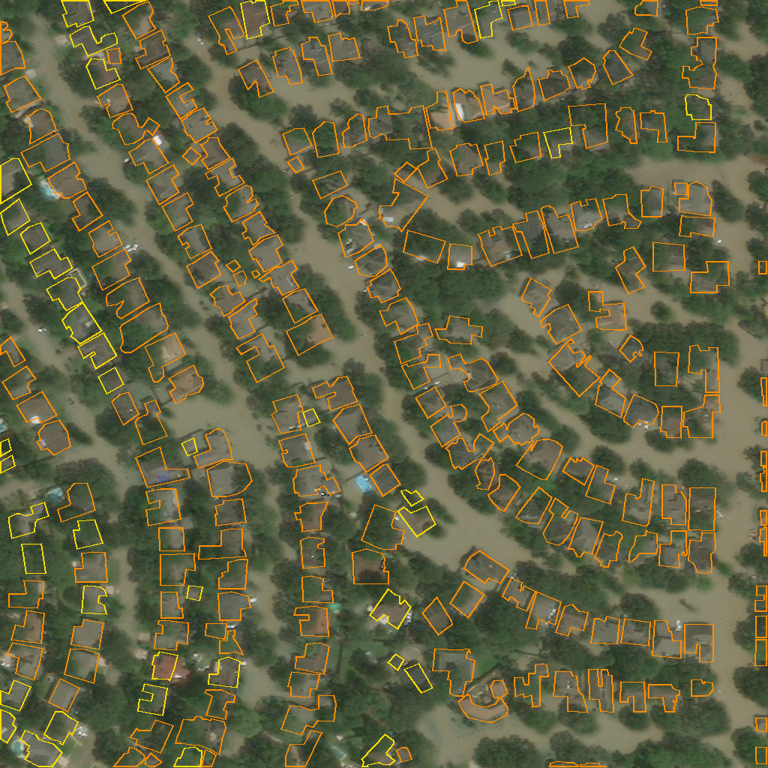

In [209]:

import os
import json
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageDraw
from shapely import wkt
from sklearn.metrics import classification_report, confusion_matrix

PROJECT_ROOT = "/content/drive/MyDrive/T229"
DATA_ROOT = os.path.join(PROJECT_ROOT, "data")
REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")
LABEL_DIR = os.path.join(DATA_ROOT, "train", "labels")

# Select a scene from the held-out validation building list.
val_df = pd.read_csv(
    os.path.join(REPORTS_DIR, "val_buildings.csv")
)
SCENE_ID = val_df.iloc[0]["scene_id"]

scene_rows = val_df[val_df["scene_id"] == SCENE_ID]
post_image_path = scene_rows.iloc[0]["image_path"]
post_json_path = os.path.join(
    LABEL_DIR, f"{SCENE_ID}_post_disaster.json"
)

assert os.path.isfile(post_image_path), post_image_path
assert os.path.isfile(post_json_path), post_json_path

with open(post_json_path, "r", encoding="utf-8") as f:
    scene_json = json.load(f)

features = scene_json.get("features", {}).get("xy", [])
post_image = Image.open(post_image_path).convert("RGB")
overlay = post_image.copy()
draw = ImageDraw.Draw(overlay)

colors = {
    "destroyed": (220, 40, 40),
    "major-damage": (255, 140, 0),
    "minor-damage": (255, 220, 0),
    "no-damage": (40, 190, 80),
}

records = []
skipped = 0
model.eval()

with torch.no_grad():
    for feature in features:
        polygon_text = feature.get("wkt")
        if not polygon_text:
            skipped += 1
            continue

        try:
            polygon = wkt.loads(polygon_text)
        except Exception:
            skipped += 1
            continue

        if polygon.is_empty or polygon.geom_type not in (
            "Polygon", "MultiPolygon"
        ):
            skipped += 1
            continue

        minx, miny, maxx, maxy = polygon.bounds
        left = max(0, int(minx) - 48)
        top = max(0, int(miny) - 48)
        right = min(post_image.width, int(maxx) + 48)
        bottom = min(post_image.height, int(maxy) + 48)

        if right <= left or bottom <= top:
            skipped += 1
            continue

        crop = post_image.crop(
            (left, top, right, bottom)
        ).resize((128, 128), Image.Resampling.BILINEAR)

        tensor = inference_transform(crop).unsqueeze(0)
        probs = torch.softmax(model(tensor.to(device)), dim=1)[0]
        pred_idx = int(probs.argmax().item())
        pred_class = idx_to_class[pred_idx]

        properties = feature.get("properties", {})
        true_class = properties.get("subtype", "unknown")

        records.append({
            "scene_id": SCENE_ID,
            "building_uid": properties.get("uid"),
            "predicted_damage": pred_class,
            "confidence": float(probs[pred_idx].item()),
            "ground_truth_subtype": true_class,
            "minx": minx,
            "miny": miny,
            "maxx": maxx,
            "maxy": maxy,
        })

        geometries = (
            list(polygon.geoms)
            if polygon.geom_type == "MultiPolygon"
            else [polygon]
        )
        for geom in geometries:
            points = [(int(x), int(y)) for x, y in geom.exterior.coords]
            if len(points) >= 3:
                draw.polygon(
                    points, outline=colors[pred_class], width=2
                )

results = pd.DataFrame(records)

csv_path = os.path.join(
    REPORTS_DIR, f"{SCENE_ID}_validation_building_predictions.csv"
)
overlay_path = os.path.join(
    REPORTS_DIR, f"{SCENE_ID}_validation_damage_overlay.png"
)

results.to_csv(csv_path, index=False)
overlay.save(overlay_path)

# Evaluate only recognized damage labels; unknown/un-classified
# polygons are excluded from the metrics.
known_classes = [
    "destroyed", "major-damage", "minor-damage", "no-damage"
]
evaluated = results[
    results["ground_truth_subtype"].isin(known_classes)
].copy()

print("Validation scene:", SCENE_ID)
print("JSON features:", len(features))
print("Buildings predicted:", len(results))
print("Features skipped:", skipped)
print("Buildings with recognized ground truth:", len(evaluated))
print("\nPrediction counts:")
print(results["predicted_damage"].value_counts().to_string())

if len(evaluated):
    print("\nPer-scene classification report:")
    print(classification_report(
        evaluated["ground_truth_subtype"],
        evaluated["predicted_damage"],
        labels=known_classes,
        target_names=known_classes,
        digits=4,
        zero_division=0
    ))

    print("Confusion matrix (rows=actual, columns=predicted):")
    print(pd.DataFrame(
        confusion_matrix(
            evaluated["ground_truth_subtype"],
            evaluated["predicted_damage"],
            labels=known_classes
        ),
        index=known_classes,
        columns=known_classes
    ))
else:
    print("No recognized ground-truth labels to evaluate.")

print("\nCSV:", csv_path)
print("Overlay:", overlay_path)
display(results.head(10))
display(overlay.resize((768, 768)))


In [211]:
# import os
# import numpy as np
# import pandas as pd
# import torch
# from sklearn.metrics import (
#     accuracy_score,
#     f1_score,
#     classification_report,
#     confusion_matrix
# )
# from torchvision import datasets
# from torch.utils.data import DataLoader

# PROJECT_ROOT = "/content/drive/MyDrive/T229"
# DATA_ROOT = os.path.join(PROJECT_ROOT, "data")
# REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")

# VAL_CROP_DIR = os.path.join(DATA_ROOT, "building_crops_context", "val")

# # Load the saved validation crops.
# val_dataset = datasets.ImageFolder(
#     VAL_CROP_DIR,
#     transform=inference_transform
# )

# val_loader = DataLoader(
#     val_dataset,
#     batch_size=32,
#     shuffle=False,
#     num_workers=0
# )

# print("Validation crops:", len(val_dataset))
# print("Class mapping:", val_dataset.class_to_idx)

# # Run inference.
# all_predictions = []
# all_labels = []
# all_confidences = []

# model.eval()

# with torch.no_grad():
#     for images, labels in val_loader:
#         images = images.to(device)

#         logits = model(images)
#         probabilities = torch.softmax(logits, dim=1)

#         confidence, predictions = probabilities.max(dim=1)

#         all_predictions.extend(predictions.cpu().numpy())
#         all_labels.extend(labels.numpy())
#         all_confidences.extend(confidence.cpu().numpy())

# all_predictions = np.asarray(all_predictions)
# all_labels = np.asarray(all_labels)
# all_confidences = np.asarray(all_confidences)

# class_names = [
#     name for name, idx in sorted(
#         val_dataset.class_to_idx.items(),
#         key=lambda item: item[1]
#     )
# ]

# print("\nValidation accuracy:",
#       round(accuracy_score(all_labels, all_predictions), 4))

# print("Validation macro-F1:",
#       round(f1_score(
#           all_labels,
#           all_predictions,
#           average="macro",
#           zero_division=0
#       ), 4))

# print("\nClassification report:")
# print(classification_report(
#     all_labels,
#     all_predictions,
#     labels=list(range(len(class_names))),
#     target_names=class_names,
#     digits=4,
#     zero_division=0
# ))

# print("Confusion matrix:")
# print(confusion_matrix(
#     all_labels,
#     all_predictions,
#     labels=list(range(len(class_names)))
# ))

# print("\nMean prediction confidence:",
#       round(float(all_confidences.mean()), 4))

In [212]:

import os
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

REPORTS_DIR = "/content/drive/MyDrive/T229/reports"
os.makedirs(REPORTS_DIR, exist_ok=True)

# Keep the class order consistent with ImageFolder and the model.
idx_to_class = {
    idx: name
    for name, idx in val_dataset.class_to_idx.items()
}

prediction_df = pd.DataFrame({
    "crop_path": [path for path, _ in val_dataset.samples],
    "actual_damage": [idx_to_class[int(x)] for x in all_labels],
    "predicted_damage": [
        idx_to_class[int(x)] for x in all_predictions
    ],
    "confidence": all_confidences,
    "correct": all_predictions == all_labels
})

csv_path = os.path.join(
    REPORTS_DIR,
    "resnet18_context_validation_predictions.csv"
)
prediction_df.to_csv(csv_path, index=False)

print("Saved:", csv_path)
print("Total predictions:", len(prediction_df))
print("Correct:", int(prediction_df["correct"].sum()))
print("Incorrect:", int((~prediction_df["correct"]).sum()))

print("\nPrediction counts:")
print(prediction_df["predicted_damage"].value_counts())

print("\nLowest-confidence examples:")
print(
    prediction_df.sort_values("confidence")
    .head(10)
    .to_string(index=False)
)

print("\nCSV preview:")
display(prediction_df.head())


ValueError: All arrays must be of the same length

In [ ]:

import os
import json
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score
)

REPORTS_DIR = "/content/drive/MyDrive/T229/reports"
os.makedirs(REPORTS_DIR, exist_ok=True)

class_names = [
    name for name, idx in sorted(
        val_dataset.class_to_idx.items(),
        key=lambda item: item[1]
    )
]

# Overall metrics
accuracy = accuracy_score(all_labels, all_predictions)
macro_f1 = f1_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)
weighted_f1 = f1_score(
    all_labels, all_predictions,
    average="weighted", zero_division=0
)

# Per-class metrics
precision, recall, f1, support = precision_recall_fscore_support(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    zero_division=0
)

metrics_df = pd.DataFrame({
    "class": class_names,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "support": support
})

metrics_path = os.path.join(
    REPORTS_DIR, "resnet18_context_final_metrics.csv"
)
metrics_df.to_csv(metrics_path, index=False)

# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

cm_df = pd.DataFrame(
    cm,
    index=[f"actual_{c}" for c in class_names],
    columns=[f"predicted_{c}" for c in class_names]
)

cm_path = os.path.join(
    REPORTS_DIR, "resnet18_context_final_confusion_matrix.csv"
)
cm_df.to_csv(cm_path)

# Incorrect predictions
predictions_path = os.path.join(
    REPORTS_DIR, "resnet18_context_validation_predictions.csv"
)
prediction_df = pd.read_csv(predictions_path)
errors_df = prediction_df[~prediction_df["correct"]].copy()

errors_path = os.path.join(
    REPORTS_DIR, "resnet18_context_misclassified_buildings.csv"
)
errors_df.to_csv(errors_path, index=False)

# Machine-readable summary
summary = {
    "model": "ResNet18 context classifier",
    "validation_samples": int(len(all_labels)),
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "mean_confidence": float(np.mean(all_confidences)),
    "correct_predictions": int((all_labels == all_predictions).sum()),
    "incorrect_predictions": int((all_labels != all_predictions).sum()),
    "class_order": class_names
}

summary_path = os.path.join(
    REPORTS_DIR, "resnet18_context_final_summary.json"
)
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("FINAL VALIDATION SUMMARY")
print(json.dumps(summary, indent=2))

print("\nSaved files:")
print(metrics_path)
print(cm_path)
print(errors_path)
print(summary_path)

print("\nPer-class metrics:")
display(metrics_df)
print("\nConfusion matrix:")
display(cm_df)


In [ ]:
import os
import pandas as pd

PROJECT_ROOT = "/content/drive/MyDrive/T229"
REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")
LABEL_DIR = os.path.join(PROJECT_ROOT, "data", "train", "labels")

val_df = pd.read_csv(os.path.join(REPORTS_DIR, "val_buildings.csv"))

print("Validation building rows:", len(val_df))
print("Unique validation scenes:", val_df["scene_id"].nunique())
print("Required label folder exists:", os.path.isdir(LABEL_DIR))
print("\nColumns:", val_df.columns.tolist())
print("\nSample rows:")
display(val_df.head(3))

In [ ]:

import os
import pandas as pd

REPORTS_DIR = "/content/drive/MyDrive/T229/reports"
val_df = pd.read_csv(os.path.join(REPORTS_DIR, "val_buildings.csv"))

print("Rows:", len(val_df))
print("Unique scenes:", val_df["scene_id"].nunique())

# Check whether the image paths point to post-disaster images.
print("\nImage path examples:")
for path in val_df["image_path"].head(5):
    print(os.path.exists(path), path)

print("\nPost-disaster image paths:",
      val_df["image_path"].str.contains("_post_disaster", regex=False).sum())

print("Missing image paths:",
      sum(not os.path.exists(p) for p in val_df["image_path"]))

print("\nMissing polygon WKT:",
      val_df["polygon_wkt"].isna().sum())

print("\nLabels:")
print(val_df["label"].value_counts())


In [ ]:

import os
import json
import pandas as pd
import numpy as np
import torch
from PIL import Image
from shapely import wkt
from tqdm.auto import tqdm

PROJECT_ROOT = "/content/drive/MyDrive/T229"
REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")
OUTPUT_CSV = os.path.join(
    REPORTS_DIR, "resnet18_context_all_validation_buildings.csv"
)

val_df = pd.read_csv(
    os.path.join(REPORTS_DIR, "val_buildings.csv")
)

# Load each unique scene image only once.
scene_image_cache = {}
results = []
skipped = []

model.eval()
PADDING = 48

for row in tqdm(
    val_df.itertuples(index=False),
    total=len(val_df),
    desc="Predicting validation buildings"
):
    try:
        scene_id = row.scene_id
        image_path = row.image_path
        polygon = wkt.loads(row.polygon_wkt)

        if scene_id not in scene_image_cache:
            with Image.open(image_path) as im:
                scene_image_cache[scene_id] = im.convert("RGB").copy()

        image = scene_image_cache[scene_id]

        minx, miny, maxx, maxy = polygon.bounds

        left = max(0, int(minx) - PADDING)
        top = max(0, int(miny) - PADDING)
        right = min(image.width, int(maxx) + PADDING)
        bottom = min(image.height, int(maxy) + PADDING)

        if right <= left or bottom <= top:
            raise ValueError("Invalid crop bounds")

        crop = image.crop((left, top, right, bottom))
        tensor = inference_transform(crop).unsqueeze(0).to(device)

        with torch.no_grad():
            logits = model(tensor)
            probabilities = torch.softmax(logits, dim=1)
            confidence, prediction = probabilities.max(dim=1)

        predicted_idx = int(prediction.item())
        predicted_class = idx_to_class[predicted_idx]

        results.append({
            "scene_id": scene_id,
            "image_path": image_path,
            "polygon_wkt": row.polygon_wkt,
            "actual_damage": row.label,
            "predicted_damage": predicted_class,
            "confidence": float(confidence.item()),
            "correct": predicted_class == row.label,
            "minx": minx,
            "miny": miny,
            "maxx": maxx,
            "maxy": maxy
        })

    except Exception as e:
        skipped.append({
            "scene_id": getattr(row, "scene_id", "unknown"),
            "error": str(e)
        })

    # Periodically save progress so a runtime interruption loses less work.
    if len(results) > 0 and len(results) % 200 == 0:
        pd.DataFrame(results).to_csv(OUTPUT_CSV, index=False)

# Final save.
results_df = pd.DataFrame(results)
results_df.to_csv(OUTPUT_CSV, index=False)

print("\nSaved:", OUTPUT_CSV)
print("Predictions generated:", len(results_df))
print("Skipped:", len(skipped))

if len(results_df):
    print("\nAccuracy:", round(results_df["correct"].mean(), 4))
    print("\nPrediction counts:")
    print(results_df["predicted_damage"].value_counts())

if skipped:
    skipped_path = os.path.join(
        REPORTS_DIR, "resnet18_context_validation_skipped.csv"
    )
    pd.DataFrame(skipped).to_csv(skipped_path, index=False)
    print("\nSkipped-record details:", skipped_path)


In [ ]:

import os
import pandas as pd
from PIL import Image, ImageDraw
from shapely import wkt
from tqdm.auto import tqdm

PROJECT_ROOT = "/content/drive/MyDrive/T229"
REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")

PREDICTIONS_CSV = os.path.join(
    REPORTS_DIR, "resnet18_context_all_validation_buildings.csv"
)
OVERLAY_DIR = os.path.join(
    REPORTS_DIR, "resnet18_context_validation_overlays"
)
os.makedirs(OVERLAY_DIR, exist_ok=True)

pred_df = pd.read_csv(PREDICTIONS_CSV)

# Colors in RGB: no damage, minor, major, destroyed.
COLORS = {
    "no-damage": (0, 200, 0),
    "minor-damage": (255, 220, 0),
    "major-damage": (255, 140, 0),
    "destroyed": (230, 0, 0)
}

def draw_polygon(draw, polygon, color, width=3):
    if polygon.is_empty:
        return

    if polygon.geom_type == "Polygon":
        geometries = [polygon]
    elif polygon.geom_type == "MultiPolygon":
        geometries = list(polygon.geoms)
    else:
        return

    for geom in geometries:
        points = [(float(x), float(y)) for x, y in geom.exterior.coords]
        if len(points) >= 3:
            draw.line(points + [points[0]], fill=color, width=width)

scene_groups = pred_df.groupby("scene_id", sort=True)
saved = 0
failed = []

for scene_id, group in tqdm(
    scene_groups,
    total=pred_df["scene_id"].nunique(),
    desc="Creating scene overlays"
):
    try:
        image_path = group.iloc[0]["image_path"]

        with Image.open(image_path) as im:
            base = im.convert("RGB").copy()

        draw = ImageDraw.Draw(base)

        for row in group.itertuples(index=False):
            polygon = wkt.loads(row.polygon_wkt)
            color = COLORS.get(row.predicted_damage, (255, 255, 255))
            draw_polygon(draw, polygon, color, width=3)

        output_path = os.path.join(
            OVERLAY_DIR, f"{scene_id}_damage_overlay.png"
        )
        base.save(output_path)
        saved += 1

    except Exception as e:
        failed.append({"scene_id": scene_id, "error": str(e)})

print("\nOverlay folder:", OVERLAY_DIR)
print("Scenes processed:", len(scene_groups))
print("Overlays saved:", saved)
print("Failed scenes:", len(failed))

if failed:
    failed_path = os.path.join(
        REPORTS_DIR, "resnet18_context_overlay_failures.csv"
    )
    pd.DataFrame(failed).to_csv(failed_path, index=False)
    print("Failure details:", failed_path)

print("\nColor legend:")
for damage, color in COLORS.items():
    print(f"{damage}: RGB {color}")


In [ ]:
from IPython.display import display
from PIL import Image
import os

overlay_dir = (
    "/content/drive/MyDrive/T229/reports/"
    "resnet18_context_validation_overlays"
)

sample_overlay = os.path.join(
    overlay_dir,
    "hurricane-harvey_00000132_damage_overlay.png"
)

print("Exists:", os.path.exists(sample_overlay))

if os.path.exists(sample_overlay):
    display(Image.open(sample_overlay))

In [ ]:
import os
import pandas as pd

REPORTS_DIR = "/content/drive/MyDrive/T229/reports"

files_to_check = [
    "siamese_unet_validation_metrics.csv",
    "siamese_unet_validation_confusion_matrix.csv",
    "footprint_mask_comparison.csv",
    "footprint_mask_summary.csv",
]

for filename in files_to_check:
    path = os.path.join(REPORTS_DIR, filename)
    print(f"\n{filename}: {'EXISTS' if os.path.exists(path) else 'MISSING'}")

    if os.path.exists(path) and filename.endswith(".csv"):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        display(df.head(5))

In [ ]:

import os
import torch
import pandas as pd

PROJECT_ROOT = "/content/drive/MyDrive/T229"
CHECKPOINT_PATH = os.path.join(
    PROJECT_ROOT,
    "checkpoints",
    "siamese_unet_focal_dice_calibrated.pth"
)
REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")

print("Checkpoint exists:", os.path.exists(CHECKPOINT_PATH))

if os.path.exists(CHECKPOINT_PATH):
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False
    )

    print("\nCheckpoint keys:", list(checkpoint.keys()))
    print("Model name:", checkpoint.get("model_name"))
    print("Number of classes:", checkpoint.get("num_classes"))
    print("Class names:", checkpoint.get("class_names"))
    print("Recorded validation macro-F1:",
          checkpoint.get("validation_macro_f1"))
    print("Recorded validation macro-IoU:",
          checkpoint.get("validation_macro_iou"))
    print("Calibration boosts:",
          checkpoint.get("calibration_logit_boosts"))

for filename in [
    "siamese_unet_validation_metrics.csv",
    "footprint_mask_summary.csv"
]:
    path = os.path.join(REPORTS_DIR, filename)
    if os.path.exists(path):
        print(f"\n--- {filename} ---")
        print(pd.read_csv(path).to_string(index=False))


In [ ]:
import os
import pandas as pd

REPORTS_DIR = "/content/drive/MyDrive/T229/reports"

metrics_path = os.path.join(
    REPORTS_DIR, "siamese_unet_validation_metrics.csv"
)
metrics_df = pd.read_csv(metrics_path)

print("Per-class metrics:")
display(metrics_df)

print("\nMacro averages across all classes:")
print("Macro-F1:", round(metrics_df["f1"].mean(), 4))
print("Macro-IoU:", round(metrics_df["iou"].mean(), 4))

damage_df = metrics_df[
    metrics_df["class"].isin([
        "no_damage", "minor_damage", "major_damage", "destroyed"
    ])
]

print("\nDamage-only macro averages:")
print("Damage macro-F1:", round(damage_df["f1"].mean(), 4))
print("Damage macro-IoU:", round(damage_df["iou"].mean(), 4))

print("\nCheckpoint metadata:")
checkpoint = torch.load(
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_focal_dice_calibrated.pth",
    map_location="cpu",
    weights_only=False
)
print("Recorded macro-F1:", checkpoint.get("validation_macro_f1"))
print("Recorded macro-IoU:", checkpoint.get("validation_macro_iou"))

In [ ]:
import os
import pandas as pd

ROOT = "/content/drive/MyDrive/T229"

files_to_check = {
    "Best ResNet-18 checkpoint":
        f"{ROOT}/checkpoints/resnet18_context_best.pth",
    "Validation building labels":
        f"{ROOT}/reports/val_buildings.csv",
    "Validation classification report":
        f"{ROOT}/reports/resnet18_context_classification_report.csv",
    "Training building labels":
        f"{ROOT}/reports/train_buildings.csv",
}

for name, path in files_to_check.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'MISSING'}")

val_path = files_to_check["Validation building labels"]

if os.path.exists(val_path):
    val_df = pd.read_csv(val_path)
    print("\nValidation rows:", len(val_df))
    print("Unique validation scenes:", val_df["scene_id"].nunique())
    print("Validation columns:", val_df.columns.tolist())

In [ ]:
import pandas as pd
import os

ROOT = "/content/drive/MyDrive/T229/reports"

train_df = pd.read_csv(f"{ROOT}/train_buildings.csv")
val_df = pd.read_csv(f"{ROOT}/val_buildings.csv")

print("TRAINING SET")
print("Buildings:", len(train_df))
print("Unique scenes:", train_df["scene_id"].nunique())
print("\nClass distribution:")
print(train_df["label"].value_counts().sort_index())

print("\n" + "=" * 40)
print("VALIDATION SET")
print("Buildings:", len(val_df))
print("Unique scenes:", val_df["scene_id"].nunique())
print("\nClass distribution:")
print(val_df["label"].value_counts().sort_index())

train_scenes = set(train_df["scene_id"].dropna())
val_scenes = set(val_df["scene_id"].dropna())

overlap = train_scenes.intersection(val_scenes)

print("\n" + "=" * 40)
print("DATA LEAKAGE CHECK")
print("Overlapping scenes:", len(overlap))
print("Duplicate training rows:", train_df.duplicated().sum())
print("Duplicate validation rows:", val_df.duplicated().sum())

print("\nSplit check:", "PASSED" if len(overlap) == 0 else "WARNING: SCENE OVERLAP")

In [ ]:
import torch
import os

CHECKPOINT_PATH = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "resnet18_context_best.pth"
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint loaded successfully")
print("Saved epoch:", checkpoint.get("epoch", "Not recorded"))
print("Saved validation macro-F1:",
      checkpoint.get("val_macro_f1", "Not recorded"))

print("\nClass-to-index mapping:")
print(checkpoint.get("class_to_idx", "Not recorded"))

print("\nCheckpoint keys:")
print(list(checkpoint.keys()))

print("\nModel parameter tensors:",
      len(checkpoint["model_state_dict"]))

In [ ]:
import torch
import torch.nn as nn
from torchvision import models, transforms

CHECKPOINT_PATH = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "resnet18_context_best.pth"
)

device = torch.device("cpu")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

class_to_idx = checkpoint["class_to_idx"]
idx_to_class = {v: k for k, v in class_to_idx.items()}

model = models.resnet18(weights=None)
model.fc = nn.Linear(
    model.fc.in_features,
    len(class_to_idx)
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

inference_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Model loaded and ready for inference.")
print("Device:", device)
print("Class mapping:", class_to_idx)
print("Input size: 128 × 128")
print("Model mode:", "evaluation" if not model.training else "training")

In [ ]:
import os

ROOT = "/content/drive/MyDrive/T229"

crop_dirs = {
    "Training context crops":
        f"{ROOT}/data/building_crops_context/train",
    "Validation context crops":
        f"{ROOT}/data/building_crops_context/val",
}

for name, path in crop_dirs.items():
    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", os.path.isdir(path))

    if os.path.isdir(path):
        classes = sorted(
            item for item in os.listdir(path)
            if os.path.isdir(os.path.join(path, item))
        )
        print("Class folders:", classes)

        for cls in classes:
            cls_path = os.path.join(path, cls)
            count = sum(
                1 for f in os.listdir(cls_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            )
            print(f"  {cls}: {count} images")

In [ ]:
import os
import pandas as pd

ROOT = "/content/drive/MyDrive/T229"

val_df = pd.read_csv(f"{ROOT}/reports/val_buildings.csv")

print("CSV image path example:")
print(val_df.iloc[0]["image_path"])

print("\nCSV label:", val_df.iloc[0]["label"])

crop_dir = f"{ROOT}/data/building_crops_context/val"
label = str(val_df.iloc[0]["label"])
class_dir = os.path.join(crop_dir, label)

print("\nFirst 10 saved crop filenames:")
print(os.listdir(class_dir)[:10])

print("\nExpected filename:")
print(os.path.basename(str(val_df.iloc[0]["image_path"])))

print("\nFiles in class folder:", len(os.listdir(class_dir)))

In [213]:
import pandas as pd
import os

ROOT = "/content/drive/MyDrive/T229"

# Inspect the validation CSV
val_df = pd.read_csv(f"{ROOT}/reports/val_buildings.csv")

print("Validation CSV columns:")
print(val_df.columns.tolist())

print("\nFirst 5 validation records:")
print(val_df.head().to_string(index=False))

# Inspect the crop folder filenames
crop_dir = f"{ROOT}/data/building_crops_context/val"

print("\nFirst 15 filenames from each class:")
for label in sorted(os.listdir(crop_dir)):
    folder = os.path.join(crop_dir, label)
    if os.path.isdir(folder):
        files = sorted(os.listdir(folder))
        print(f"\n{label}:")
        for filename in files[:15]:
            print(" ", filename)

# Check whether a crop manifest exists
for path in [
    f"{ROOT}/data/building_crops_context/manifest.csv",
    f"{ROOT}/data/building_crops_context/val_manifest.csv",
    f"{ROOT}/reports/context_crop_manifest.csv",
]:
    print(f"\n{path}: {'FOUND' if os.path.exists(path) else 'not found'}")

Validation CSV columns:
['scene_id', 'image_path', 'label', 'polygon_wkt']

First 5 validation records:
                   scene_id                                                                                  image_path        label                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       polygon_wkt
  hurricane-harvey_00000132   /content/drive/MyDrive/T229

In [215]:
# import os
# import torch
# import numpy as np
# import pandas as pd

# from torchvision import datasets
# from torch.utils.data import DataLoader
# from sklearn.metrics import (
#     accuracy_score,
#     f1_score,
#     classification_report,
#     confusion_matrix
# )

# PROJECT_ROOT = "/content/drive/MyDrive/T229"
# VAL_CROP_DIR = os.path.join(
#     PROJECT_ROOT, "data", "building_crops_context", "val"
# )

# # Load the existing saved crops in the same way as the original notebook.
# val_dataset = datasets.ImageFolder(
#     VAL_CROP_DIR,
#     transform=inference_transform
# )

# val_loader = DataLoader(
#     val_dataset,
#     batch_size=32,
#     shuffle=False,
#     num_workers=0
# )

# # Confirm that the crop folders and checkpoint use the same class order.
# print("Checkpoint class mapping:", class_to_idx)
# print("ImageFolder class mapping:", val_dataset.class_to_idx)

# assert val_dataset.class_to_idx == class_to_idx, (
#     "Class mappings differ. Stop before evaluating."
# )

# y_true, y_pred = [], []

# model.eval()
# with torch.no_grad():
#     for images, labels in val_loader:
#         logits = model(images.to(device))
#         predictions = logits.argmax(dim=1)

#         y_true.extend(labels.numpy())
#         y_pred.extend(predictions.cpu().numpy())

# class_names = [
#     name for name, idx in sorted(
#         class_to_idx.items(), key=lambda item: item[1]
#     )
# ]

# print("\nValidation samples:", len(y_true))
# print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
# print(
#     "Macro-F1:",
#     f"{f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}"
# )

# print("\nClassification report:")
# print(classification_report(
#     y_true,
#     y_pred,
#     labels=list(range(len(class_names))),
#     target_names=class_names,
#     digits=4,
#     zero_division=0
# ))

# print("Confusion matrix:")
# print(confusion_matrix(
#     y_true, y_pred, labels=list(range(len(class_names)))
# ))

In [217]:
# import os
# import numpy as np
# import pandas as pd
# import torch

# from torchvision import datasets
# from torch.utils.data import DataLoader
# from sklearn.metrics import (
#     accuracy_score,
#     f1_score,
#     classification_report,
#     confusion_matrix
# )

# # Use the existing project paths and model from earlier cells
# VAL_CROP_DIR = os.path.join(
#     PROJECT_ROOT, "data", "building_crops_context", "val"
# )

# REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")
# os.makedirs(REPORTS_DIR, exist_ok=True)

# # Recreate the exact validation loader
# val_dataset = datasets.ImageFolder(
#     VAL_CROP_DIR,
#     transform=inference_transform
# )

# val_loader = DataLoader(
#     val_dataset,
#     batch_size=32,
#     shuffle=False,
#     num_workers=0
# )

# # Evaluate the confirmed checkpoint
# model.eval()
# all_true = []
# all_pred = []

# with torch.no_grad():
#     for images, labels in val_loader:
#         images = images.to(device)
#         logits = model(images)
#         predictions = logits.argmax(dim=1).cpu().numpy()

#         all_true.extend(labels.numpy())
#         all_pred.extend(predictions)

# class_names = [
#     name for name, idx in sorted(
#         val_dataset.class_to_idx.items(),
#         key=lambda item: item[1]
#     )
# ]

# # Generate report and confusion matrix
# report = classification_report(
#     all_true,
#     all_pred,
#     labels=list(range(len(class_names))),
#     target_names=class_names,
#     output_dict=True,
#     zero_division=0
# )

# cm = confusion_matrix(
#     all_true,
#     all_pred,
#     labels=list(range(len(class_names)))
# )

# # Save per-class metrics
# report_path = os.path.join(
#     REPORTS_DIR, "resnet18_context_final_classification_report.csv"
# )
# pd.DataFrame(report).transpose().to_csv(report_path)

# # Save confusion matrix with readable labels
# cm_path = os.path.join(
#     REPORTS_DIR, "resnet18_context_final_confusion_matrix.csv"
# )
# pd.DataFrame(
#     cm,
#     index=[f"actual_{c}" for c in class_names],
#     columns=[f"predicted_{c}" for c in class_names]
# ).to_csv(cm_path)

# # Save each validation prediction
# predictions_path = os.path.join(
#     REPORTS_DIR, "resnet18_context_validation_predictions.csv"
# )
# pd.DataFrame({
#     "image_path": [
#         val_dataset.samples[i][0]
#         for i in range(len(val_dataset))
#     ],
#     "actual_class": [class_names[i] for i in all_true],
#     "predicted_class": [class_names[i] for i in all_pred],
#     "correct": [
#         actual == predicted
#         for actual, predicted in zip(all_true, all_pred)
#     ]
# }).to_csv(predictions_path, index=False)

# print("Saved validation artifacts:")
# print(report_path)
# print(cm_path)
# print(predictions_path)

# print("\nAccuracy:", round(accuracy_score(all_true, all_pred), 4))
# print("Macro-F1:", round(
#     f1_score(all_true, all_pred, average="macro"), 4
# ))
# print("Validation samples:", len(all_true))

In [218]:
# import os
# import pandas as pd

# PROJECT_ROOT = "/content/drive/MyDrive/T229"
# REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")

# csv_path = os.path.join(
#     REPORTS_DIR,
#     "hurricane-florence_00000537_per_building_damage.csv"
# )

# heatmap_path = os.path.join(
#     REPORTS_DIR,
#     "hurricane-florence_00000537_damage_heatmap.png"
# )

# print("Per-building CSV exists:", os.path.exists(csv_path))
# print("Heatmap exists:", os.path.exists(heatmap_path))

# if os.path.exists(csv_path):
#     df = pd.read_csv(csv_path)

#     print("\nCSV shape:", df.shape)
#     print("\nColumns:")
#     print(df.columns.tolist())

#     print("\nFirst 10 rows:")
#     display(df.head(10))

#     print("\nPrediction column summaries:")
#     for col in df.columns:
#         if any(word in col.lower() for word in ["damage", "class", "predict"]):
#             print(f"\n{col}:")
#             print(df[col].value_counts(dropna=False))

In [219]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

ROOT = "/content/drive/MyDrive/T229"
REPORTS = os.path.join(ROOT, "reports")

input_path = os.path.join(
    REPORTS,
    "hurricane-florence_00000537_per_building_damage.csv"
)
output_path = os.path.join(
    REPORTS,
    "hurricane-florence_00000537_per_building_damage_review.csv"
)

df = pd.read_csv(input_path)

damage_cols = {
    "no-damage": "no_damage_fraction",
    "minor-damage": "minor_damage_fraction",
    "major-damage": "major_damage_fraction",
    "destroyed": "destroyed_fraction",
}

# Sum of predicted non-background pixels across the whole polygon.
df["damage_coverage"] = sum(df[col] for col in damage_cols.values())

def assign_review_label(row):
    # Require at least half of all polygon pixels to be classified
    # as a non-background damage class.
    if pd.isna(row["damage_coverage"]) or row["damage_coverage"] < 0.50:
        return "uncertain"

    # Select the class with the largest predicted fraction.
    fractions = {
        label: row[col]
        for label, col in damage_cols.items()
    }
    return max(fractions, key=fractions.get)

df["reviewed_prediction"] = df.apply(assign_review_label, axis=1)
df.to_csv(output_path, index=False)

print("Saved review CSV:", output_path)
print("\nPrediction counts:")
print(df["reviewed_prediction"].value_counts(dropna=False))

print("\nGround truth counts:")
print(df["ground_truth_damage"].value_counts(dropna=False))

known = df[
    df["ground_truth_damage"].isin(damage_cols.keys())
].copy()

print("\nBuildings with known ground truth:", len(known))
print("Buildings marked uncertain:", (known["reviewed_prediction"] == "uncertain").sum())

# Evaluate only non-uncertain predictions; also report coverage.
evaluated = known[known["reviewed_prediction"] != "uncertain"]

print("Known-label buildings receiving a prediction:", len(evaluated))

if len(evaluated):
    labels = list(damage_cols.keys())
    print("Accuracy on non-uncertain predictions:",
          round(accuracy_score(
              evaluated["ground_truth_damage"],
              evaluated["reviewed_prediction"]
          ), 4))

    print("\nClassification report:")
    print(classification_report(
        evaluated["ground_truth_damage"],
        evaluated["reviewed_prediction"],
        labels=labels,
        zero_division=0,
        digits=3
    ))

print("\nReview table:")
display(df[[
    "building_uid",
    "ground_truth_damage",
    "predicted_damage",
    "damage_coverage",
    "reviewed_prediction"
]].round(3))

Saved review CSV: /content/drive/MyDrive/T229/reports/hurricane-florence_00000537_per_building_damage_review.csv

Prediction counts:
reviewed_prediction
major-damage    18
no-damage        2
uncertain        1
Name: count, dtype: int64

Ground truth counts:
ground_truth_damage
no-damage        16
un-classified     4
destroyed         1
Name: count, dtype: int64

Buildings with known ground truth: 17
Buildings marked uncertain: 1
Known-label buildings receiving a prediction: 16
Accuracy on non-uncertain predictions: 0.125

Classification report:
              precision    recall  f1-score   support

   no-damage      1.000     0.133     0.235        15
minor-damage      0.000     0.000     0.000         0
major-damage      0.000     0.000     0.000         0
   destroyed      0.000     0.000     0.000         1

    accuracy                          0.125        16
   macro avg      0.250     0.033     0.059        16
weighted avg      0.938     0.125     0.221        16


Review table:

,building_uid,ground_truth_damage,predicted_damage,damage_coverage,reviewed_prediction
0,5f744afe-1117-488b-a147-6b635e577942,no-damage,major-damage,1.000,major-damage
1,57d65cb7-f582-4481-b477-89ae7a791317,no-damage,major-damage,1.000,major-damage
2,f1497d97-3521-481e-a43a-e7d4cc9c8dc3,no-damage,major-damage,1.000,major-damage
3,96a0b3f9-9052-4119-b166-5ef75bcabfc5,no-damage,major-damage,1.000,major-damage
4,8ddbe9e8-1d04-46f2-826e-62a178dd7081,no-damage,major-damage,1.000,major-damage
5,4af4601c-7685-4053-ade8-112e9d56c05d,no-damage,no-damage,0.997,no-damage
6,2b1b1dbd-185c-4ab7-8fca-a5b0fc36cff3,no-damage,major-damage,0.923,major-damage
7,1635629e-8547-4f8f-ba90-5ea382544397,un-classified,major-damage,0.680,major-damage
8,a18d26c0-1567-4603-84de-279c4aa1e1b5,un-classified,major-damage,0.945,major-damage
9,06b9c5de-8ec9-4cd8-addc-0d111675a5cf,no-damage,major-damage,0.850,major-damage


In [220]:
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_focal_dice_calibrated.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:")
print(list(checkpoint.keys()))

print("\nModel name:", checkpoint.get("model_name"))
print("Number of classes:", checkpoint.get("num_classes"))
print("Class names:", checkpoint.get("class_names"))
print("Calibration boosts:", checkpoint.get("calibration_logit_boosts"))

print("\nStored validation metrics:")
print("Macro-F1:", checkpoint.get("validation_macro_f1"))
print("Macro-IoU:", checkpoint.get("validation_macro_iou"))

print("\nExpected channel mapping:")
for idx, name in enumerate([
    "background",
    "no-damage",
    "minor-damage",
    "major-damage",
    "destroyed"
]):
    print(f"Channel {idx}: {name}")

Checkpoint keys:
['model_state_dict', 'model_name', 'num_classes', 'class_names', 'loss', 'focal_gamma', 'dice_weight', 'class_weights', 'calibration_logit_boosts', 'validation_macro_f1', 'validation_macro_iou']

Model name: SiameseUNet
Number of classes: 5
Class names: ['background', 'no_damage', 'minor_damage', 'major_damage', 'destroyed']
Calibration boosts: {'minor_damage': 0.2, 'major_damage': 0.4}

Stored validation metrics:
Macro-F1: 0.4324
Macro-IoU: 0.3317

Expected channel mapping:
Channel 0: background
Channel 1: no-damage
Channel 2: minor-damage
Channel 3: major-damage
Channel 4: destroyed


In [221]:
import os
import numpy as np
import torch
from PIL import Image

root = "/content/drive/MyDrive/T229"
scene_id = "hurricane-florence_00000537"

image_dir = os.path.join(root, "data", "train", "images")
mask_path = os.path.join(
    image_dir, f"{scene_id}_post_disaster.png"
)

# Load ground-truth target mask
target = np.array(Image.open(mask_path))

print("Target mask shape:", target.shape)
print("\nGround-truth pixel counts:")
values, counts = np.unique(target, return_counts=True)

target_names = {
    0: "background / unlabeled",
    1: "no damage",
    2: "minor damage",
    3: "major damage",
    4: "destroyed"
}

for value, count in zip(values, counts):
    print(
        f"Class {value} ({target_names.get(int(value), 'unknown')}): "
        f"{count:,} pixels ({count / target.size:.2%})"
    )

# Check the existing saved building predictions
csv_path = os.path.join(
    root, "reports",
    f"{scene_id}_per_building_damage.csv"
)

import pandas as pd
df = pd.read_csv(csv_path)

print("\nBuilding-level ground-truth labels:")
print(df["ground_truth_damage"].value_counts(dropna=False))

print("\nBuilding-level model predictions:")
print(df["predicted_damage"].value_counts(dropna=False))

Target mask shape: (1024, 1024, 3)

Ground-truth pixel counts:
Class 8 (unknown): 2 pixels (0.00%)
Class 10 (unknown): 13 pixels (0.00%)
Class 11 (unknown): 40 pixels (0.00%)
Class 12 (unknown): 111 pixels (0.00%)
Class 13 (unknown): 222 pixels (0.01%)
Class 14 (unknown): 349 pixels (0.01%)
Class 15 (unknown): 639 pixels (0.02%)
Class 16 (unknown): 977 pixels (0.03%)
Class 17 (unknown): 1,222 pixels (0.04%)
Class 18 (unknown): 2,001 pixels (0.06%)
Class 19 (unknown): 3,088 pixels (0.10%)
Class 20 (unknown): 4,045 pixels (0.13%)
Class 21 (unknown): 7,055 pixels (0.22%)
Class 22 (unknown): 8,082 pixels (0.26%)
Class 23 (unknown): 11,046 pixels (0.35%)
Class 24 (unknown): 13,415 pixels (0.43%)
Class 25 (unknown): 14,494 pixels (0.46%)
Class 26 (unknown): 15,589 pixels (0.50%)
Class 27 (unknown): 18,041 pixels (0.57%)
Class 28 (unknown): 21,324 pixels (0.68%)
Class 29 (unknown): 23,839 pixels (0.76%)
Class 30 (unknown): 23,267 pixels (0.74%)
Class 31 (unknown): 26,056 pixels (0.83%)
Class 

In [222]:
import os
import numpy as np
from PIL import Image

root = "/content/drive/MyDrive/T229"
scene_id = "hurricane-florence_00000537"

mask_path = os.path.join(
    root, "data", "train", "images",
    f"{scene_id}_post_disaster.png"
)

mask = Image.open(mask_path)

print("Mask mode:", mask.mode)
print("Mask format:", mask.format)
print("Mask size:", mask.size)

arr = np.asarray(mask)
print("Array shape:", arr.shape)
print("Array dtype:", arr.dtype)

print("\nUnique RGB colors (first 20):")
if arr.ndim == 3:
    colors, counts = np.unique(
        arr.reshape(-1, arr.shape[-1]),
        axis=0,
        return_counts=True
    )
    order = np.argsort(counts)[::-1]
    for i in order[:20]:
        print(tuple(colors[i]), "pixels:", int(counts[i]))
else:
    values, counts = np.unique(arr, return_counts=True)
    for value, count in zip(values[:20], counts[:20]):
        print(int(value), "pixels:", int(count))

print("\nCheck whether this is an image or a target mask:")
print("File path:", mask_path)

Mask mode: RGB
Mask format: PNG
Mask size: (1024, 1024)
Array shape: (1024, 1024, 3)
Array dtype: uint8

Unique RGB colors (first 20):
(np.uint8(255), np.uint8(255), np.uint8(255)) pixels: 517
(np.uint8(61), np.uint8(96), np.uint8(50)) pixels: 392
(np.uint8(62), np.uint8(96), np.uint8(50)) pixels: 389
(np.uint8(64), np.uint8(97), np.uint8(51)) pixels: 376
(np.uint8(63), np.uint8(97), np.uint8(51)) pixels: 357
(np.uint8(64), np.uint8(96), np.uint8(51)) pixels: 357
(np.uint8(60), np.uint8(95), np.uint8(49)) pixels: 345
(np.uint8(61), np.uint8(95), np.uint8(50)) pixels: 345
(np.uint8(60), np.uint8(94), np.uint8(49)) pixels: 338
(np.uint8(62), np.uint8(97), np.uint8(51)) pixels: 336
(np.uint8(65), np.uint8(96), np.uint8(51)) pixels: 332
(np.uint8(62), np.uint8(66), np.uint8(46)) pixels: 331
(np.uint8(66), np.uint8(96), np.uint8(51)) pixels: 331
(np.uint8(65), np.uint8(97), np.uint8(51)) pixels: 329
(np.uint8(59), np.uint8(95), np.uint8(49)) pixels: 326
(np.uint8(69), np.uint8(98), np.uint8

In [223]:
import os
import pandas as pd

root = "/content/drive/MyDrive/T229"
scene_id = "hurricane-florence_00000537"

split_csv = os.path.join(
    root, "reports", "siamese_unet_scene_split.csv"
)

df = pd.read_csv(split_csv)
row = df[df["scene_id"] == scene_id]

if row.empty:
    print("Scene not found in split CSV.")
else:
    print("Scene split:", row.iloc[0]["split"])

    for col in ["pre_image", "post_image", "pre_mask", "post_mask"]:
        path = str(row.iloc[0][col])
        if not os.path.isabs(path):
            path = os.path.join(root, path)

        print(f"\n{col}: {path}")
        print("Exists:", os.path.exists(path))

Scene split: val

pre_image: /content/drive/MyDrive/T229/data/train/images/hurricane-florence_00000537_pre_disaster.png
Exists: True

post_image: /content/drive/MyDrive/T229/data/train/images/hurricane-florence_00000537_post_disaster.png
Exists: True

pre_mask: /content/drive/MyDrive/T229/data/train/targets/hurricane-florence_00000537_pre_disaster_target.png
Exists: True

post_mask: /content/drive/MyDrive/T229/data/train/targets/hurricane-florence_00000537_post_disaster_target.png
Exists: True


In [224]:
import os
import numpy as np
import pandas as pd
from PIL import Image

root = "/content/drive/MyDrive/T229"
scene_id = "hurricane-florence_00000537"

split_csv = os.path.join(
    root, "reports", "siamese_unet_scene_split.csv"
)
df = pd.read_csv(split_csv)
row = df[df["scene_id"] == scene_id].iloc[0]

mask_path = row["post_mask"]
if not os.path.isabs(mask_path):
    mask_path = os.path.join(root, mask_path)

mask_img = Image.open(mask_path)
mask = np.asarray(mask_img)

print("Target path:", mask_path)
print("Mask mode:", mask_img.mode)
print("Mask shape:", mask.shape)
print("Data type:", mask.dtype)

print("\nGround-truth pixel counts:")
values, counts = np.unique(mask, return_counts=True)

class_names = {
    0: "background / unlabeled",
    1: "no damage",
    2: "minor damage",
    3: "major damage",
    4: "destroyed"
}

for value, count in zip(values, counts):
    name = class_names.get(int(value), "unexpected value")
    print(
        f"Class {int(value)} ({name}): "
        f"{int(count):,} pixels ({count / mask.size:.2%})"
    )

Target path: /content/drive/MyDrive/T229/data/train/targets/hurricane-florence_00000537_post_disaster_target.png
Mask mode: L
Mask shape: (1024, 1024)
Data type: uint8

Ground-truth pixel counts:
Class 0 (background / unlabeled): 1,032,948 pixels (98.51%)
Class 1 (no damage): 12,562 pixels (1.20%)
Class 4 (destroyed): 3,066 pixels (0.29%)


In [225]:
import numpy as np
import torch

scene_id = "hurricane-florence_00000537"

# Use the validation dataset already created in your notebook.
base_dataset = val_dataset_cached.base
samples = base_dataset.samples
scene_df = base_dataset.df

# Find the first validation patch belonging to this scene.
matches = []
for i, (scene_idx, y, x) in enumerate(samples):
    if scene_df.iloc[scene_idx]["scene_id"] == scene_id:
        matches.append((i, scene_idx, y, x))

print("Matching patches:", len(matches))

if matches:
    i, scene_idx, y, x = matches[0]
    print("First matching patch:", i, "| y:", y, "| x:", x)

    item = base_dataset[i]
    print("Dataset item type:", type(item))

    pre, post, target = item[:3]
    if torch.is_tensor(target):
        target = target.cpu().numpy()

    print("Dataset target shape:", target.shape)
    print("Dataset target dtype:", target.dtype)
    print("Dataset target classes and counts:")
    values, counts = np.unique(target, return_counts=True)
    for value, count in zip(values, counts):
        print(int(value), int(count))
else:
    print("No patch found for this scene.")

Matching patches: 7
First matching patch: 0 | y: 256 | x: 0
Dataset item type: <class 'tuple'>
Dataset target shape: (256, 256)
Dataset target dtype: int64
Dataset target classes and counts:
0 63701
1 1835


In [226]:
import numpy as np

print("Target shape:", target.shape)
print("Total target pixels:", target.size)
print("Sum of class counts:", sum(np.unique(target, return_counts=True)[1]))

print("\nUnique values:", np.unique(target))
print("Target min:", target.min())
print("Target max:", target.max())

Target shape: (256, 256)
Total target pixels: 65536
Sum of class counts: 65536

Unique values: [0 1]
Target min: 0
Target max: 1


In [227]:
import os
import numpy as np
import pandas as pd
from PIL import Image

root = "/content/drive/MyDrive/T229"
scene_id = "hurricane-florence_00000537"

split_csv = os.path.join(
    root, "reports", "siamese_unet_scene_split.csv"
)
df = pd.read_csv(split_csv)
row = df[df["scene_id"] == scene_id].iloc[0]

mask_path = row["post_mask"]
if not os.path.isabs(mask_path):
    mask_path = os.path.join(root, mask_path)

full_mask = np.asarray(Image.open(mask_path))

# Coordinates from the first matching validation patch
_, scene_idx, y, x = matches[0]
expected_patch = full_mask[y:y+256, x:x+256]

# Reload the target directly from the base dataset
_, _, dataset_patch = base_dataset[matches[0][0]]
dataset_patch = np.asarray(dataset_patch)

print("Expected crop shape:", expected_patch.shape)
print("Dataset target shape:", dataset_patch.shape)
print("Exact pixel match:", np.array_equal(expected_patch, dataset_patch))
print("Different pixels:", int(np.count_nonzero(expected_patch != dataset_patch)))

print("\nSaved mask crop classes:")
print(dict(zip(*[a.tolist() for a in np.unique(expected_patch, return_counts=True)])))

print("\nDataset patch classes:")
print(dict(zip(*[a.tolist() for a in np.unique(dataset_patch, return_counts=True)])))

Expected crop shape: (256, 256)
Dataset target shape: (256, 256)
Exact pixel match: True
Different pixels: 0

Saved mask crop classes:
{0: 63701, 1: 1835}

Dataset patch classes:
{0: 63701, 1: 1835}


In [229]:
# import numpy as np
# import torch

# device = torch.device("cpu")
# checkpoint_path = (
#     "/content/drive/MyDrive/T229/checkpoints/"
#     "siamese_unet_focal_dice_calibrated.pth"
# )

# checkpoint = torch.load(
#     checkpoint_path, map_location=device, weights_only=False
# )

# # Reuse the existing model if it is already defined.
# model.load_state_dict(checkpoint["model_state_dict"])
# model.to(device)
# model.eval()

# patch_idx = matches[0][0]
# pre, post, target = base_dataset[patch_idx]

# with torch.no_grad():
#     pre = pre.unsqueeze(0).to(device).float()
#     post = post.unsqueeze(0).to(device).float()
#     logits = model(pre, post)

#     # Apply the same calibration used for the saved predictions.
#     boosts = {
#         2: 0.2,  # minor damage
#         3: 0.4,  # major damage
#     }
#     for class_id, boost in boosts.items():
#         logits[:, class_id] += boost

#     prediction = logits.argmax(dim=1).squeeze(0).cpu().numpy()

# target = np.asarray(target)

# class_names = {
#     0: "background / unlabeled",
#     1: "no damage",
#     2: "minor damage",
#     3: "major damage",
#     4: "destroyed",
# }

# print("Ground truth vs prediction on the same patch")
# print("Ground-truth pixels:", target.size)

# for class_id in range(5):
#     gt_count = int(np.sum(target == class_id))
#     pred_count = int(np.sum(prediction == class_id))
#     print(
#         f"{class_names[class_id]:24s} "
#         f"| GT: {gt_count:6,d} "
#         f"| Predicted: {pred_count:6,d}"
#     )


In [230]:
import torch

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_focal_dice_calibrated.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint model name:", checkpoint.get("model_name"))
print("Number of classes:", checkpoint.get("num_classes"))
print("Class names:", checkpoint.get("class_names"))
print("SiameseUNet defined:", "SiameseUNet" in globals())
print("Current model type:", type(model).__name__)

Checkpoint model name: SiameseUNet
Number of classes: 5
Class names: ['background', 'no_damage', 'minor_damage', 'major_damage', 'destroyed']
SiameseUNet defined: True
Current model type: ResNet


In [231]:
import torch

device = torch.device("cpu")

# Create the correct architecture
siamese_model = SiameseUNet()

# Load the saved checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_focal_dice_calibrated.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

siamese_model.load_state_dict(checkpoint["model_state_dict"])
siamese_model.to(device)
siamese_model.eval()

print("Siamese U-Net loaded successfully.")
print("Model type:", type(siamese_model).__name__)
print("Device:", device)
print("Training checkpoint:", checkpoint_path)
print("Class names:", checkpoint["class_names"])

Siamese U-Net loaded successfully.
Model type: SiameseUNet
Device: cpu
Training checkpoint: /content/drive/MyDrive/T229/checkpoints/siamese_unet_focal_dice_calibrated.pth
Class names: ['background', 'no_damage', 'minor_damage', 'major_damage', 'destroyed']


In [232]:
import numpy as np
import torch

patch_idx = matches[0][0]

pre, post, target = base_dataset[patch_idx]

siamese_model.eval()

with torch.no_grad():
    pre = pre.unsqueeze(0).float().to(device)
    post = post.unsqueeze(0).float().to(device)

    logits = siamese_model(pre, post)

    # Apply the calibration used in the existing workflow
    logits[:, 2] += 0.2  # minor damage
    logits[:, 3] += 0.4  # major damage

    prediction = logits.argmax(dim=1).squeeze(0).cpu().numpy()

target = np.asarray(target)

class_names = {
    0: "background / unlabeled",
    1: "no damage",
    2: "minor damage",
    3: "major damage",
    4: "destroyed"
}

print("Validation patch:", patch_idx)
print("Ground-truth shape:", target.shape)
print("\nGround truth vs prediction:")

for class_id, name in class_names.items():
    gt_count = int(np.sum(target == class_id))
    pred_count = int(np.sum(prediction == class_id))

    print(
        f"{name:24s} | "
        f"GT: {gt_count:6,d} | "
        f"Predicted: {pred_count:6,d}"
    )

print("\nTotal ground-truth pixels:", target.size)
print("Total predicted pixels:", prediction.size)

Validation patch: 0
Ground-truth shape: (256, 256)

Ground truth vs prediction:
background / unlabeled   | GT: 63,701 | Predicted: 51,002
no damage                | GT:  1,835 | Predicted:    207
minor damage             | GT:      0 | Predicted:      0
major damage             | GT:      0 | Predicted: 14,327
destroyed                | GT:      0 | Predicted:      0

Total ground-truth pixels: 65536
Total predicted pixels: 65536


In [233]:
import numpy as np
import torch

patch_idx = matches[0][0]
pre, post, target = base_dataset[patch_idx]

siamese_model.eval()

with torch.no_grad():
    pre = pre.unsqueeze(0).float().to(device)
    post = post.unsqueeze(0).float().to(device)

    logits = siamese_model(pre, post)

    pred_raw = logits.argmax(dim=1).squeeze(0).cpu().numpy()

    calibrated_logits = logits.clone()
    calibrated_logits[:, 2] += 0.2
    calibrated_logits[:, 3] += 0.4
    pred_calibrated = (
        calibrated_logits.argmax(dim=1).squeeze(0).cpu().numpy()
    )

target = np.asarray(target)

class_names = {
    0: "background",
    1: "no damage",
    2: "minor damage",
    3: "major damage",
    4: "destroyed"
}

print("Class pixel counts: ground truth vs raw vs calibrated")
for class_id, name in class_names.items():
    gt = int(np.sum(target == class_id))
    raw = int(np.sum(pred_raw == class_id))
    cal = int(np.sum(pred_calibrated == class_id))
    print(
        f"{name:14s} | GT: {gt:6,d} | "
        f"Raw: {raw:6,d} | Calibrated: {cal:6,d}"
    )

print("\nPixels changed by calibration:",
      int(np.sum(pred_raw != pred_calibrated)))

Class pixel counts: ground truth vs raw vs calibrated
background     | GT: 63,701 | Raw: 57,758 | Calibrated: 51,002
no damage      | GT:  1,835 | Raw:  3,134 | Calibrated:    207
minor damage   | GT:      0 | Raw:      0 | Calibrated:      0
major damage   | GT:      0 | Raw:  4,644 | Calibrated: 14,327
destroyed      | GT:      0 | Raw:      0 | Calibrated:      0

Pixels changed by calibration: 9683


In [234]:
import numpy as np
import torch
from sklearn.metrics import classification_report, confusion_matrix

siamese_model.eval()
device = torch.device("cpu")

num_patches = min(16, len(base_dataset))
all_targets = []
all_preds = []

with torch.no_grad():
    for i in range(num_patches):
        pre, post, target = base_dataset[i]

        pre = pre.unsqueeze(0).float().to(device)
        post = post.unsqueeze(0).float().to(device)

        logits = siamese_model(pre, post)
        pred = logits.argmax(dim=1).squeeze(0).cpu().numpy()

        target = np.asarray(target)

        all_targets.append(target.reshape(-1))
        all_preds.append(pred.reshape(-1))

y_true = np.concatenate(all_targets)
y_pred = np.concatenate(all_preds)

class_ids = [0, 1, 2, 3, 4]
class_names = [
    "background",
    "no_damage",
    "minor_damage",
    "major_damage",
    "destroyed"
]

print(f"Evaluated {num_patches} validation patches")
print(f"Total pixels: {len(y_true):,}\n")

print(classification_report(
    y_true,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Confusion matrix (rows = ground truth, columns = prediction):")
print(confusion_matrix(y_true, y_pred, labels=class_ids))

Evaluated 16 validation patches
Total pixels: 1,048,576

              precision    recall  f1-score   support

  background     0.9558    0.4646    0.6253    934707
   no_damage     0.1748    0.5796    0.2686     96088
minor_damage     0.0070    0.0238    0.0108     10080
major_damage     0.0135    0.6031    0.0264      5394
   destroyed     0.0000    0.0000    0.0000      2307

    accuracy                         0.4706   1048576
   macro avg     0.2302    0.3342    0.1862   1048576
weighted avg     0.8682    0.4706    0.5822   1048576

Confusion matrix (rows = ground truth, columns = prediction):
[[434279 256552  30706 213121     49]
 [ 17784  55690   3164  19407     43]
 [  1009   3974    240   4857      0]
 [   804   1337      0   3253      0]
 [   488   1004    310    505      0]]


In [236]:

# import os
# import torch
# import numpy as np
# import pandas as pd
# from torch.utils.data import DataLoader, Subset
# from sklearn.metrics import confusion_matrix

# checkpoint_dir = "/content/drive/MyDrive/T229/checkpoints"
# report_dir = "/content/drive/MyDrive/T229/reports"
# os.makedirs(report_dir, exist_ok=True)

# device = torch.device("cpu")
# class_names = [
#     "background", "no_damage", "minor_damage",
#     "major_damage", "destroyed"
# ]

# # Select 400 reproducible, spread-out validation patches.
# dataset = val_loader_cached.dataset
# rng = np.random.default_rng(42)
# selected_indices = np.sort(
#     rng.choice(len(dataset), size=min(400, len(dataset)), replace=False)
# )
# small_dataset = Subset(dataset, selected_indices.tolist())
# quick_loader = DataLoader(
#     small_dataset, batch_size=4, shuffle=False, num_workers=0
# )

# checkpoint_names = [
#     "siamese_unet_best.pth",
#     "siamese_unet_cached_40steps.pth",
#     "siamese_unet_balanced_20steps.pth",
#     "siamese_unet_focal_dice_calibrated.pth",
# ]

# summary_rows = []
# class_rows = []

# for filename in checkpoint_names:
#     path = os.path.join(checkpoint_dir, filename)
#     if not os.path.exists(path):
#         print("Skipping missing checkpoint:", filename)
#         continue

#     checkpoint = torch.load(
#         path, map_location="cpu", weights_only=False
#     )
#     state = checkpoint.get("model_state_dict", checkpoint)

#     model = SiameseUNet(num_classes=5).to(device)
#     model.load_state_dict(state, strict=True)
#     model.eval()

#     cm = np.zeros((5, 5), dtype=np.int64)

#     with torch.inference_mode():
#         for pre, post, target in quick_loader:
#             logits = model(pre, post)

#             # Match the calibrated checkpoint's stored boosts.
#             if filename == "siamese_unet_focal_dice_calibrated.pth":
#                 logits[:, 2] += 0.2
#                 logits[:, 3] += 0.4

#             pred = logits.argmax(dim=1).cpu().numpy().ravel()
#             truth = target.cpu().numpy().ravel()

#             # Ignore unlabeled pixels (target 0) in this
#             # preliminary damage-class comparison.
#             valid = (truth > 0) & (truth < 5)
#             if valid.any():
#                 cm += confusion_matrix(
#                     truth[valid], pred[valid],
#                     labels=[0, 1, 2, 3, 4]
#                 )

#     per_class_f1 = []
#     per_class_iou = []

#     for class_id in range(1, 5):
#         tp = cm[class_id, class_id]
#         fp = cm[:, class_id].sum() - tp
#         fn = cm[class_id, :].sum() - tp

#         precision = tp / (tp + fp) if tp + fp else 0.0
#         recall = tp / (tp + fn) if tp + fn else 0.0
#         f1 = (
#             2 * precision * recall / (precision + recall)
#             if precision + recall else 0.0
#         )
#         iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

#         per_class_f1.append(f1)
#         per_class_iou.append(iou)

#         class_rows.append({
#             "checkpoint": filename,
#             "class": class_names[class_id],
#             "precision": precision,
#             "recall": recall,
#             "f1": f1,
#             "iou": iou,
#             "ground_truth_pixels": int(cm[class_id, :].sum()),
#             "predicted_pixels": int(cm[:, class_id].sum()),
#         })

#     summary_rows.append({
#         "checkpoint": filename,
#         "damage_macro_f1": np.mean(per_class_f1),
#         "damage_macro_iou": np.mean(per_class_iou),
#         "valid_damage_pixels": int(cm[1:, :].sum()),
#     })

#     print("Finished:", filename)

# summary_df = pd.DataFrame(summary_rows).sort_values(
#     "damage_macro_f1", ascending=False
# )
# class_df = pd.DataFrame(class_rows)

# print("\nQUICK COMPARISON — preliminary only")
# print(summary_df.round(4).to_string(index=False))
# print("\nPER-CLASS METRICS")
# print(class_df.round(4).to_string(index=False))

# summary_df.to_csv(
#     os.path.join(report_dir, "siamese_checkpoint_quick_comparison.csv"),
#     index=False
# )
# class_df.to_csv(
#     os.path.join(report_dir, "siamese_checkpoint_quick_class_metrics.csv"),
#     index=False
# )

# print("\nSaved quick comparison reports.")


In [237]:

import os
import torch

checkpoint_dir = "/content/drive/MyDrive/T229/checkpoints"

for name in [
    "siamese_unet_best.pth",
    "siamese_unet_cached_40steps.pth",
    "siamese_unet_balanced_20steps.pth",
    "siamese_unet_focal_dice_calibrated.pth",
]:
    path = os.path.join(checkpoint_dir, name)
    ckpt = torch.load(path, map_location="cpu", weights_only=False)

    print("\n", name)
    for key in [
        "epoch", "val_loss", "training_updates",
        "class_weights", "loss", "focal_gamma",
        "dice_weight"
    ]:
        if key in ckpt:
            print(f"  {key}: {ckpt[key]}")



 siamese_unet_best.pth
  epoch: 1
  val_loss: 0.7386799712948491

 siamese_unet_cached_40steps.pth
  training_updates: 40
  class_weights: tensor([0.1500, 1.0000, 4.0000, 4.0000, 4.0000])

 siamese_unet_balanced_20steps.pth
  training_updates: 20
  class_weights: tensor([0.1500, 1.0000, 4.0000, 4.0000, 4.0000])

 siamese_unet_focal_dice_calibrated.pth
  class_weights: [0.15, 1.0, 4.0, 4.0, 4.0]
  loss: FocalDiceLoss
  focal_gamma: 2.0
  dice_weight: 0.5


In [238]:

import torch

print("Model:", type(model).__name__)
print("Device:", next(model.parameters()).device)

print("\nIgnore-aware training objects:")
for name in [
    "train_dataset_ignore",
    "train_loader_ignore",
    "criterion_ignore",
    "optimizer_ignore",
    "train_dataset_cached",
    "train_loader_cached",
]:
    obj = globals().get(name)
    print(f"{name}: {'available' if obj is not None else 'NOT FOUND'}")

if "train_dataset_ignore" in globals():
    print("Ignore dataset size:", len(train_dataset_ignore))

if "train_loader_ignore" in globals():
    print("Ignore loader batches:", len(train_loader_ignore))

if "criterion_ignore" in globals():
    print("Ignore index:", criterion_ignore.ignore_index)
    print("Class weights:", criterion_ignore.weight.cpu().tolist())

if "optimizer_ignore" in globals():
    print("Optimizer learning rate:",
          optimizer_ignore.param_groups[0]["lr"])

print("\nCheckpoint path:")
print("/content/drive/MyDrive/T229/checkpoints/siamese_unet_best.pth")


Model: SiameseUNet
Device: cpu

Ignore-aware training objects:
train_dataset_ignore: available
train_loader_ignore: available
criterion_ignore: available
optimizer_ignore: available
train_dataset_cached: available
train_loader_cached: available
Ignore dataset size: 17269
Ignore loader batches: 4318
Ignore index: -100
Class weights: [0.15000000596046448, 1.0, 4.0, 4.0, 4.0]
Optimizer learning rate: 0.0003

Checkpoint path:
/content/drive/MyDrive/T229/checkpoints/siamese_unet_best.pth


In [239]:

import os
import torch
from torch.optim import AdamW

checkpoint_path = (
    "/content/drive/MyDrive/T229/checkpoints/"
    "siamese_unet_best.pth"
)

# Restore the baseline checkpoint.
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.to(device)

# Fresh optimizer: no stale optimizer momentum.
optimizer_ignore = AdamW(
    model.parameters(),
    lr=0.0003,
    weight_decay=0.0001
)

model.train()

pre, post, masks = next(iter(train_loader_ignore))
pre = pre.to(device)
post = post.to(device)
masks = masks.to(device)

print("Checkpoint epoch:", checkpoint.get("epoch"))
print("Checkpoint validation loss:", checkpoint.get("val_loss"))
print("Input shape:", tuple(pre.shape))
print("Target shape:", tuple(masks.shape))
print("Target values:", torch.unique(masks).cpu().tolist())
print("Ignored pixels:", int((masks == -100).sum().item()))
print("Labeled pixels:", int((masks != -100).sum().item()))

optimizer_ignore.zero_grad(set_to_none=True)

with torch.enable_grad():
    logits = model(pre, post)
    loss = criterion_ignore(logits, masks)

print("Logits shape:", tuple(logits.shape))
print("Ignore-aware loss:", round(loss.item(), 5))
print("Loss finite:", bool(torch.isfinite(loss).item()))


Checkpoint epoch: 1
Checkpoint validation loss: 0.7386799712948491
Input shape: (4, 3, 256, 256)
Target shape: (4, 256, 256)
Target values: [0, 1, 2]
Ignored pixels: 0
Labeled pixels: 262144
Logits shape: (4, 5, 256, 256)
Ignore-aware loss: 0.66452
Loss finite: True


In [240]:

import torch

found = False

for batch_idx, (pre_check, post_check, masks_check) in enumerate(
    train_loader_ignore
):
    ignored = int((masks_check == -100).sum().item())

    if ignored > 0:
        print("Found batch:", batch_idx)
        print("Batch shape:", tuple(masks_check.shape))
        print("Ignored pixels:", ignored)
        print(
            "Labeled pixels:",
            int((masks_check != -100).sum().item())
        )
        print(
            "Target values:",
            torch.unique(masks_check).tolist()
        )
        found = True
        break

    if batch_idx >= 99:
        break

if not found:
    print("No ignored pixels found in the first 100 batches.")


Found batch: 5
Batch shape: (4, 256, 256)
Ignored pixels: 180
Labeled pixels: 261964
Target values: [-100, 0, 1, 4]


In [241]:

import torch

model.train()

pre_check = pre_check.to(device)
post_check = post_check.to(device)
masks_check = masks_check.to(device)

optimizer_ignore.zero_grad(set_to_none=True)

logits_check = model(pre_check, post_check)
loss_check = criterion_ignore(logits_check, masks_check)

print("Loss:", round(loss_check.item(), 5))
print("Loss finite:", bool(torch.isfinite(loss_check).item()))

loss_check.backward()

gradients = [
    p.grad for p in model.parameters()
    if p.grad is not None
]

all_finite = all(
    bool(torch.isfinite(g).all().item())
    for g in gradients
)

print("Parameters with gradients:", len(gradients))
print("All gradients finite:", all_finite)

optimizer_ignore.zero_grad(set_to_none=True)


Loss: 0.57139
Loss finite: True
Parameters with gradients: 88
All gradients finite: True


In [243]:

# import os
# import time
# import torch

# # Keep the original best checkpoint safe.
# trial_path = (
#     "/content/drive/MyDrive/T229/checkpoints/"
#     "siamese_unet_ignore_trial_20steps.pth"
# )

# model.train()
# optimizer_ignore.zero_grad(set_to_none=True)

# trial_losses = []
# start_time = time.time()

# for batch_idx, (pre, post, masks) in enumerate(train_loader_ignore):
#     if batch_idx >= 20:
#         break

#     pre = pre.to(device)
#     post = post.to(device)
#     masks = masks.to(device)

#     optimizer_ignore.zero_grad(set_to_none=True)

#     logits = model(pre, post)
#     loss = criterion_ignore(logits, masks)

#     if not torch.isfinite(loss):
#         print(f"Non-finite loss at batch {batch_idx}; stopping.")
#         break

#     loss.backward()
#     torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
#     optimizer_ignore.step()

#     trial_losses.append(loss.item())

#     if (batch_idx + 1) % 5 == 0:
#         print(
#             f"Batch {batch_idx + 1}/20 | "
#             f"Loss: {loss.item():.4f} | "
#             f"Elapsed: {(time.time() - start_time):.1f}s"
#         )

# if trial_losses:
#     torch.save(
#         {
#             "model_state_dict": model.state_dict(),
#             "model_name": "SiameseUNet",
#             "num_classes": 5,
#             "class_names": [
#                 "background", "no_damage", "minor_damage",
#                 "major_damage", "destroyed"
#             ],
#             "training_steps": len(trial_losses),
#             "mean_training_loss": sum(trial_losses) / len(trial_losses),
#             "ignore_index": -100,
#         },
#         trial_path,
#     )

#     print("\nTrial steps:", len(trial_losses))
#     print("Mean training loss:", round(
#         sum(trial_losses) / len(trial_losses), 5
#     ))
#     print("Saved experimental checkpoint:", trial_path)
# else:
#     print("No training steps completed; no checkpoint saved.")


In [245]:

# import torch
# import numpy as np
# import pandas as pd
# import os

# best_path = (
#     "/content/drive/MyDrive/T229/checkpoints/"
#     "siamese_unet_best.pth"
# )
# trial_path = (
#     "/content/drive/MyDrive/T229/checkpoints/"
#     "siamese_unet_ignore_trial_20steps.pth"
# )

# def load_weights(path):
#     ckpt = torch.load(
#         path, map_location=device, weights_only=False
#     )
#     if isinstance(ckpt, dict) and "model_state_dict" in ckpt:
#         state = ckpt["model_state_dict"]
#     else:
#         state = ckpt
#     model.load_state_dict(state)
#     return ckpt

# def evaluate_checkpoint(path, max_batches=100):
#     load_weights(path)
#     model.eval()

#     # Rows = true class, columns = predicted class.
#     cm = np.zeros((5, 5), dtype=np.int64)

#     with torch.no_grad():
#         for batch_idx, (pre, post, masks) in enumerate(
#             val_loader_cached
#         ):
#             if batch_idx >= max_batches:
#                 break

#             pre = pre.to(device)
#             post = post.to(device)
#             masks = masks.to(device)

#             logits = model(pre, post)
#             preds = logits.argmax(dim=1)

#             # Exclude only explicitly ignored pixels.
#             valid = masks != -100
#             true_valid = masks[valid].long()
#             pred_valid = preds[valid].long()

#             encoded = (true_valid * 5 + pred_valid)
#             cm += torch.bincount(
#                 encoded, minlength=25
#             ).reshape(5, 5).cpu().numpy()

#     results = []
#     for cls in range(5):
#         tp = cm[cls, cls]
#         fp = cm[:, cls].sum() - tp
#         fn = cm[cls, :].sum() - tp

#         precision = tp / (tp + fp) if tp + fp else 0.0
#         recall = tp / (tp + fn) if tp + fn else 0.0
#         f1 = (
#             2 * precision * recall / (precision + recall)
#             if precision + recall else 0.0
#         )
#         iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

#         results.append({
#             "class_id": cls,
#             "class_name": [
#                 "background", "no_damage", "minor_damage",
#                 "major_damage", "destroyed"
#             ][cls],
#             "precision": precision,
#             "recall": recall,
#             "f1": f1,
#             "iou": iou,
#             "support": int(cm[cls, :].sum())
#         })

#     damage_f1 = np.mean([results[i]["f1"] for i in range(1, 5)])
#     damage_iou = np.mean([results[i]["iou"] for i in range(1, 5)])

#     return results, cm, damage_f1, damage_iou

# comparison = []

# for name, path in [
#     ("Original best", best_path),
#     ("Ignore-aware trial", trial_path),
# ]:
#     results, cm, damage_f1, damage_iou = evaluate_checkpoint(path)

#     print(f"\n{name}")
#     print("Damage-only macro F1:", round(damage_f1, 4))
#     print("Damage-only macro IoU:", round(damage_iou, 4))
#     print(pd.DataFrame(results).round(4).to_string(index=False))

#     comparison.append({
#         "checkpoint": name,
#         "damage_macro_f1": damage_f1,
#         "damage_macro_iou": damage_iou
#     })

# print("\nFINAL COMPARISON")
# print(pd.DataFrame(comparison).round(4).to_string(index=False))

# # Restore the original best model in memory afterward.
# load_weights(best_path)
# model.eval()
# print("\nOriginal best checkpoint restored in memory.")


In [247]:

# import torch
# import numpy as np

# best_path = (
#     "/content/drive/MyDrive/T229/checkpoints/"
#     "siamese_unet_best.pth"
# )

# checkpoint = torch.load(
#     best_path, map_location=device, weights_only=False
# )

# state_dict = checkpoint.get("model_state_dict", checkpoint)
# model.load_state_dict(state_dict)
# model.eval()

# target_counts = torch.zeros(5, dtype=torch.long)
# prediction_counts = torch.zeros(5, dtype=torch.long)
# valid_pixels = 0

# with torch.no_grad():
#     for batch_idx, (pre, post, masks) in enumerate(val_loader_cached):
#         if batch_idx >= 100:
#             break

#         pre = pre.to(device)
#         post = post.to(device)
#         masks = masks.to(device)

#         predictions = model(pre, post).argmax(dim=1)

#         valid = masks != -100
#         target_counts += torch.bincount(
#             masks[valid].cpu().long(), minlength=5
#         )
#         prediction_counts += torch.bincount(
#             predictions[valid].cpu().long(), minlength=5
#         )
#         valid_pixels += int(valid.sum().item())

# class_names = [
#     "background", "no_damage", "minor_damage",
#     "major_damage", "destroyed"
# ]

# print("Checkpoint:", best_path)
# print("Validation batches evaluated:", min(100, len(val_loader_cached)))
# print("Valid pixels:", valid_pixels)
# print("\nGround-truth pixel counts:")
# for i, name in enumerate(class_names):
#     print(f"{name:15s}: {target_counts[i].item():,}")

# print("\nPredicted pixel counts:")
# for i, name in enumerate(class_names):
#     print(f"{name:15s}: {prediction_counts[i].item():,}")


In [248]:
c = torch.load(
    "/content/drive/MyDrive/T229/checkpoints/siamese_unet_best.pth",
    map_location="cpu",
    weights_only=False
)

for k, v in c.items():
    if k not in ["model_state_dict", "optimizer_state_dict", "optimizer"]:
        print(k, type(v).__name__, v if not isinstance(v, torch.Tensor) else v.shape)

epoch int 1
val_loss float 0.7386799712948491


In [249]:
print("Class weights:", class_weights)
print("Loss function:", criterion)
print("Optimizer learning rate:", optimizer.param_groups[0]["lr"])

Class weights: tensor([0.1500, 1.0000, 4.0000, 4.0000, 4.0000])
Loss function: CrossEntropyLoss()
Optimizer learning rate: 0.0003


In [250]:
import pandas as pd

p = "/content/drive/MyDrive/T229/reports/model_experiment_comparison.csv"
df = pd.read_csv(p)

print(df.to_string(index=False))

                   experiment  best_epoch  validation_accuracy  macro_f1
      Baseline - 16px padding           1               0.8025    0.8037
Larger context - 48px padding           1               0.8829    0.8836
Larger context + augmentation           3               0.8382    0.8407


In [252]:
# # Compare checkpoints on the same 100 validation batches
# paths = {
#     "Best": "/content/drive/MyDrive/T229/checkpoints/siamese_unet_best.pth",
#     "Balanced": "/content/drive/MyDrive/T229/checkpoints/siamese_unet_balanced_20steps.pth",
#     "Cached": "/content/drive/MyDrive/T229/checkpoints/siamese_unet_cached_40steps.pth",
# }

# for name, path in paths.items():
#     results, cm, f1, iou = evaluate_checkpoint(path, max_batches=100)
#     print(f"{name}: Damage Macro-F1={f1:.4f}, Damage Macro-IoU={iou:.4f}")

# load_weights(paths["Best"])
# model.eval()

In [254]:
# results, cm, f1, iou = evaluate_checkpoint(
#     "/content/drive/MyDrive/T229/checkpoints/siamese_unet_focal_dice_calibrated.pth",
#     max_batches=100
# )
# print("Calibrated Macro-F1:", round(f1, 4))
# print("Calibrated Macro-IoU:", round(iou, 4))
# print("Class F1:", {r["class_name"]: round(r["f1"], 4) for r in results})

In [ ]:
c = torch.load(
    "/content/drive/MyDrive/T229/checkpoints/siamese_unet_best.pth",
    map_location="cpu",
    weights_only=False
)

print("Checkpoint epoch:", c.get("epoch"))
print("Saved validation loss:", c.get("val_loss"))
print("Saved loss name:", c.get("loss"))
print("Saved class weights:", c.get("class_weights"))

In [ ]:
import os
import torch
from tqdm.auto import tqdm

trial_path = "/content/drive/MyDrive/T229/checkpoints/siamese_unet_trial_100steps.pth"
os.makedirs(os.path.dirname(trial_path), exist_ok=True)

model.train()
running_loss = 0.0

for step, (pre, post, masks) in enumerate(
    tqdm(train_loader_ignore, total=100, desc="Training trial")
):
    if step >= 100:
        break

    pre = pre.to(device)
    post = post.to(device)
    masks = masks.to(device)

    optimizer_ignore.zero_grad()
    outputs = model(pre, post)
    loss = criterion_ignore(outputs, masks)

    loss.backward()
    optimizer_ignore.step()

    running_loss += loss.item()

    if (step + 1) % 20 == 0:
        torch.save({
            "step": step + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer_ignore.state_dict(),
            "mean_train_loss": running_loss / (step + 1),
        }, trial_path)
        print(f"Step {step + 1}/100 | Mean loss: {running_loss / (step + 1):.4f}")

print("Trial checkpoint:", trial_path)
print("Final mean training loss:", round(running_loss / 100, 4))

In [ ]:
baseline_results = evaluate_checkpoint(
    "/content/drive/MyDrive/T229/checkpoints/siamese_unet_best.pth",
    max_batches=100
)

trial_results = evaluate_checkpoint(
    "/content/drive/MyDrive/T229/checkpoints/siamese_unet_trial_100steps.pth",
    max_batches=100
)

print("Baseline results:")
print(baseline_results)

print("\n100-step trial results:")
print(trial_results)

In [ ]:
import os

root = "/content/drive/MyDrive/T229"

for folder in ["checkpoints", "reports", "outputs"]:
    path = os.path.join(root, folder)
    print(f"\n{'='*15} {folder.upper()} {'='*15}")

    if not os.path.exists(path):
        print("Folder missing")
        continue

    for item in sorted(os.listdir(path)):
        full_path = os.path.join(path, item)

        if os.path.isfile(full_path):
            size_mb = os.path.getsize(full_path) / (1024 * 1024)
            print(f"{item}  ({size_mb:.2f} MB)")
        else:
            print(f"{item}/")

In [ ]:
import os
import pandas as pd

root = "/content/drive/MyDrive/T229/reports"

files = [
    "resnet18_context_final_metrics.csv",
    "resnet18_context_final_classification_report.csv",
    "siamese_unet_validation_metrics.csv",
    "footprint_mask_summary.csv",
    "model_experiment_comparison.csv",
]

for name in files:
    path = os.path.join(root, name)
    print(f"\n{'='*12} {name} {'='*12}")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(df.to_string(index=False, max_rows=12))
    else:
        print("Not found")

In [ ]:
import os
import pandas as pd

path = (
    "/content/drive/MyDrive/T229/reports/"
    "resnet18_context_validation_predictions.csv"
)

df = pd.read_csv(path)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head().to_string(index=False))

print("\nMissing values:")
print(df.isna().sum().to_string())

In [ ]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

path = (
    "/content/drive/MyDrive/T229/reports/"
    "resnet18_context_validation_predictions.csv"
)

df = pd.read_csv(path)

labels = [
    "destroyed",
    "major-damage",
    "minor-damage",
    "no-damage"
]

print("Validation buildings:", len(df))
print("Accuracy:", round(
    accuracy_score(df["actual_class"], df["predicted_class"]), 4
))

print("\nClassification report:")
print(classification_report(
    df["actual_class"],
    df["predicted_class"],
    labels=labels,
    zero_division=0,
    digits=4
))

print("\nConfusion matrix (actual rows, predicted columns):")
print(pd.DataFrame(
    confusion_matrix(
        df["actual_class"],
        df["predicted_class"],
        labels=labels
    ),
    index=labels,
    columns=labels
))

In [ ]:
import os
import json
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

root = "/content/drive/MyDrive/T229/reports"
out = os.path.join(root, "final_deliverables")
os.makedirs(out, exist_ok=True)

pred_path = os.path.join(
    root, "resnet18_context_validation_predictions.csv"
)
df = pd.read_csv(pred_path)

labels = ["destroyed", "major-damage", "minor-damage", "no-damage"]

report = classification_report(
    df["actual_class"],
    df["predicted_class"],
    labels=labels,
    output_dict=True,
    zero_division=0
)

# Save per-class metrics
metrics = pd.DataFrame([
    {
        "class": label,
        "precision": report[label]["precision"],
        "recall": report[label]["recall"],
        "f1_score": report[label]["f1-score"],
        "support": int(report[label]["support"])
    }
    for label in labels
])
metrics.to_csv(
    os.path.join(out, "building_classifier_metrics.csv"),
    index=False
)

# Save confusion matrix
cm = confusion_matrix(
    df["actual_class"], df["predicted_class"], labels=labels
)
pd.DataFrame(cm, index=labels, columns=labels).to_csv(
    os.path.join(out, "building_classifier_confusion_matrix.csv"),
    index_label="actual_class"
)

# Save summary
summary = {
    "model": "ResNet18 context building classifier",
    "evaluation_split": "validation",
    "validation_buildings": int(len(df)),
    "correct_predictions": int(
        (df["actual_class"] == df["predicted_class"]).sum()
    ),
    "accuracy": float(accuracy_score(
        df["actual_class"], df["predicted_class"]
    )),
    "macro_f1": float(report["macro avg"]["f1-score"]),
    "weighted_f1": float(report["weighted avg"]["f1-score"]),
    "classes": labels,
    "note": "Validation metrics; not held-out test-set results."
}

with open(os.path.join(out, "building_classifier_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

print("Saved final evaluation artifacts to:", out)
print("\nFiles:")
for name in sorted(os.listdir(out)):
    print("-", name)

In [255]:
import os
import pandas as pd

root = "/content/drive/MyDrive/T229"
reports = os.path.join(root, "reports")

files = [
    "hurricane-florence_00000537_damage_heatmap.png",
    "hurricane-florence_00000537_per_building_damage.csv",
    "hurricane-florence_00000537_per_building_damage_review.csv",
    "hurricane-harvey_00000132_validation_building_predictions.csv",
    "hurricane-harvey_00000132_validation_damage_overlay.png",
    "hurricane-harvey_00000387_resnet18_building_predictions.csv",
    "hurricane-harvey_00000387_resnet18_damage_overlay.png",
]

for name in files:
    path = os.path.join(reports, name)
    if not os.path.exists(path):
        print(f"MISSING: {name}")
        continue

    size = os.path.getsize(path)
    print(f"\n{name} | {size:,} bytes")

    if name.endswith(".csv") and size > 0:
        df = pd.read_csv(path)
        print("  Shape:", df.shape)
        print("  Columns:", df.columns.tolist())


hurricane-florence_00000537_damage_heatmap.png | 1,582,290 bytes

hurricane-florence_00000537_per_building_damage.csv | 3,118 bytes
  Shape: (21, 10)
  Columns: ['scene_id', 'building_uid', 'ground_truth_damage', 'predicted_damage', 'polygon_pixels', 'background_fraction', 'no_damage_fraction', 'minor_damage_fraction', 'major_damage_fraction', 'destroyed_fraction']

hurricane-florence_00000537_per_building_damage_review.csv | 3,679 bytes
  Shape: (21, 12)
  Columns: ['scene_id', 'building_uid', 'ground_truth_damage', 'predicted_damage', 'polygon_pixels', 'background_fraction', 'no_damage_fraction', 'minor_damage_fraction', 'major_damage_fraction', 'destroyed_fraction', 'damage_coverage', 'reviewed_prediction']

hurricane-harvey_00000132_validation_building_predictions.csv | 47,373 bytes
  Shape: (263, 9)
  Columns: ['scene_id', 'building_uid', 'predicted_damage', 'confidence', 'ground_truth_subtype', 'minx', 'miny', 'maxx', 'maxy']

hurricane-harvey_00000132_validation_damage_overlay.

In [256]:
import os
import pandas as pd

path = (
    "/content/drive/MyDrive/T229/reports/"
    "hurricane-florence_00000537_per_building_damage_review.csv"
)

df = pd.read_csv(path)

print("Buildings reviewed:", len(df))
print("\nGround-truth labels:")
print(df["ground_truth_damage"].value_counts(dropna=False).to_string())

print("\nPredicted labels:")
print(df["predicted_damage"].value_counts(dropna=False).to_string())

print("\nReviewed predictions:")
print(df["reviewed_prediction"].value_counts(dropna=False).to_string())

print("\nDamage coverage summary:")
print(df["damage_coverage"].describe().round(3).to_string())

valid = df.dropna(
    subset=["ground_truth_damage", "predicted_damage"]
)
if len(valid):
    correct = (
        valid["ground_truth_damage"].astype(str).str.lower().str.strip()
        == valid["predicted_damage"].astype(str).str.lower().str.strip()
    )
    print(f"\nExact label agreement: {correct.sum()}/{len(valid)} "
          f"({correct.mean():.1%})")
else:
    print("\nNo rows with both ground-truth and predicted labels.")

Buildings reviewed: 21

Ground-truth labels:
ground_truth_damage
no-damage        16
un-classified     4
destroyed         1

Predicted labels:
predicted_damage
major-damage    19
no-damage        2

Reviewed predictions:
reviewed_prediction
major-damage    18
no-damage        2
uncertain        1

Damage coverage summary:
count    21.000
mean      0.860
std       0.188
min       0.417
25%       0.752
50%       0.954
75%       1.000
max       1.000

Exact label agreement: 2/21 (9.5%)


In [ ]:
import os
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score

path = (
    "/content/drive/MyDrive/T229/reports/"
    "hurricane-harvey_00000387_resnet18_building_predictions.csv"
)

df = pd.read_csv(path)

print("Total buildings:", len(df))
print("\nGround-truth labels:")
print(df["ground_truth_subtype"].value_counts(dropna=False).to_string())

print("\nPredicted labels:")
print(df["predicted_damage"].value_counts(dropna=False).to_string())

print("\nMean confidence:", round(df["confidence"].mean(), 3))

# Exclude missing and unclassified ground truth
valid = df.dropna(subset=["ground_truth_subtype", "predicted_damage"]).copy()
valid = valid[
    ~valid["ground_truth_subtype"].astype(str).str.lower().str.contains(
        "un-classified|unclassified|unknown"
    )
]

print("\nEvaluable buildings:", len(valid))

if len(valid):
    print("Label agreement:", round(
        accuracy_score(
            valid["ground_truth_subtype"].astype(str).str.lower(),
            valid["predicted_damage"].astype(str).str.lower()
        ), 4
    ))
    print("\nPer-class report:")
    print(classification_report(
        valid["ground_truth_subtype"].astype(str).str.lower(),
        valid["predicted_damage"].astype(str).str.lower(),
        zero_division=0,
        digits=3
    ))

In [ ]:
import os
import pandas as pd

root = "/content/drive/MyDrive/T229"
reports = os.path.join(root, "reports")
out = os.path.join(reports, "final_deliverables")
os.makedirs(out, exist_ok=True)

items = [
    ("ResNet18 validation metrics",
     "final_deliverables/building_classifier_metrics.csv",
     "Verified"),
    ("ResNet18 confusion matrix",
     "final_deliverables/building_classifier_confusion_matrix.csv",
     "Verified"),
    ("ResNet18 summary",
     "final_deliverables/building_classifier_summary.json",
     "Verified"),
    ("ResNet18 validation predictions",
     "resnet18_context_validation_predictions.csv",
     "Verified; validation split"),
    ("U-Net Florence heatmap",
     "hurricane-florence_00000537_damage_heatmap.png",
     "Existing; illustrative only"),
    ("U-Net Florence building CSV",
     "hurricane-florence_00000537_per_building_damage.csv",
     "Weak sample; do not claim accurate"),
    ("Harvey U-Net overlay",
     "hurricane-harvey_00000132_validation_damage_overlay.png",
     "Existing; needs cautious interpretation"),
    ("Harvey ResNet18 overlay",
     "hurricane-harvey_00000387_resnet18_damage_overlay.png",
     "Existing; scene-level accuracy 41.84%"),
    ("U-Net validation metrics",
     "siamese_unet_validation_metrics.csv",
     "Needs reconciliation with fresh evaluation"),
    ("Footprint evaluation summary",
     "footprint_mask_summary.csv",
     "Existing; limited performance"),
]

rows = []
for name, relative_path, status in items:
    path = os.path.join(reports, relative_path)
    rows.append({
        "deliverable": name,
        "path": path,
        "exists": os.path.isfile(path),
        "size_bytes": os.path.getsize(path) if os.path.isfile(path) else None,
        "status": status if os.path.isfile(path) else "MISSING"
    })

manifest = pd.DataFrame(rows)
manifest_path = os.path.join(out, "project_deliverables_manifest.csv")
manifest.to_csv(manifest_path, index=False)

print(manifest[["deliverable", "exists", "status"]].to_string(index=False))
print("\nSaved manifest:", manifest_path)

In [ ]:
import os
import json
import rasterio

root = "/content/drive/MyDrive/T229"
labels_dir = os.path.join(root, "data/train/labels")

scene_id = "hurricane-florence_00000537"

for suffix in ["_pre_disaster", "_post_disaster"]:
    path = os.path.join(
        root, "data/train/images",
        scene_id + suffix + ".png"
    )

    print(f"\nImage: {os.path.basename(path)}")
    if os.path.exists(path):
        with rasterio.open(path) as src:
            print("Dimensions:", src.width, "x", src.height)
            print("CRS:", src.crs)
            print("Transform:", src.transform)
            print("Bounds:", src.bounds)
    else:
        print("Image not found")

json_path = os.path.join(labels_dir, scene_id + "_post_disaster.json")
print("\nLabel JSON exists:", os.path.exists(json_path))

if os.path.exists(json_path):
    with open(json_path, "r") as f:
        data = json.load(f)

    print("Top-level keys:", list(data.keys()))
    print("Metadata:", data.get("metadata", {}))
    features = data.get("features", {})
    print("Feature sections:", list(features.keys()) if isinstance(features, dict) else type(features))
    if isinstance(features, dict):
        for key in ["lng_lat", "xy"]:
            values = features.get(key, [])
            print(f"{key} feature count:", len(values))
            if values:
                print(f"First {key} feature:", values[0])

In [ ]:
import os
import json
from shapely import wkt
from shapely.geometry import Polygon

root = "/content/drive/MyDrive/T229"
scene_id = "hurricane-florence_00000537"
json_path = os.path.join(
    root, "data/train/labels",
    scene_id + "_post_disaster.json"
)

with open(json_path, "r") as f:
    data = json.load(f)

features = data["features"]
xy_features = features["xy"]
geo_features = features["lng_lat"]

print("Pixel polygons:", len(xy_features))
print("Geographic polygons:", len(geo_features))

xy_by_uid = {
    x["properties"]["uid"]: x for x in xy_features
}
geo_by_uid = {
    x["properties"]["uid"]: x for x in geo_features
}

common_uids = set(xy_by_uid) & set(geo_by_uid)
print("Matching building IDs:", len(common_uids))

for uid in list(sorted(common_uids))[:3]:
    xy_poly = wkt.loads(xy_by_uid[uid]["wkt"])
    geo_poly = wkt.loads(geo_by_uid[uid]["wkt"])

    print("\nBuilding:", uid)
    print("Damage label:", geo_by_uid[uid]["properties"].get("subtype"))
    print("Pixel bounds:", tuple(round(v, 2) for v in xy_poly.bounds))
    print("Longitude/latitude bounds:",
          tuple(round(v, 7) for v in geo_poly.bounds))
    print("Pixel polygon valid:", xy_poly.is_valid)
    print("Geographic polygon valid:", geo_poly.is_valid)

In [ ]:
import os
import json
import pandas as pd
from shapely import wkt

root = "/content/drive/MyDrive/T229"
reports = os.path.join(root, "reports")
out_dir = os.path.join(reports, "final_deliverables")
os.makedirs(out_dir, exist_ok=True)

scene_id = "hurricane-florence_00000537"

json_path = os.path.join(
    root, "data/train/labels", scene_id + "_post_disaster.json"
)
pred_path = os.path.join(
    reports, scene_id + "_per_building_damage.csv"
)

with open(json_path, "r") as f:
    label_data = json.load(f)

geo_features = label_data["features"]["lng_lat"]
xy_features = label_data["features"]["xy"]

geo_by_uid = {
    item["properties"]["uid"]: item for item in geo_features
}
xy_by_uid = {
    item["properties"]["uid"]: item for item in xy_features
}

pred_df = pd.read_csv(pred_path)
pred_by_uid = pred_df.set_index("building_uid").to_dict("index")

rows = []
for uid, geo_item in geo_by_uid.items():
    props = geo_item["properties"]
    geo_poly = wkt.loads(geo_item["wkt"])
    xy_poly = wkt.loads(xy_by_uid[uid]["wkt"])

    pred = pred_by_uid.get(uid, {})
    rows.append({
        "scene_id": scene_id,
        "building_uid": uid,
        "ground_truth_damage": props.get("subtype"),
        "predicted_damage": pred.get("predicted_damage"),
        "longitude": geo_poly.centroid.x,
        "latitude": geo_poly.centroid.y,
        "geometry_wkt_lon_lat": geo_poly.wkt,
        "pixel_geometry_wkt": xy_poly.wkt,
        "pixel_area": xy_poly.area,
        "prediction_confidence_or_coverage": pred.get("damage_coverage")
            if "damage_coverage" in pred else None
    })

gis_df = pd.DataFrame(rows)
output_path = os.path.join(
    out_dir, scene_id + "_geographic_building_damage.csv"
)
gis_df.to_csv(output_path, index=False)

print("Buildings exported:", len(gis_df))
print("Missing geographic geometry:", gis_df["geometry_wkt_lon_lat"].isna().sum())
print("Missing predictions:", gis_df["predicted_damage"].isna().sum())
print("Saved:", output_path)
print("\nPreview:")
print(gis_df[[
    "building_uid", "ground_truth_damage", "predicted_damage",
    "longitude", "latitude"
]].head().to_string(index=False))

In [ ]:
import os
import shutil
import zipfile

root = "/content/drive/MyDrive/T229"
reports = os.path.join(root, "reports")
final_dir = os.path.join(reports, "final_deliverables")
package_dir = os.path.join(root, "outputs", "T229_final_submission")
os.makedirs(package_dir, exist_ok=True)

files_to_copy = [
    # Verified ResNet18 validation evaluation
    "building_classifier_metrics.csv",
    "building_classifier_confusion_matrix.csv",
    "building_classifier_summary.json",
    "project_deliverables_manifest.csv",

    # Geographic building-level demonstration
    "hurricane-florence_00000537_geographic_building_damage.csv",

    # Existing visual examples
    "../hurricane-florence_00000537_damage_heatmap.png",
    "../hurricane-harvey_00000132_validation_damage_overlay.png",
    "../hurricane-harvey_00000387_resnet18_damage_overlay.png",

    # Building-level prediction tables
    "../hurricane-florence_00000537_per_building_damage.csv",
    "../hurricane-harvey_00000132_validation_building_predictions.csv",
    "../hurricane-harvey_00000387_resnet18_building_predictions.csv",

    # Full ResNet18 validation predictions and report
    "../resnet18_context_validation_predictions.csv",
    "../resnet18_context_final_classification_report.csv",
]

copied, missing = [], []

for rel in files_to_copy:
    source = os.path.normpath(os.path.join(final_dir, rel))
    if not os.path.isfile(source):
        missing.append(source)
        continue

    destination = os.path.join(package_dir, os.path.basename(source))
    shutil.copy2(source, destination)
    copied.append(os.path.basename(destination))

readme = """T229 - AI/ML Disaster Building Damage Assessment

CONTENTS
- ResNet18 validation metrics, confusion matrix, summary, and predictions
- Example damage overlays and building-level prediction CSVs
- Geographic building-level CSV using xBD longitude/latitude polygons

EVALUATION
The ResNet18 validation result is based on 2,886 validation buildings:
accuracy 0.8829, macro-F1 0.8836.
These are validation results, not held-out test results.

LIMITATIONS
- A single Harvey scene evaluated separately achieved 41.84% label agreement.
- The Florence 21-building U-Net example showed weak agreement.
- The geographic CSV joins existing predictions to xBD geographic polygons.
- The source PNGs have no CRS or geotransform; this package does not claim
  to contain a fully georeferenced prediction raster.
- U-Net metrics require reconciliation before being reported as final.

Use the example overlays and geographic CSV as pipeline demonstrations,
not proof of reliable scene-level damage classification.
"""

with open(os.path.join(package_dir, "README.txt"), "w") as f:
    f.write(readme)

zip_path = os.path.join(root, "outputs", "T229_final_submission.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for name in os.listdir(package_dir):
        path = os.path.join(package_dir, name)
        if os.path.isfile(path):
            zf.write(path, arcname=name)

print("Files copied:", len(copied))
print("Missing files:", len(missing))
for name in missing:
    print("MISSING:", name)
print("\nPackage folder:", package_dir)
print("ZIP:", zip_path)
print("ZIP size (MB):", round(os.path.getsize(zip_path) / (1024**2), 2))

In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/T229/outputs/T229_final_submission.zip"

print("ZIP exists:", os.path.isfile(zip_path))

if os.path.isfile(zip_path):
    with zipfile.ZipFile(zip_path, "r") as zf:
        bad_file = zf.testzip()
        files = zf.namelist()

    print("ZIP integrity:", "PASS" if bad_file is None else f"FAILED: {bad_file}")
    print("Files inside ZIP:", len(files))
    for name in sorted(files):
        print("-", name)

In [ ]:
import os
import pandas as pd

root = "/content/drive/MyDrive/T229"
reports = os.path.join(root, "reports")
checkpoints = os.path.join(root, "checkpoints")

files = {
    "Full U-Net validation metrics":
        os.path.join(reports, "siamese_unet_validation_metrics.csv"),
    "Quick checkpoint comparison":
        os.path.join(reports, "siamese_checkpoint_quick_comparison.csv"),
    "Quick class metrics":
        os.path.join(reports, "siamese_checkpoint_quick_class_metrics.csv"),
    "Footprint evaluation summary":
        os.path.join(reports, "footprint_mask_summary.csv"),
}

for name, path in files.items():
    print(f"\n{'=' * 55}\n{name}")
    if os.path.isfile(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print(df.head(8).to_string(index=False))
    else:
        print("FILE MISSING:", path)

print(f"\n{'=' * 55}\nAvailable U-Net checkpoints")
for name in sorted(os.listdir(checkpoints)):
    if "siamese_unet" in name.lower():
        path = os.path.join(checkpoints, name)
        print(f"{name} — {os.path.getsize(path) / (1024**2):.2f} MB")

In [257]:
import os
import torch

root = "/content/drive/MyDrive/T229"
reports = os.path.join(root, "reports")
checkpoints = os.path.join(root, "checkpoints")

files = [
    os.path.join(reports, "siamese_unet_validation_metrics.csv"),
    os.path.join(reports, "siamese_checkpoint_quick_comparison.csv"),
    os.path.join(reports, "siamese_checkpoint_quick_class_metrics.csv"),
    os.path.join(checkpoints, "siamese_unet_best.pth"),
    os.path.join(checkpoints, "siamese_unet_focal_dice_calibrated.pth"),
]

print("FILE HISTORY")
for path in files:
    if os.path.exists(path):
        print(
            os.path.basename(path),
            "| modified:", __import__("datetime").datetime.fromtimestamp(
                os.path.getmtime(path)
            ).strftime("%Y-%m-%d %H:%M:%S"),
            "| size:", round(os.path.getsize(path) / 1024, 1), "KB"
        )
    else:
        print("MISSING:", path)

print("\nCHECKPOINT METADATA")
for name in [
    "siamese_unet_best.pth",
    "siamese_unet_focal_dice_calibrated.pth",
]:
    path = os.path.join(checkpoints, name)
    if os.path.exists(path):
        ckpt = torch.load(path, map_location="cpu", weights_only=False)
        print("\n", name)
        if isinstance(ckpt, dict):
            for key, value in ckpt.items():
                if key == "model_state_dict" or "state_dict" in key:
                    print(key, "present")
                elif isinstance(value, dict):
                    print(key, "dict with", len(value), "entries")
                else:
                    print

FILE HISTORY
siamese_unet_validation_metrics.csv | modified: 2026-10-22 14:26:06 | size: 0.2 KB
siamese_checkpoint_quick_comparison.csv | modified: 2026-10-22 08:30:16 | size: 0.4 KB
siamese_checkpoint_quick_class_metrics.csv | modified: 2026-10-22 08:30:16 | size: 1.9 KB
siamese_unet_best.pth | modified: 2026-10-18 09:12:43 | size: 8366.2 KB
siamese_unet_focal_dice_calibrated.pth | modified: 2026-10-22 14:26:04 | size: 2804.2 KB

CHECKPOINT METADATA

 siamese_unet_best.pth
model_state_dict present
optimizer_state_dict present

 siamese_unet_focal_dice_calibrated.pth
model_state_dict present
calibration_logit_boosts dict with 2 entries


In [258]:
import os
import torch

root = "/content/drive/MyDrive/T229"
reports = os.path.join(root, "reports")
checkpoints = os.path.join(root, "checkpoints")

files = [
    os.path.join(reports, "siamese_unet_validation_metrics.csv"),
    os.path.join(reports, "siamese_checkpoint_quick_comparison.csv"),
    os.path.join(reports, "siamese_checkpoint_quick_class_metrics.csv"),
    os.path.join(checkpoints, "siamese_unet_best.pth"),
    os.path.join(checkpoints, "siamese_unet_focal_dice_calibrated.pth"),
]

print("FILE HISTORY")
for path in files:
    if os.path.exists(path):
        print(
            os.path.basename(path),
            "| modified:", __import__("datetime").datetime.fromtimestamp(
                os.path.getmtime(path)
            ).strftime("%Y-%m-%d %H:%M:%S"),
            "| size:", round(os.path.getsize(path) / 1024, 1), "KB"
        )
    else:
        print("MISSING:", path)

print("\nCHECKPOINT METADATA")
for name in [
    "siamese_unet_best.pth",
    "siamese_unet_focal_dice_calibrated.pth",
]:
    path = os.path.join(checkpoints, name)
    if os.path.exists(path):
        ckpt = torch.load(path, map_location="cpu", weights_only=False)
        print("\n", name)
        if isinstance(ckpt, dict):
            for key, value in ckpt.items():
                if key == "model_state_dict" or "state_dict" in key:
                    print(key, "present")
                elif isinstance(value, dict):
                    print(key, "dict with", len(value), "entries")
                else:
                    print(key, "=", value)
        else:
            print("Checkpoint type:", type(ckpt))

FILE HISTORY
siamese_unet_validation_metrics.csv | modified: 2026-10-22 14:26:06 | size: 0.2 KB
siamese_checkpoint_quick_comparison.csv | modified: 2026-10-22 08:30:16 | size: 0.4 KB
siamese_checkpoint_quick_class_metrics.csv | modified: 2026-10-22 08:30:16 | size: 1.9 KB
siamese_unet_best.pth | modified: 2026-10-18 09:12:43 | size: 8366.2 KB
siamese_unet_focal_dice_calibrated.pth | modified: 2026-10-22 14:26:04 | size: 2804.2 KB

CHECKPOINT METADATA

 siamese_unet_best.pth
epoch = 1
model_state_dict present
optimizer_state_dict present
val_loss = 0.7386799712948491

 siamese_unet_focal_dice_calibrated.pth
model_state_dict present
model_name = SiameseUNet
num_classes = 5
class_names = ['background', 'no_damage', 'minor_damage', 'major_damage', 'destroyed']
loss = FocalDiceLoss
focal_gamma = 2.0
dice_weight = 0.5
class_weights = [0.15, 1.0, 4.0, 4.0, 4.0]
calibration_logit_boosts dict with 2 entries
validation_macro_f1 = 0.4324
validation_macro_iou = 0.3317


In [260]:
from pathlib import Path
import zipfile

root = Path("/content/drive/MyDrive/T229")
zip_path = root / "outputs/T229_final_submission.zip"

print("ZIP exists:", zip_path.exists())

if zip_path.exists():
    with zipfile.ZipFile(zip_path) as z:
        bad_file = z.testzip()
        print("ZIP integrity:", "PASS" if bad_file is None else f"FAIL: {bad_file}")
        print("Files:", len(z.namelist()))

for name in [
    "README.txt",
    "building_classifier_metrics.csv",
    "building_classifier_confusion_matrix.csv",
    "resnet18_context_validation_predictions.csv",
    "hurricane-florence_00000537_damage_heatmap.png",
]:
    print(
        name,
        "—",
        "PRESENT" if name in zipfile.ZipFile(zip_path).namelist()
        else "MISSING"
    ) if zip_path.exists() else print(name, "— ZIP MISSING")

ZIP exists: True
ZIP integrity: PASS
Files: 14
README.txt — PRESENT
building_classifier_metrics.csv — PRESENT
building_classifier_confusion_matrix.csv — PRESENT
resnet18_context_validation_predictions.csv — PRESENT
hurricane-florence_00000537_damage_heatmap.png — PRESENT


In [261]:
from pathlib import Path
import zipfile

root = Path("/content/drive/MyDrive/T229")
submission_dir = root / "outputs/T229_final_submission"
zip_path = root / "outputs/T229_final_submission.zip"

readme = """T229 - xBD Disaster Building Damage Assessment

PROJECT OVERVIEW
This project explores post-disaster building damage assessment using
pre- and post-disaster imagery from the xBD dataset.

COMPONENTS
1. ResNet18 building-level damage classifier.
2. Experimental Siamese U-Net segmentation branch.
3. Example damage heatmaps, overlays, per-building predictions,
   validation predictions, and evaluation reports.

RESNET18 CLASSIFIER
Validation results:
- Samples: 2,886
- Accuracy: 0.8829
- Macro-F1: 0.8836

These are validation results, not independent test-set results.
Performance may vary on unseen disaster scenes.

SIAMESE U-NET SEGMENTATION
The segmentation branch is experimental. Its validation results show
weak performance for minor- and major-damage classes. Different
evaluation runs and methods produced inconsistent metrics, so those
scores should not be treated as a single verified final result.
The segmentation outputs and heatmaps are illustrative predictions,
not proof of reliable end-to-end damage mapping.

OUTPUTS
The package includes evaluation CSV files, confusion matrix,
validation predictions, example overlays and heatmaps, per-building
prediction files, a manifest, and this README.

LIMITATIONS
- Validation metrics do not guarantee performance on unseen disasters.
- Building-level classification and pixel-level segmentation metrics
  measure different tasks and should not be compared directly.
- Geographic coordinates and map alignment have not been fully verified.
- Predictions should be reviewed before operational or emergency use.

This package represents a prototype for disaster damage assessment.
"""

(submission_dir / "README.txt").write_text(readme, encoding="utf-8")

# Rebuild the ZIP from the submission folder
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for file in sorted(submission_dir.rglob("*")):
        if file.is_file():
            z.write(file, file.relative_to(submission_dir))

# Verify the rebuilt ZIP
with zipfile.ZipFile(zip_path, "r") as z:
    bad_file = z.testzip()
    print("ZIP integrity:", "PASS" if bad_file is None else f"FAIL: {bad_file}")
    print("Files:", len(z.namelist()))
    print("README updated:", "README.txt" in z.namelist())

print("Final ZIP:", zip_path)
print("Size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))

ZIP integrity: PASS
Files: 14
README updated: True
Final ZIP: /content/drive/MyDrive/T229/outputs/T229_final_submission.zip
Size (MB): 4.32


In [262]:
from pathlib import Path

root = Path("/content/drive/MyDrive/T229")
notebook = Path("/content/drive/MyDrive/Colab Notebooks/T229.ipynb")
submission = root / "outputs/T229_final_submission.zip"

print("Project folder:", root.exists())
print("Notebook exists:", notebook.exists())
print("Final ZIP exists:", submission.exists())

if notebook.exists():
    print("Notebook size (MB):", round(notebook.stat().st_size / (1024 * 1024), 2))

if submission.exists():
    print("ZIP size (MB):", round(submission.stat().st_size / (1024 * 1024), 2))

Project folder: True
Notebook exists: True
Final ZIP exists: True
Notebook size (MB): 18.88
ZIP size (MB): 4.32


In [263]:
import json
from pathlib import Path

notebook_path = Path("/content/drive/MyDrive/Colab Notebooks/T229.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

cells = nb.get("cells", [])
code_cells = [c for c in cells if c.get("cell_type") == "code"]

errors = []
unexecuted = []

for i, cell in enumerate(cells):
    if cell.get("cell_type") != "code":
        continue

    if cell.get("execution_count") is None and "".join(cell.get("source", [])).strip():
        unexecuted.append(i + 1)

    for output in cell.get("outputs", []):
        if output.get("output_type") == "error":
            errors.append({
                "cell": i + 1,
                "error": output.get("ename", "Error"),
                "message": output.get("evalue", "")
            })

print("Total cells:", len(cells))
print("Code cells:", len(code_cells))
print("Recorded errors:", len(errors))
print("Unexecuted code cells:", len(unexecuted))

if errors:
    print("\nRecorded errors (first 10):")
    for e in errors[:10]:
        print(f"Cell {e['cell']}: {e['error']} — {e['message']}")

if unexecuted:
    print("\nUnexecuted cell numbers (first 20):", unexecuted[:20])

Total cells: 398
Code cells: 396
Recorded errors: 8
Unexecuted code cells: 153

Recorded errors (first 10):
Cell 31: AttributeError — partially initialized module 'torch._dynamo' from '/usr/local/lib/python3.13/dist-packages/torch/_dynamo/__init__.py' has no attribute 'decorators' (most likely due to a circular import)
Cell 54: NameError — name 'matched' is not defined
Cell 55: NameError — name 'matched' is not defined
Cell 56: NameError — name 'matched' is not defined
Cell 58: NameError — name 'matched' is not defined
Cell 194: NameError — name 'criterion_combined' is not defined
Cell 298: KeyboardInterrupt — 
Cell 326: ValueError — All arrays must be of the same length

Unexecuted cell numbers (first 20): [5, 6, 7, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]


In [264]:
from pathlib import Path

root = Path("/content/drive/MyDrive/T229")

checks = {
    "Final submission ZIP": root / "outputs/T229_final_submission.zip",
    "README": root / "outputs/T229_final_submission/README.txt",
    "Classifier metrics": root / "reports/final_deliverables/building_classifier_metrics.csv",
    "Classifier confusion matrix": root / "reports/final_deliverables/building_classifier_confusion_matrix.csv",
    "U-Net validation metrics": root / "reports/siamese_unet_validation_metrics.csv",
    "ResNet18 checkpoint": root / "checkpoints/resnet18_context_best.pth",
    "U-Net checkpoint": root / "checkpoints/siamese_unet_best.pth",
}

for name, path in checks.items():
    print(f"{name}: {'PRESENT' if path.exists() else 'MISSING'}")

Final submission ZIP: PRESENT
README: PRESENT
Classifier metrics: PRESENT
Classifier confusion matrix: PRESENT
U-Net validation metrics: PRESENT
ResNet18 checkpoint: PRESENT
U-Net checkpoint: PRESENT


In [269]:
import json
from pathlib import Path

p = Path("/content/drive/MyDrive/Colab Notebooks/T229.ipynb")
nb = json.loads(p.read_text(encoding="utf-8"))
cells = nb["cells"]

print("SECOND HEADING:")
print("".join(cells[7].get("source", [])))

print("\nLAST 15 CELLS:")
for i in range(max(0, len(cells) - 15), len(cells)):
    cell = cells[i]
    source = "".join(cell.get("source", [])).strip().replace("\n", " ")
    print(f"\nCell {i+1} [{cell['cell_type']}]: {source[:220]}")

SECOND HEADING:
##

LAST 15 CELLS:

Cell 384 [code]: import os import pandas as pd  path = (     "/content/drive/MyDrive/T229/reports/"     "hurricane-florence_00000537_per_building_damage_review.csv" )  df = pd.read_csv(path)  print("Buildings reviewed:", len(df)) print("

Cell 385 [code]: import os import pandas as pd from sklearn.metrics import classification_report, accuracy_score  path = (     "/content/drive/MyDrive/T229/reports/"     "hurricane-harvey_00000387_resnet18_building_predictions.csv" )  df

Cell 386 [code]: import os import pandas as pd  root = "/content/drive/MyDrive/T229" reports = os.path.join(root, "reports") out = os.path.join(reports, "final_deliverables") os.makedirs(out, exist_ok=True)  items = [     ("ResNet18 vali

Cell 387 [code]: import os import json import rasterio  root = "/content/drive/MyDrive/T229" labels_dir = os.path.join(root, "data/train/labels")  scene_id = "hurricane-florence_00000537"  for suffix in ["_pre_disaster", "_post_disaster"

Cell 388